In [99]:
import os
import re
import glob
import json
import sys
import time

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

%matplotlib inline
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)

In [100]:
_V1PPC = '/home/dylan/Storage/freely_moving_data/V1PPC'
ROOTS = (os.environ['FM2P_ROOT'].split(':') if os.environ.get('FM2P_ROOT') else
         [os.path.join(_V1PPC, 'cohort01_recordings'), os.path.join(_V1PPC, 'cohort02_recordings')])
SPIKE_SUFFIX = ''
AREA_ORDER = ['V1', 'LM', 'AL', 'RL', 'A', 'AM', 'PM', 'P']
NON_AREAS = ('border', 'none', 'unassigned')
INCLUDE_NON_AREAS = False
DEDUPE = True
POSE_SOURCE = 'all'
MIN_CELLS = 20
DEC_REQUIRE_SIG = True
NOIMU_TAG = '_noimu'
SAVE_DIR = '/home/dylan/Documents/Github/freely-moving-2P/notebooks/'
REPO_DIR = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
RUN_REFITS = True
CACHE_DIR = os.path.join(_V1PPC, 'cross_area_cache')
DATA_H5 = os.path.join(_V1PPC, 'cross_area_summary_data.h5')
RECOMPUTE = False
GAIN_NULL_SHUFFLES = 20
SNR_ALPHAS = (0.0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0)
SNR_SEEDS = 2
SNR_NULL_FIELDS = 2
SNR_MIN_TUNED = 20
SNR_R2_THRESH = 0.1

In [101]:
def S_(x):
    if isinstance(x, np.ndarray) and x.ndim == 0:
        x = x.item()
    return x.decode() if isinstance(x, (bytes, np.bytes_)) else x


def L_(x):
    return S_(x).split(',')


def load_h5(path, skip=()):
    def rec(g):
        out = {}
        for k, it in g.items():
            if k in skip:
                continue
            out[k] = rec(it) if isinstance(it, h5py.Group) else it[()]
        return out
    with h5py.File(path, 'r') as f:
        return rec(f)


paths = []
for root in ROOTS:
    if not os.path.isdir(root):
        print('Not found, skipped: {}'.format(root))
        continue
    pattern = os.path.join(root, '**', '*_neural{}.h5'.format(SPIKE_SUFFIX))
    paths += sorted(p for p in glob.glob(pattern, recursive=True)
                    if SPIKE_SUFFIX or not re.search(r'_neural_[^/]+\.h5$', p))
rows = []
for p in paths:
    prefix = p[:-len('_neural{}.h5'.format(SPIKE_SUFFIX))]
    rec_dir = os.path.dirname(p)
    sess_dir = os.path.basename(os.path.dirname(rec_dir))
    m = re.search(r'(DMM\d+)_(pos\d+)', sess_dir)
    with h5py.File(p, 'r') as f:
        meta = {k: S_(f['meta'][k][()]) for k in ('n_frames', 'use_frac', 'light_frac', 'spike_key')}
        no_imu = bool(f['meta']['no_imu'][()]) if 'no_imu' in f['meta'] else False
        areas = L_(f['cells']['area'][()])
    rows.append({'path': p, 'prefix': prefix, 'cohort': os.path.basename(os.path.dirname(os.path.dirname(rec_dir))),
                 'session': sess_dir, 'rec': os.path.basename(rec_dir),
                 'animal': m.group(1) if m else '?', 'pos': m.group(2) if m else '?',
                 'n_cells': len(areas), 'usable_min': float(meta['n_frames']) * float(meta['use_frac']) / 7.5 / 60,
                 'light_frac': float(meta['light_frac']), 'spike_key': meta['spike_key'],
                 'majority_area': pd.Series(areas).value_counts().index[0],
                 'areas': ', '.join('{} {}'.format(a, n) for a, n in pd.Series(areas).value_counts().items()),
                 'has_behavior': os.path.isfile(prefix + '_behavior_summary.json'),
                 'has_nonvisual': os.path.isfile(prefix + '_nonvisual.h5'),
                 'no_imu': no_imu,
                 'has_noimu_twin': os.path.isfile(prefix + '_neural{}{}.h5'.format(SPIKE_SUFFIX, NOIMU_TAG))})
SES = pd.DataFrame(rows)
if POSE_SOURCE != 'all' and len(SES):
    SES = SES[SES['no_imu'] == (POSE_SOURCE == 'no_imu')]
if DEDUPE and len(SES):
    SES = SES.sort_values('usable_min', ascending=False).drop_duplicates(['animal', 'pos']).sort_values(['animal', 'pos'])
SES = SES.reset_index(drop=True)
print('{} neural files under {} root(s); {} kept ({}).'.format(len(paths), len(ROOTS), len(SES), POSE_SOURCE))
if len(SES):
    print(SES.groupby(['cohort', 'no_imu']).agg(sessions=('session', 'size'), animals=('animal', 'nunique'),
                                                 cells=('n_cells', 'sum')).to_string())
SES.drop(columns=['path', 'prefix'])

,cohort,session,rec,animal,pos,n_cells,usable_min,light_frac,spike_key,majority_area,areas,has_behavior,has_nonvisual,no_imu,has_noimu_twin
0,cohort01_recordings,250630_DMM_DMM037_pos03,fm3,DMM037,pos03,156,15.082222,0.474792,norm_spikes,none,none 156,False,False,True,False
1,cohort01_recordings,250628_DMM_DMM037_pos08,fm3,DMM037,pos08,334,12.686667,0.541578,norm_spikes,A,"A 220, none 51, border 48, RL 15",False,False,True,False
2,cohort01_recordings,250630_DMM_DMM037_pos12,fm1,DMM037,pos12,172,16.188889,0.513785,norm_spikes,A,"A 68, border 60, RL 25, V1 17, none 2",False,False,True,False
3,cohort01_recordings,250626_DMM_DMM037_pos13,fm1,DMM037,pos13,629,10.746667,0.519532,norm_spikes,border,"border 195, A 172, PM 131, AM 127, none 4",False,False,True,False
4,cohort01_recordings,250628_DMM_DMM037_pos17,fm2,DMM037,pos17,374,17.677778,0.467072,norm_spikes,V1,"V1 354, border 19, none 1",False,False,True,False
5,cohort01_recordings,250627_DMM_DMM037_pos18,fm3,DMM037,pos18,402,14.933333,0.460001,norm_spikes,V1,"V1 254, border 98, PM 48, none 1, A 1",False,False,True,False
6,cohort01_recordings,250627_DMM_DMM037_pos23,fm5,DMM037,pos23,510,14.073333,0.560575,norm_spikes,V1,V1 510,False,False,True,False
7,cohort01_recordings,250630_DMM_DMM041_pos03,fm1,DMM041,pos03,855,15.104444,0.544322,norm_spikes,A,"A 570, border 160, RL 115, none 10",False,False,True,False
8,cohort01_recordings,250628_DMM_DMM041_pos08,fm2,DMM041,pos08,650,7.944444,0.445511,norm_spikes,V1,"V1 500, border 130, A 13, none 5, PM 2",False,False,True,False
9,cohort01_recordings,250630_DMM_DMM041_pos12,fm3,DMM041,pos12,404,9.433333,0.515458,norm_spikes,V1,"V1 400, border 4",False,False,True,False


In [102]:
GROUP_LABELS = {'retinal_pillar': 'retinal pillar', 'retinal_flow': 'retinal flow', 'eye': 'eye pos/vel',
                'head': 'head ang/vel', 'speed': 'speed', 'pupil': 'pupil', 'ego_pillar': 'ego pillar',
                'allo': 'allo pos/hd'}
cell_tabs, dec_rows, tl_rows, nv_rows, beh_rows, peths = [], [], [], [], [], []
GROUPS = None
for si, s in SES.iterrows():
    N = load_h5(s['path'], skip=('covariates', 'gain_model'))
    G = L_(N['meta']['groups'])
    GROUPS = GROUPS or G
    area = np.array(L_(N['cells']['area']))
    C = len(area)
    enc, rf, ovc = N['encoding'], N['refframe'], N['ovc']
    d = {'session': s['session'], 'cohort': s['cohort'], 'animal': s['animal'], 'pos': s['pos'],
         'no_imu': s['no_imu'], 'cell': np.arange(C), 'area': area,
         'sig': enc['sig'].astype(bool), 'r2_full': enc['r2_full'], 'r2_base': enc['r2_base'],
         'mean_rate': N['cells']['mean_rate']}
    for k in ('mean_rate_light', 'mean_rate_dark'):
        d[k] = N['cells'][k] if k in N['cells'] else np.full(C, np.nan)
    for i, g in enumerate(G):
        d['uniq_' + g] = enc['unique'][:, i]
        d['ufrac_' + g] = (enc['unique_folds_pos'][:, i] >= 4) & (enc['unique'][:, i] > 0)
        d['alone_' + g] = enc['alone'][:, i]
    es = rf['eye_shift']
    d.update({'eye_ratio': es['ratio'], 'eye_ci_lo': es['ci'][:, 0], 'eye_ci_hi': es['ci'][:, 1],
              'eye_reliable': es['reliable'].astype(bool)})
    for tag, key in (('', 'eye_beta'), ('_dark', 'eye_beta_dark')):
        b = rf.get(key, {})
        d['beta_index' + tag] = b.get('index', np.full(C, np.nan))
        for k in ('tuned', 'prefer_first', 'prefer_second'):
            d['beta_{}{}'.format(k, tag)] = b.get(k, np.zeros(C, bool)).astype(bool)
    for tag, key in (('', 'eye_models'), ('_dark', 'eye_models_dark')):
        em = rf.get(key, {})
        for k in ('tuned', 'gain', 'eye_better', 'head_better'):
            d['gm_{}{}'.format(k, tag)] = em.get(k, np.zeros(C, bool)).astype(bool)
    if 'body_shift' in rf:
        d['body_ratio'] = rf['body_shift']['ratio']
        d['body_reliable'] = rf['body_shift']['reliable'].astype(bool)
        d['body_index'] = rf['body_beta']['index']
        d['body_tuned'] = rf['body_beta']['tuned'].astype(bool)
    else:
        d['body_ratio'], d['body_reliable'] = np.full(C, np.nan), np.zeros(C, bool)
        d['body_index'], d['body_tuned'] = np.full(C, np.nan), np.zeros(C, bool)
    d.update({'ovc_stab': ovc['stab'], 'ovc_p': ovc['p_stab'], 'ovc': ovc['ovc'].astype(bool),
              'ovc_ld_r': ovc['light_dark_r'], 'allo_beats_ego': ovc['allo_beats_ego'].astype(bool)})
    for a, dd in N.get('decoders', {}).items():
        row = {'session': s['session'], 'animal': s['animal'], 'cohort': s['cohort'], 'no_imu': s['no_imu'],
               'area': a, 'n_cells': int(dd['n_cells']), 'delta_e': float(dd['delta_e'])}
        for tg in ('eta', 'rho'):
            if tg in dd:
                for k in ('P_within', 'P_cross', 'invariance', 'bias_index', 'p_within'):
                    row['{}_{}'.format(tg, k)] = float(dd[tg][k])
                row['{}_n_splits'.format(tg)] = int(dd[tg].get('n_splits', 1))
                for k in ('invariance', 'bias_index'):
                    sp = dd[tg].get(k + '_splits')
                    row['{}_{}_sd'.format(tg, k)] = float(np.nanstd(sp)) if sp is not None else np.nan
        dec_rows.append(row)
    for a, dd in N.get('two_layer', {}).items():
        for layer, x in dd.items():
            tl_rows.append({'session': s['session'], 'area': a, 'layer': layer,
                            **{k: float(x[k]) for k in ('r2_head_specific', 'r2_head', 'r2_retinal')}})

    nv = {}
    if s['has_nonvisual']:
        V = load_h5(s['prefix'] + '_nonvisual.h5', skip=('gaze_events', 'head_events'))
        if int(V['n_cells']) == C:
            c = V.get('comp_norm_spikes_light')
            if c is not None:
                d['comp_ratio'] = c['ratio_cell']
                d['comp_selected'] = c['selected'].astype(bool)
                d['resp_shift'], d['resp_comp'] = c['resp_shift'], c['resp_comp']
                nv.update({'pooled_ratio': float(c['pooled_ratio']), 'pooled_ratio_lo': float(c['pooled_ratio_ci'][0]),
                           'pooled_ratio_hi': float(c['pooled_ratio_ci'][1]), 'pooled_shift': float(c['pooled_shift']),
                           'pooled_comp': float(c['pooled_comp']), 'n_pairs': len(c['pairs'])})
            r = V.get('reg_norm_spikes_light')
            if r is not None:
                for k in ('unique_vis', 'unique_kin', 'p_vis', 'p_kin'):
                    x = np.full(C, np.nan)
                    x[r['cells'].astype(int)] = r[k]
                    d['reg_' + k] = x
                nv.update({'pop_vis': float(np.nanmedian(r['unique_vis'])), 'pop_kin': float(np.nanmedian(r['unique_kin']))})
            for k in ('shift_light', 'shift_dark', 'visual_light', 'visual_dark'):
                dk = V.get('dir_norm_spikes_' + k)
                if dk is not None:
                    d['dir_dp_' + k], d['dir_p_' + k] = dk['dprime'], dk['p']
                    nv['rel_' + k] = float(dk['reliability'])
            pk = V.get('peth_norm_spikes_gaze_light_all')
            if pk is not None:
                peths.append({'session': s['session'], 'majority_area': s['majority_area'], 'tau': pk['tau'],
                              'peth': pk['peth'], 't0': float(pk['t0'])})
                nv['t0_gaze_light'] = float(pk['t0'])
            pk = V.get('peth_norm_spikes_head_light_all')
            if pk is not None:
                nv['t0_head_light'] = float(pk['t0'])
        else:
            print('{}: nonvisual file has {} cells, neural {} -- skipped.'.format(s['session'], int(V['n_cells']), C))
    if nv:
        nv_rows.append({'session': s['session'], 'majority_area': s['majority_area'], **nv})

    if s['has_behavior']:
        with open(s['prefix'] + '_behavior_summary.json') as f:
            J = json.load(f)
        Ll, Ld = J['landing']['light'], J['landing']['dark']
        lvd = J['landing'].get('light_vs_dark', {})
        b = {'session': s['session'], 'majority_area': s['majority_area'],
             'comp_frac': J['class_frac_gated'][0], 'nasal_frac': J['class_frac_gated'][1],
             'temporal_frac': J['class_frac_gated'][2], 'comp_stab': J['flow']['comp_stab'],
             'bino_post': Ll.get('bino_post', np.nan), 'shift_null': Ll.get('shift_null', np.nan),
             'occ_null': Ll.get('occ_null', np.nan),
             'net_toward_light': lvd.get('net_toward_light', np.nan), 'net_toward_dark': lvd.get('net_toward_dark', np.nan),
             'net_ecc_light': lvd.get('net_ecc_light', np.nan), 'net_ecc_dark': lvd.get('net_ecc_dark', np.nan),
             'p_block_toward': lvd.get('p_block_toward', np.nan), 'p_block_ecc': lvd.get('p_block_ecc', np.nan),
             'verdict': Ll.get('verdict', '')}
        with h5py.File(s['prefix'] + '_behavior.h5', 'r') as f:
            if 'fig/vor' in f:
                for k in ('vor_slope', 'vor_slope_light', 'vor_slope_dark'):
                    b[k] = abs(float(f['fig/vor'][k][()]))
        b.setdefault('vor_slope', abs(float(N['meta']['vor_gain_slow_phase'])))
        beh_rows.append(b)
    cell_tabs.append(pd.DataFrame(d))

CELLS = pd.concat(cell_tabs, ignore_index=True)
DEC, TL, NVS, BEH = (pd.DataFrame(x) for x in (dec_rows, tl_rows, nv_rows, beh_rows))
if not INCLUDE_NON_AREAS:
    CELLS = CELLS[~CELLS['area'].isin(NON_AREAS)]
    DEC = DEC[~DEC['area'].isin(NON_AREAS)] if len(DEC) else DEC
    TL = TL[~TL['area'].isin(NON_AREAS)] if len(TL) else TL
counts = CELLS['area'].value_counts()
AREAS = [a for a in AREA_ORDER if counts.get(a, 0) >= MIN_CELLS] + \
        sorted(a for a in counts.index if a not in AREA_ORDER and counts[a] >= MIN_CELLS)
print('{} cells from {} sessions; areas with >= {} cells: {}'.format(len(CELLS), len(SES), MIN_CELLS,
                                                                    ', '.join('{} {}'.format(a, counts[a]) for a in AREAS)))
if len(DEC):
    single = DEC.loc[DEC[['eta_n_splits', 'rho_n_splits']].min(1) < 2, 'session'].unique()
    if len(single):
        print('WARNING: {} session(s) have single-split decoders, which are seed noise -- rerun '
              'analyze --steps behavior: {}'.format(len(single), ', '.join(single)))

In [103]:
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
AREA_COLORS = {'V1': '#2a78d6', 'AM': '#eb6834', 'A': '#1baf7a', 'RL': '#6250d6', 'PM': '#e87ba4',
               'AL': '#eda100', 'LM': '#008300', 'P': '#e34948', 'border': '#8a8986', 'none': '#c9c8c2',
               'unassigned': '#b9b8b2'}
acol = lambda a: AREA_COLORS.get(a, '#b9b8b2')
rng = np.random.default_rng(0)


def style(ax, grid_y=True):
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'):
        ax.spines[sp].set_color(INK2)
    ax.tick_params(colors=INK2, labelsize=8)
    if grid_y:
        ax.set_axisbelow(True)


def show(fig, name):
    fig.tight_layout()
    if SAVE_DIR:
        os.makedirs(SAVE_DIR, exist_ok=True)
        fig.savefig(os.path.join(SAVE_DIR, name + '.png'), dpi=200, bbox_inches='tight')
    plt.show()


def boot_ci(x, stat=np.nanmedian, n=2000):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if len(x) < 3:
        return np.nan, np.nan
    b = [stat(x[rng.integers(0, len(x), len(x))]) for _ in range(n)]
    return np.percentile(b, [2.5, 97.5])


def frac_ci(k, n):
    if n == 0:
        return np.nan, np.nan
    p, z = k / n, 1.96
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h


def strip_by_area(col, mask_col=None, ylabel='', title='', refs=(), clip=None, name='fig', df=None):
    df = CELLS if df is None else df
    fig, ax = plt.subplots(figsize=(1.2 * max(len(AREAS), 3) + 1.5, 3.8))
    for i, a in enumerate(AREAS):
        m = (df['area'] == a)
        if mask_col is not None:
            m &= df[mask_col].astype(bool)
        y = df.loc[m, col].to_numpy(float)
        y = y[np.isfinite(y)]
        if clip is not None:
            y = np.clip(y, *clip)
        if len(y):
            ax.scatter(i + rng.uniform(-0.22, 0.22, len(y)), y, s=5, color=acol(a), alpha=0.35, lw=0)
            lo, hi = boot_ci(y)
            ax.plot([i, i], [lo, hi], color=INK, lw=2)
            ax.plot([i - 0.25, i + 0.25], [np.median(y)] * 2, color=INK, lw=2)
            sm = df[m].groupby('session')[col].median()
            ax.scatter(np.full(len(sm), i + 0.32), np.clip(sm, *clip) if clip else sm, marker='D', s=18,
                       color='white', edgecolor=acol(a), zorder=3)
        ax.text(i, 1.0, 'n={}'.format(len(y)), transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=7, color=INK2)
    for r in refs:
        ax.axhline(r, color=INK2, lw=0.8, ls='--')
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left', fontsize=10, pad=14)
    style(ax)
    show(fig, name)

    return fig, ax


def frac_by_area(cols, labels, colors, denom_col=None, ylabel='fraction of cells', title='', chance=None, name='fig',
                 hatch=None, df=None, clip=None):
    df = CELLS if df is None else df
    k = len(cols)
    w = 0.8 / k
    fig, ax = plt.subplots(figsize=(1.3 * max(len(AREAS), 3) + 2, 3.8))
    for i, a in enumerate(AREAS):
        base = df['area'] == a
        if denom_col is not None:
            base &= df[denom_col].astype(bool)
        n = int(base.sum())
        for j, col in enumerate(cols):
            kk = int((base & df[col].astype(bool)).sum())
            x = i + (j - (k - 1) / 2) * w
            lo, hi = frac_ci(kk, n)
            ax.bar(x, kk / n if n else np.nan, width=w * 0.9, color=colors[j], label=labels[j] if i == 0 else None,
                   hatch=hatch[j] if hatch else None, edgecolor='white' if not hatch else INK2, lw=0.5)
            ax.plot([x, x], [lo, hi], color=INK, lw=1)
            sf = df[base].groupby('session')[col].mean()
            ax.scatter(np.full(len(sf), x), sf, s=8, color=INK, zorder=3)
        ax.text(i, 1.0, 'n={}'.format(n), transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=7, color=INK2)
    if chance is not None:
        ax.axhline(chance, color='#d03b3b', lw=0.8, ls='--')
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left', fontsize=10, pad=14)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    if clip is not None:
        ax.set_ylim(clip)
    style(ax)
    show(fig, name)
    return fig, ax


def heat_by_area(prefix, mask_col, stat, title, fmt='{:.3f}', cmap='RdBu_r', center=True, name='fig'):
    groups = [g for g in GROUPS if g != 'state']
    M = np.full((len(groups), len(AREAS)), np.nan)
    for j, a in enumerate(AREAS):
        m = (CELLS['area'] == a) & CELLS[mask_col].astype(bool) if mask_col else (CELLS['area'] == a)
        for i, g in enumerate(groups):
            M[i, j] = stat(CELLS.loc[m, prefix + g].to_numpy(float)) if m.any() else np.nan
    fig, ax = plt.subplots(figsize=(1.0 * max(len(AREAS), 3) + 3, 4.2))
    v = np.percentile(np.abs(M), 95) if np.isfinite(M).any() else 1
    if name=='B4_unique_frac_heat':
        M -= 0.2
    img = ax.imshow(M, cmap=cmap, vmin=-v if center else 0, vmax=v, aspect='auto')
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]):
                ax.text(j, i, fmt.format(M[i, j]), ha='center', va='center', fontsize=7)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_yticks(range(len(groups)))
    ax.set_yticklabels([GROUP_LABELS.get(g, g) for g in groups])
    ax.set_title(title, loc='left', fontsize=10)
    plt.colorbar(img, ax=ax)
    show(fig, name)

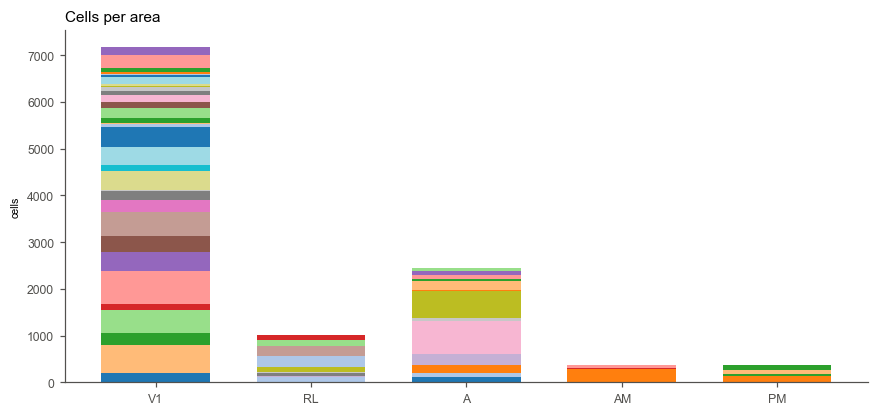

area,V1,RL,A,AM,PM
session,,,,,
250616_DMM_DMM042_pos13,199,3,118,0,0
250619_DMM_DMM042_pos07,0,110,88,0,0
250626_DMM_DMM037_pos13,0,0,172,127,131
250626_DMM_DMM041_pos13,595,0,0,0,0
250627_DMM_DMM037_pos18,254,0,1,0,48
250627_DMM_DMM037_pos23,510,0,0,0,0
250627_DMM_DMM041_pos18,122,0,0,0,0
250627_DMM_DMM042_pos18,713,0,0,0,0
250627_DMM_DMM042_pos23,393,0,0,0,0


In [104]:
tab = CELLS.groupby(['area', 'session']).size().unstack(fill_value=0).reindex(AREAS)
fig, ax = plt.subplots(figsize=(1.0 * max(len(AREAS), 3) + 3, 3.8))
bottom = np.zeros(len(AREAS))
cmap = plt.get_cmap('tab20')
for k, sess in enumerate(tab.columns):
    ax.bar(range(len(AREAS)), tab[sess].to_numpy(), bottom=bottom, color=cmap(k % 20), label=sess, width=0.7)
    bottom += tab[sess].to_numpy()
ax.set_xticks(range(len(AREAS)))
ax.set_xticklabels(AREAS)
ax.set_ylabel('cells')
ax.set_title('Cells per area', loc='left', fontsize=10)
style(ax)
show(fig, 'A1_cells_per_area')
tab.T

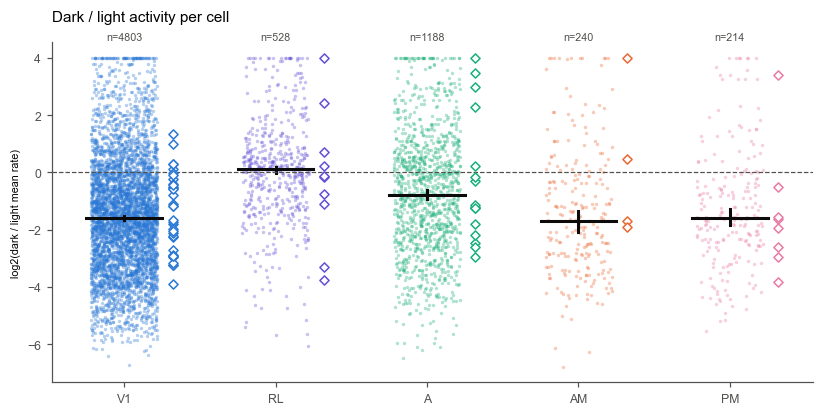

In [105]:
if CELLS['mean_rate_light'].notna().any():
    CELLS['dark_light_ratio'] = CELLS['mean_rate_dark'] / CELLS['mean_rate_light'].where(CELLS['mean_rate_light'] > 0)
    CELLS['log2_dark_light'] = np.log2(CELLS['dark_light_ratio'].where(CELLS['dark_light_ratio'] > 0))
    strip_by_area('log2_dark_light', ylabel='log2(dark / light mean rate)', title='Dark / light activity per cell',
                  refs=(0,), clip=(-8, 4), name='A2_dark_light_rate')
else:
    print('mean_rate_light / mean_rate_dark not in these files -- rerun new_analysis to add them.')

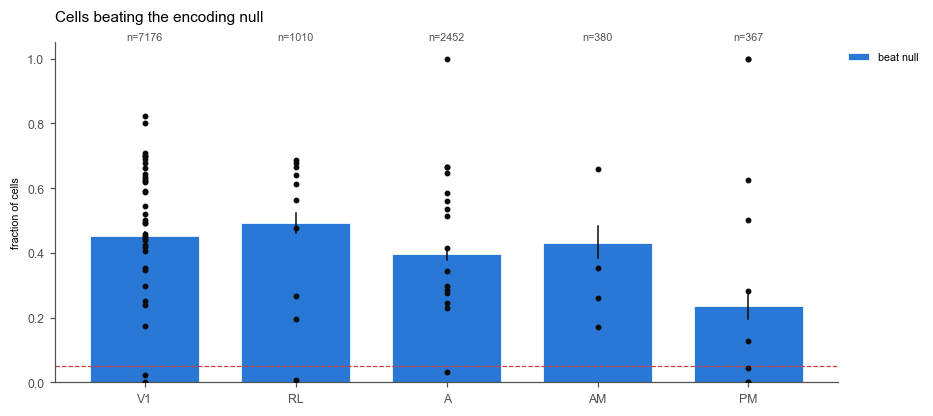

(<Figure size 935x418 with 1 Axes>,
 <Axes: title={'left': 'Cells beating the encoding null'}, ylabel='fraction of cells'>)

In [106]:
frac_by_area(['sig'], ['beat null'], ['#2a78d6'], title='Cells beating the encoding null', chance=0.05, name='B1_frac_sig')

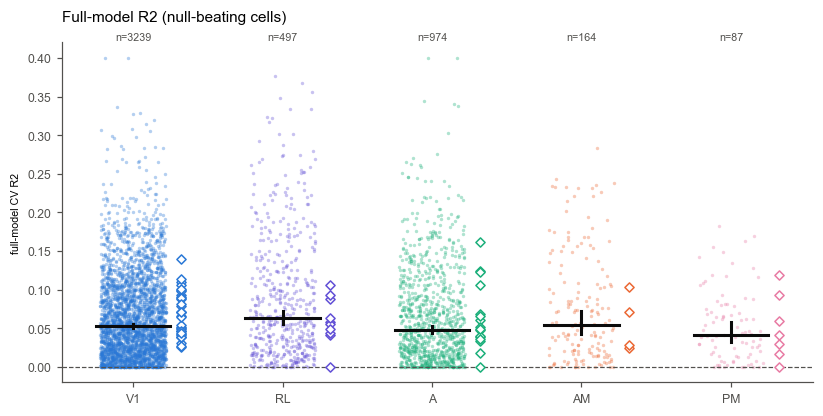

In [107]:
fig, ax = strip_by_area('r2_full', 'sig', ylabel='full-model CV R2', title='Full-model R2 (null-beating cells)', refs=(0,), name='B2_r2_full', clip=(0,0.4))

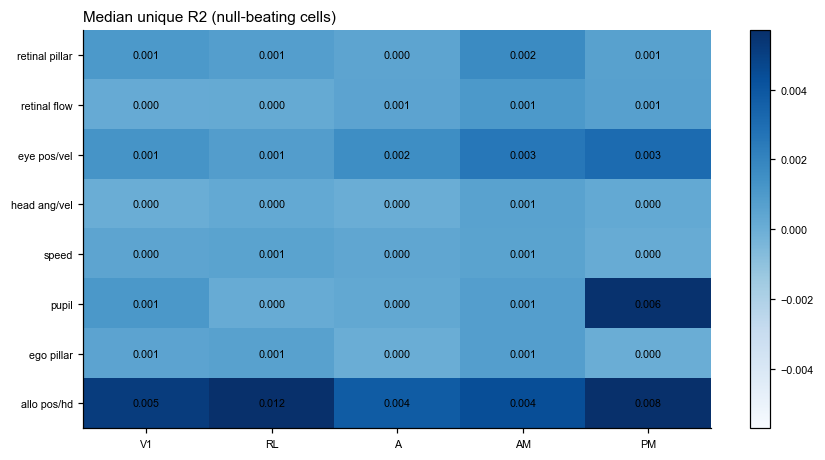

In [108]:
heat_by_area('uniq_', 'sig', np.nanmedian, 'Median unique R2 (null-beating cells)', name='B3_unique_heat', cmap='Blues')

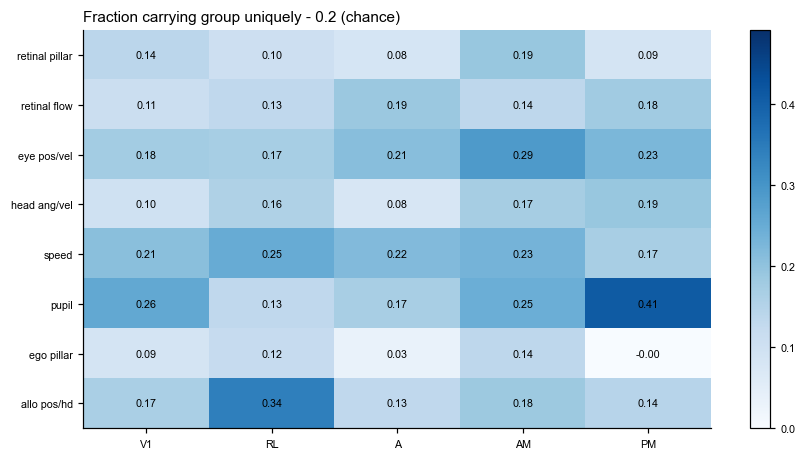

In [109]:
heat_by_area('ufrac_', 'sig', np.nanmean, 'Fraction carrying group uniquely - 0.2 (chance)', fmt='{:.2f}', cmap='Blues', center=False, name='B4_unique_frac_heat')

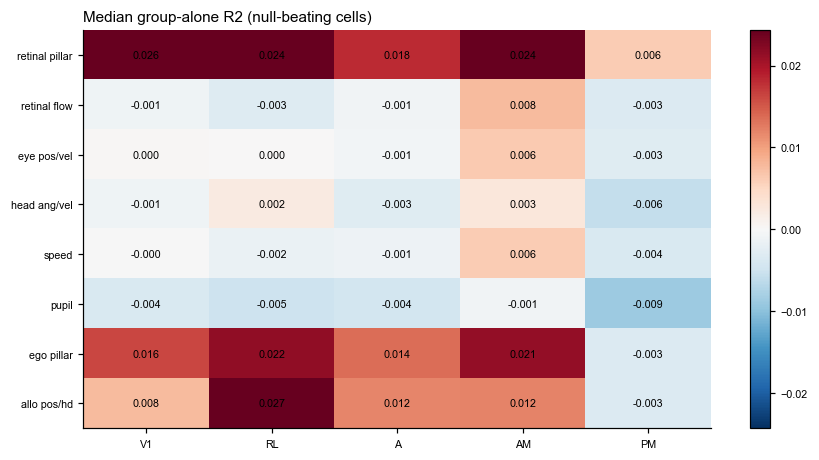

In [110]:
heat_by_area('alone_', 'sig', np.nanmedian, 'Median group-alone R2 (null-beating cells)', name='B5_alone_heat')

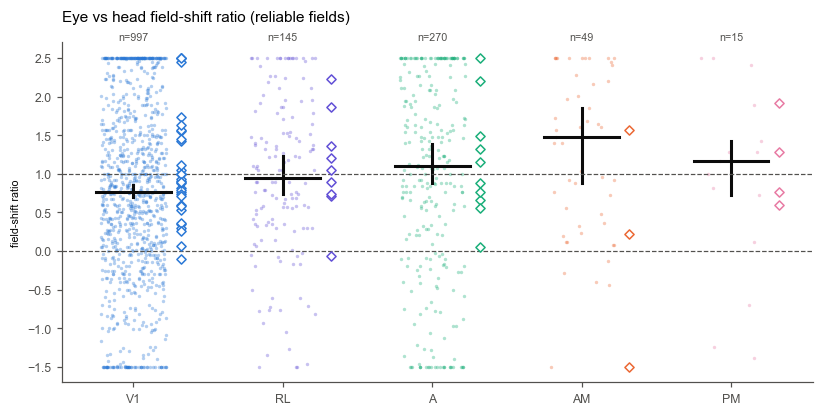

(<Figure size 825x418 with 1 Axes>,
 <Axes: title={'left': 'Eye vs head field-shift ratio (reliable fields)'}, ylabel='field-shift ratio'>)

In [111]:
strip_by_area('eye_ratio', 'eye_reliable', ylabel='field-shift ratio', title='Eye vs head field-shift ratio (reliable fields)', refs=(0, 1), clip=(-1.5, 2.5), name='C1_eye_ratio')

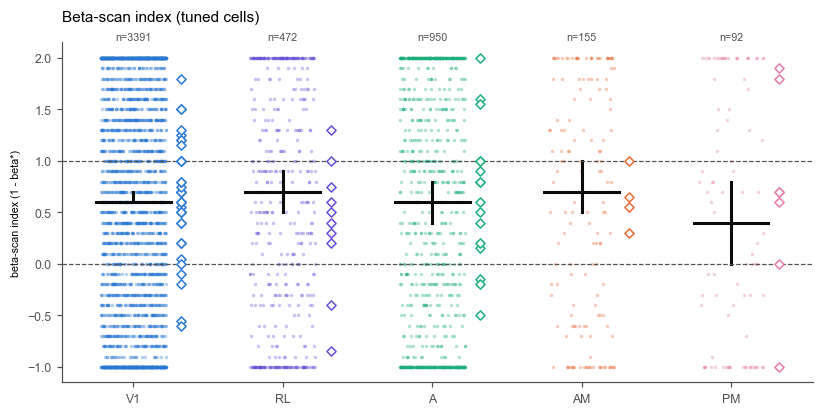

(<Figure size 825x418 with 1 Axes>,
 <Axes: title={'left': 'Beta-scan index (tuned cells)'}, ylabel='beta-scan index (1 - beta*)'>)

In [112]:
strip_by_area('beta_index', 'beta_tuned', ylabel='beta-scan index (1 - beta*)', title='Beta-scan index (tuned cells)', refs=(0, 1), name='C2_beta_index')

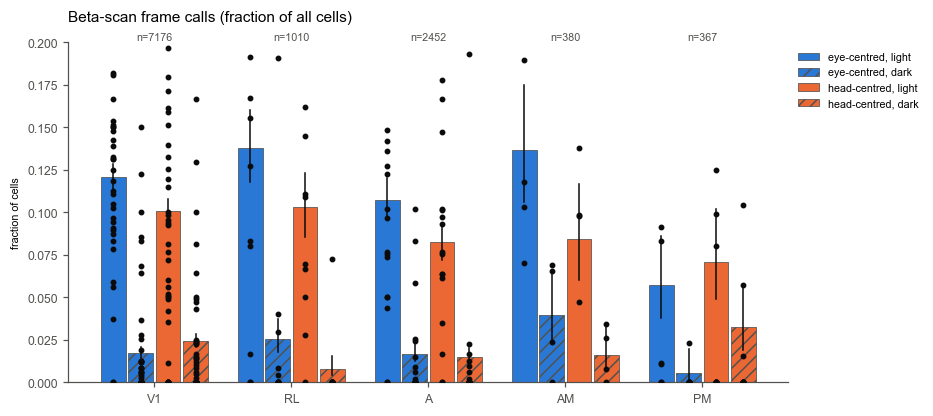

In [113]:
fig, ax = frac_by_area(['beta_prefer_first', 'beta_prefer_first_dark', 'beta_prefer_second', 'beta_prefer_second_dark'],
             ['eye-centred, light', 'eye-centred, dark', 'head-centred, light', 'head-centred, dark'],
             ['#2a78d6', '#2a78d6', '#eb6834', '#eb6834'], hatch=[None, '///', None, '///'],
             title='Beta-scan frame calls (fraction of all cells)', name='C3_frame_calls', clip=(0,0.2))

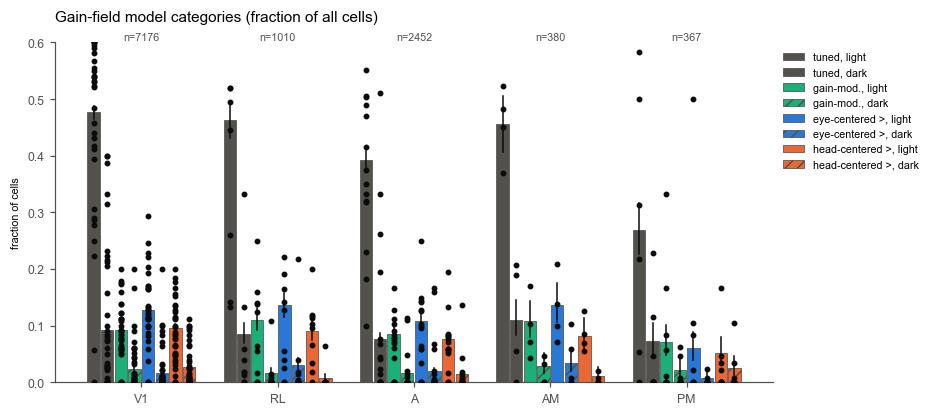

(<Figure size 935x418 with 1 Axes>,
 <Axes: title={'left': 'Gain-field model categories (fraction of all cells)'}, ylabel='fraction of cells'>)

In [114]:
cats = [('gm_tuned', 'tuned'), ('gm_gain', 'gain-mod.'), ('gm_eye_better', 'eye-centered >'), ('gm_head_better', 'head-centered >')]
cols, labs, colors, hatch = [], [], [], []
pal = ['#52514e', '#1baf7a', '#2a78d6', '#eb6834']
for (c, l), col in zip(cats, pal):
    cols += [c, c + '_dark']
    labs += [l + ', light', l + ', dark']
    colors += [col, col]
    hatch += [None, '///']
frac_by_area(cols, labs, colors, hatch=hatch, title='Gain-field model categories (fraction of all cells)', name='C4_gain_categories', clip=(0,0.6))

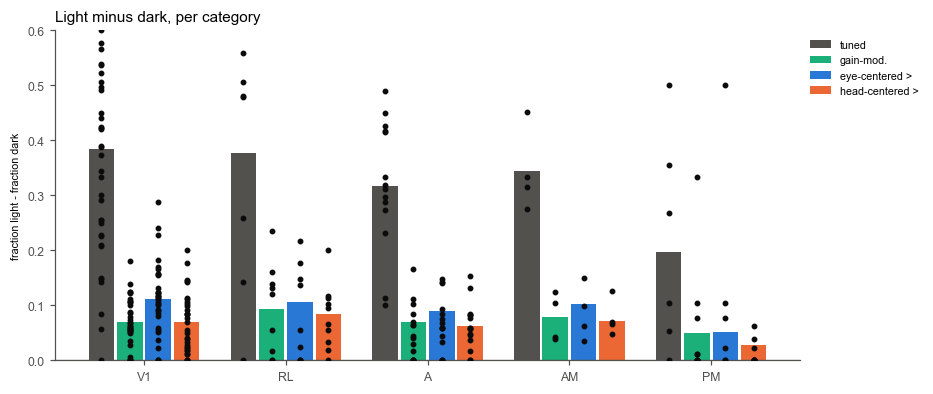

In [115]:
fig, ax = plt.subplots(figsize=(1.3 * max(len(AREAS), 3) + 2, 3.6))
w = 0.8 / len(cats)
for i, a in enumerate(AREAS):
    m = CELLS['area'] == a
    for j, ((c, l), col) in enumerate(zip(cats, pal)):
        ex = CELLS.loc[m, c].mean() - CELLS.loc[m, c + '_dark'].mean()
        ax.bar(i + (j - 1.5) * w, ex, width=w * 0.9, color=col, label=l if i == 0 else None)
        se = [CELLS.loc[m & (CELLS['session'] == s_), c].mean() - CELLS.loc[m & (CELLS['session'] == s_), c + '_dark'].mean()
              for s_ in CELLS.loc[m, 'session'].unique()]
        ax.scatter(np.full(len(se), i + (j - 1.5) * w), se, s=8, color=INK, zorder=3)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(range(len(AREAS)))
ax.set_xticklabels(AREAS)
ax.set_ylabel('fraction light - fraction dark')
ax.set_title('Light minus dark, per category', loc='left', fontsize=10)
ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
ax.set_ylim([0,0.6])
style(ax)
show(fig, 'C5_light_minus_dark')

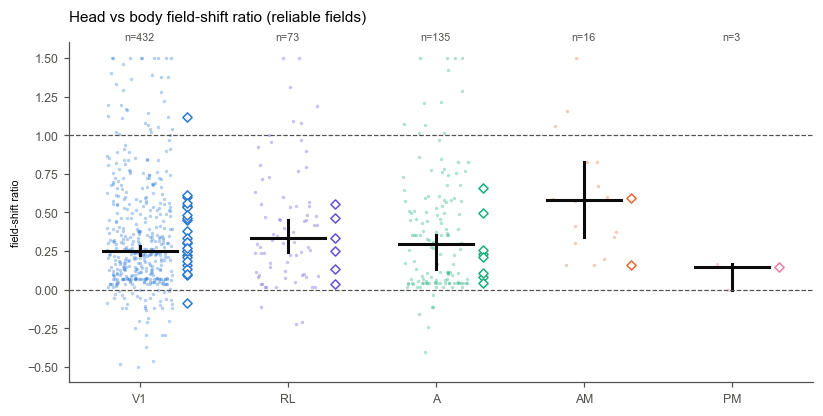

(<Figure size 825x418 with 1 Axes>,
 <Axes: title={'left': 'Head vs body field-shift ratio (reliable fields)'}, ylabel='field-shift ratio'>)

In [116]:
strip_by_area('body_ratio', 'body_reliable', ylabel='field-shift ratio', title='Head vs body field-shift ratio (reliable fields)', refs=(0, 1), clip=(-0.5, 1.5), name='C6_body_ratio')

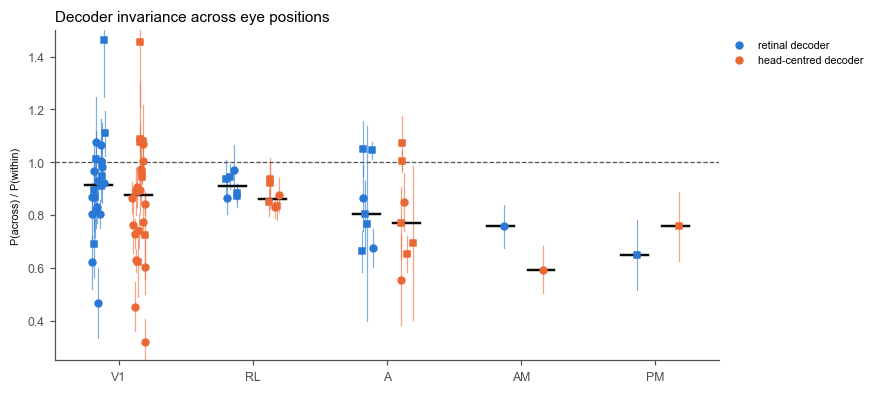

In [117]:
DECP = DEC
if DEC_REQUIRE_SIG and len(DEC):
    DECP = DEC[(DEC['eta_p_within'] < 0.05) & (DEC['rho_p_within'] < 0.05)]
    print('{} of {} session x area decoders beat chance in both frames.'.format(len(DECP), len(DEC)))


def dec_points(cols, labels, colors, ylabel, title, refs=(), name='fig', clip=None):
    fig, ax = plt.subplots(figsize=(1.2 * max(len(AREAS), 3) + 2, 3.6))
    k = len(cols)
    for i, a in enumerate(AREAS):
        dd = DECP[DECP['area'] == a] if len(DECP) else DECP
        for j, (c, l, col) in enumerate(zip(cols, labels, colors)):
            if c not in dd:
                continue
            y = dd[c].to_numpy(float)
            x = i + (j - (k - 1) / 2) * min(0.3, 0.8 / k)
            xs = np.full(len(y), x) + rng.uniform(-0.05, 0.05, len(y))
            err = dd[c + '_sd'].to_numpy(float) if c + '_sd' in dd else np.full(len(y), np.nan)
            for xx, yy, ee in zip(xs, y, err):
                if np.isfinite(ee):
                    ax.plot([xx, xx], [yy - ee, yy + ee], color=col, lw=0.8, alpha=0.6)
            ni = ~dd['no_imu'].to_numpy(bool)
            ax.scatter(xs[ni], y[ni], s=20, color=col, label=l if i == 0 else None, zorder=3)
            ax.scatter(xs[~ni], y[~ni], s=20, color=col, marker='s', zorder=3)
            if len(y):
                ax.plot([x - 0.1, x + 0.1], [np.nanmedian(y)] * 2, color=INK, lw=1.6)
    for r in refs:
        ax.axhline(r, color=INK2, lw=0.8, ls='--')
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left', fontsize=10)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    if clip is not None:
        ax.set_ylim(clip)
    style(ax)
    show(fig, name)


dec_points(['rho_invariance', 'eta_invariance'], ['retinal decoder', 'head-centred decoder'], ['#2a78d6', '#eb6834'],
           'P(across) / P(within)', 'Decoder invariance across eye positions', refs=(0, 1), name='D1_decoder_invariance', clip=(0.25,1.5))

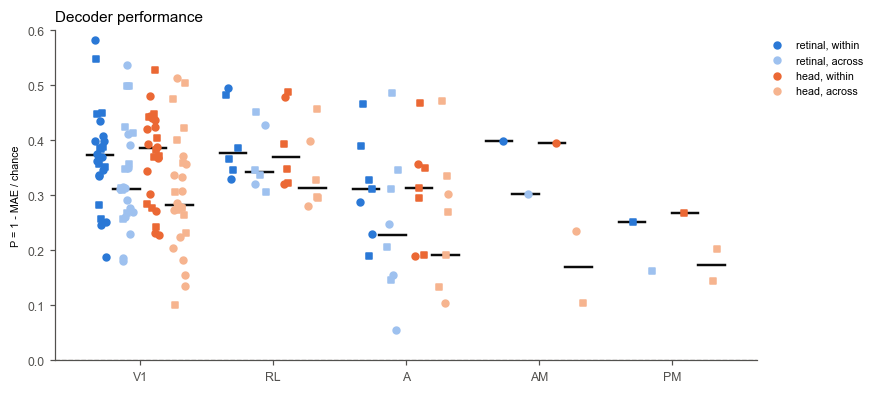

In [118]:
dec_points(['rho_P_within', 'rho_P_cross', 'eta_P_within', 'eta_P_cross'],
           ['retinal, within', 'retinal, across', 'head, within', 'head, across'],
           ['#2a78d6', '#9ec1ef', '#eb6834', '#f6b48f'], 'P = 1 - MAE / chance', 'Decoder performance', refs=(0,),
           name='D2_decoder_performance', clip=(0,0.6))

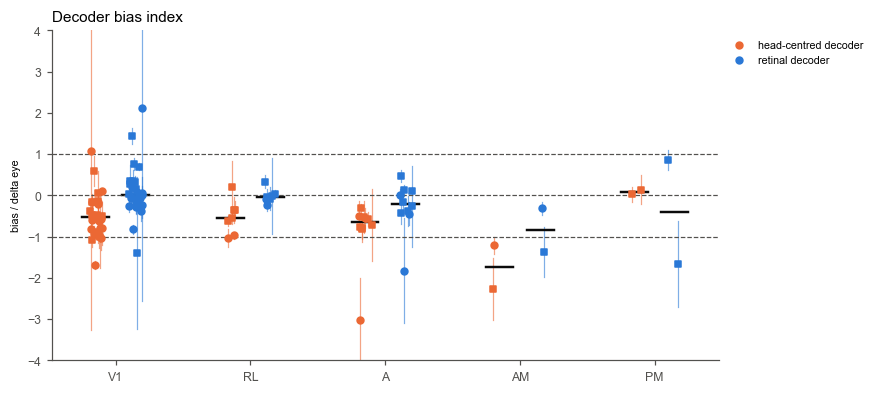

In [119]:
dec_points(['eta_bias_index', 'rho_bias_index'], ['head-centred decoder', 'retinal decoder'], ['#eb6834', '#2a78d6'],
           'bias / delta eye', 'Decoder bias index', refs=(-1, 0, 1), name='D3_decoder_bias', clip=(-4,4))

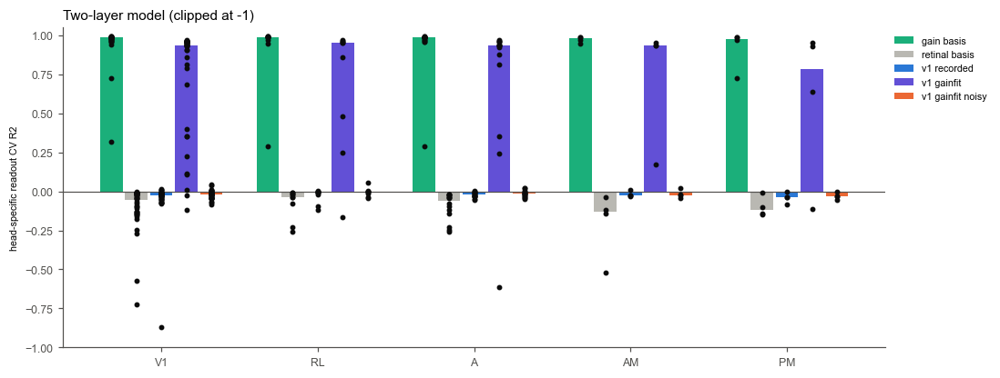

In [120]:
if len(TL):
    layers = [l for l in ['gain_basis', 'retinal_basis', 'v1_recorded', 'v1_gainfit', 'v1_gainfit_noisy'] if l in set(TL['layer'])]
    lcol = dict(zip(layers, ['#1baf7a', '#b9b8b2', '#2a78d6', '#6250d6', '#eb6834']))
    fig, ax = plt.subplots(figsize=(1.6 * max(len(AREAS), 3) + 2, 3.8))
    w = 0.8 / len(layers)
    for i, a in enumerate(AREAS):
        for j, l in enumerate(layers):
            y = TL[(TL['area'] == a) & (TL['layer'] == l)]['r2_head_specific'].to_numpy(float)
            x = i + (j - (len(layers) - 1) / 2) * w
            if len(y):
                ax.bar(x, np.nanmedian(y), width=w * 0.9, color=lcol[l], label=l.replace('_', ' ') if i == 0 else None)
                ax.scatter(np.full(len(y), x), y, s=8, color=INK, zorder=3)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_ylim(max(-1.0, ax.get_ylim()[0]), 1.05)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel('head-specific readout CV R2')
    ax.set_title('Two-layer model (clipped at -1)', loc='left', fontsize=10)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax)
    show(fig, 'D4_two_layer')

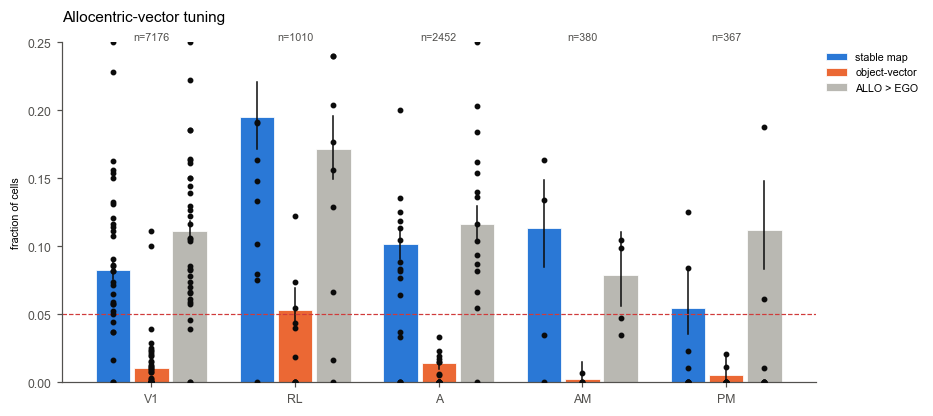

(<Figure size 935x418 with 1 Axes>,
 <Axes: title={'left': 'Allocentric-vector tuning'}, ylabel='fraction of cells'>)

In [121]:
CELLS['ovc_stable'] = (CELLS['ovc_stab'] > 0.5) & (CELLS['ovc_p'] < 0.05)
frac_by_area(['ovc_stable', 'ovc', 'allo_beats_ego'], ['stable map', 'object-vector', 'ALLO > EGO'],
             ['#2a78d6', '#eb6834', '#b9b8b2'], title='Allocentric-vector tuning', chance=0.05, name='E1_ovc_fractions', clip=(0,0.25))

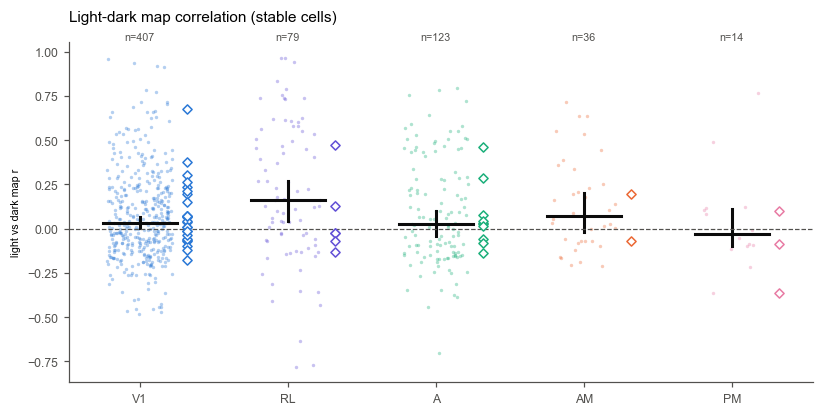

(<Figure size 825x418 with 1 Axes>,
 <Axes: title={'left': 'Light-dark map correlation (stable cells)'}, ylabel='light vs dark map r'>)

In [122]:
strip_by_area('ovc_ld_r', 'ovc_stable', ylabel='light vs dark map r', title='Light-dark map correlation (stable cells)', refs=(0,), name='E2_ovc_light_dark')

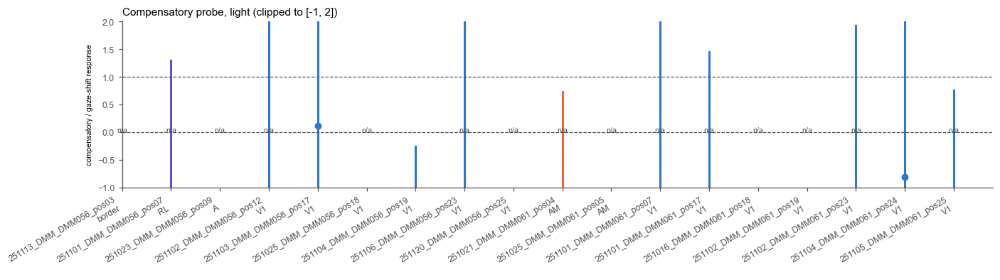

,session,majority_area,rel_shift_light,rel_shift_dark,rel_visual_light,rel_visual_dark,pooled_ratio,pooled_ratio_lo,pooled_ratio_hi,pooled_shift,pooled_comp,n_pairs,pop_vis,pop_kin,t0_gaze_light,t0_head_light
0,251113_DMM_DMM056_pos03,border,0.031745,NaN,-0.020033,-0.104258,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,251101_DMM_DMM056_pos07,RL,0.252131,0.035358,0.468070,0.278640,NaN,-3.144665e+01,1.302453,-0.061644,-0.169014,41.0,-0.001191,-0.007056,-3.850000e-01,0.055
2,251023_DMM_DMM056_pos09,A,0.102946,NaN,0.386264,NaN,NaN,-3.747536e+06,-1.594660,-0.231707,-0.128834,6.0,-0.003711,-0.011692,5.551115e-16,0.090
3,251102_DMM_DMM056_pos12,V1,-0.197429,NaN,-0.277273,0.392226,NaN,-3.797619e+00,4.394998,-0.281250,-0.288462,5.0,-0.007221,-0.023002,5.000000e-02,0.065
4,251103_DMM_DMM056_pos17,V1,0.371829,NaN,0.398591,NaN,0.121212,-3.516207e+00,7.919644,0.343750,0.041667,10.0,-0.001475,-0.009042,-1.500000e-02,0.255
5,251025_DMM_DMM056_pos18,V1,0.223829,0.103747,0.086582,-0.054054,NaN,-4.531902e+00,-4.531902,-0.187987,-0.323568,88.0,-0.003459,-0.006134,-9.000000e-02,0.045
6,251104_DMM_DMM056_pos19,V1,0.133359,NaN,0.363641,-0.316969,-2.710079,-2.139373e+01,-0.257629,0.148862,-0.403427,32.0,-0.006134,-0.011484,-8.500000e-02,0.015
7,251106_DMM_DMM056_pos23,V1,0.163339,0.457932,-0.015936,0.178914,NaN,-7.042731e+00,3.788840,-0.125000,-0.039474,64.0,-0.001808,-0.006977,1.850000e-01,0.040
8,251120_DMM_DMM056_pos25,V1,0.175960,0.338343,0.288050,0.081593,NaN,-1.766113e+02,-1.123719,-0.150685,-0.195925,103.0,-0.002293,-0.005263,-4.700000e-01,-0.300
9,251021_DMM_DMM061_pos04,AM,0.186456,0.460734,0.287017,0.258139,NaN,-7.003692e+01,0.730905,-0.022179,-0.088973,161.0,-0.002412,-0.003042,-9.500000e-02,-0.060


In [123]:
if len(NVS) and 'pooled_ratio' in NVS:
    fig, ax = plt.subplots(figsize=(max(4, 0.6 * len(NVS) + 2), 3.6))
    for i, r in NVS.reset_index(drop=True).iterrows():
        col = acol(r['majority_area'])
        ax.plot([i, i], [r['pooled_ratio_lo'], r['pooled_ratio_hi']], color=col, lw=2)
        ax.scatter([i], [r['pooled_ratio']], color=col, s=30, zorder=3)
        if not np.isfinite(r['pooled_ratio']):
            ax.text(i, 0, 'n/a', ha='center', fontsize=7, color=INK2)
    ax.axhline(0, color=INK2, lw=0.8, ls='--')
    ax.axhline(1, color=INK2, lw=0.8, ls='--')
    ax.set_ylim(-1, 2)
    ax.set_xticks(range(len(NVS)))
    ax.set_xticklabels(['{}\n{}'.format(s, a) for s, a in zip(NVS['session'], NVS['majority_area'])], fontsize=6, rotation=30, ha='right')
    ax.set_ylabel('compensatory / gaze-shift response')
    ax.set_title('Compensatory probe, light (clipped to [-1, 2])', loc='left', fontsize=10)
    style(ax)
    show(fig, 'F1_comp_ratio_sessions')
    display(NVS)
else:
    print('no non-visual results found')

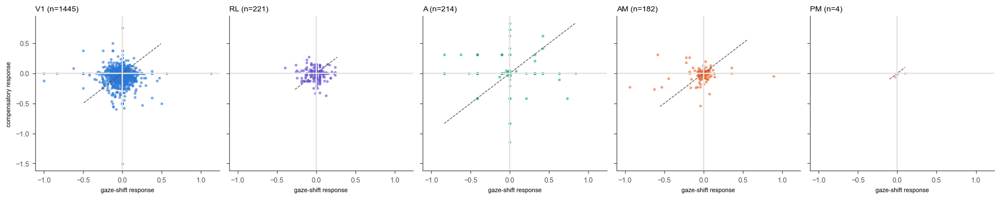

In [124]:
if 'resp_shift' in CELLS:
    fig, axs = plt.subplots(1, len(AREAS), figsize=(3.2 * len(AREAS), 3.2), squeeze=False, sharex=True, sharey=True)
    for ax, a in zip(axs[0], AREAS):
        m = CELLS['area'] == a
        x, y = CELLS.loc[m, 'resp_shift'], CELLS.loc[m, 'resp_comp']
        ax.scatter(x, y, s=5, color=acol(a), alpha=0.5)
        lim = np.nanpercentile(np.abs(np.r_[x, y]), 99) if m.any() else 1
        ax.plot([-lim, lim], [-lim, lim], color=INK2, lw=0.8, ls='--')
        ax.axhline(0, color=GRID)
        ax.axvline(0, color=GRID)
        ax.set_title('{} (n={})'.format(a, int(np.isfinite(x).sum())), loc='left', fontsize=9)
        ax.set_xlabel('gaze-shift response')
        style(ax, grid_y=False)
    axs[0][0].set_ylabel('compensatory response')
    show(fig, 'F2_comp_scatter_by_area')

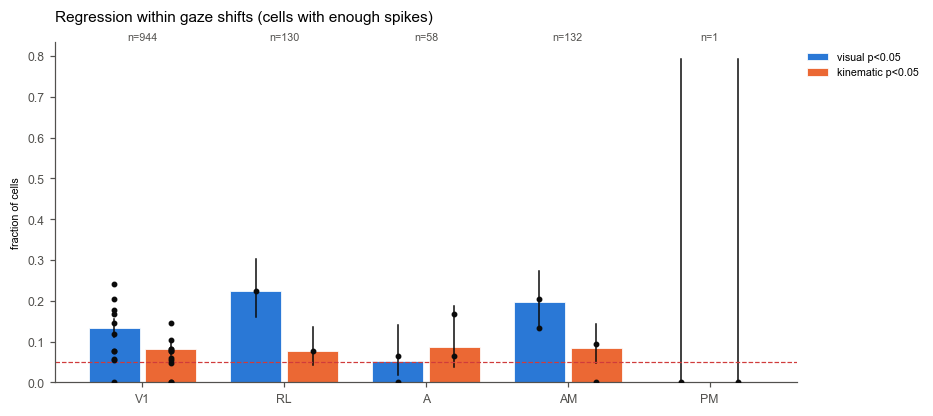

In [125]:
if 'reg_p_vis' in CELLS:
    CELLS['reg_tested'] = CELLS['reg_p_vis'].notna()
    CELLS['reg_vis_sig'] = CELLS['reg_p_vis'] < 0.05
    CELLS['reg_kin_sig'] = CELLS['reg_p_kin'] < 0.05
    frac_by_area(['reg_vis_sig', 'reg_kin_sig'], ['visual p<0.05', 'kinematic p<0.05'], ['#2a78d6', '#eb6834'],
                 denom_col='reg_tested', title='Regression within gaze shifts (cells with enough spikes)', chance=0.05,
                 name='F3_regression_fractions')

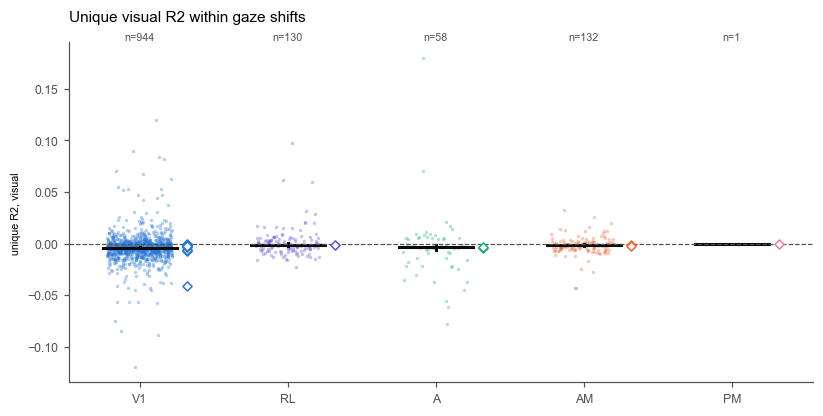

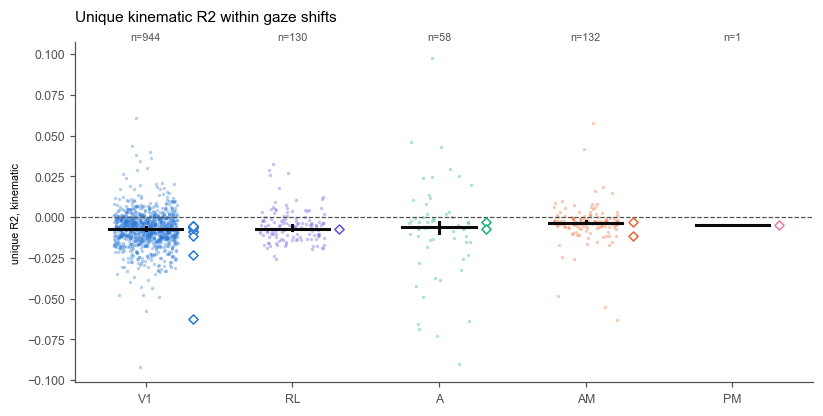

In [126]:
if 'reg_unique_vis' in CELLS:
    strip_by_area('reg_unique_vis', 'reg_tested', ylabel='unique R2, visual', title='Unique visual R2 within gaze shifts',
                  refs=(0,), name='F4a_unique_visual')
    strip_by_area('reg_unique_kin', 'reg_tested', ylabel='unique R2, kinematic', title='Unique kinematic R2 within gaze shifts',
                  refs=(0,), name='F4b_unique_kinematic')

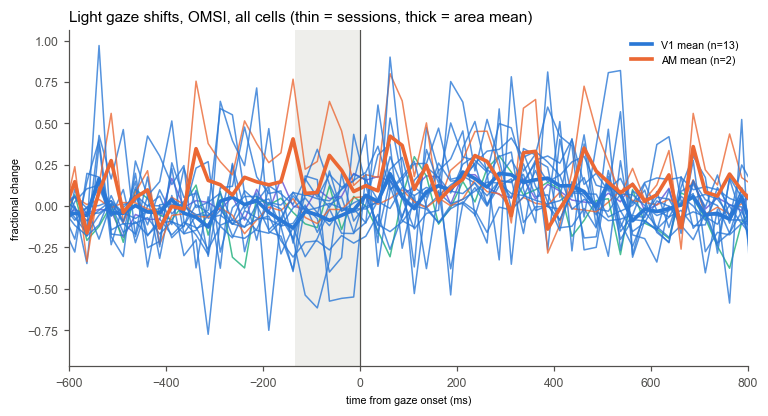

In [127]:
if peths:
    fig, ax = plt.subplots(figsize=(7, 3.8))
    for pk in peths:
        ax.plot(1000 * pk['tau'], pk['peth'], color=acol(pk['majority_area']), lw=1.0, alpha=0.8)
    for a in AREAS:
        P_ = [pk['peth'] for pk in peths if pk['majority_area'] == a]
        if len(P_) > 1:
            ax.plot(1000 * peths[0]['tau'], np.nanmean(P_, 0), color=acol(a), lw=2.4, label='{} mean (n={})'.format(a, len(P_)))
    ax.axvline(0, color=INK2, lw=0.8)
    ax.axvspan(-133, 0, color=GRID, alpha=0.6, lw=0)
    ax.set_xlim(-600, 800)
    ax.set_xlabel('time from gaze onset (ms)')
    ax.set_ylabel('fractional change')
    ax.set_title('Light gaze shifts, OMSI, all cells (thin = sessions, thick = area mean)', loc='left', fontsize=10)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=7, frameon=False)
    style(ax)
    show(fig, 'F5_peth_sessions')

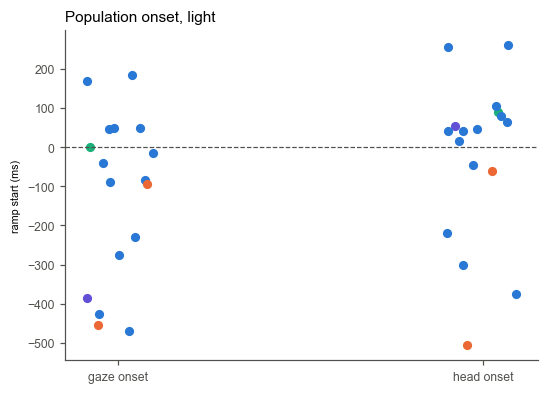

In [128]:
if len(NVS) and 't0_gaze_light' in NVS:
    fig, ax = plt.subplots(figsize=(5, 3.6))
    for j, (c, l) in enumerate((('t0_gaze_light', 'gaze onset'), ('t0_head_light', 'head onset'))):
        if c not in NVS:
            continue
        for _, r in NVS.iterrows():
            ax.scatter(j + rng.uniform(-0.1, 0.1), 1000 * r[c], color=acol(r['majority_area']), s=25)
    ax.axhline(0, color=INK2, lw=0.8, ls='--')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['gaze onset', 'head onset'])
    ax.set_ylabel('ramp start (ms)')
    ax.set_title('Population onset, light', loc='left', fontsize=10)
    style(ax)
    show(fig, 'F6_onsets')

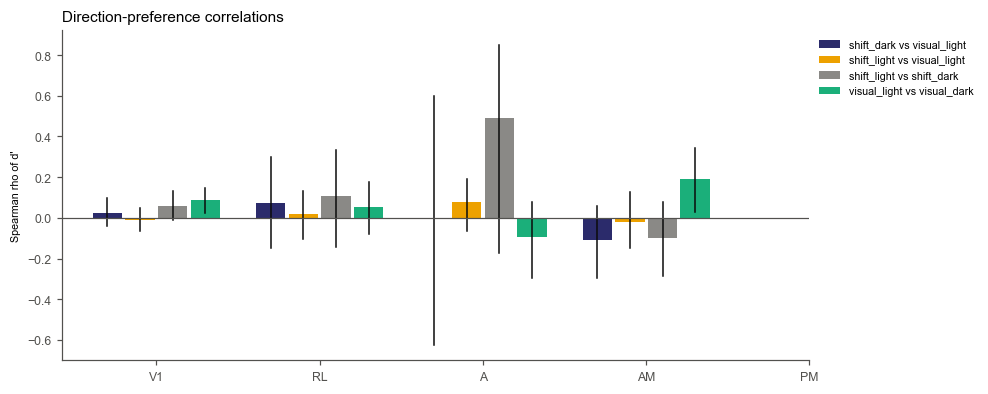

In [129]:
pairs = [('shift_dark', 'visual_light'), ('shift_light', 'visual_light'), ('shift_light', 'shift_dark'), ('visual_light', 'visual_dark')]
if 'dir_dp_shift_light' in CELLS:
    fig, ax = plt.subplots(figsize=(1.4 * max(len(AREAS), 3) + 2, 3.6))
    w = 0.8 / len(pairs)
    pcol = ['#2b2b6b', '#eda100', '#8a8986', '#1baf7a']
    for i, a in enumerate(AREAS):
        m = CELLS['area'] == a
        for j, (p1, p2) in enumerate(pairs):
            x, y = CELLS.loc[m, 'dir_dp_' + p1].to_numpy(float), CELLS.loc[m, 'dir_dp_' + p2].to_numpy(float)
            ok = np.isfinite(x) & np.isfinite(y)
            if ok.sum() < 10:
                continue
            rho = spearmanr(x[ok], y[ok]).correlation
            bs = [spearmanr(x[ok][ii], y[ok][ii]).correlation for ii in rng.integers(0, ok.sum(), (300, ok.sum()))]
            xx = i + (j - 1.5) * w
            ax.bar(xx, rho, width=w * 0.9, color=pcol[j], label='{} vs {}'.format(p1, p2) if i == 0 else None)
            ax.plot([xx, xx], np.nanpercentile(bs, [2.5, 97.5]), color=INK, lw=1)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel("Spearman rho of d'")
    ax.set_title('Direction-preference correlations', loc='left', fontsize=10)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax)
    show(fig, 'F7_direction_corr')

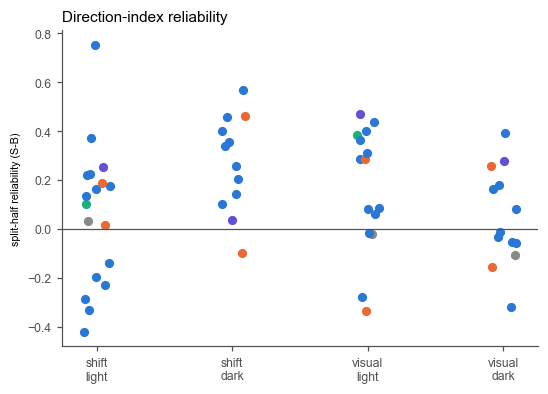

In [130]:
rel_cols = [c for c in ('rel_shift_light', 'rel_shift_dark', 'rel_visual_light', 'rel_visual_dark') if c in NVS]
if rel_cols:
    fig, ax = plt.subplots(figsize=(5, 3.6))
    for j, c in enumerate(rel_cols):
        for _, r in NVS.iterrows():
            ax.scatter(j + rng.uniform(-0.1, 0.1), r[c], color=acol(r['majority_area']), s=25)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(len(rel_cols)))
    ax.set_xticklabels([c[4:].replace('_', '\n') for c in rel_cols])
    ax.set_ylabel('split-half reliability (S-B)')
    ax.set_title('Direction-index reliability', loc='left', fontsize=10)
    style(ax)
    show(fig, 'F8_direction_reliability')

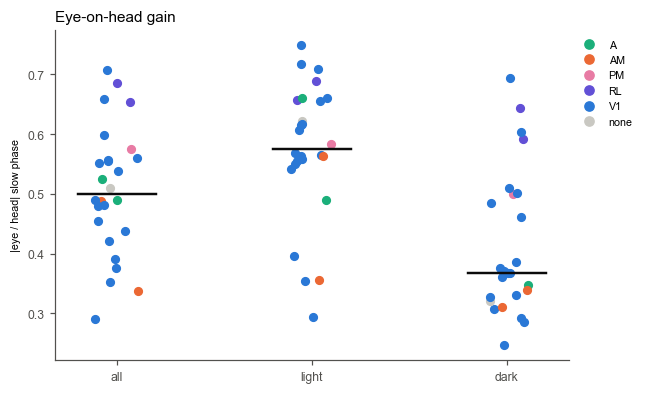

In [131]:
def beh_points(cols, labels, ylabel, title, refs=(), name='fig'):
    if not len(BEH):
        print('no behavior summaries found')
        return
    fig, ax = plt.subplots(figsize=(max(4, 1.3 * len(cols) + 2), 3.6))
    for j, c in enumerate(cols):
        if c not in BEH:
            continue
        for _, r in BEH.iterrows():
            ax.scatter(j + rng.uniform(-0.12, 0.12), r[c], color=acol(r['majority_area']), s=25)
        ax.plot([j - 0.2, j + 0.2], [BEH[c].median()] * 2, color=INK, lw=1.6)
    for rr in refs:
        ax.axhline(rr, color=INK2, lw=0.8, ls='--')
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels(labels)
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left', fontsize=10)
    handles = [plt.Line2D([], [], marker='o', ls='', color=acol(a), label=a) for a in sorted(set(BEH['majority_area']))]
    ax.legend(handles=handles, fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax)
    show(fig, name)


beh_points(['vor_slope', 'vor_slope_light', 'vor_slope_dark'], ['all', 'light', 'dark'], '|eye / head| slow phase',
           'Eye-on-head gain', name='G1_vor_gain')

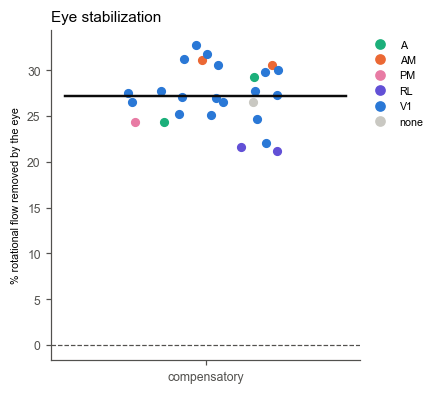

In [132]:
beh_points(['comp_stab'], ['compensatory'], '% rotational flow removed by the eye', 'Eye stabilization', refs=(0,), name='G2_comp_stab')

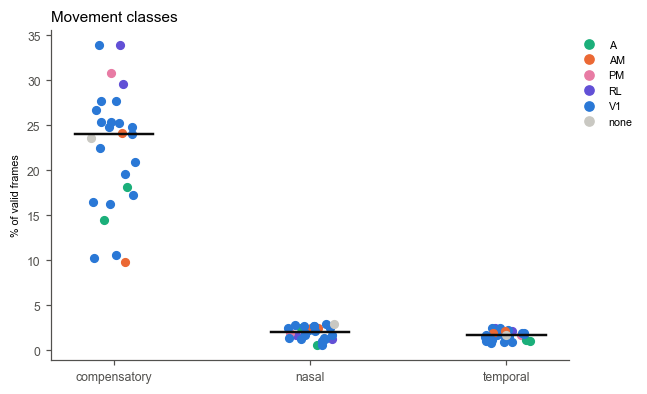

In [133]:
beh_points(['comp_frac', 'nasal_frac', 'temporal_frac'], ['compensatory', 'nasal', 'temporal'], '% of valid frames', 'Movement classes', name='G3_classes')

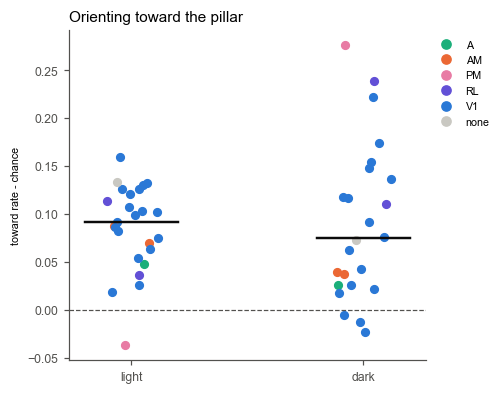

In [134]:
beh_points(['net_toward_light', 'net_toward_dark'], ['light', 'dark'], 'toward rate - chance', 'Orienting toward the pillar', refs=(0,), name='G4_net_toward')

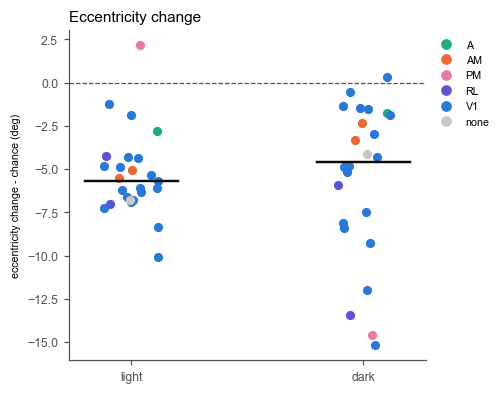

In [135]:
beh_points(['net_ecc_light', 'net_ecc_dark'], ['light', 'dark'], 'eccentricity change - chance (deg)', 'Eccentricity change', refs=(0,), name='G5_net_ecc')

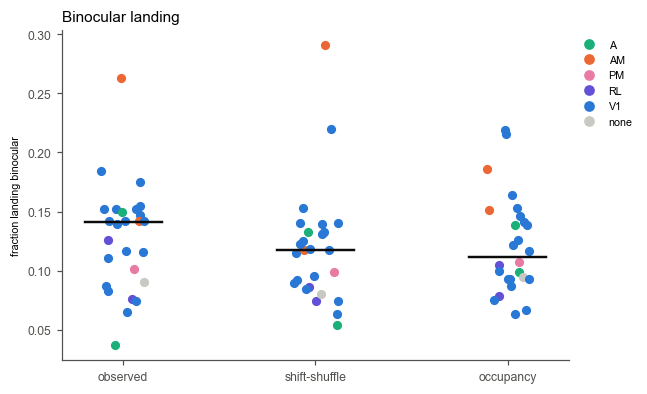

In [136]:
beh_points(['bino_post', 'shift_null', 'occ_null'], ['observed', 'shift-shuffle', 'occupancy'], 'fraction landing binocular', 'Binocular landing', name='G6_landing')

In [137]:
display(BEH)
display(DEC)
display(SES.drop(columns=['path', 'prefix']))

,session,majority_area,comp_frac,nasal_frac,temporal_frac,comp_stab,bino_post,shift_null,occ_null,net_toward_light,net_toward_dark,net_ecc_light,net_ecc_dark,p_block_toward,p_block_ecc,verdict,vor_slope,vor_slope_light,vor_slope_dark
0,251101_DMM_DMM056_pos07,RL,33.886281,1.658843,2.424734,21.207757,0.125466,0.086180,0.104550,0.113300,0.238185,-7.039324,-13.426660,0.181818,0.181818,WEAK -- beats both nulls at the default zone (...,0.654608,0.657618,0.592359
1,251020_DMM_DMM056_pos08,RL,29.583048,1.272613,2.101153,21.655360,0.076190,0.074413,0.078090,0.036042,0.110000,-4.226081,-5.943505,0.500000,0.625000,NO -- landing is not enriched against either null,0.685426,0.688233,0.643981
2,251023_DMM_DMM056_pos09,A,14.451383,0.609575,1.045693,24.380433,0.036697,0.053681,0.098415,NaN,NaN,NaN,NaN,NaN,NaN,NO -- landing is not enriched against either null,0.489171,0.489381,NaN
3,251108_DMM_DMM056_pos10,PM,30.833056,1.880508,1.662478,24.398456,0.101377,0.098827,0.107398,-0.036851,0.275992,2.162103,-14.588706,0.200000,0.200000,NO -- landing is not enriched against either null,0.575755,0.583273,0.499319
4,251102_DMM_DMM056_pos12,V1,10.201716,0.575006,0.843960,25.234449,0.175000,0.152752,0.146048,0.098460,NaN,-6.612775,NaN,NaN,NaN,NO -- landing is not enriched against either null,0.290926,0.292894,0.246920
5,251015_DMM_DMM056_pos13,V1,16.187411,1.182814,0.932040,25.150090,0.152174,0.114806,0.093237,0.159550,0.173554,-10.080868,-11.989781,0.800000,1.000000,"YES -- beats both nulls, and 4 of 6 variants a...",0.391400,0.395256,0.366897
6,251031_DMM_DMM056_pos14,V1,25.363900,1.212540,1.839525,26.494424,0.146718,0.117705,0.125900,0.091604,0.222222,-6.307835,-15.168661,NaN,NaN,WEAK -- beats both nulls at the default zone (...,0.708235,0.708482,0.693672
7,251103_DMM_DMM056_pos17,V1,26.641668,1.637095,2.432778,22.022786,0.082883,0.073883,0.074953,0.101873,0.062500,-5.659612,-8.383797,NaN,NaN,NO -- landing is not enriched against either null,0.352394,0.354678,0.306313
8,251025_DMM_DMM056_pos18,V1,27.639317,1.694203,2.254271,26.588126,0.151925,0.125087,0.141120,0.102900,0.148148,-6.876930,-4.852709,NaN,NaN,PARTIAL -- shifts are targeted given the start...,0.659047,0.660786,0.602776
9,251104_DMM_DMM056_pos19,V1,24.810438,1.379876,1.694105,27.514455,0.064784,0.062992,0.066904,0.130262,-0.005540,-7.263594,0.351727,0.461538,0.615385,NO -- landing is not enriched against either null,0.598156,0.607339,0.460725


,session,animal,cohort,no_imu,area,n_cells,delta_e,eta_P_within,eta_P_cross,eta_invariance,eta_bias_index,eta_p_within,eta_n_splits,eta_invariance_sd,eta_bias_index_sd,rho_P_within,rho_P_cross,rho_invariance,rho_bias_index,rho_p_within,rho_n_splits,rho_invariance_sd,rho_bias_index_sd
0,250628_DMM_DMM037_pos08,DMM037,cohort01_recordings,True,A,220,15.964477,0.349614,0.269559,0.771021,-0.799459,0.047619,25,0.136787,0.338319,0.388708,0.312135,0.803006,-0.381781,0.047619,25,0.125816,0.364438
1,250628_DMM_DMM037_pos08,DMM037,cohort01_recordings,True,RL,15,15.964477,0.322036,0.296318,0.920141,-0.359015,0.047619,25,0.095946,0.323570,0.365611,0.345456,0.944873,-0.079629,0.047619,25,0.047509,0.282181
2,250630_DMM_DMM037_pos12,DMM037,cohort01_recordings,True,A,68,23.574646,0.192151,0.133552,0.695036,-0.815083,0.047619,25,0.291242,0.240033,0.190453,0.146203,0.767658,-0.157463,0.047619,25,0.369926,0.240140
3,250630_DMM_DMM037_pos12,DMM037,cohort01_recordings,True,RL,25,23.574646,0.129780,0.111195,0.856793,0.094776,0.095238,25,0.289419,0.493506,0.151006,0.101261,0.670572,0.584036,0.095238,25,0.363870,0.453968
4,250630_DMM_DMM037_pos12,DMM037,cohort01_recordings,True,V1,17,23.574646,0.144164,0.092769,0.643498,-0.448262,0.095238,25,0.317850,0.346969,0.156340,0.109029,0.697386,0.064630,0.095238,25,0.231382,0.423381
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,251016_DMM_DMM061_pos18,DMM061,cohort02_recordings,False,V1,418,31.423555,0.423651,0.134804,0.318195,-0.531415,0.047619,25,0.088779,0.347923,0.397811,0.185821,0.467108,-0.377764,0.047619,25,0.131173,0.251113
61,251102_DMM_DMM061_pos19,DMM061,cohort02_recordings,False,V1,98,26.065346,0.421258,0.307581,0.730147,-0.581352,0.047619,25,0.055201,0.161383,0.375761,0.312489,0.831615,-0.269392,0.047619,25,0.061199,0.138129
62,251102_DMM_DMM061_pos23,DMM061,cohort02_recordings,False,V1,20,26.065680,0.271468,0.272568,1.004052,-0.151979,0.047619,25,0.062612,0.181080,0.245453,0.261371,1.064851,-0.066192,0.047619,25,0.097190,0.148696
63,251104_DMM_DMM061_pos24,DMM061,cohort02_recordings,False,V1,44,24.489297,0.392790,0.356039,0.906437,-0.169234,0.047619,25,0.075093,0.148078,0.336149,0.311838,0.927677,-0.197605,0.047619,25,0.045002,0.130038


,cohort,session,rec,animal,pos,n_cells,usable_min,light_frac,spike_key,majority_area,areas,has_behavior,has_nonvisual,no_imu,has_noimu_twin
0,cohort01_recordings,250630_DMM_DMM037_pos03,fm3,DMM037,pos03,156,15.082222,0.474792,norm_spikes,none,none 156,False,False,True,False
1,cohort01_recordings,250628_DMM_DMM037_pos08,fm3,DMM037,pos08,334,12.686667,0.541578,norm_spikes,A,"A 220, none 51, border 48, RL 15",False,False,True,False
2,cohort01_recordings,250630_DMM_DMM037_pos12,fm1,DMM037,pos12,172,16.188889,0.513785,norm_spikes,A,"A 68, border 60, RL 25, V1 17, none 2",False,False,True,False
3,cohort01_recordings,250626_DMM_DMM037_pos13,fm1,DMM037,pos13,629,10.746667,0.519532,norm_spikes,border,"border 195, A 172, PM 131, AM 127, none 4",False,False,True,False
4,cohort01_recordings,250628_DMM_DMM037_pos17,fm2,DMM037,pos17,374,17.677778,0.467072,norm_spikes,V1,"V1 354, border 19, none 1",False,False,True,False
5,cohort01_recordings,250627_DMM_DMM037_pos18,fm3,DMM037,pos18,402,14.933333,0.460001,norm_spikes,V1,"V1 254, border 98, PM 48, none 1, A 1",False,False,True,False
6,cohort01_recordings,250627_DMM_DMM037_pos23,fm5,DMM037,pos23,510,14.073333,0.560575,norm_spikes,V1,V1 510,False,False,True,False
7,cohort01_recordings,250630_DMM_DMM041_pos03,fm1,DMM041,pos03,855,15.104444,0.544322,norm_spikes,A,"A 570, border 160, RL 115, none 10",False,False,True,False
8,cohort01_recordings,250628_DMM_DMM041_pos08,fm2,DMM041,pos08,650,7.944444,0.445511,norm_spikes,V1,"V1 500, border 130, A 13, none 5, PM 2",False,False,True,False
9,cohort01_recordings,250630_DMM_DMM041_pos12,fm3,DMM041,pos12,404,9.433333,0.515458,norm_spikes,V1,"V1 400, border 4",False,False,True,False


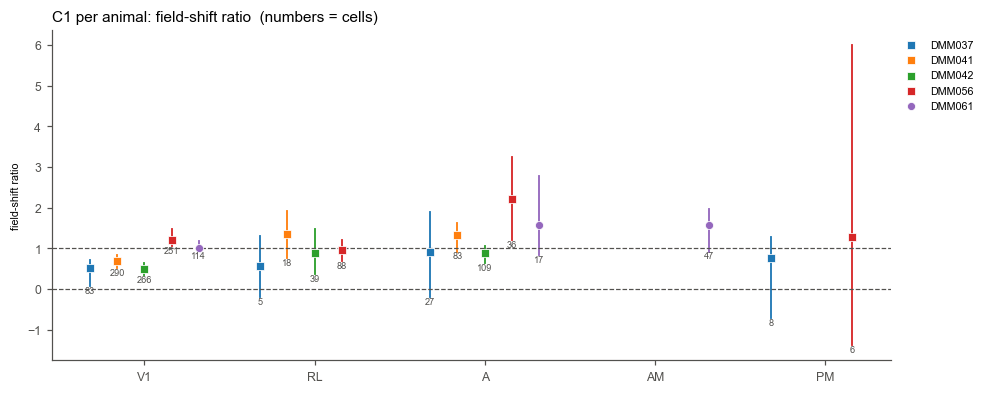

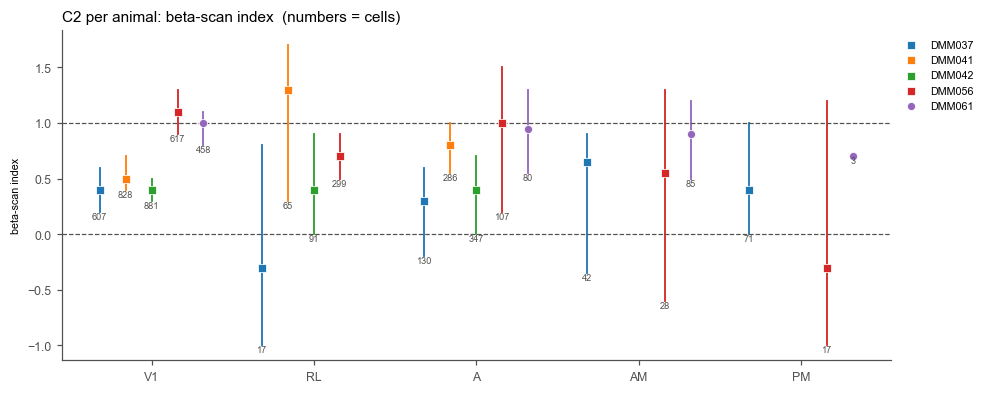

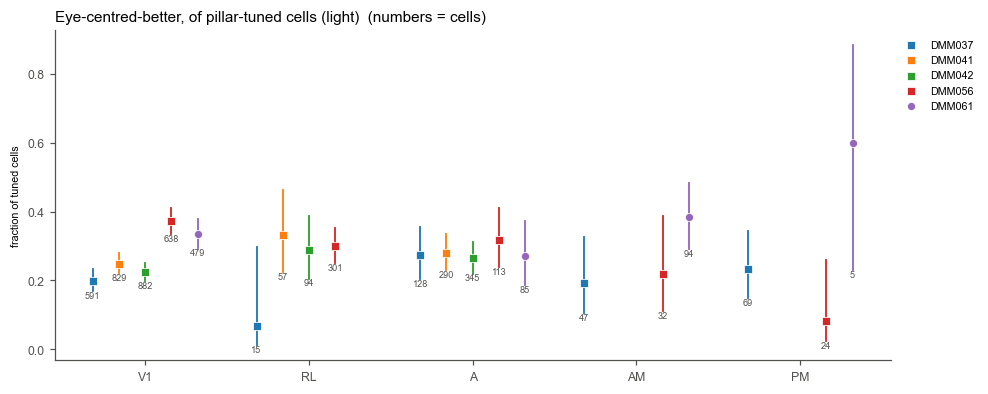

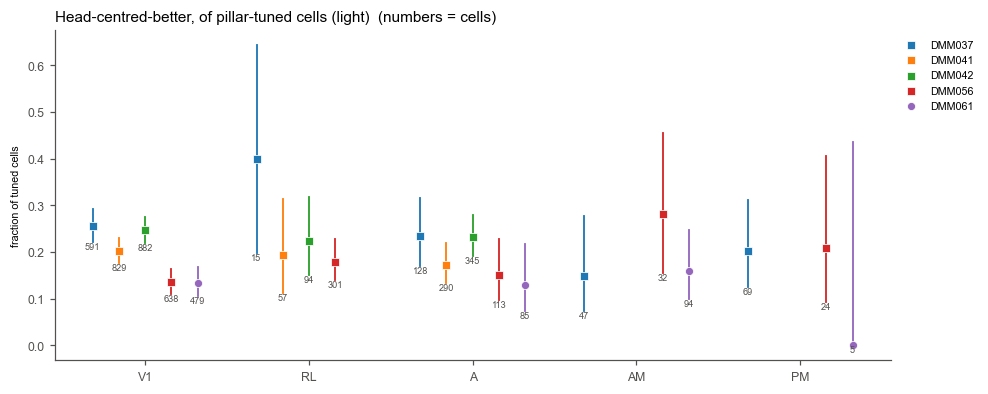

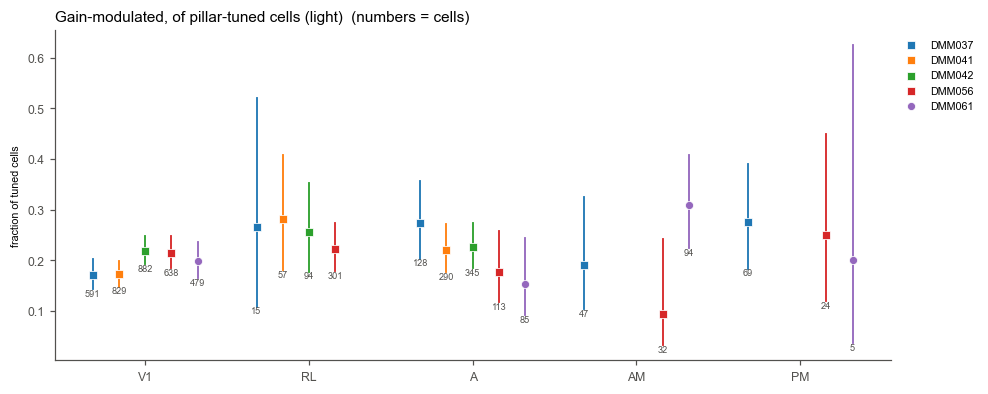

In [138]:
ANIMALS = sorted(CELLS['animal'].unique())
ANIMAL_COLORS = dict(zip(ANIMALS, plt.get_cmap('tab10')(np.arange(len(ANIMALS)) % 10)))
ANIMAL_NOIMU = CELLS.groupby('animal')['no_imu'].first().to_dict()


def animal_points(col, mask_col=None, kind='median', ylabel='', title='', refs=(), clip=None, name='fig'):
    fig, ax = plt.subplots(figsize=(1.3 * max(len(AREAS), 3) + 2.5, 3.6))
    w = 0.8 / max(len(ANIMALS), 1)
    for i, a in enumerate(AREAS):
        for j, an in enumerate(ANIMALS):
            m = (CELLS['area'] == a) & (CELLS['animal'] == an)
            if mask_col is not None:
                m &= CELLS[mask_col].astype(bool)
            if m.sum() < 3:
                continue
            x = i + (j - (len(ANIMALS) - 1) / 2) * w
            if kind == 'frac':
                v = CELLS.loc[m, col].astype(bool)
                y, (lo, hi) = v.mean(), frac_ci(int(v.sum()), len(v))
            else:
                v = CELLS.loc[m, col].to_numpy(float)
                v = v[np.isfinite(v)]
                if clip is not None:
                    v = np.clip(v, *clip)
                if len(v) < 3:
                    continue
                y, (lo, hi) = np.nanmedian(v), boot_ci(v)
            ax.plot([x, x], [lo, hi], color=ANIMAL_COLORS[an], lw=1.2)
            ax.scatter([x], [y], s=28, color=ANIMAL_COLORS[an], marker='s' if ANIMAL_NOIMU[an] else 'o',
                       edgecolor='white', lw=0.5, zorder=3, label=an if an not in ax.get_legend_handles_labels()[1] else None)
            ax.text(x, lo, str(int(m.sum())), ha='center', va='top', fontsize=6, color=INK2)
    for r in refs:
        ax.axhline(r, color=INK2, lw=0.8, ls='--')
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel(ylabel)
    ax.set_title(title + '  (numbers = cells)', loc='left', fontsize=10)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax)
    show(fig, name)


animal_points('eye_ratio', 'eye_reliable', ylabel='field-shift ratio', title='C1 per animal: field-shift ratio',
              refs=(0, 1), name='H1a_eye_ratio_by_animal')
animal_points('beta_index', 'beta_tuned', ylabel='beta-scan index', title='C2 per animal: beta-scan index',
              refs=(0, 1), name='H1b_beta_index_by_animal')
animal_points('gm_eye_better', 'gm_tuned', kind='frac', ylabel='fraction of tuned cells',
              title='Eye-centred-better, of pillar-tuned cells (light)', name='H1c_eye_better_by_animal')
animal_points('gm_head_better', 'gm_tuned', kind='frac', ylabel='fraction of tuned cells',
              title='Head-centred-better, of pillar-tuned cells (light)', name='H1d_head_better_by_animal')
animal_points('gm_gain', 'gm_tuned', kind='frac', ylabel='fraction of tuned cells',
              title='Gain-modulated, of pillar-tuned cells (light)', name='H1e_gain_by_animal')

In [139]:
def _area_animal_row(g):
    t = g['gm_tuned']
    return pd.Series({'cohort': g['cohort'].iloc[0], 'no_imu': bool(g['no_imu'].iloc[0]),
                      'sessions': g['session'].nunique(), 'cells': len(g), 'beat_null': g['sig'].mean(),
                      'reliable_fields': int(g['eye_reliable'].sum()),
                      'eye_ratio_med': g.loc[g['eye_reliable'], 'eye_ratio'].median(),
                      'beta_tuned': int(g['beta_tuned'].sum()),
                      'beta_index_med': g.loc[g['beta_tuned'], 'beta_index'].median(),
                      'gm_tuned_light': t.mean(), 'gm_tuned_dark': g['gm_tuned_dark'].mean(),
                      'eye_better_of_tuned': g.loc[t, 'gm_eye_better'].mean() if t.any() else np.nan,
                      'head_better_of_tuned': g.loc[t, 'gm_head_better'].mean() if t.any() else np.nan,
                      'gain_of_tuned': g.loc[t, 'gm_gain'].mean() if t.any() else np.nan})


AREA_ANIMAL = (CELLS[CELLS['area'].isin(AREAS)].groupby(['area', 'animal']).apply(_area_animal_row)
               .reindex(AREAS, level=0))
AREA_ANIMAL.round(2)

cohort  no_imu  sessions  cells  beat_null  reliable_fields  eye_ratio_med  beta_tuned  beta_index_med  gm_tuned_light  gm_tuned_dark  eye_better_of_tuned  \
area animal                                                                                                                                                                            
V1   DMM037  cohort01_recordings    True         4   1135       0.47               83           0.51         607            0.40            0.52           0.12                 0.20   
     DMM041  cohort01_recordings    True         5   1873       0.34              290           0.68         828            0.50            0.44           0.05                 0.25   
     DMM042  cohort01_recordings    True         4   1510       0.57              266           0.50         881            0.40            0.58           0.11                 0.22   
     DMM056  cohort02_recordings   False        12   1650       0.45              251           1.21         617            1.10            0.39           0.03                 0.37   
     DMM061  cohort02_recordings   False        10   1008       0.47              114           1.00         458            1.00            0.48           0.21                 0.34   
RL   DMM037  cohort01_recordings    True         2     40       0.50                5           0.56          17           -0.30            0.38           0.08                 0.07   
     DMM041  cohort01_recordings    True         1    115       0.48               18           1.36          65            1.30            0.50           0.02                 0.33   
     DMM042  cohort01_recordings    True         3    181       0.61               39           0.90          91            0.40            0.52           0.41                 0.29   
     DMM056  cohort02_recordings    True         4    674       0.46               88           0.95         299            0.70            0.45           0.01                 0.30   
A    DMM037  cohort01_recordings    True         4    461       0.36               27           0.91         130            0.30            0.28           0.05                 0.27   
     DMM041  cohort01_recordings    True         2    583       0.53               83           1.32         286            0.80            0.50           0.01                 0.28   
     DMM042  cohort01_recordings    True         3    910       0.35              109           0.88         347            0.40            0.38           0.14                 0.26   
     DMM056  cohort02_recordings    True         4    334       0.31               36           2.20         107            1.00            0.34           0.00                 0.32   
     DMM061  cohort02_recordings   False         3    164       0.46               17           1.57          80            0.95            0.52           0.16                 0.27   
AM   DMM037  cohort01_recordings    True         1    127       0.26                2           0.22          42            0.65            0.37           0.06                 0.19   
     DMM056  cohort02_recordings    True         1     71       0.35                0            NaN          28            0.55            0.45           0.00                 0.22   
     DMM061  cohort02_recordings   False         2    182       0.58               47           1.56          85            0.90            0.52           0.19                 0.38   
PM   DMM037  cohort01_recordings    True         2    179       0.37                8           0.77          71            0.40            0.39           0.09                 0.23   
     DMM041  cohort01_recordings    True         1      2       0.50                0            NaN           1            1.80            0.50           0.00                 1.00   
     DMM056  cohort02_recordings   False         2    180       0.08                6           1.28          17           -0.30            0.13           0.06   

In [140]:
CMP_FIELDS = {'sig': ('encoding', 'sig'), 'eye_reliable': ('refframe/eye_shift', 'reliable'),
              'eye_ratio': ('refframe/eye_shift', 'ratio'), 'beta_tuned': ('refframe/eye_beta', 'tuned'),
              'beta_index': ('refframe/eye_beta', 'index'), 'beta_prefer_first': ('refframe/eye_beta', 'prefer_first'),
              'beta_prefer_second': ('refframe/eye_beta', 'prefer_second'), 'gm_tuned': ('refframe/eye_models', 'tuned'),
              'gm_gain': ('refframe/eye_models', 'gain'), 'gm_eye_better': ('refframe/eye_models', 'eye_better'),
              'gm_head_better': ('refframe/eye_models', 'head_better'), 'ovc_stab': ('ovc', 'stab')}
CMP_CATS = ['sig', 'eye_reliable', 'beta_tuned', 'beta_prefer_first', 'beta_prefer_second', 'gm_tuned', 'gm_gain',
            'gm_eye_better', 'gm_head_better']


def cmp_load(path):
    with h5py.File(path, 'r') as f:
        out = {k: f[g][v][()] for k, (g, v) in CMP_FIELDS.items()}
        out['area'] = np.array(L_(f['cells']['area'][()]))
        dec = {}
        for a in f.get('decoders', {}):
            for tg in ('eta', 'rho'):
                if tg in f['decoders'][a]:
                    x = f['decoders'][a][tg]
                    for k in ('invariance', 'bias_index', 'P_within', 'p_within'):
                        dec[(a, tg, k)] = float(x[k][()])
                    for k in ('invariance', 'bias_index'):
                        dec[(a, tg, k + '_sd')] = float(np.nanstd(x[k + '_splits'][()])) if k + '_splits' in x else np.nan
    return out, dec


cmp_tabs, cmp_dec = [], []
TWINS = SES[SES['has_noimu_twin'] & ~SES['no_imu']]
for _, s in TWINS.iterrows():
    A, dA = cmp_load(s['path'])
    B, dB = cmp_load(s['prefix'] + '_neural{}{}.h5'.format(SPIKE_SUFFIX, NOIMU_TAG))
    if len(A['area']) != len(B['area']):
        print('{}: cell counts differ ({} vs {}) -- skipped.'.format(s['session'], len(A['area']), len(B['area'])))
        continue
    t = {'session': s['session'], 'animal': s['animal'], 'area': A['area']}
    for k in CMP_FIELDS:
        t[k + '_imu'], t[k + '_noimu'] = A[k], B[k]
    cmp_tabs.append(pd.DataFrame(t))
    for (a, tg, k) in {key for key in dA if key[2] in ('invariance', 'bias_index')}:
        cmp_dec.append({'session': s['session'], 'area': a, 'decoder': tg, 'stat': k,
                        'imu': dA[(a, tg, k)], 'noimu': dB.get((a, tg, k), np.nan),
                        'imu_sd': dA.get((a, tg, k + '_sd'), np.nan), 'noimu_sd': dB.get((a, tg, k + '_sd'), np.nan),
                        'sig': dA.get((a, 'eta', 'p_within'), 1) < 0.05 and dA.get((a, 'rho', 'p_within'), 1) < 0.05})
CMP = pd.concat(cmp_tabs, ignore_index=True) if cmp_tabs else pd.DataFrame()
CMPD = pd.DataFrame(cmp_dec)
if len(CMP):
    for k in CMP_CATS:
        for v in ('imu', 'noimu'):
            CMP['{}_{}'.format(k, v)] = CMP['{}_{}'.format(k, v)].astype(bool)
    if not INCLUDE_NON_AREAS:
        CMP = CMP[~CMP['area'].isin(NON_AREAS)]
    print('{} cells from {} sessions with both runs.'.format(len(CMP), CMP['session'].nunique()))
else:
    print('No _neural{}{}.h5 next to any IMU session yet -- run python -m fm2p.analyze --batch '
          '--simulate_no_imu.'.format(SPIKE_SUFFIX, NOIMU_TAG))


def kappa(a, b):
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    po = np.mean(a == b)
    pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return (po - pe) / (1 - pe) if pe < 1 else np.nan


def agreement_table(df):
    rows = []
    for k in CMP_CATS:
        a, b = df[k + '_imu'], df[k + '_noimu']
        rows.append({'category': k, 'IMU': int(a.sum()), 'no IMU': int(b.sum()), 'both': int((a & b).sum()),
                     'agreement': np.mean(a == b), 'kappa': kappa(a, b)})
    return pd.DataFrame(rows).set_index('category')


if len(CMP):
    display(agreement_table(CMP).round(2))
    print("Cohen's kappa per area:")
    display(pd.concat({a: agreement_table(CMP[CMP['area'] == a])['kappa'] for a in AREAS
                       if (CMP['area'] == a).sum() >= MIN_CELLS}, axis=1).round(2))

,IMU,no IMU,both,agreement,kappa
category,,,,,
sig,184,196,165,0.88,0.76
eye_reliable,40,43,35,0.97,0.83
beta_tuned,230,226,179,0.77,0.53
beta_prefer_first,76,75,42,0.84,0.46
beta_prefer_second,34,40,20,0.92,0.50
gm_tuned,252,239,202,0.79,0.57
gm_gain,51,43,21,0.88,0.38
gm_eye_better,85,88,55,0.85,0.54
gm_head_better,36,33,19,0.93,0.51


,V1
category,
sig,0.76
eye_reliable,0.83
beta_tuned,0.53
beta_prefer_first,0.46
beta_prefer_second,0.50
gm_tuned,0.57
gm_gain,0.38
gm_eye_better,0.54
gm_head_better,0.51


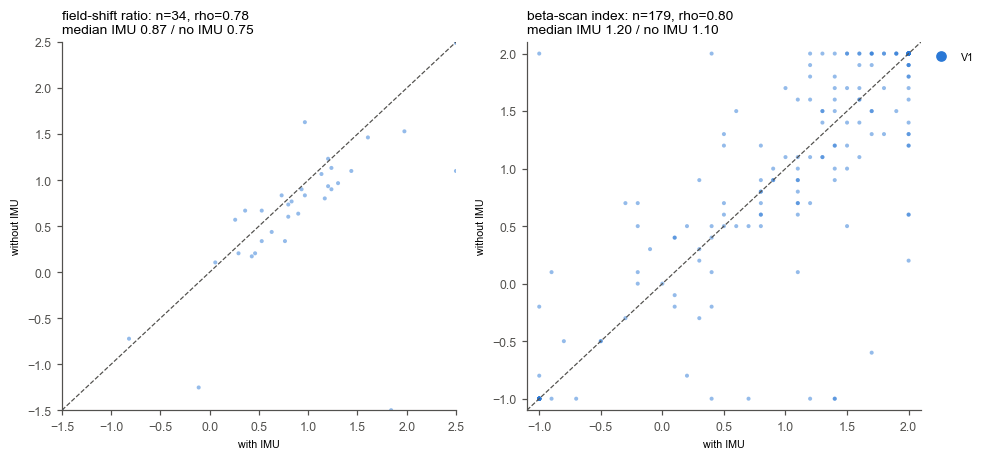

In [141]:
if len(CMP):
    fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
    for ax, (k, mk, lim, lab) in zip(axs, (('eye_ratio', 'eye_reliable', (-1.5, 2.5), 'field-shift ratio'),
                                           ('beta_index', 'beta_tuned', (-1.1, 2.1), 'beta-scan index'))):
        m = CMP[mk + '_imu'] & CMP[mk + '_noimu']
        x, y = np.clip(CMP.loc[m, k + '_imu'], *lim), np.clip(CMP.loc[m, k + '_noimu'], *lim)
        ax.scatter(x, y, s=7, c=[acol(a) for a in CMP.loc[m, 'area']], alpha=0.5, lw=0)
        ax.plot(lim, lim, color=INK2, lw=0.8, ls='--')
        ok = np.isfinite(x) & np.isfinite(y)
        rho = spearmanr(x[ok], y[ok]).correlation if ok.sum() > 2 else np.nan
        ax.set_title('{}: n={}, rho={:.2f}\nmedian IMU {:.2f} / no IMU {:.2f}'.format(
            lab, int(ok.sum()), rho, np.nanmedian(x), np.nanmedian(y)), loc='left', fontsize=9)
        ax.set_xlabel('with IMU')
        ax.set_ylabel('without IMU')
        ax.set_xlim(lim)
        ax.set_ylim(lim)
        style(ax, grid_y=False)
    handles = [plt.Line2D([], [], marker='o', ls='', color=acol(a), label=a) for a in AREAS if (CMP['area'] == a).any()]
    axs[1].legend(handles=handles, fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'I2_continuous_imu_vs_noimu')

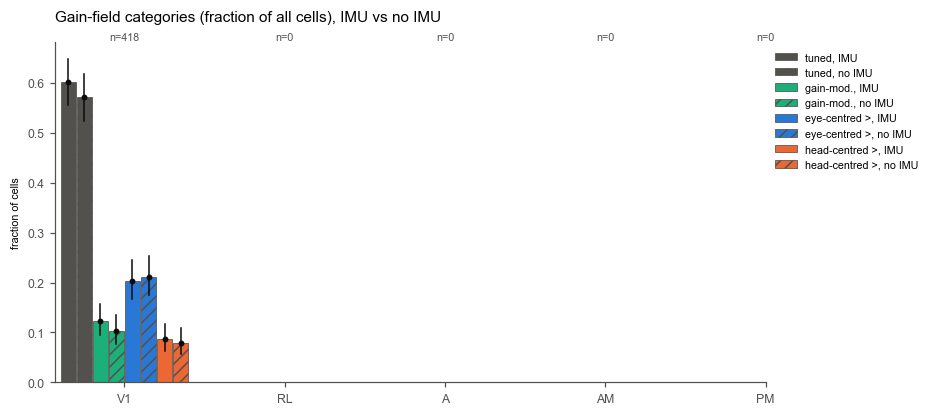

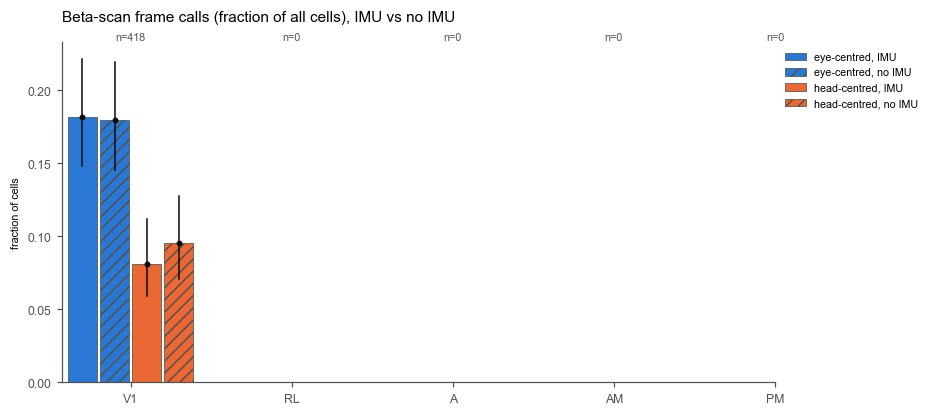

In [142]:
if len(CMP):
    for cats, title, name in (((('gm_tuned', 'tuned'), ('gm_gain', 'gain-mod.'), ('gm_eye_better', 'eye-centred >'),
                                ('gm_head_better', 'head-centred >')), 'Gain-field categories', 'I3a_gain_categories'),
                              ((('beta_prefer_first', 'eye-centred'), ('beta_prefer_second', 'head-centred')),
                               'Beta-scan frame calls', 'I3b_frame_calls')):
        cols, labs, colors, hatch = [], [], [], []
        for (c, l), col in zip(cats, ['#52514e', '#1baf7a', '#2a78d6', '#eb6834'] if len(cats) == 4 else ['#2a78d6', '#eb6834']):
            cols += [c + '_imu', c + '_noimu']
            labs += [l + ', IMU', l + ', no IMU']
            colors += [col, col]
            hatch += [None, '///']
        frac_by_area(cols, labs, colors, hatch=hatch, title=title + ' (fraction of all cells), IMU vs no IMU',
                     name=name, df=CMP)

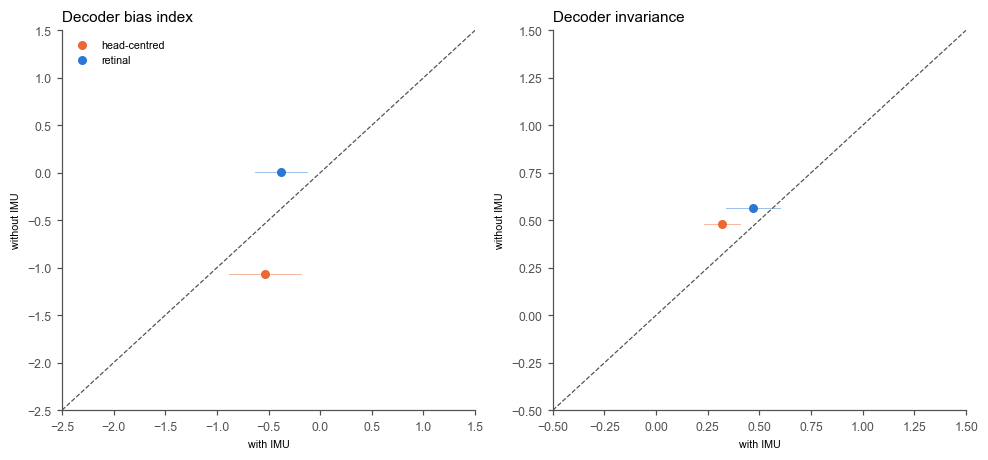

imu                                       noimu                                 
decoder                             eta                   rho                   eta                   rho           
stat                         bias_index invariance bias_index invariance bias_index invariance bias_index invariance
session                 area                                                                                        
251016_DMM_DMM061_pos18 V1        -0.53       0.32      -0.38       0.47      -1.07       0.48       0.01       0.56

In [143]:
if len(CMPD):
    fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
    for ax, (stat, lim) in zip(axs, (('bias_index', (-2.5, 1.5)), ('invariance', (-0.5, 1.5)))):
        for tg, col, lab in (('eta', '#eb6834', 'head-centred'), ('rho', '#2a78d6', 'retinal')):
            dd = CMPD[(CMPD['stat'] == stat) & (CMPD['decoder'] == tg)]
            for _, r in dd.iterrows():
                ax.plot([r['imu'] - r['imu_sd'], r['imu'] + r['imu_sd']], [r['noimu']] * 2, color=col, lw=0.6, alpha=0.5)
                ax.plot([r['imu']] * 2, [r['noimu'] - r['noimu_sd'], r['noimu'] + r['noimu_sd']], color=col, lw=0.6, alpha=0.5)
            s_ = dd['sig'].to_numpy(bool)
            ax.scatter(dd['imu'][s_], dd['noimu'][s_], s=24, color=col, label=lab, zorder=3)
            ax.scatter(dd['imu'][~s_], dd['noimu'][~s_], s=24, facecolor='white', edgecolor=col, zorder=3)
        ax.plot(lim, lim, color=INK2, lw=0.8, ls='--')
        ax.set_xlim(lim)
        ax.set_ylim(lim)
        ax.set_xlabel('with IMU')
        ax.set_ylabel('without IMU')
        ax.set_title('Decoder {}'.format(stat.replace('_', ' ')), loc='left', fontsize=10)
        style(ax, grid_y=False)
    axs[0].legend(fontsize=7, frameon=False)
    show(fig, 'I4_decoders_imu_vs_noimu')
    display(CMPD.pivot_table(index=['session', 'area'], columns=['decoder', 'stat'], values=['imu', 'noimu']).round(2))

In [144]:
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)
from fm2p import new_analysis as na
from fm2p.ffNLE_scene import _triangle_smooth, cv_ridge, _svd_prep, _ridge_coefs

NULL_MIN_SHIFT = 400


def rebuild_session(s):
    with h5py.File(s['path'], 'r') as f:
        cv = f['covariates']
        D = {k: cv[k][()] for k in cv.keys()}
        h5p, sk = S_(f['meta']['h5_path'][()]), S_(f['meta']['spike_key'][()])
        mean_rate = f['cells']['mean_rate'][()]
        gm = {k: f['gain_model'][k][()] for k in f['gain_model'].keys()}
        stored = {k: f['refframe']['eye_models'][k][()].astype(bool) for k in ('tuned', 'gain')}
        area = np.array(L_(f['cells']['area'][()]))
    if not os.path.isfile(h5p):
        return None, 'no preproc.h5 at {}'.format(h5p)
    with h5py.File(h5p, 'r') as f:
        if sk not in f:
            return None, 'preproc.h5 has no {}'.format(sk)
        Yr = np.asarray(f[sk][()], float).T
    n = len(D['t'])
    if Yr.shape[0] < n or Yr.shape[1] != len(mean_rate):
        return None, 'preproc activity is {} for {} frames x {} cells'.format(Yr.shape, n, len(mean_rate))
    Yr = Yr[:n]
    if not np.allclose(np.nanmean(Yr, 0), mean_rate, rtol=1e-5, atol=1e-9, equal_nan=True):
        return None, 'preproc activity changed since the _neural.h5 was written'
    D['names'] = L_(D['names'])
    D['dt'] = float(np.median(np.diff(D['t'])))
    D['Y'] = _triangle_smooth(np.where(np.isfinite(Yr), Yr, 0.0), na.SMOOTH_S, D['dt'])
    D['X'] = D['X'].astype(float)
    D['use'], D['light'] = D['use'].astype(bool), D['light'].astype(bool)
    gm['nuis_names'] = L_(gm['nuis_names'])
    return {'D': D, 'gm': gm, 'stored': stored, 'area': area}, ''


def eye_nuis_cols(names):
    nm = np.array(names)
    return np.r_[np.flatnonzero(np.char.startswith(nm, 'hd_vm')),
                 [names.index(k) for k in ('pitch', 'roll', 'speed', 'log_dist')]].astype(int)


def gain_designs(D, mask):
    use = mask & np.isfinite(D['rho']) & np.isfinite(D['eta']) & np.isfinite(D['e'])
    e = D['e']
    mu, sd = np.nanmean(e[use]), np.nanstd(e[use])
    mz = (e - mu) / sd
    eb = na._gauss_basis(e, np.nanpercentile(e[use], [10, 37, 63, 90]), max(sd / 1.5, 1.0))
    nuis = D['X'][:, eye_nuis_cols(D['names'])]
    vr, vh = na._vm_basis(D['rho']), na._vm_basis(D['eta'])
    base = {'NUIS': np.c_[nuis, mz], 'RET': np.c_[nuis, mz, vr], 'ADD': np.c_[nuis, mz, vr, eb],
            'HEAD': np.c_[nuis, mz, vh, eb]}

    def gain(m):
        return np.c_[base['ADD'], vr * m[:, None]]
    return use, mz, base, gain


def beats(fa, fb):
    return (fa['r2'] > fb['r2']) & (np.sum(fa['r2_folds'] - fb['r2_folds'] > 0, 0) >= 4)


def full_fit(X, Y, use, lam):
    xm, xs = np.nanmean(X[use], 0), np.nanstd(X[use], 0)
    xs[~(xs > 0)] = 1.0
    Yu = Y[use]
    ym = Yu.mean(0)
    U, s_, Vt = _svd_prep((X[use] - xm) / xs)
    lam = np.nanmedian(lam, 0)
    coef = _ridge_coefs(U, s_, Vt, Yu - ym, np.where(np.isfinite(lam), lam, 1e3))
    return {'coef': coef, 'x_mean': xm, 'x_sd': xs, 'y_mean': ym}


def predict(fit, X):
    return ((X - fit['x_mean']) / fit['x_sd']) @ fit['coef'] + fit['y_mean']


def gain_null(R, n_shuf, n_fields, seed=0):
    D = R['D']
    use, mz, base, gain = gain_designs(D, D['light'] & D['use'])
    idx = np.flatnonzero(use)
    if len(idx) < 3 * NULL_MIN_SHIFT:
        return None
    folds = na._folds(D, use)
    fits = {k: na._cv(X, D['Y'], folds) for k, X in base.items()}
    fits['GAIN'] = na._cv(gain(mz), D['Y'], folds)
    tuned = beats(fits['RET'], fits['NUIS']) | beats(fits['HEAD'], fits['NUIS'])
    call = tuned & beats(fits['GAIN'], fits['ADD'])
    d_real = fits['GAIN']['r2'] - fits['ADD']['r2']
    rng = np.random.default_rng(seed)
    C = D['Y'].shape[1]
    null_call, d_null = np.zeros((n_shuf, C), bool), np.full((n_shuf, C), np.nan)
    nf = []
    for k in range(n_shuf):
        ms = mz.copy()
        ms[idx] = np.roll(mz[idx], int(rng.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT)))
        Xn = gain(ms)
        fn = na._cv(Xn, D['Y'], folds)
        null_call[k] = tuned & beats(fn, fits['ADD'])
        d_null[k] = fn['r2'] - fits['ADD']['r2']
        if k < n_fields:
            nf.append(full_fit(Xn, D['Y'], use, fn['lam']))
    out = {'tuned': tuned, 'call': call, 'd_real': d_real, 'null_call': null_call, 'd_null': d_null,
           'p': (1 + np.sum(d_null >= d_real[None], 0)) / (1 + n_shuf),
           'stored_gain': R['stored']['gain'], 'stored_tuned': R['stored']['tuned']}
    for k in ('coef', 'x_mean', 'x_sd', 'y_mean'):
        out['nf_' + k] = np.stack([f[k] for f in nf]) if nf else np.zeros((0,))
    return out


def head_specific_target(D, m):
    e = D['e']
    ez = (e - np.nanmean(e[m])) / np.nanstd(e[m])
    vr, H = na._vm_basis(D['rho']), na._vm_basis(D['eta'])
    A = np.c_[np.ones(len(e)), vr, ez]
    coef = np.linalg.lstsq(A[m], H[m], rcond=None)[0]
    return np.nan_to_num(H - A @ coef)


def readout_r2(D, U, T, m):
    use = m & np.all(np.isfinite(U), 1)
    trm, tem, block = na._folds(D, use)
    return float(np.nanmean(cv_ridge(na._zbuilder(np.nan_to_num(U)), T, trm, tem, block)['r2']))


def gain_snr(fit, X, Y, idx):
    k = na.N_VM
    Zp = (X[:, -k:] - fit['x_mean'][-k:]) / fit['x_sd'][-k:]
    g = Zp[idx] @ fit['coef'][-k:]
    r = Y[idx] - predict(fit, X[idx])
    return np.var(g, 0) / np.maximum(np.var(r, 0), 1e-12)


def snr_scan(R, g, alphas, n_seeds, min_tuned, seed=0):
    D, gm = R['D'], R['gm']
    light = D['light'] & D['use']
    use, mz, base, gain = gain_designs(D, light)
    m = use
    T = head_specific_target(D, m)
    Xg = gain(mz)
    fits = [('real', {'coef': gm['coef'], 'x_mean': gm['x_mean'], 'x_sd': gm['x_sd'], 'y_mean': gm['y_mean']})]
    fits += [('null', {k: g['nf_' + k][j] for k in ('coef', 'x_mean', 'x_sd', 'y_mean')})
             for j in range(len(g['nf_coef']))]
    idx = np.flatnonzero(m & np.all(np.isfinite(Xg), 1))
    out = {'gain_snr': gain_snr(fits[0][1], Xg, D['Y'], idx),
           'gain_snr_null': np.stack([gain_snr(f, Xg, D['Y'], idx) for k, f in fits[1:]]) if len(fits) > 1
           else np.zeros((0, D['Y'].shape[1]))}
    tuned = R['stored']['tuned']
    areas = [a for a in sorted(set(R['area'])) if a not in NON_AREAS
             and np.sum(tuned & (R['area'] == a)) >= min_tuned]
    nf = len(fits) - 1
    r2_real = np.full((len(areas), len(alphas), n_seeds), np.nan)
    r2_null = np.full((len(areas), len(alphas), max(nf, 1)), np.nan)
    r2_rec, n_units = np.full(len(areas), np.nan), np.zeros(len(areas), int)
    rng = np.random.default_rng(seed)
    for ai, a in enumerate(areas):
        cells = np.flatnonzero(tuned & (R['area'] == a))
        n_units[ai] = len(cells)
        U = np.full((len(D['t']), len(cells)), np.nan)
        U[idx] = D['Y'][idx][:, cells]
        r2_rec[ai] = readout_r2(D, U, T, m)
        for fi, (kind, fit) in enumerate(fits):
            G = predict({k: (v[:, cells] if k == 'coef' else v[cells] if k == 'y_mean' else v)
                         for k, v in fit.items()}, Xg[idx])
            res = D['Y'][idx][:, cells] - G
            seeds = n_seeds if kind == 'real' else 1
            for si in range(seeds):
                sh = rng.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT, len(cells))
                Nz = np.stack([np.roll(res[:, j], sh[j]) for j in range(len(cells))], 1)
                for li, al in enumerate(alphas):
                    U[idx] = G + al * Nz
                    v = readout_r2(D, U, T, m)
                    if kind == 'real':
                        r2_real[ai, li, si] = v
                    else:
                        r2_null[ai, li, fi - 1] = v
    out.update({'areas': np.array(areas, dtype=str), 'n_units': n_units, 'r2_real': r2_real,
                'r2_null': r2_null, 'r2_recorded': r2_rec, 'alphas': np.asarray(alphas, float)})
    return out

In [145]:
import fm2p

_T = '__type__'


def _pack_values(v):
    v = np.asarray(v)
    if v.dtype == object:
        if len(v) and all(isinstance(x, str) for x in v):
            v = v.astype(str)
        else:
            return h5_pack(v)
    return h5_pack(v)


def _pack_index(ix):
    if isinstance(ix, pd.RangeIndex):
        return {_T: 'range_index', 'start': ix.start, 'stop': ix.stop, 'step': ix.step, 'name': h5_pack(ix.name)}
    if isinstance(ix, pd.MultiIndex):
        return {_T: 'multi_index', 'tuples': h5_pack(list(ix)), 'names': h5_pack(list(ix.names))}
    return {_T: 'index', 'values': _pack_values(ix.to_numpy()), 'dtype': str(ix.dtype), 'name': h5_pack(ix.name)}


def h5_pack(x):
    if x is None:
        return {_T: 'none'}
    if isinstance(x, (bool, int, float)) and not isinstance(x, np.generic):
        return {_T: type(x).__name__, 'value': x}
    if isinstance(x, (str, np.generic)):
        return x
    if isinstance(x, bytes):
        return {_T: 'bytes', 'value': np.void(x)}
    if isinstance(x, np.ndarray):
        if x.ndim == 0:
            return {_T: 'array0', 'value': h5_pack(x.reshape(1))}
        if x.dtype.kind == 'U':
            return {_T: 'str_array', 'shape': np.array(x.shape), 'value': np.char.encode(x.ravel(), 'utf-8')
                    if x.size else np.zeros(0, 'S1')}
        if x.dtype == object:
            return {_T: 'object_array', 'shape': np.array(x.shape), 'items': h5_pack(list(x.ravel()))}
        return x
    if isinstance(x, (list, tuple, set)):
        return {_T: type(x).__name__, 'n': len(x), **{str(i): h5_pack(v) for i, v in enumerate(x)}}
    if isinstance(x, dict):
        return {_T: 'dict', 'keys': h5_pack(list(x)), **{str(i): h5_pack(v) for i, v in enumerate(x.values())}}
    if isinstance(x, pd.DataFrame):
        return {_T: 'frame', 'columns': _pack_index(x.columns), 'index': _pack_index(x.index),
                'dtypes': h5_pack([str(t) for t in x.dtypes]),
                **{str(i): _pack_values(x.iloc[:, i].to_numpy()) for i in range(x.shape[1])}}
    if isinstance(x, pd.Series):
        return {_T: 'series', 'index': _pack_index(x.index), 'dtype': str(x.dtype), 'name': h5_pack(x.name),
                'values': _pack_values(x.to_numpy())}
    raise TypeError('cannot save a {} to DATA_H5'.format(type(x).__name__))


def _unpack_index(d):
    t = S_(d[_T])
    if t == 'range_index':
        return pd.RangeIndex(int(d['start']), int(d['stop']), int(d['step']), name=h5_unpack(d['name']))
    if t == 'multi_index':
        return pd.MultiIndex.from_tuples(h5_unpack(d['tuples']), names=h5_unpack(d['names']))
    return pd.Index(h5_unpack(d['values']), dtype=S_(d['dtype']), name=h5_unpack(d['name']))


def h5_unpack(x):
    if isinstance(x, (bytes, np.bytes_)):
        return x.decode()
    if not isinstance(x, dict):
        return x
    t = S_(x[_T])
    n = lambda: int(x['n'])
    if t == 'none':
        return None
    if t in ('bool', 'int', 'float'):
        return {'bool': bool, 'int': int, 'float': float}[t](x['value'])
    if t == 'bytes':
        return x['value'].tobytes()
    if t == 'array0':
        return h5_unpack(x['value']).reshape(())
    if t == 'str_array':
        return np.char.decode(x['value'], 'utf-8').reshape(tuple(x['shape'])) if x['value'].size else \
            np.zeros(tuple(x['shape']), str)
    if t == 'object_array':
        a = np.empty(len(h5_unpack(x['items'])), object)
        a[:] = h5_unpack(x['items'])
        return a.reshape(tuple(x['shape']))
    if t in ('list', 'tuple', 'set'):
        return {'list': list, 'tuple': tuple, 'set': set}[t](h5_unpack(x[str(i)]) for i in range(n()))
    if t == 'dict':
        return {k: h5_unpack(x[str(i)]) for i, k in enumerate(h5_unpack(x['keys']))}
    if t == 'frame':
        cols, dtypes = _unpack_index(x['columns']), h5_unpack(x['dtypes'])
        data = {i: pd.Series(h5_unpack(x[str(i)]), dtype=dt if dt != 'object' else object)
                for i, dt in enumerate(dtypes)}
        df = pd.DataFrame(data) if data else pd.DataFrame(index=_unpack_index(x['index']))
        df.columns = cols
        df.index = _unpack_index(x['index'])
        return df
    if t == 'series':
        dt = S_(x['dtype'])
        return pd.Series(h5_unpack(x['values']), index=_unpack_index(x['index']), name=h5_unpack(x['name']),
                         dtype=dt if dt != 'object' else object)
    raise ValueError('unknown stored type {}'.format(t))


SAVED = {}
if os.path.isfile(DATA_H5) and not RECOMPUTE:
    t0 = time.time()
    SAVED = {k: h5_unpack(v) for k, v in fm2p.read_h5(DATA_H5).items()}
    print('Read steps {} from {} ({:.0f} s); they are not refit.'.format(', '.join(SAVED), DATA_H5, time.time() - t0))
else:
    print('{} -- refit steps are computed (or read from CACHE_DIR) and saved there.'.format(
        'RECOMPUTE is on' if RECOMPUTE else 'No {} yet'.format(DATA_H5)))


def restore(step):
    if step not in SAVED:
        return False
    globals().update(SAVED[step])
    print('{}: read from {} ({}).'.format(step, os.path.basename(DATA_H5), ', '.join(SAVED[step])))
    return True


def stash(step, **values):
    SAVED[step] = values
    os.makedirs(os.path.dirname(DATA_H5), exist_ok=True)
    fm2p.write_h5(DATA_H5, {k: h5_pack(v) for k, v in SAVED.items()})

In [146]:
GN, SNR, REFIT_SKIPS = {}, {}, {}


def cached(s, tag, params, fn):
    path = os.path.join(CACHE_DIR, '{}_{}_{}{}.npz'.format(s['session'], s['rec'], tag, SPIKE_SUFFIX))
    key = json.dumps({'mtime': os.path.getmtime(s['path']), **params}, sort_keys=True)
    if os.path.isfile(path):
        with np.load(path, allow_pickle=False) as z:
            if str(z['_key']) == key:
                return {k: z[k] for k in z.files if k != '_key'}
    out = fn()
    if out is not None:
        os.makedirs(CACHE_DIR, exist_ok=True)
        np.savez(path, _key=key, **out)
    return out


if not (RUN_REFITS):
    print('RUN_REFITS is off -- sections J and L are skipped.')
elif not restore('J_L'):
    t_all = time.time()
    for i, s in SES.iterrows():
        box = {}

        def session():
            if 'R' not in box:
                try:
                    box['R'], box['why'] = rebuild_session(s)
                except (OSError, KeyError) as err:
                    box['R'], box['why'] = None, 'could not read: {}'.format(err)
            return box['R']

        def run_gain_null():
            R = session()
            return None if R is None else gain_null(R, GAIN_NULL_SHUFFLES, SNR_NULL_FIELDS)

        t0 = time.time()
        g = cached(s, 'gainnull', {'n': GAIN_NULL_SHUFFLES, 'nf': SNR_NULL_FIELDS, 'v': 1}, run_gain_null)
        if g is None:
            REFIT_SKIPS[s['session']] = box.get('why') or 'too few light frames'
            continue
        GN[s['session']] = g

        def run_snr():
            R = session()
            return None if R is None else snr_scan(R, g, SNR_ALPHAS, SNR_SEEDS, SNR_MIN_TUNED)

        r = cached(s, 'snr', {'alphas': list(SNR_ALPHAS), 'seeds': SNR_SEEDS, 'nf': SNR_NULL_FIELDS,
                              'min': SNR_MIN_TUNED, 'v': 1}, run_snr)
        if r is not None:
            SNR[s['session']] = r
        if time.time() - t0 > 1:
            print('[{}/{}] {}: {:.0f} s'.format(i + 1, len(SES), s['session'], time.time() - t0))
    print('Refits: {} sessions in {:.1f} min; {} skipped.'.format(len(GN), (time.time() - t_all) / 60, len(REFIT_SKIPS)))
    for k, v in REFIT_SKIPS.items():
        print('  skipped {}: {}'.format(k, v))
    stash('J_L', GN=GN, SNR=SNR, REFIT_SKIPS=REFIT_SKIPS)

In [147]:
%matplotlib inline

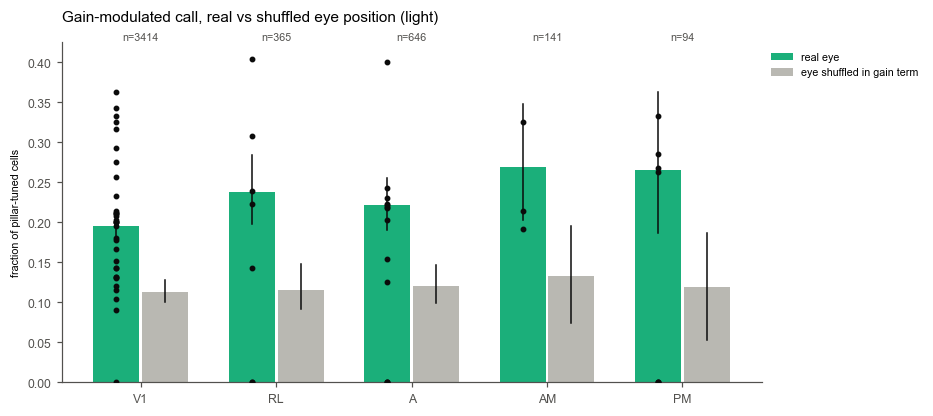

,tuned,called,real_frac,null_mean,null_hi,excess,real_over_null,p_shuffle,frac_p05
V1,3414.0,669.0,0.196,0.112,0.128,0.083,1.742,0.048,0.098
RL,365.0,87.0,0.238,0.116,0.148,0.122,2.054,0.048,0.148
A,646.0,143.0,0.221,0.121,0.146,0.100,1.829,0.048,0.104
AM,141.0,38.0,0.270,0.133,0.195,0.137,2.032,0.048,0.191
PM,94.0,25.0,0.266,0.119,0.186,0.147,2.232,0.048,0.128


In [148]:
GNC = pd.DataFrame()
if GN:
    GNC = pd.concat([pd.DataFrame({'session': k, 'cell': np.arange(len(g['tuned'])), 'gn_tuned': g['tuned'].astype(bool),
                                   'gn_call': g['call'].astype(bool), 'gn_p': g['p'],
                                   'gn_null_rate': g['null_call'].mean(0), 'gn_stored': g['stored_gain'].astype(bool)})
                     for k, g in GN.items()], ignore_index=True)
    print('Refit gain calls match the stored ones for {:.1%} of cells.'.format(np.mean(GNC['gn_call'] == GNC['gn_stored'])))
    GNC = GNC.merge(CELLS[['session', 'cell', 'area', 'animal', 'cohort']], on=['session', 'cell'])


def null_fracs(sel):
    num, den = np.zeros(GAIN_NULL_SHUFFLES), 0
    for sess, d in sel[sel['gn_tuned']].groupby('session'):
        c = d['cell'].to_numpy()
        num += GN[sess]['null_call'][:, c].sum(1)
        den += len(c)
    return num / den if den else np.full(GAIN_NULL_SHUFFLES, np.nan)


def gain_vs_null(sel):
    t = sel[sel['gn_tuned']]
    nf = null_fracs(sel)
    real = t['gn_call'].mean() if len(t) else np.nan
    return {'tuned': len(t), 'called': int(t['gn_call'].sum()), 'real_frac': real,
            'null_mean': np.nanmean(nf), 'null_hi': np.nanpercentile(nf, 97.5) if np.isfinite(nf).any() else np.nan,
            'excess': real - np.nanmean(nf), 'real_over_null': real / np.nanmean(nf) if np.nanmean(nf) > 0 else np.nan,
            'p_shuffle': (1 + np.sum(nf >= real)) / (1 + len(nf)),
            'frac_p05': (t['gn_p'] < 0.05).mean() if len(t) else np.nan}


if len(GNC):
    JT = pd.DataFrame({a: gain_vs_null(GNC[GNC['area'] == a]) for a in AREAS}).T
    fig, ax = plt.subplots(figsize=(1.3 * max(len(AREAS), 3) + 2, 3.8))
    for i, a in enumerate(AREAS):
        r = JT.loc[a]
        lo, hi = frac_ci(int(r['called']), int(r['tuned']))
        ax.bar(i - 0.18, r['real_frac'], width=0.34, color='#1baf7a', label='real eye' if i == 0 else None)
        ax.plot([i - 0.18] * 2, [lo, hi], color=INK, lw=1)
        nf = null_fracs(GNC[GNC['area'] == a])
        ax.bar(i + 0.18, np.nanmean(nf), width=0.34, color='#b9b8b2', label='eye shuffled in gain term' if i == 0 else None)
        ax.plot([i + 0.18] * 2, np.nanpercentile(nf, [2.5, 97.5]), color=INK, lw=1)
        d = GNC[(GNC['area'] == a) & GNC['gn_tuned']]
        sf = d.groupby('session')['gn_call'].mean()
        ax.scatter(np.full(len(sf), i - 0.18), sf, s=8, color=INK, zorder=3)
        ax.text(i, 1.0, 'n={}'.format(int(r['tuned'])), transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                fontsize=7, color=INK2)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel('fraction of pillar-tuned cells')
    ax.set_title('Gain-modulated call, real vs shuffled eye position (light)', loc='left', fontsize=10, pad=14)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax)
    show(fig, 'J1_gain_vs_null')
    display(JT.astype(float).round(3))

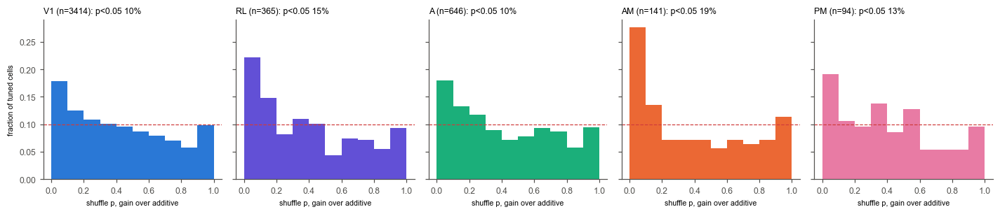

In [149]:
if len(GNC):
    fig, axs = plt.subplots(1, len(AREAS), figsize=(2.6 * len(AREAS), 2.8), squeeze=False, sharey=True)
    edges = np.linspace(0, 1, 11)
    for ax, a in zip(axs[0], AREAS):
        p = GNC.loc[(GNC['area'] == a) & GNC['gn_tuned'], 'gn_p'].to_numpy()
        if len(p):
            ax.hist(p, bins=edges, weights=np.full(len(p), 1 / len(p)), color=acol(a))
        ax.axhline(0.1, color='#d03b3b', lw=0.8, ls='--')
        ax.set_title('{} (n={}): p<0.05 {:.0%}'.format(a, len(p), np.mean(p < 0.05) if len(p) else np.nan),
                     loc='left', fontsize=8)
        ax.set_xlabel('shuffle p, gain over additive')
        style(ax)
    axs[0][0].set_ylabel('fraction of tuned cells')
    show(fig, 'J2_gain_p_hist')

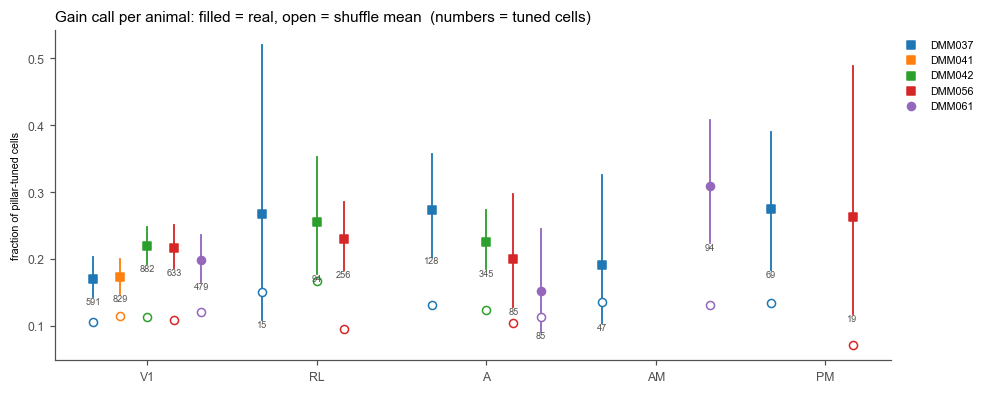

In [150]:
if len(GNC):
    fig, ax = plt.subplots(figsize=(1.3 * max(len(AREAS), 3) + 2.5, 3.6))
    w = 0.8 / max(len(ANIMALS), 1)
    for i, a in enumerate(AREAS):
        for j, an in enumerate(ANIMALS):
            sel = GNC[(GNC['area'] == a) & (GNC['animal'] == an)]
            if sel['gn_tuned'].sum() < 10:
                continue
            r = gain_vs_null(sel)
            x = i + (j - (len(ANIMALS) - 1) / 2) * w
            lo, hi = frac_ci(r['called'], r['tuned'])
            ax.plot([x, x], [lo, hi], color=ANIMAL_COLORS[an], lw=1.2)
            ax.scatter([x], [r['real_frac']], s=28, color=ANIMAL_COLORS[an], marker='s' if ANIMAL_NOIMU[an] else 'o',
                       zorder=3, label=an if an not in ax.get_legend_handles_labels()[1] else None)
            ax.scatter([x], [r['null_mean']], s=28, facecolor='white', edgecolor=ANIMAL_COLORS[an], zorder=3)
            ax.text(x, lo, str(r['tuned']), ha='center', va='top', fontsize=6, color=INK2)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel('fraction of pillar-tuned cells')
    ax.set_title('Gain call per animal: filled = real, open = shuffle mean  (numbers = tuned cells)', loc='left', fontsize=10)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax)
    show(fig, 'J3_gain_vs_null_by_animal')

In [151]:
from scipy.stats import mannwhitneyu


def eye_calibration(h5p):
    with h5py.File(h5p, 'r') as f:
        i0 = int(f['eyeT_startInd'][()]) if 'eyeT_startInd' in f else 0
        i1 = int(f['eyeT_endInd'][()]) if 'eyeT_endInd' in f else None
        x0 = np.asarray(f['X0'][()], float)[i0:i1]
        la = np.asarray(f['longaxis'][()], float)[i0:i1]
        sa = np.asarray(f['shortaxis'][()], float)[i0:i1]
        sc, cx = float(f['scale'][()]), float(f['cam_center_x'][()])
        scf = float(f['scale_fit'][()]) if 'scale_fit' in f else np.nan
    dx = x0 - cx
    return {'scale': sc, 'scale_fit': scf, 'pupil_px': np.nanmedian(la), 'pupil_round': np.nanmedian(sa / la),
            'x0_off': np.nanmedian(dx), 'x0_range': np.nanpercentile(x0, 95) - np.nanpercentile(x0, 5),
            'sat_frac': np.nanmean(np.abs(dx[np.isfinite(dx)]) / sc > 0.9)}


SCALE_DEP = ('scale', 'scale_fit', 'x0_off', 'sat_frac')
rows = []
for _, s in SES.iterrows():
    with h5py.File(s['path'], 'r') as f:
        cv = f['covariates']
        names = L_(cv['names'][()])
        lu = cv['use'][()].astype(bool) & cv['light'][()].astype(bool)
        X = cv['X'][()]
        e, rho, eta = cv['e'][()], cv['rho'][()], cv['eta'][()]
        dt = float(np.median(np.diff(cv['t'][()])))
        r = {'session': s['session'], 'animal': s['animal'], 'cohort': s['cohort'],
             'delta_e': float(f['refframe']['eye_shift']['delta'][()]), 'e_sd': np.nanstd(e[lu]),
             'speed_med': np.nanmedian(cv['speed'][()][lu]), 'dist_med': np.nanmedian(cv['dist_cm'][()][lu]),
             'in_view': np.nanmean(X[lu, names.index('in_view')]), 'usable_min': s['usable_min'],
             'light_frac': s['light_frac'], 'n_cells': s['n_cells']}
        h5p = S_(f['meta']['h5_path'][()])
    ok = lu & np.isfinite(rho)
    occ = np.bincount((((rho[ok] + 180) % 360) // 10).astype(int), minlength=36) * dt
    r['rho_cover'] = np.mean(occ >= 2.0)
    ok = lu & np.isfinite(e) & np.isfinite(eta)
    A = np.c_[np.ones(ok.sum()), na._vm_basis(eta[ok])]
    res = e[ok] - A @ np.linalg.lstsq(A, e[ok], rcond=None)[0]
    r['e_eta_r2'] = 1 - np.var(res) / np.var(e[ok])
    r['stale'] = not os.path.isfile(h5p) or os.path.getmtime(h5p) > os.path.getmtime(s['path'])
    try:
        r.update(eye_calibration(h5p))
    except (OSError, KeyError) as err:
        print('{}: no eye calibration ({})'.format(s['session'], err))
    if r['stale']:
        for k in SCALE_DEP:
            r[k] = np.nan
    rows.append(r)
SESD = pd.DataFrame(rows)

gb = CELLS.groupby("session")
q = pd.DataFrame({'frac_sig': gb["sig"].mean(),
                  'r2_sig': CELLS[CELLS['sig']].groupby('session')['r2_full'].median(),
                  'rate_light': gb["mean_rate_light"].median(),
                  'log2_dl': gb["log2_dark_light"].median() if 'log2_dark_light' in CELLS else np.nan,
                  'frac_reliable': gb["eye_reliable"].mean()})
v1 = CELLS[CELLS['area'] == 'V1']
q['v1_ratio'] = v1[v1['eye_reliable']].groupby('session')['eye_ratio'].agg(lambda x: x.median() if len(x) >= 5 else np.nan)
q['v1_beta'] = v1[v1['beta_tuned']].groupby('session')['beta_index'].agg(lambda x: x.median() if len(x) >= 10 else np.nan)
SESD = SESD.merge(q, left_on='session', right_index=True, how='left')

cf = []
for _, s in SES.iterrows():
    with h5py.File(s['path'], 'r') as f:
        es = f['refframe']['eye_shift']
        cf.append(pd.DataFrame({'session': s['session'], 'cell': np.arange(len(es['split_r'][()])),
                                'split_r': es['split_r'][()], 'depth': es['depth'][()]}))
CELLS = CELLS.drop(columns=[c for c in ('split_r', 'depth') if c in CELLS]).merge(
    pd.concat(cf, ignore_index=True), on=['session', 'cell'], how='left')
SESD['split_r'] = SESD['session'].map(CELLS[CELLS['gm_tuned']].groupby('session')['split_r'].median())
COHORTS = sorted(SESD['cohort'].unique())
print('{} sessions; {} with a preproc.h5 newer than their _neural.h5 (scale-dependent values blanked).'.format(
    len(SESD), int(SESD['stale'].sum())))

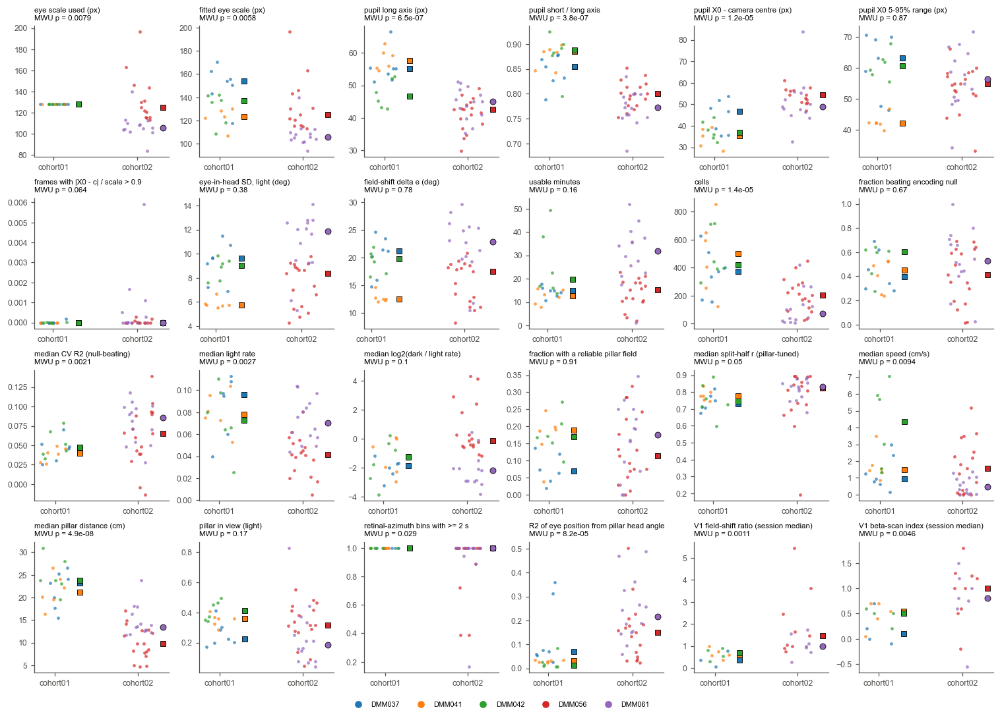

In [152]:
K_METRICS = [
    ('scale', 'eye scale used (px)'), ('scale_fit', 'fitted eye scale (px)'), ('pupil_px', 'pupil long axis (px)'),
    ('pupil_round', 'pupil short / long axis'), ('x0_off', 'pupil X0 - camera centre (px)'),
    ('x0_range', 'pupil X0 5-95% range (px)'), ('sat_frac', 'frames with |X0 - c| / scale > 0.9'),
    ('e_sd', 'eye-in-head SD, light (deg)'), ('delta_e', 'field-shift delta e (deg)'),
    ('usable_min', 'usable minutes'), ('n_cells', 'cells'), ('frac_sig', 'fraction beating encoding null'),
    ('r2_sig', 'median CV R2 (null-beating)'), ('rate_light', 'median light rate'),
    ('log2_dl', 'median log2(dark / light rate)'), ('frac_reliable', 'fraction with a reliable pillar field'),
    ('split_r', 'median split-half r (pillar-tuned)'), ('speed_med', 'median speed (cm/s)'),
    ('dist_med', 'median pillar distance (cm)'), ('in_view', 'pillar in view (light)'),
    ('rho_cover', 'retinal-azimuth bins with >= 2 s'), ('e_eta_r2', 'R2 of eye position from pillar head angle'),
    ('v1_ratio', 'V1 field-shift ratio (session median)'), ('v1_beta', 'V1 beta-scan index (session median)')]
K_METRICS = [(c, l) for c, l in K_METRICS if c in SESD and SESD[c].notna().any()]


def cohort_strip(ax, col, label):
    for i, c in enumerate(COHORTS):
        d = SESD[SESD['cohort'] == c]
        for an, da in d.groupby('animal'):
            y = da[col].to_numpy(float)
            ax.scatter(i + rng.uniform(-0.18, 0.18, len(y)), y, s=10, color=ANIMAL_COLORS.get(an, INK2), alpha=0.7, lw=0)
            if np.isfinite(y).any():
                ax.scatter([i + 0.3], [np.nanmedian(y)], s=34, color=ANIMAL_COLORS.get(an, INK2), edgecolor=INK,
                           lw=0.6, zorder=3, marker='s' if ANIMAL_NOIMU.get(an) else 'o')
    a, b = (SESD.loc[SESD['cohort'] == c, col].dropna() for c in COHORTS[:2])
    p = mannwhitneyu(a, b).pvalue if len(COHORTS) == 2 and len(a) > 2 and len(b) > 2 else np.nan
    ax.set_title('{}\nMWU p = {:.2g}'.format(label, p), loc='left', fontsize=7.5)
    ax.set_xticks(range(len(COHORTS)))
    ax.set_xticklabels([c.replace('_recordings', '') for c in COHORTS], fontsize=7)
    style(ax)
    return p


nc = 6
nr = int(np.ceil(len(K_METRICS) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(2.3 * nc, 2.4 * nr), squeeze=False)
K_P = {}
for ax, (c, l) in zip(axs.ravel(), K_METRICS):
    K_P[c] = cohort_strip(ax, c, l)
for ax in axs.ravel()[len(K_METRICS):]:
    ax.axis('off')
handles = [plt.Line2D([], [], marker='o', ls='', color=ANIMAL_COLORS[a], label=a) for a in ANIMALS]
fig.legend(handles=handles, fontsize=7, frameon=False, loc='upper center', bbox_to_anchor=(0.5, 0.0),
           ncol=len(ANIMALS))
show(fig, 'K1_cohort_metrics')

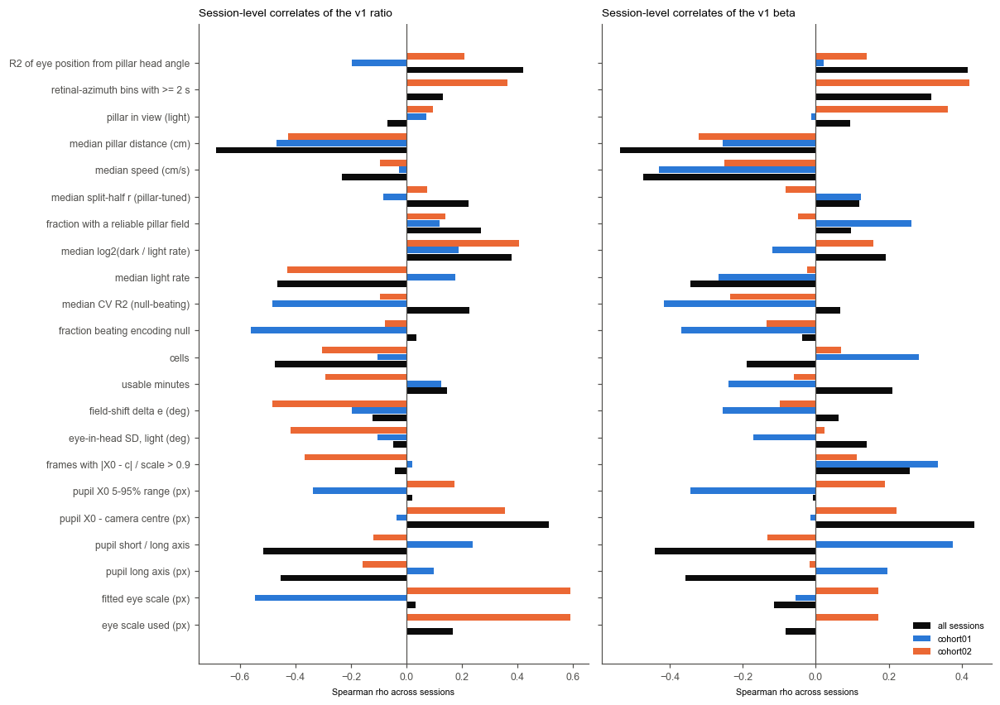

In [153]:
K_CANDS = [(c, l) for c, l in K_METRICS if c not in ('v1_ratio', 'v1_beta')]


def spearman_safe(x, y):
    ok = np.isfinite(x) & np.isfinite(y)
    return spearmanr(x[ok], y[ok]).correlation if ok.sum() >= 6 else np.nan


fig, axs = plt.subplots(1, 2, figsize=(11, 0.28 * len(K_CANDS) + 1.6), sharey=True)
for ax, out in zip(axs, ('v1_ratio', 'v1_beta')):
    y = np.arange(len(K_CANDS))
    for j, (grp, col, lab) in enumerate([(None, INK, 'all sessions')] +
                                        [(c, ['#2a78d6', '#eb6834'][k % 2], c.replace('_recordings', ''))
                                         for k, c in enumerate(COHORTS)]):
        d = SESD if grp is None else SESD[SESD['cohort'] == grp]
        r = [spearman_safe(d[c].to_numpy(float), d[out].to_numpy(float)) for c, _ in K_CANDS]
        ax.barh(y + (j - 1) * 0.26, r, height=0.24, color=col, label=lab)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([l for _, l in K_CANDS], fontsize=7)
    ax.invert_yaxis()
    ax.set_xlabel('Spearman rho across sessions')
    ax.set_title('Session-level correlates of the {}'.format(out.replace('_', ' ')), loc='left', fontsize=9)
    style(ax, grid_y=False)
axs[1].legend(fontsize=7, frameon=False, loc='lower right')
show(fig, 'K2_correlates')

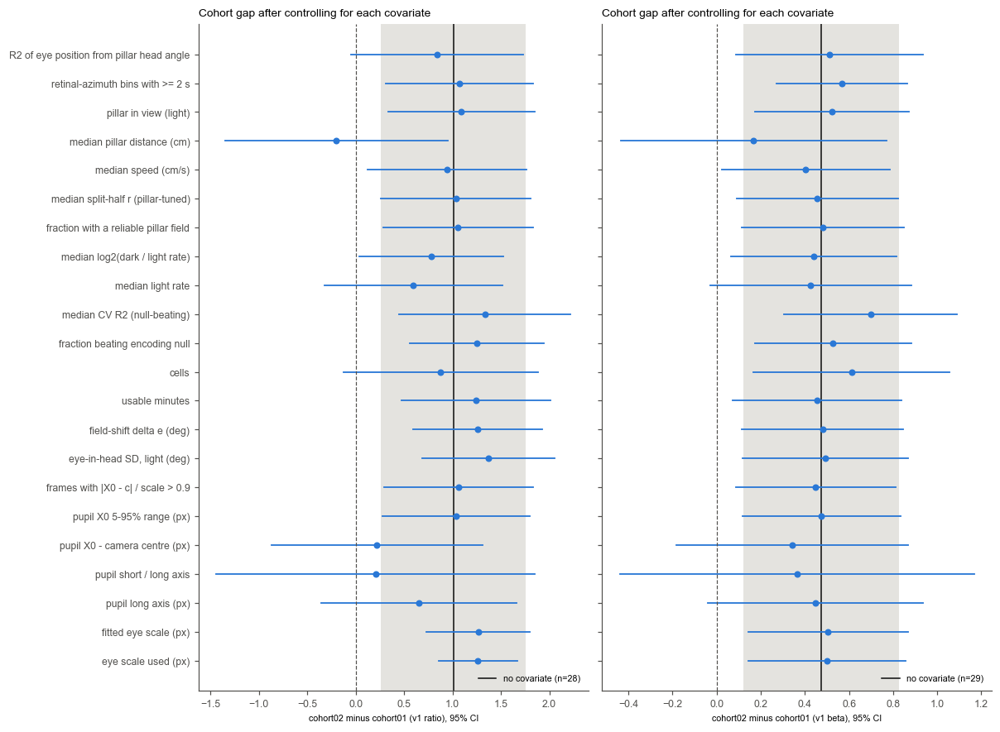

In [154]:
def cohort_gap(out, cov=None):
    d = SESD[[out, 'cohort'] + ([cov] if cov else [])].dropna()
    if len(d) < 8 or d['cohort'].nunique() < 2:
        return np.nan, np.nan, np.nan, len(d)
    X = [np.ones(len(d)), (d['cohort'] == COHORTS[1]).to_numpy(float)]
    if cov:
        z = d[cov].to_numpy(float)
        if np.std(z) == 0:
            return np.nan, np.nan, np.nan, len(d)
        X.append((z - z.mean()) / z.std())
    X = np.stack(X, 1)
    y = d[out].to_numpy(float)
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    res = y - X @ b
    s2 = res @ res / max(len(y) - X.shape[1], 1)
    se = np.sqrt(np.diag(s2 * np.linalg.pinv(X.T @ X)))
    return b[1], b[1] - 1.96 * se[1], b[1] + 1.96 * se[1], len(d)


if len(COHORTS) == 2:
    fig, axs = plt.subplots(1, 2, figsize=(11, 0.28 * len(K_CANDS) + 1.9), sharey=True)
    for ax, out in zip(axs, ('v1_ratio', 'v1_beta')):
        g0, lo0, hi0, n0 = cohort_gap(out)
        ax.axvspan(lo0, hi0, color=GRID, lw=0)
        ax.axvline(g0, color=INK, lw=1, label='no covariate (n={})'.format(n0))
        for j, (c, l) in enumerate(K_CANDS):
            g, lo, hi, n = cohort_gap(out, c)
            ax.plot([lo, hi], [j, j], color='#2a78d6', lw=1.2)
            ax.scatter([g], [j], color='#2a78d6', s=18, zorder=3)
        ax.axvline(0, color=INK2, lw=0.8, ls='--')
        ax.set_yticks(range(len(K_CANDS)))
        ax.set_yticklabels([l for _, l in K_CANDS], fontsize=7)
        ax.invert_yaxis()
        ax.set_xlabel('{} minus {} ({}), 95% CI'.format(COHORTS[1].replace('_recordings', ''),
                                                       COHORTS[0].replace('_recordings', ''), out.replace('_', ' ')))
        ax.set_title('Cohort gap after controlling for each covariate', loc='left', fontsize=9)
        ax.legend(fontsize=7, frameon=False, loc='lower right')
        style(ax, grid_y=False)
    show(fig, 'K3_gap_controlled')

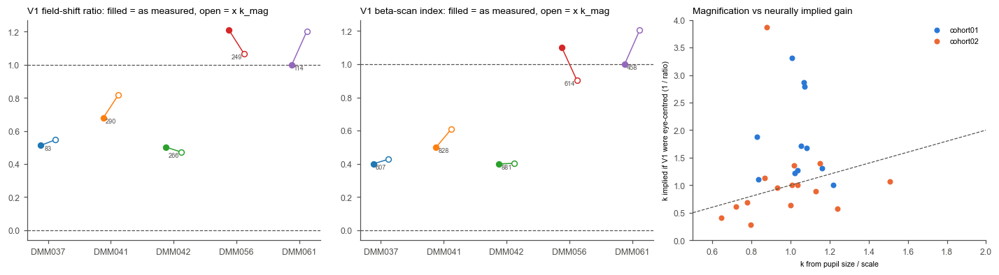

,k_mag,ratio,ratio_kcorr,beta,beta_kcorr
cohort,,,,,
cohort01_recordings,1.05,0.57,0.60,0.5,0.49
cohort02_recordings,0.92,1.12,1.11,1.0,1.03


In [155]:
SESD['k_mag'] = (SESD['pupil_px'] / SESD['scale']) / np.nanmedian(SESD['pupil_px'] / SESD['scale'])
CELLS['k_mag'] = CELLS['session'].map(SESD.set_index('session')['k_mag'])
CELLS['eye_ratio_kcorr'] = CELLS['eye_ratio'] * CELLS['k_mag']
CELLS['beta_index_kcorr'] = CELLS['beta_index'] * CELLS['k_mag']

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (raw, cor, mk, lab) in zip(axs[:2], (('eye_ratio', 'eye_ratio_kcorr', 'eye_reliable', 'field-shift ratio'),
                                            ('beta_index', 'beta_index_kcorr', 'beta_tuned', 'beta-scan index'))):
    for j, an in enumerate(ANIMALS):
        d = CELLS[(CELLS['area'] == 'V1') & (CELLS['animal'] == an) & CELLS[mk] & CELLS['k_mag'].notna()]
        if len(d) < 5:
            continue
        y0, y1 = d[raw].median(), d[cor].median()
        ax.plot([j - 0.12, j + 0.12], [y0, y1], color=ANIMAL_COLORS[an], lw=1)
        ax.scatter([j - 0.12], [y0], color=ANIMAL_COLORS[an], s=26, zorder=3)
        ax.scatter([j + 0.12], [y1], facecolor='white', edgecolor=ANIMAL_COLORS[an], s=26, zorder=3)
        ax.text(j, min(y0, y1), str(len(d)), ha='center', va='top', fontsize=6, color=INK2)
    for r in (0, 1):
        ax.axhline(r, color=INK2, lw=0.8, ls='--')
    ax.set_xticks(range(len(ANIMALS)))
    ax.set_xticklabels(ANIMALS, fontsize=7)
    ax.set_title('V1 {}: filled = as measured, open = x k_mag'.format(lab), loc='left', fontsize=9)
    style(ax)
ax = axs[2]
for c, col in zip(COHORTS, ('#2a78d6', '#eb6834')):
    d = SESD[SESD['cohort'] == c]
    ax.scatter(d['k_mag'], 1 / d['v1_ratio'].where(d['v1_ratio'] > 0.1), s=18, color=col,
               label=c.replace('_recordings', ''))
lim = [0.5, 2.0]
ax.plot(lim, lim, color=INK2, lw=0.8, ls='--')
ax.set_xlim(lim)
ax.set_ylim(0, 4)
ax.set_xlabel('k from pupil size / scale')
ax.set_ylabel('k implied if V1 were eye-centred (1 / ratio)')
ax.set_title('Magnification vs neurally implied gain', loc='left', fontsize=9)
ax.legend(fontsize=7, frameon=False)
style(ax, grid_y=False)
show(fig, 'K4_magnification')
tab = CELLS[(CELLS['area'] == 'V1') & CELLS['k_mag'].notna()].groupby('cohort').apply(lambda d: pd.Series({
    'k_mag': d.groupby('session')['k_mag'].first().median(),
    'ratio': d.loc[d['eye_reliable'], 'eye_ratio'].median(), 'ratio_kcorr': d.loc[d['eye_reliable'], 'eye_ratio_kcorr'].median(),
    'beta': d.loc[d['beta_tuned'], 'beta_index'].median(), 'beta_kcorr': d.loc[d['beta_tuned'], 'beta_index_kcorr'].median()}))
display(tab.round(2))

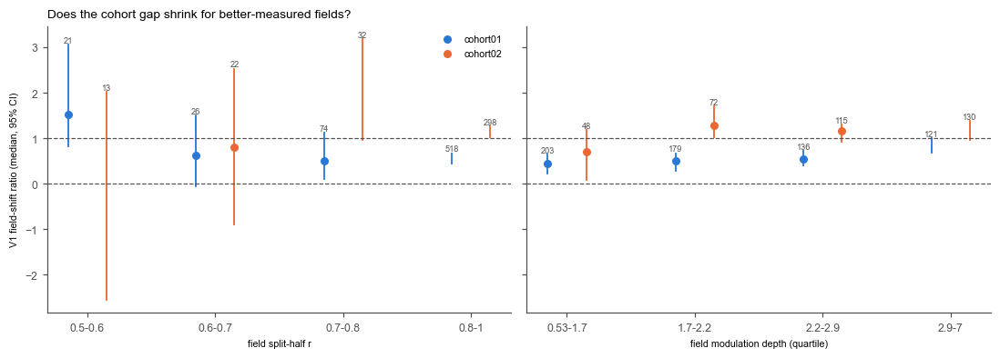

In [156]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
d = CELLS[(CELLS['area'] == 'V1') & CELLS['eye_reliable']]
for ax, (col, edges, lab) in zip(axs, (('split_r', [0.5, 0.6, 0.7, 0.8, 1.0], 'field split-half r'),
                                       ('depth', None, 'field modulation depth (quartile)'))):
    e_ = np.nanpercentile(d[col], [0, 25, 50, 75, 100]) if edges is None else np.asarray(edges)
    for k, (c, colr) in enumerate(zip(COHORTS, ('#2a78d6', '#eb6834'))):
        dc = d[d['cohort'] == c]
        for b in range(len(e_) - 1):
            y = dc.loc[(dc[col] >= e_[b]) & (dc[col] <= e_[b + 1]), 'eye_ratio'].to_numpy(float)
            if len(y) < 5:
                continue
            lo, hi = boot_ci(y)
            x = b + (k - 0.5) * 0.3
            ax.plot([x, x], [lo, hi], color=colr, lw=1.2)
            ax.scatter([x], [np.median(y)], color=colr, s=24, zorder=3,
                       label=c.replace('_recordings', '') if b == 0 else None)
            ax.text(x, hi, str(len(y)), ha='center', va='bottom', fontsize=6, color=INK2)
    ax.set_xticks(range(len(e_) - 1))
    ax.set_xticklabels(['{:.2g}-{:.2g}'.format(e_[b], e_[b + 1]) for b in range(len(e_) - 1)], fontsize=7)
    ax.set_xlabel(lab)
    for r in (0, 1):
        ax.axhline(r, color=INK2, lw=0.8, ls='--')
    style(ax)
axs[0].set_ylabel('V1 field-shift ratio (median, 95% CI)')
axs[0].legend(fontsize=7, frameon=False)
axs[0].set_title('Does the cohort gap shrink for better-measured fields?', loc='left', fontsize=9)
show(fig, 'K5_ratio_by_reliability')

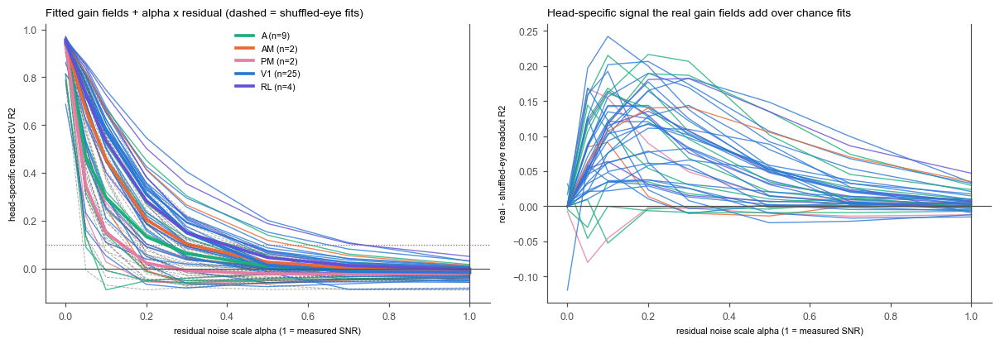

In [157]:
def alpha_star(r2, alphas, thr):
    r2 = np.asarray(r2, float)
    if not np.isfinite(r2).any() or r2[0] < thr:
        return 0.0
    above = np.flatnonzero(r2 < thr)
    if not len(above):
        return float(alphas[-1])
    j = above[0]
    a0, a1, y0, y1 = alphas[j - 1], alphas[j], r2[j - 1], r2[j]
    return float(a0 + (y0 - thr) / (y0 - y1) * (a1 - a0))

rows = []
for sess, r in SNR.items():
    al = r['alphas']
    for ai, a in enumerate(r['areas']):
        real, null = np.nanmean(r['r2_real'][ai], 1), np.nanmean(r['r2_null'][ai], 1)
        s_ = SES.set_index('session').loc[sess]
        row = {'session': sess, 'area': str(a), 'animal': s_['animal'], 'cohort': s_['cohort'],
               'n_units': int(r['n_units'][ai]), 'r2_recorded': r['r2_recorded'][ai],
               'alpha_real': alpha_star(real, al, SNR_R2_THRESH), 'alpha_null': alpha_star(null, al, SNR_R2_THRESH)}
        for li, x in enumerate(al):
            row['real_{:g}'.format(x)], row['null_{:g}'.format(x)] = real[li], null[li]
        rows.append(row)
SNRT = pd.DataFrame(rows)
if len(SNRT):
    SNRT['cells_needed'] = SNRT['n_units'] / SNRT['alpha_real'].where(SNRT['alpha_real'] > 0) ** 2
    SNRT['snr_gain_needed'] = 1 / SNRT['alpha_real'].where(SNRT['alpha_real'] > 0)
    al = np.asarray(SNR_ALPHAS, float)
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
    for _, row in SNRT.iterrows():
        real = [row['real_{:g}'.format(x)] for x in al]
        null = [row['null_{:g}'.format(x)] for x in al]
        axs[0].plot(al, real, color=acol(row['area']), lw=0.9, alpha=0.8)
        axs[0].plot(al, null, color=INK2, lw=0.6, alpha=0.5, ls='--')
        axs[1].plot(al, np.subtract(real, null), color=acol(row['area']), lw=0.9, alpha=0.8)
    for a in SNRT['area'].unique():
        d = SNRT[SNRT['area'] == a]
        axs[0].plot(al, [d['real_{:g}'.format(x)].median() for x in al], color=acol(a), lw=2.4,
                    label='{} (n={})'.format(a, len(d)))
    axs[0].axhline(SNR_R2_THRESH, color='#d03b3b', lw=0.8, ls=':')
    for ax in axs:
        ax.axvline(1, color=INK2, lw=0.8)
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_xlabel('residual noise scale alpha (1 = measured SNR)')
        style(ax)
    axs[0].set_ylabel('head-specific readout CV R2')
    axs[0].set_title('Fitted gain fields + alpha x residual (dashed = shuffled-eye fits)', loc='left', fontsize=9)
    axs[0].legend(fontsize=7, frameon=False)
    axs[1].set_ylabel('real - shuffled-eye readout R2')
    axs[1].set_title('Head-specific signal the real gain fields add over chance fits', loc='left', fontsize=9)
    show(fig, 'L1_snr_curves')
else:
    print('No session x area with >= {} tuned cells.'.format(SNR_MIN_TUNED))

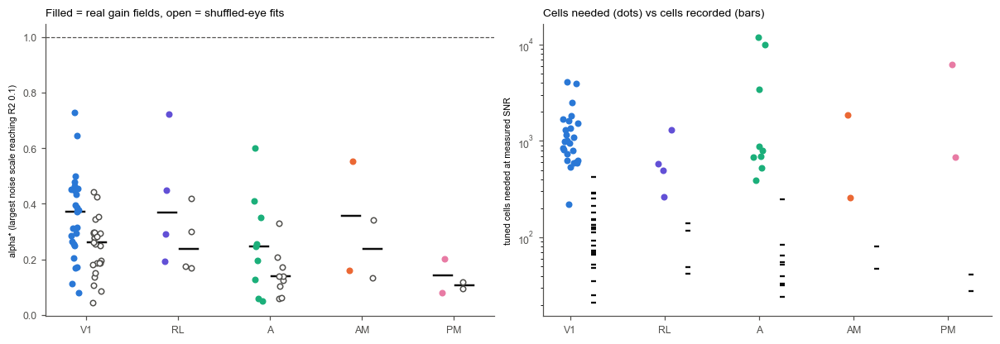

,session,area,animal,n_units,r2_recorded,real_1,null_1,alpha_real,alpha_null,snr_gain_needed,cells_needed
16,250628_DMM_DMM042_pos08,A,DMM042,247,-0.013,0.016,-0.013,0.599,0.329,1.669,688.259
26,251023_DMM_DMM056_pos09,A,DMM056,84,-0.037,-0.057,-0.081,0.350,0.170,2.860,686.913
17,250616_DMM_DMM042_pos13,A,DMM042,65,-0.000,0.006,-0.004,0.409,0.207,2.444,388.312
2,250626_DMM_DMM037_pos13,A,DMM037,55,-0.020,-0.028,-0.038,0.127,0.104,7.874,3409.854
35,251029_DMM_DMM061_pos03,A,DMM061,52,-0.010,-0.019,-0.018,0.256,0.138,3.904,792.501
0,250628_DMM_DMM037_pos08,A,DMM037,40,-0.016,-0.016,-0.017,0.058,0.058,17.297,11967.520
14,250619_DMM_DMM042_pos07,A,DMM042,33,-0.004,-0.004,-0.004,0.194,0.138,5.146,873.801
1,250630_DMM_DMM037_pos12,A,DMM037,32,-0.010,-0.010,-0.012,0.246,0.123,4.072,530.728
37,251024_DMM_DMM061_pos08,A,DMM061,24,-0.029,-0.035,-0.028,0.049,0.062,20.321,9910.483
36,251021_DMM_DMM061_pos04,AM,DMM061,80,0.009,0.011,-0.024,0.554,0.342,1.805,260.566


In [158]:
if len(SNRT):
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
    ar = [a for a in AREAS if a in set(SNRT['area'])]
    for i, a in enumerate(ar):
        d = SNRT[SNRT['area'] == a]
        for kind, col, dx in (('alpha_real', acol(a), -0.12), ('alpha_null', INK2, 0.12)):
            y = d[kind].to_numpy(float)
            axs[0].scatter(i + dx + rng.uniform(-0.05, 0.05, len(y)), y, s=18, color=col if kind == 'alpha_real' else 'white',
                           edgecolor=col, zorder=3)
            axs[0].plot([i + dx - 0.1, i + dx + 0.1], [np.median(y)] * 2, color=INK, lw=1.6)
        y = d['cells_needed'].to_numpy(float)
        axs[1].scatter(i + rng.uniform(-0.08, 0.08, len(y)), y, s=18, color=acol(a), zorder=3)
        axs[1].scatter(i + 0.25 + np.zeros(len(d)), d['n_units'], s=14, marker='_', color=INK)
    axs[0].axhline(1, color=INK2, lw=0.8, ls='--')
    axs[0].set_ylabel('alpha* (largest noise scale reaching R2 {:g})'.format(SNR_R2_THRESH))
    axs[0].set_title('Filled = real gain fields, open = shuffled-eye fits', loc='left', fontsize=9)
    axs[1].set_yscale('log')
    axs[1].set_ylabel('tuned cells needed at measured SNR')
    axs[1].set_title('Cells needed (dots) vs cells recorded (bars)', loc='left', fontsize=9)
    for ax in axs:
        ax.set_xticks(range(len(ar)))
        ax.set_xticklabels(ar)
        style(ax)
    show(fig, 'L2_alpha_star')
    cols = ['session', 'area', 'animal', 'n_units', 'r2_recorded', 'real_1', 'null_1', 'alpha_real', 'alpha_null',
            'snr_gain_needed', 'cells_needed']
    display(SNRT[[c for c in cols if c in SNRT]].sort_values(['area', 'n_units'], ascending=[True, False]).round(3))

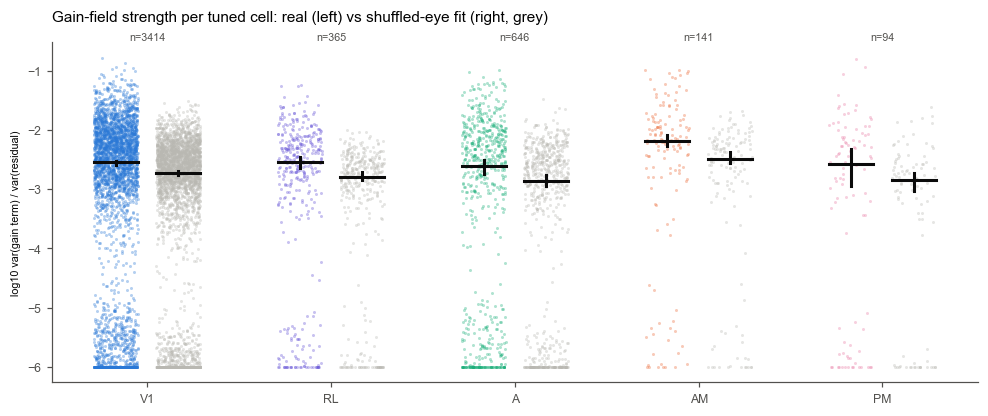

,cells,median_real,median_null
area,,,
V1,3414,0.00282,0.00188
RL,365,0.00281,0.00162
A,646,0.00245,0.00135
AM,141,0.00643,0.00325
PM,94,0.00268,0.00143


In [159]:
if SNR:
    gs = []
    for sess, r in SNR.items():
        t = GN[sess]['stored_tuned'].astype(bool)
        gs.append(pd.DataFrame({'session': sess, 'cell': np.arange(len(t)), 'tuned': t, 'gain_snr': r['gain_snr'],
                                'gain_snr_null': np.nanmedian(r['gain_snr_null'], 0) if len(r['gain_snr_null'])
                                else np.nan}))
    GS = pd.concat(gs, ignore_index=True).merge(CELLS[['session', 'cell', 'area']], on=['session', 'cell'])
    GS = GS[GS['tuned']]
    fig, ax = plt.subplots(figsize=(1.4 * max(len(AREAS), 3) + 2, 3.8))
    for i, a in enumerate(AREAS):
        d = GS[GS['area'] == a]
        for col, c, dx in (('gain_snr', acol(a), -0.17), ('gain_snr_null', '#b9b8b2', 0.17)):
            y = np.log10(np.clip(d[col].to_numpy(float), 1e-6, None))
            y = y[np.isfinite(y)]
            if not len(y):
                continue
            ax.scatter(i + dx + rng.uniform(-0.12, 0.12, len(y)), y, s=4, color=c, alpha=0.35, lw=0)
            lo, hi = boot_ci(y)
            ax.plot([i + dx] * 2, [lo, hi], color=INK, lw=2)
            ax.plot([i + dx - 0.12, i + dx + 0.12], [np.median(y)] * 2, color=INK, lw=2)
        ax.text(i, 1.0, 'n={}'.format(len(d)), transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=7, color=INK2)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel('log10 var(gain term) / var(residual)')
    ax.set_title('Gain-field strength per tuned cell: real (left) vs shuffled-eye fit (right, grey)', loc='left',
                 fontsize=10, pad=14)
    style(ax)
    show(fig, 'L3_gain_snr')
    display(GS.groupby('area').agg(cells=('cell', 'size'), median_real=('gain_snr', 'median'),
                                  median_null=('gain_snr_null', 'median')).reindex(AREAS).round(5))

In [160]:
M_NULL_SHUFFLES = 10
EYE_SLOW_S = 60.0
M_LABELS = {'drift': 'session drift', 'speed': 'running speed', 'pupil': 'pupil size', 'pitch': 'head pitch',
            'roll': 'head roll', 'eye_slow': 'slow eye (60 s)', 'all': 'all but slow eye'}


def modulators(D, use):
    nm = D['names']
    col = lambda *ks: D['X'][:, [nm.index(k) for k in ks]]
    raw = {'drift': col('drift1', 'drift2'), 'speed': col('log_speed'), 'pupil': col('pupil'),
           'pitch': col('pitch'), 'roll': col('roll')}
    win = max(int(round(EYE_SLOW_S / D['dt'])), 3)
    raw['eye_slow'] = (pd.Series(np.where(use, D['e'], np.nan)).rolling(win, center=True, min_periods=win // 4)
                       .mean().to_numpy()[:, None])
    out = {}
    for k, v in raw.items():
        v = np.asarray(v, float)
        mu, sd = np.nanmean(v[use], 0), np.nanstd(v[use], 0)
        if np.all(sd > 1e-9):
            out[k] = np.nan_to_num((v - mu) / sd)
    return out


def gain_competitors(R, n_shuf, seed=0):
    D = R['D']
    use, mz, base, gain = gain_designs(D, D['light'] & D['use'])
    idx = np.flatnonzero(use)
    if len(idx) < 3 * NULL_MIN_SHIFT:
        return None
    nm = D['names']
    vr = na._vm_basis(D['rho'])
    add = np.c_[base['ADD'], D['X'][:, [nm.index('drift{}'.format(k)) for k in range(1, 6)]]]
    prod = lambda M: np.concatenate([vr * M[:, [j]] for j in range(M.shape[1])], 1)
    mods = modulators(D, use)
    sets = dict(mods)
    other = [k for k in mods if k != 'eye_slow']
    sets['all'] = np.concatenate([mods[k] for k in other], 1)
    folds = na._folds(D, use)
    f_add = na._cv(add, D['Y'], folds)
    out = {'eye': beats(na._cv(np.c_[add, prod(mz[:, None])], D['Y'], folds), f_add),
           'modulators': np.array(sorted(sets), dtype=str)}
    rng = np.random.default_rng(seed)
    for k, M in sets.items():
        Xc = np.c_[add, prod(M)]
        fc = na._cv(Xc, D['Y'], folds)
        out['own_' + k] = beats(fc, f_add)
        out['beyond_' + k] = beats(na._cv(np.c_[Xc, prod(mz[:, None])], D['Y'], folds), fc)
        if k == 'all':
            nc = np.zeros((n_shuf, D['Y'].shape[1]), bool)
            for j in range(n_shuf):
                ms = mz.copy()
                ms[idx] = np.roll(mz[idx], int(rng.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT)))
                nc[j] = beats(na._cv(np.c_[Xc, prod(ms[:, None])], D['Y'], folds), fc)
            out['null_beyond_all'] = nc
    return out

In [161]:
GC = {}
if not (RUN_REFITS):
    print('RUN_REFITS is off -- section M is skipped.')
elif not restore('M'):
    t_all = time.time()
    for i, s in SES.iterrows():
        if s['session'] not in GN:
            continue

        def run_competitors():
            try:
                R, why = rebuild_session(s)
            except (OSError, KeyError):
                R = None
            return None if R is None else gain_competitors(R, M_NULL_SHUFFLES)

        t0 = time.time()
        r = cached(s, 'gaincomp', {'n': M_NULL_SHUFFLES, 'slow': EYE_SLOW_S, 'v': 1}, run_competitors)
        if r is not None:
            GC[s['session']] = r
        if time.time() - t0 > 1:
            print('[{}/{}] {}: {:.0f} s'.format(i + 1, len(SES), s['session'], time.time() - t0))
    print('M refits: {} sessions in {:.1f} min.'.format(len(GC), (time.time() - t_all) / 60))
    stash('M', GC=GC)

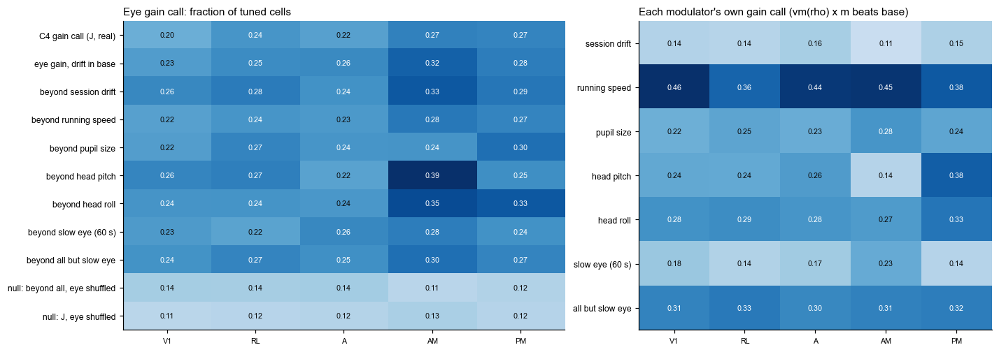

,V1,RL,A,AM,PM
tuned cells,3414,365,646,141,94


In [162]:
GCC = pd.DataFrame()
if GC:
    tabs = []
    for sess, r in GC.items():
        t = GN[sess]['tuned'].astype(bool)
        d = {'session': sess, 'cell': np.arange(len(t)), 'tuned': t, 'j_call': GN[sess]['call'].astype(float),
             'eye': r['eye'].astype(float)}
        for k in M_LABELS:
            for p in ('own_', 'beyond_'):
                d[p + k] = r[p + k].astype(float) if p + k in r else np.full(len(t), np.nan)
        tabs.append(pd.DataFrame(d))
    GCC = pd.concat(tabs, ignore_index=True).merge(CELLS[['session', 'cell', 'area', 'animal', 'cohort']],
                                                   on=['session', 'cell'])
    GCC = GCC[GCC['tuned'] & GCC['area'].isin(AREAS)]


def m_null(sel):
    num, den = np.zeros(M_NULL_SHUFFLES), 0
    for sess, d in sel.groupby('session'):
        c = d['cell'].to_numpy()
        num += GC[sess]['null_beyond_all'][:, c].sum(1)
        den += len(c)
    return num / den if den else np.full(M_NULL_SHUFFLES, np.nan)


if len(GCC):
    rows_ = [('j_call', 'C4 gain call (J, real)'), ('eye', 'eye gain, drift in base')]
    rows_ += [('beyond_' + k, 'beyond ' + M_LABELS[k]) for k in M_LABELS]
    own_ = [('own_' + k, M_LABELS[k]) for k in M_LABELS]
    H = pd.DataFrame({a: {c: GCC.loc[GCC['area'] == a, c].mean() for c, _ in rows_ + own_} for a in AREAS})
    H.loc['null_beyond_all'] = [np.nanmean(m_null(GCC[GCC['area'] == a])) for a in AREAS]
    H.loc['j_null'] = [JT.loc[a, 'null_mean'] for a in AREAS]
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.25, 1]})
    for ax, (rows, title) in zip(axs, (
            (rows_ + [('null_beyond_all', 'null: beyond all, eye shuffled'), ('j_null', 'null: J, eye shuffled')],
             'Eye gain call: fraction of tuned cells'),
            (own_, 'Each modulator\'s own gain call (vm(rho) x m beats base)'))):
        M_ = H.loc[[c for c, _ in rows]].to_numpy(float)
        ax.imshow(M_, cmap='Blues', vmin=0, vmax=max(0.3, np.nanmax(M_)), aspect='auto')
        for (i, j), v in np.ndenumerate(M_):
            ax.text(j, i, '{:.2f}'.format(v), ha='center', va='center', fontsize=7,
                    color='white' if v > 0.6 * max(0.3, np.nanmax(M_)) else INK)
        ax.set_xticks(range(len(AREAS)))
        ax.set_xticklabels(AREAS)
        ax.set_yticks(range(len(rows)))
        ax.set_yticklabels([l for _, l in rows], fontsize=8)
        ax.set_title(title, loc='left', fontsize=10)
    show(fig, 'M1_gain_vs_competitors')
    display(pd.Series({a: int((GCC['area'] == a).sum()) for a in AREAS}, name='tuned cells').to_frame().T)

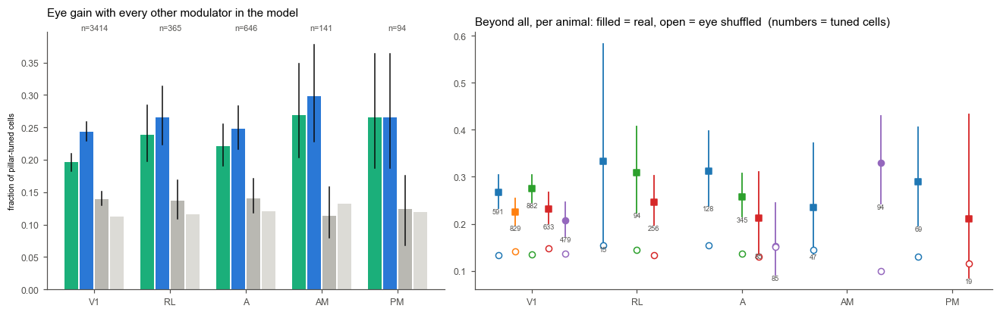

,tuned,c4_call,beyond_all,null_mean,p_shuffle,excess
V1,3414.0,0.196,0.244,0.139,0.091,0.105
RL,365.0,0.238,0.266,0.138,0.091,0.128
A,646.0,0.221,0.248,0.141,0.091,0.107
AM,141.0,0.270,0.298,0.114,0.091,0.184
PM,94.0,0.266,0.266,0.124,0.091,0.141


In [163]:
if len(GCC):
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1, 1.3]})
    ax = axs[0]
    for i, a in enumerate(AREAS):
        d = GCC[GCC['area'] == a]
        for j, (c, col, lab) in enumerate((('j_call', '#1baf7a', 'C4 gain call'), ('beyond_all', '#2a78d6', 'beyond all'))):
            k, n = int(np.nansum(d[c])), int(d[c].notna().sum())
            lo, hi = frac_ci(k, n)
            x = i + (j - 1.5) * 0.2
            ax.bar(x, k / n if n else np.nan, width=0.18, color=col, label=lab if i == 0 else None)
            ax.plot([x, x], [lo, hi], color=INK, lw=1)
        nf = m_null(d)
        x = i + 0.5 * 0.2
        ax.bar(x, np.nanmean(nf), width=0.18, color='#b9b8b2', label='beyond all, eye shuffled' if i == 0 else None)
        ax.plot([x, x], np.nanpercentile(nf, [2.5, 97.5]), color=INK, lw=1)
        x = i + 1.5 * 0.2
        ax.bar(x, JT.loc[a, 'null_mean'], width=0.18, color='#dcdbd6', label='C4 call, eye shuffled (J)' if i == 0 else None)
        ax.text(i, 1.0, 'n={}'.format(len(d)), transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=7, color=INK2)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel('fraction of pillar-tuned cells')
    ax.set_title('Eye gain with every other modulator in the model', loc='left', fontsize=10, pad=14)
    style(ax)
    ax = axs[1]
    w = 0.8 / max(len(ANIMALS), 1)
    for i, a in enumerate(AREAS):
        for j, an in enumerate(ANIMALS):
            d = GCC[(GCC['area'] == a) & (GCC['animal'] == an)]
            if len(d) < 10:
                continue
            x = i + (j - (len(ANIMALS) - 1) / 2) * w
            k = int(np.nansum(d['beyond_all']))
            lo, hi = frac_ci(k, len(d))
            ax.plot([x, x], [lo, hi], color=ANIMAL_COLORS[an], lw=1.2)
            ax.scatter([x], [k / len(d)], s=28, color=ANIMAL_COLORS[an], marker='s' if ANIMAL_NOIMU[an] else 'o',
                       zorder=3, label=an if an not in ax.get_legend_handles_labels()[1] else None)
            ax.scatter([x], [np.nanmean(m_null(d))], s=28, facecolor='white', edgecolor=ANIMAL_COLORS[an], zorder=3)
            ax.text(x, lo, str(len(d)), ha='center', va='top', fontsize=6, color=INK2)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_title('Beyond all, per animal: filled = real, open = eye shuffled  (numbers = tuned cells)', loc='left', fontsize=10)
    style(ax)
    show(fig, 'M2_beyond_all')
    MT = pd.DataFrame({a: {'tuned': int((GCC['area'] == a).sum()),
                           'c4_call': GCC.loc[GCC['area'] == a, 'j_call'].mean(),
                           'beyond_all': GCC.loc[GCC['area'] == a, 'beyond_all'].mean(),
                           'null_mean': np.nanmean(m_null(GCC[GCC['area'] == a])),
                           'p_shuffle': (1 + np.sum(m_null(GCC[GCC['area'] == a]) >= GCC.loc[GCC['area'] == a, 'beyond_all'].mean()))
                           / (1 + M_NULL_SHUFFLES)} for a in AREAS}).T
    MT['excess'] = MT['beyond_all'] - MT['null_mean']
    display(MT.round(3))

In [164]:
import hashlib

POOL_HOSTS = None
N_POOL_HOSTS = 3
POOL_SIZES = (50, 200, 800)
POOL_ALPHAS = (0.5, 1.0)
POOL_SEEDS = 2
POOL_NUISANCE = False


def load_covariates(path):
    with h5py.File(path, 'r') as f:
        D = {k: v[()] for k, v in f['covariates'].items()}
    D['names'] = L_(D['names'])
    D['dt'] = float(np.median(np.diff(D['t'])))
    D['X'] = D['X'].astype(float)
    D['use'], D['light'] = D['use'].astype(bool), D['light'].astype(bool)
    return D


def frame_mask(D):
    return D['light'] & D['use'] & np.isfinite(D['rho']) & np.isfinite(D['eta']) & np.isfinite(D['e'])


def gain_field_pred(D, G, m, nuisance=True):
    mz = (D['e'][m] - G['mod_mean']) / G['mod_sd']
    nuis = D['X'][m][:, [D['names'].index(nm) for nm in G['nuis_names']]]
    vr = na._vm_basis(D['rho'][m])
    eb = na._gauss_basis(D['e'][m], G['mod_centers'], G['mod_width'])
    Z = (np.c_[nuis, mz, vr, eb, vr * mz[:, None]] - G['x_mean']) / G['x_sd']
    if not nuisance:
        Z[:, :nuis.shape[1]] = 0
    return Z @ G['coef'] + G['y_mean']


def pool_donors():
    donors = []
    for _, s in SES.iterrows():
        g = GN.get(s['session'])
        if g is None or not len(g['nf_coef']):
            continue
        try:
            R, why = rebuild_session(s)
        except (OSError, KeyError):
            R = None
        if R is None:
            continue
        cells = np.flatnonzero(g['stored_tuned'].astype(bool) & np.isin(R['area'], AREAS))
        if not len(cells):
            continue
        D, gm = R['D'], R['gm']
        m = frame_mask(D)
        sub = lambda G: dict(G, coef=G['coef'][:, cells], y_mean=G['y_mean'][cells])
        null = dict(gm, coef=g['nf_coef'][0], x_mean=g['nf_x_mean'][0], x_sd=g['nf_x_sd'][0],
                    y_mean=g['nf_y_mean'][0])
        d = {'session': s['session'], 'area': R['area'][cells], 'cells': cells}
        for kind, G in (('real', sub(gm)), ('null', sub(null))):
            d['gm_' + kind] = G
            d['res_' + kind] = (D['Y'][m][:, cells] - gain_field_pred(D, G, m)).astype(np.float32)
        donors.append(d)
    return donors


def pool_scan(D, donors, area, sizes, alphas, n_seeds, nuisance, seed=0):
    m = frame_mask(D)
    idx = np.flatnonzero(m)
    Dm = {'t': D['t'][idx]}
    mm = np.ones(len(idx), bool)
    T = head_specific_target(D, m)[idx]
    parts = [(d, np.flatnonzero(d['area'] == area)) for d in donors]
    parts = [(d, c) for d, c in parts if len(c)]
    if not parts:
        return None
    G, RES = {}, {}
    for kind in ('real', 'null'):
        G[kind] = np.concatenate([gain_field_pred(D, dict(d['gm_' + kind], coef=d['gm_' + kind]['coef'][:, c],
                                                          y_mean=d['gm_' + kind]['y_mean'][c]), m, nuisance)
                                  for d, c in parts], 1).astype(np.float32)
        RES[kind] = [d['res_' + kind][:, c] for d, c in parts]
    n_all = G['real'].shape[1]
    sizes = sorted({min(int(k), n_all) for k in sizes} | {n_all})
    rng = np.random.default_rng(seed)
    r2 = np.full((2, len(sizes), len(alphas), n_seeds), np.nan)
    for si in range(n_seeds):
        for ki, kind in enumerate(('real', 'null')):
            nz = []
            for r in RES[kind]:
                n = r.shape[0]
                sh = rng.integers(NULL_MIN_SHIFT, n - NULL_MIN_SHIFT, r.shape[1])
                nz.append(np.take_along_axis(r, (np.arange(len(idx))[:, None] + sh[None, :]) % n, 0))
            nz = np.concatenate(nz, 1)
            for zi, N in enumerate(sizes):
                sel = rng.choice(n_all, N, replace=False)
                for ai, al in enumerate(alphas):
                    r2[ki, zi, ai, si] = max(readout_r2(Dm, G[kind][:, sel] + al * nz[:, sel], T, mm), -1.0)
    return {'sizes': np.array(sizes), 'alphas': np.asarray(alphas, float), 'r2': r2, 'n_sessions': len(parts)}

In [165]:
POOL = {}
if not (RUN_REFITS and GN):
    print('RUN_REFITS is off (or J has no sessions) -- section N is skipped.')
else:
    if POOL_HOSTS:
        HOSTS = SES[SES['session'].isin(POOL_HOSTS)]
    else:
        HOSTS = (SES[SES['session'].isin(list(GN))].assign(light_min=lambda d: d['usable_min'] * d['light_frac'])
                 .sort_values('light_min', ascending=False).drop_duplicates('animal').head(N_POOL_HOSTS))
    print('Hosts: {}'.format(', '.join(HOSTS['session'])))
    path_of = SES.set_index('session')['path']
    POOL_SIG = hashlib.md5(json.dumps(sorted((k, os.path.getmtime(path_of[k])) for k in GN)).encode()).hexdigest()
    pool_box = {}

    def donors_once():
        if 'd' not in pool_box:
            t0 = time.time()
            pool_box['d'] = pool_donors()
            print('Donors: {} sessions in {:.0f} s.'.format(len(pool_box['d']), time.time() - t0))
        return pool_box['d']

    if not restore('N'):
        t_all = time.time()
        for _, h in HOSTS.iterrows():
            D_h = load_covariates(h['path'])
            for a in AREAS:
                t0 = time.time()
                r = cached(h, 'pool_' + a, {'sizes': list(POOL_SIZES), 'alphas': list(POOL_ALPHAS), 'seeds': POOL_SEEDS,
                                            'nuis': POOL_NUISANCE, 'donors': POOL_SIG, 'v': 1},
                           lambda: pool_scan(D_h, donors_once(), a, POOL_SIZES, POOL_ALPHAS, POOL_SEEDS, POOL_NUISANCE))
                if r is not None:
                    POOL[(h['session'], a)] = r
                if time.time() - t0 > 5:
                    print('  {} x {}: {:.0f} s'.format(h['session'], a, time.time() - t0))
        print('Pooled readouts: {} host x area in {:.1f} min.'.format(len(POOL), (time.time() - t_all) / 60))
        stash('N', POOL=POOL)

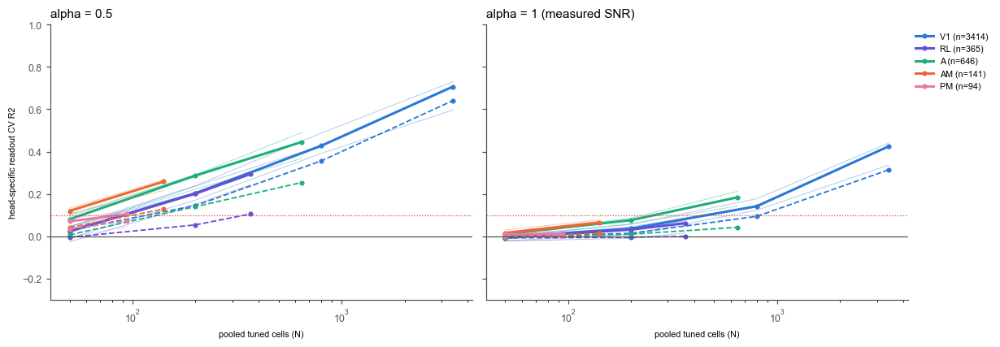

,tuned_cells,real_r2_all,null_r2_all,real_minus_null,smallest_N_detected
V1,3414.0,0.425,0.314,0.111,800.0
RL,365.0,0.062,0.000,0.062,NaN
A,646.0,0.184,0.042,0.142,646.0
AM,141.0,0.065,0.013,0.052,NaN
PM,94.0,0.013,0.004,0.009,NaN


In [166]:
if POOL:
    rows = []
    for (host, a), r in POOL.items():
        for ki, kind in enumerate(('real', 'null')):
            for zi, N in enumerate(r['sizes']):
                for ai, al in enumerate(r['alphas']):
                    for si in range(r['r2'].shape[3]):
                        rows.append({'host': host, 'area': a, 'kind': kind, 'N': int(N), 'alpha': float(al),
                                     'seed': si, 'r2': r['r2'][ki, zi, ai, si], 'n_all': int(r['sizes'][-1])})
    POOLT = pd.DataFrame(rows)
    al_ = sorted(POOLT['alpha'].unique())
    fig, axs = plt.subplots(1, len(al_), figsize=(5.6 * len(al_), 3.9), squeeze=False, sharey=True)
    for ax, al in zip(axs[0], al_):
        d = POOLT[POOLT['alpha'] == al]
        for a in AREAS:
            da = d[d['area'] == a]
            if not len(da):
                continue
            for kind, ls in (('real', '-'), ('null', '--')):
                med = da[da['kind'] == kind].groupby('N')['r2'].median()
                ax.plot(med.index, med.to_numpy(), ls=ls, color=acol(a), lw=2 if kind == 'real' else 1.2, marker='o', ms=3,
                        label='{} (n={})'.format(a, int(da['n_all'].iloc[0])) if kind == 'real' else None)
                if kind == 'real':
                    for host, dh in da[da['kind'] == 'real'].groupby('host'):
                        mh = dh.groupby('N')['r2'].median()
                        ax.plot(mh.index, mh.to_numpy(), color=acol(a), lw=0.6, alpha=0.4)
        ax.axhline(SNR_R2_THRESH, color='#d03b3b', lw=0.8, ls=':')
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_xscale('log')
        ax.set_ylim(-0.3, 1.0)
        ax.set_xlabel('pooled tuned cells (N)')
        ax.set_title('alpha = {:g}{}'.format(al, ' (measured SNR)' if al == 1 else ''), loc='left', fontsize=10)
        style(ax)
    axs[0][0].set_ylabel('head-specific readout CV R2')
    axs[0][-1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'N1_pooled_readout')
    d = POOLT[(POOLT['alpha'] == 1.0)]
    tab = {}
    for a in AREAS:
        da = d[d['area'] == a]
        if not len(da):
            continue
        top = da[da['N'] == da['n_all']]
        real_med = da[da['kind'] == 'real'].groupby('N')['r2'].median()
        hit = real_med[real_med >= SNR_R2_THRESH]
        tab[a] = {'tuned_cells': int(da['n_all'].iloc[0]),
                  'real_r2_all': top.loc[top['kind'] == 'real', 'r2'].median(),
                  'null_r2_all': top.loc[top['kind'] == 'null', 'r2'].median(),
                  'real_minus_null': top.loc[top['kind'] == 'real', 'r2'].median() - top.loc[top['kind'] == 'null', 'r2'].median(),
                  'smallest_N_detected': int(hit.index.min()) if len(hit) else np.nan}
    display(pd.DataFrame(tab).T.round(3))

In [167]:
import contextlib
import io

DARK_SHUFFLES = 20


def matched_blocks(D, m, n_target, seed=0):
    blk = np.floor((D['t'] - D['t'][0]) / na.BLOCK_S).astype(int)
    order = np.random.default_rng(seed).permutation(np.unique(blk[m]))
    keep, n = np.zeros(len(m), bool), 0
    for b in order:
        if n >= n_target:
            break
        sel = m & (blk == b)
        keep |= sel
        n += sel.sum()
    return keep


def encoding_by_condition(R, n_shuf):
    D = R['D']
    groups = {g: np.asarray(D['group_' + g], int) for g in list(na.GROUPS) + ['base']}
    light, dark = D['use'] & D['light'], D['use'] & ~D['light']
    conds = [('light', light), ('dark', dark), ('light_matched', matched_blocks(D, light, dark.sum()))]
    out = {}
    for cond, m in conds:
        if m.sum() < 3 * NULL_MIN_SHIFT:
            continue
        with contextlib.redirect_stdout(io.StringIO()):
            enc = na.encoding_models(dict(D, use=m, groups=groups), n_shuffles=n_shuf)
        for k in ('sig', 'r2_full', 'r2_base', 'unique', 'alone', 'unique_folds_pos'):
            out['{}_{}'.format(cond, k)] = np.asarray(enc[k])
        out[cond + '_n_frames'] = np.array(int(m.sum()))
    return out or None


NOEYE_GROUPS = ('head', 'speed', 'ego_pillar', 'allo', 'state')


def encoding_noeye(R, n_shuf):
    D = R['D']
    groups = {g: np.asarray(D['group_' + g], int) if g in NOEYE_GROUPS else np.zeros(0, int) for g in na.GROUPS}
    groups['base'] = np.asarray(D['group_base'], int)
    cols = np.concatenate([groups[g] for g in NOEYE_GROUPS] + [groups['base']])
    ok = np.all(np.isfinite(D['X'][:, cols]), 1)
    dark = ok & ~D['light']
    out = {}
    for cond, m in (('dark_noeye', dark), ('light_noeye_matched', matched_blocks(D, ok & D['light'], dark.sum()))):
        if m.sum() < 3 * NULL_MIN_SHIFT:
            continue
        with contextlib.redirect_stdout(io.StringIO()):
            enc = na.encoding_models(dict(D, use=m, groups=groups), n_shuffles=n_shuf)
        for k in ('sig', 'r2_full', 'r2_base', 'unique', 'alone', 'unique_folds_pos'):
            out['{}_{}'.format(cond, k)] = np.asarray(enc[k])
        out[cond + '_n_frames'] = np.array(int(m.sum()))
    return out or None

In [168]:
ENC_LD = {}
if not (RUN_REFITS):
    print('RUN_REFITS is off -- section O is skipped.')
elif not restore('O'):
    t_all = time.time()
    for i, s in SES.iterrows():
        box = {}

        def session():
            if 'R' not in box:
                try:
                    box['R'], _ = rebuild_session(s)
                except (OSError, KeyError):
                    box['R'] = None
            return box['R']

        t0 = time.time()
        r = cached(s, 'enc_ld', {'n': DARK_SHUFFLES, 'v': 1},
                   lambda: None if session() is None else encoding_by_condition(session(), DARK_SHUFFLES))
        r2 = cached(s, 'enc_noeye', {'n': DARK_SHUFFLES, 'groups': list(NOEYE_GROUPS), 'v': 1},
                    lambda: None if session() is None else encoding_noeye(session(), DARK_SHUFFLES))
        if r is not None or r2 is not None:
            ENC_LD[s['session']] = {**(r or {}), **(r2 or {})}
        if time.time() - t0 > 1:
            print('[{}/{}] {}: {:.0f} s'.format(i + 1, len(SES), s['session'], time.time() - t0))
    print('O refits: {} sessions in {:.1f} min.'.format(len(ENC_LD), (time.time() - t_all) / 60))
    stash('O', ENC_LD=ENC_LD)

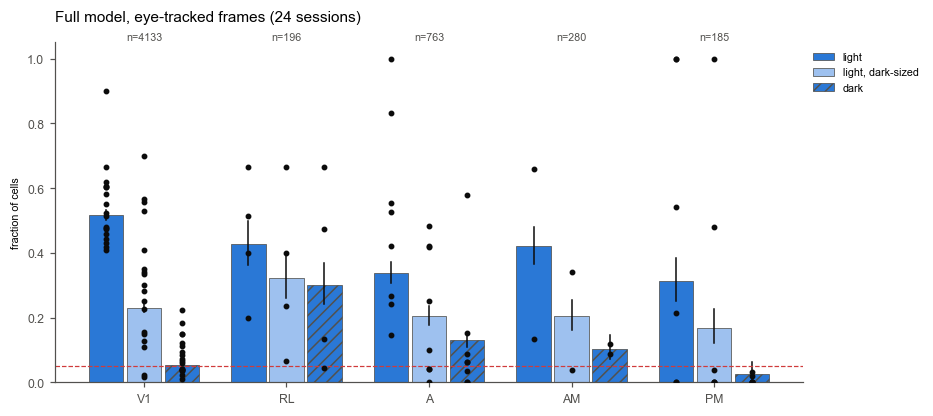

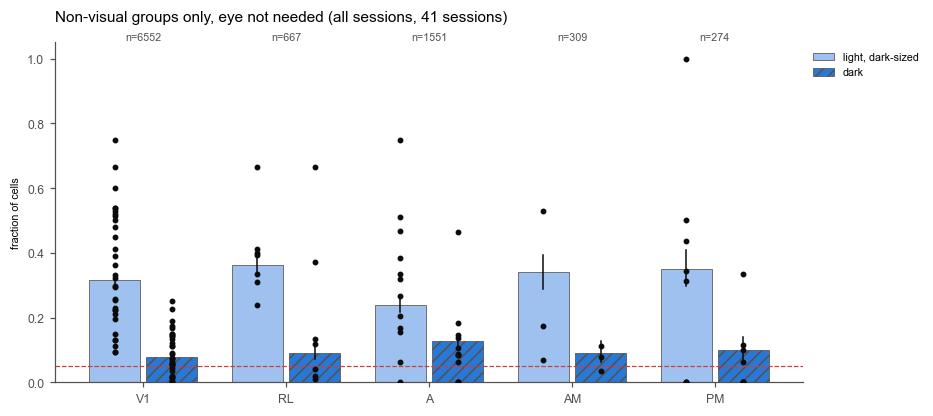

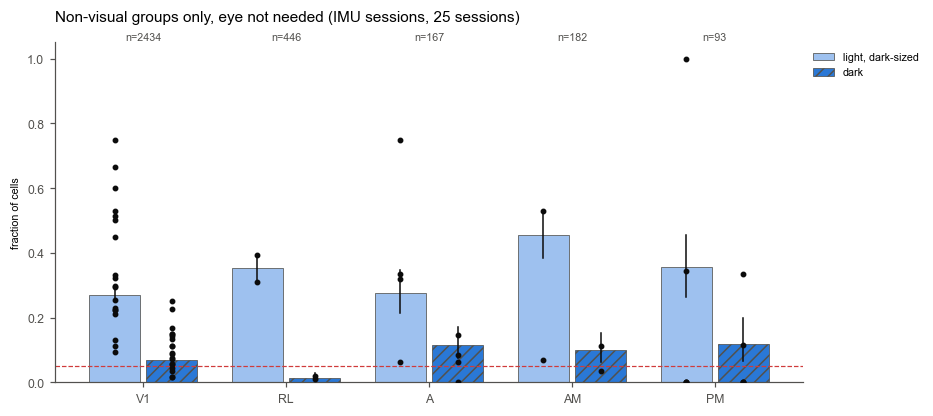

In [169]:
O_CONDS = ('light', 'light_matched', 'dark', 'light_noeye_matched', 'dark_noeye')
EO = pd.DataFrame()
if ENC_LD:
    tabs = []
    for sess, r in ENC_LD.items():
        C = len(next(v for k, v in r.items() if k.endswith('_sig')))
        d = {'session': sess, 'cell': np.arange(C)}
        for cond in O_CONDS:
            ok = cond + '_sig' in r
            d['sig_' + cond] = r[cond + '_sig'].astype(bool) if ok else np.zeros(C, bool)
            d['has_' + cond] = np.full(C, ok)
            for gi, g in enumerate(GROUPS):
                d['alone_{}_{}'.format(cond, g)] = r[cond + '_alone'][:, gi] if ok else np.full(C, np.nan)
                d['ufrac_{}_{}'.format(cond, g)] = ((r[cond + '_unique_folds_pos'][:, gi] >= 4) &
                                                    (r[cond + '_unique'][:, gi] > 0)) if ok else np.zeros(C, bool)
        tabs.append(pd.DataFrame(d))
    EO = pd.concat(tabs, ignore_index=True).merge(CELLS[['session', 'cell', 'area', 'animal', 'cohort', 'no_imu']],
                                                  on=['session', 'cell'])
    EO = EO[EO['area'].isin(AREAS)]
    EO_EYE = EO[EO[['has_' + c for c in ('light', 'light_matched', 'dark')]].all(1)]
    EO_NOEYE = EO[EO[['has_' + c for c in ('light_noeye_matched', 'dark_noeye')]].all(1)]
    frac_by_area(['sig_light', 'sig_light_matched', 'sig_dark'], ['light', 'light, dark-sized', 'dark'],
                 ['#2a78d6', '#9ec1ef', '#2a78d6'], hatch=[None, None, '///'], chance=0.05, df=EO_EYE,
                 title='Full model, eye-tracked frames ({} sessions)'.format(EO_EYE['session'].nunique()),
                 name='O1a_sig_eye_tracked')
    for imu_only in (False, True):
        d = EO_NOEYE[~EO_NOEYE['no_imu']] if imu_only else EO_NOEYE
        frac_by_area(['sig_light_noeye_matched', 'sig_dark_noeye'], ['light, dark-sized', 'dark'],
                     ['#9ec1ef', '#2a78d6'], hatch=[None, '///'], chance=0.05, df=d,
                     title='Non-visual groups only, eye not needed ({}, {} sessions)'.format(
                         'IMU sessions' if imu_only else 'all sessions', d['session'].nunique()),
                     name='O1b_sig_noeye' + ('_imu' if imu_only else ''))

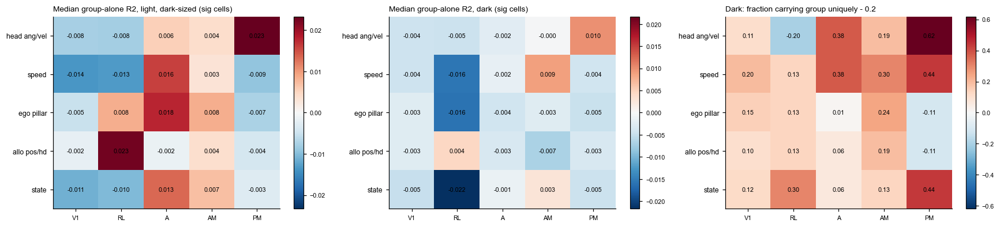

,cells,sessions,animals,frac_light,frac_dark,dark_over_light,imu_cells,imu_sessions,imu_animals,imu_frac_light,imu_frac_dark,imu_dark_over_light
V1,6552.0,31.0,5.0,0.316,0.077,0.243,2434.0,19.0,2.0,0.270,0.067,0.249
RL,667.0,7.0,3.0,0.363,0.090,0.248,446.0,2.0,1.0,0.352,0.013,0.038
A,1551.0,12.0,5.0,0.239,0.129,0.541,167.0,4.0,2.0,0.275,0.114,0.413
AM,309.0,3.0,2.0,0.340,0.091,0.267,182.0,2.0,1.0,0.456,0.099,0.217
PM,274.0,8.0,4.0,0.350,0.099,0.281,93.0,5.0,2.0,0.355,0.118,0.333


In [170]:
def heat_df(M, rows, title, fmt='{:.3f}', cmap='Blues', center=False, ax=None):
    v = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1
    img = ax.imshow(M, cmap=cmap, vmin=-v if center else 0, vmax=v, aspect='auto')
    for (i, j), x in np.ndenumerate(M):
        if np.isfinite(x):
            ax.text(j, i, fmt.format(x), ha='center', va='center', fontsize=7)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows, fontsize=8)
    ax.set_title(title, loc='left', fontsize=9)
    return img


if len(EO_NOEYE):
    d = EO_NOEYE[~EO_NOEYE['no_imu']]
    labels = [GROUP_LABELS.get(g, g) for g in NOEYE_GROUPS]
    fig, axs = plt.subplots(1, 3, figsize=(16, 3.6))
    for ax, cond in zip(axs, ('light_noeye_matched', 'dark_noeye', None)):
        if cond is None:
            M = np.array([[d.loc[(d['area'] == a) & d['sig_dark_noeye'], 'ufrac_dark_noeye_' + g].mean() - 0.2
                           for a in AREAS] for g in NOEYE_GROUPS])
            img = heat_df(M, labels, 'Dark: fraction carrying group uniquely - 0.2', '{:.2f}', 'RdBu_r', True, ax)
        else:
            M = np.array([[d.loc[(d['area'] == a) & d['sig_' + cond], 'alone_{}_{}'.format(cond, g)].median()
                           for a in AREAS] for g in NOEYE_GROUPS])
            img = heat_df(M, labels, 'Median group-alone R2, {} (sig cells)'.format(
                'light, dark-sized' if 'light' in cond else 'dark'), cmap='RdBu_r', center=True, ax=ax)
        plt.colorbar(img, ax=ax)
    show(fig, 'O2_dark_groups_imu')
    rows = {}
    for imu_only in (False, True):
        dd = EO_NOEYE[~EO_NOEYE['no_imu']] if imu_only else EO_NOEYE
        tag = 'imu_' if imu_only else ''
        for a in AREAS:
            x = dd[dd['area'] == a]
            r = rows.setdefault(a, {})
            r[tag + 'cells'], r[tag + 'sessions'], r[tag + 'animals'] = len(x), x['session'].nunique(), x['animal'].nunique()
            r[tag + 'frac_light'], r[tag + 'frac_dark'] = x['sig_light_noeye_matched'].mean(), x['sig_dark_noeye'].mean()
            r[tag + 'dark_over_light'] = r[tag + 'frac_dark'] / r[tag + 'frac_light'] if r[tag + 'frac_light'] > 0 else np.nan
    display(pd.DataFrame(rows).T.round(3))

In [171]:
BODY_MIN_FRAMES = 1000
BODY_NULL_SHUFFLES = 10
BODY_NULL_FIELDS = 2
BODY_HOSTS = 3
BODY_SIZES = (50, 200, 800)
BODY_ALPHAS = (0.5, 1.0)
BODY_SEEDS = 2


def body_mask(D):
    return D['light'] & D['use'] & np.isfinite(D['eta']) & np.isfinite(D['hb'])


def body_designs(D, m, norm=None):
    nm = np.array(D['names'])
    cols = np.r_[np.flatnonzero(np.char.startswith(nm, 'hd_vm')), [D['names'].index(k) for k in ('speed', 'log_dist')]]
    nuis = D['X'][:, cols.astype(int)]
    hb = D['hb']
    if norm is None:
        sd = np.nanstd(hb[m])
        norm = {'mod_mean': np.nanmean(hb[m]), 'mod_sd': sd, 'mod_centers': np.nanpercentile(hb[m], [10, 37, 63, 90]),
                'mod_width': max(sd / 1.5, 1.0), 'n_nuis': nuis.shape[1]}
    hz = (hb - norm['mod_mean']) / norm['mod_sd']
    hbb = na._gauss_basis(hb, norm['mod_centers'], norm['mod_width'])
    vh = na._vm_basis(D['eta'])
    base = {'NUIS': np.c_[nuis, hz], 'FIELD': np.c_[nuis, hz, vh], 'ADD': np.c_[nuis, hz, vh, hbb]}
    return hz, base, (lambda z: np.c_[base['ADD'], vh * z[:, None]]), norm


def body_gain(R, n_shuf, n_fields, seed=0):
    D = R['D']
    m = body_mask(D)
    idx = np.flatnonzero(m)
    if len(idx) < BODY_MIN_FRAMES:
        return None
    hz, base, gain, norm = body_designs(D, m)
    folds = na._folds(D, m)
    fits = {k: na._cv(X, D['Y'], folds) for k, X in base.items()}
    fits['GAIN'] = na._cv(gain(hz), D['Y'], folds)
    tuned = beats(fits['FIELD'], fits['NUIS'])
    d_real = fits['GAIN']['r2'] - fits['ADD']['r2']
    rng = np.random.default_rng(seed)
    lo = min(NULL_MIN_SHIFT, len(idx) // 4)
    C = D['Y'].shape[1]
    null_call, d_null, nf = np.zeros((n_shuf, C), bool), np.full((n_shuf, C), np.nan), []
    for k in range(n_shuf):
        hs = hz.copy()
        hs[idx] = np.roll(hz[idx], int(rng.integers(lo, len(idx) - lo)))
        fn = na._cv(gain(hs), D['Y'], folds)
        null_call[k] = tuned & beats(fn, fits['ADD'])
        d_null[k] = fn['r2'] - fits['ADD']['r2']
        if k < n_fields:
            nf.append(full_fit(gain(hs), D['Y'], m, fn['lam']))
    real = full_fit(gain(hz), D['Y'], m, fits['GAIN']['lam'])
    vh = na._vm_basis(D['eta'])
    mods = D['X'][:, [D['names'].index(k) for k in ('yaw_vel', 'log_speed')]]
    mods = np.nan_to_num((mods - np.nanmean(mods[m], 0)) / np.nanstd(mods[m], 0))
    addc = np.c_[base['ADD'], vh * mods[:, [0]], vh * mods[:, [1]]]
    fc = na._cv(addc, D['Y'], folds)
    beyond = tuned & beats(na._cv(np.c_[addc, vh * hz[:, None]], D['Y'], folds), fc)
    null_beyond = np.zeros((n_shuf, C), bool)
    rng2 = np.random.default_rng(seed + 1)
    for k in range(n_shuf):
        hs = hz.copy()
        hs[idx] = np.roll(hz[idx], int(rng2.integers(lo, len(idx) - lo)))
        null_beyond[k] = tuned & beats(na._cv(np.c_[addc, vh * hs[:, None]], D['Y'], folds), fc)
    out = {'tuned': tuned, 'call': tuned & beats(fits['GAIN'], fits['ADD']), 'd_real': d_real,
           'null_call': null_call, 'p': (1 + np.sum(d_null >= d_real[None], 0)) / (1 + n_shuf),
           'turn_gain': tuned & beats(fc, fits['ADD']), 'beyond_turn': beyond, 'null_beyond_turn': null_beyond,
           'n_frames': np.array(len(idx)), 'hb_sd': np.array(norm['mod_sd'])}
    for k, v in norm.items():
        out['norm_' + k] = np.asarray(v)
    for k in ('coef', 'x_mean', 'x_sd', 'y_mean'):
        out['fit_' + k] = real[k]
        out['nf_' + k] = np.stack([f[k] for f in nf])
    return out


def body_norm(r):
    return {k[5:]: (r[k].item() if r[k].ndim == 0 else r[k]) for k in r if k.startswith('norm_')}


def body_pred(D, fit, norm, m, nuisance=False):
    hz, base, gain, _ = body_designs(D, m, norm)
    Z = (gain(hz)[m] - fit['x_mean']) / fit['x_sd']
    if not nuisance:
        Z[:, :int(norm['n_nuis'])] = 0
    return Z @ fit['coef'] + fit['y_mean']


def body_target(D, m):
    hz = (D['hb'] - np.nanmean(D['hb'][m])) / np.nanstd(D['hb'][m])
    H = na._vm_basis(D['eta'] + D['hb'])
    A = np.c_[np.ones(len(hz)), na._vm_basis(D['eta']), hz]
    coef = np.linalg.lstsq(A[m], H[m], rcond=None)[0]
    return np.nan_to_num(H - A @ coef)


def body_donors():
    donors = []
    for _, s in SES.iterrows():
        r = BODY.get(s['session'])
        if r is None:
            continue
        try:
            R, why = rebuild_session(s)
        except (OSError, KeyError):
            R = None
        if R is None:
            continue
        cells = np.flatnonzero(r['tuned'].astype(bool) & np.isin(R['area'], AREAS))
        if not len(cells):
            continue
        D, m, norm = R['D'], body_mask(R['D']), body_norm(r)
        d = {'session': s['session'], 'area': R['area'][cells], 'norm': norm}
        for kind, pre in (('real', 'fit_'), ('null', 'nf_')):
            fit = {k: r[pre + k][0] if kind == 'null' else r[pre + k] for k in ('coef', 'x_mean', 'x_sd', 'y_mean')}
            fit = dict(fit, coef=fit['coef'][:, cells], y_mean=fit['y_mean'][cells])
            d['fit_' + kind] = fit
            d['res_' + kind] = (D['Y'][m][:, cells] - body_pred(D, fit, norm, m, True)).astype(np.float32)
        donors.append(d)
    return donors


def body_pool_scan(D, donors, area, sizes, alphas, n_seeds, seed=0):
    m = body_mask(D)
    idx = np.flatnonzero(m)
    Dm, mm = {'t': D['t'][idx]}, np.ones(len(idx), bool)
    T = body_target(D, m)[idx]
    parts = [(d, np.flatnonzero(d['area'] == area)) for d in donors]
    parts = [(d, c) for d, c in parts if len(c)]
    if not parts:
        return None
    G, RES = {}, {}
    for kind in ('real', 'null'):
        G[kind] = np.concatenate([body_pred(D, dict(d['fit_' + kind], coef=d['fit_' + kind]['coef'][:, c],
                                                     y_mean=d['fit_' + kind]['y_mean'][c]), d['norm'], m)
                                  for d, c in parts], 1).astype(np.float32)
        RES[kind] = [d['res_' + kind][:, c] for d, c in parts]
    n_all = G['real'].shape[1]
    sizes = sorted({min(int(k), n_all) for k in sizes} | {n_all})
    rng = np.random.default_rng(seed)
    r2 = np.full((2, len(sizes), len(alphas), n_seeds), np.nan)
    for si in range(n_seeds):
        for ki, kind in enumerate(('real', 'null')):
            nz = []
            for r in RES[kind]:
                n = r.shape[0]
                lo = min(NULL_MIN_SHIFT, n // 4)
                sh = rng.integers(lo, n - lo, r.shape[1])
                nz.append(np.take_along_axis(r, (np.arange(len(idx))[:, None] + sh[None, :]) % n, 0))
            nz = np.concatenate(nz, 1)
            for zi, N in enumerate(sizes):
                sel = rng.choice(n_all, N, replace=False)
                for ai, al in enumerate(alphas):
                    r2[ki, zi, ai, si] = max(readout_r2(Dm, G[kind][:, sel] + al * nz[:, sel], T, mm), -1.0)
    return {'sizes': np.array(sizes), 'alphas': np.asarray(alphas, float), 'r2': r2, 'n_sessions': len(parts)}

In [172]:
BODY, BODY_POOL = {}, {}
if not (RUN_REFITS):
    print('RUN_REFITS is off -- section P is skipped.')
elif not restore('P'):
    t_all = time.time()
    for i, s in SES.iterrows():

        def run_body():
            try:
                R, why = rebuild_session(s)
            except (OSError, KeyError):
                R = None
            return None if R is None else body_gain(R, BODY_NULL_SHUFFLES, BODY_NULL_FIELDS)

        r = cached(s, 'bodygain', {'n': BODY_NULL_SHUFFLES, 'nf': BODY_NULL_FIELDS, 'min': BODY_MIN_FRAMES, 'v': 2},
                   run_body)
        if r is not None:
            BODY[s['session']] = r
    print('P1: {} sessions with >= {} light locomotion frames ({:.1f} min).'.format(
        len(BODY), BODY_MIN_FRAMES, (time.time() - t_all) / 60))
    if BODY:
        BODY_HOSTS_T = (SES[SES['session'].isin(list(BODY))]
                        .assign(n_loco=lambda d: d['session'].map(lambda k: int(BODY[k]['n_frames'])))
                        .sort_values('n_loco', ascending=False).drop_duplicates('animal').head(BODY_HOSTS))
        print('P2 hosts: {}'.format(', '.join('{} ({} frames)'.format(a, b) for a, b in
                                              zip(BODY_HOSTS_T['session'], BODY_HOSTS_T['n_loco']))))
        path_of = SES.set_index('session')['path']
        BODY_SIG = hashlib.md5(json.dumps(sorted((k, os.path.getmtime(path_of[k])) for k in BODY)).encode()).hexdigest()
        bbox = {}

        def body_donors_once():
            if 'd' not in bbox:
                bbox['d'] = body_donors()
            return bbox['d']

        for _, h in BODY_HOSTS_T.iterrows():
            D_h = load_covariates(h['path'])
            for a in AREAS:
                r = cached(h, 'bodypool_' + a, {'sizes': list(BODY_SIZES), 'alphas': list(BODY_ALPHAS),
                                                'seeds': BODY_SEEDS, 'donors': BODY_SIG, 'v': 1},
                           lambda: body_pool_scan(D_h, body_donors_once(), a, BODY_SIZES, BODY_ALPHAS, BODY_SEEDS))
                if r is not None:
                    BODY_POOL[(h['session'], a)] = r
        print('P2: {} host x area in {:.1f} min total.'.format(len(BODY_POOL), (time.time() - t_all) / 60))
    stash('P', BODY=BODY, BODY_POOL=BODY_POOL)

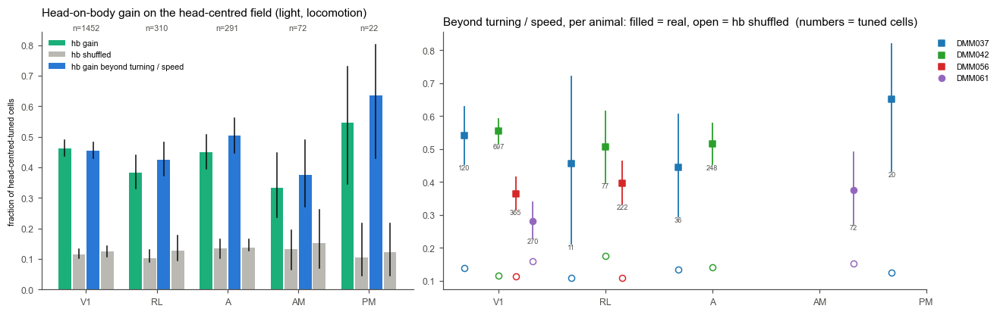

,sessions,tuned,real_frac,null_mean,frac_at_p_floor,turn_gain_frac,beyond_turn_frac,beyond_turn_null,excess
V1,18.0,1452.0,0.463,0.115,0.435,0.226,0.455,0.125,0.348
RL,6.0,310.0,0.384,0.103,0.410,0.281,0.426,0.126,0.281
A,6.0,291.0,0.450,0.135,0.419,0.268,0.505,0.138,0.315
AM,1.0,72.0,0.333,0.132,0.333,0.208,0.375,0.153,0.201
PM,3.0,22.0,0.545,0.105,0.409,0.227,0.636,0.123,0.441


In [173]:
BC = pd.DataFrame()
if BODY:
    BC = pd.concat([pd.DataFrame({'session': k, 'cell': np.arange(len(r['tuned'])), 'tuned': r['tuned'].astype(bool),
                                  'call': r['call'].astype(bool), 'p': r['p'], 'turn_gain': r['turn_gain'].astype(bool),
                                  'beyond_turn': r['beyond_turn'].astype(bool)}) for k, r in BODY.items()],
                   ignore_index=True).merge(CELLS[['session', 'cell', 'area', 'animal', 'no_imu']], on=['session', 'cell'])
    BC = BC[BC['tuned'] & BC['area'].isin(AREAS)]


def body_null(sel, key='null_call'):
    num, den = np.zeros(BODY_NULL_SHUFFLES), 0
    for sess, d in sel.groupby('session'):
        c = d['cell'].to_numpy()
        num += BODY[sess][key][:, c].sum(1)
        den += len(c)
    return num / den if den else np.full(BODY_NULL_SHUFFLES, np.nan)


if len(BC):
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1, 1.3]})
    ax = axs[0]
    for i, a in enumerate(AREAS):
        d = BC[BC['area'] == a]
        if not len(d):
            continue
        for j, (col, key, c_, lab) in enumerate((('call', 'null_call', '#1baf7a', 'hb gain'),
                                                 ('beyond_turn', 'null_beyond_turn', '#2a78d6', 'hb gain beyond turning / speed'))):
            x = i + (2 * j - 1.5) * 0.2
            lo, hi = frac_ci(int(d[col].sum()), len(d))
            ax.bar(x, d[col].mean(), width=0.18, color=c_, label=lab if i == 0 else None)
            ax.plot([x, x], [lo, hi], color=INK, lw=1)
            nf = body_null(d, key)
            ax.bar(x + 0.2, np.nanmean(nf), width=0.18, color='#b9b8b2', label='hb shuffled' if i == 0 and j == 0 else None)
            ax.plot([x + 0.2] * 2, np.nanpercentile(nf, [2.5, 97.5]), color=INK, lw=1)
        ax.text(i, 1.0, 'n={}'.format(len(d)), transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=7, color=INK2)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel('fraction of head-centered-tuned cells')
    ax.set_title('Head-on-body gain on the head-centered field (light, locomotion)', loc='left', fontsize=10, pad=14)
    ax.legend(fontsize=7, frameon=False, loc='upper left')
    style(ax)
    ax = axs[1]
    w = 0.8 / max(len(ANIMALS), 1)
    for i, a in enumerate(AREAS):
        for j, an in enumerate(ANIMALS):
            d = BC[(BC['area'] == a) & (BC['animal'] == an)]
            if len(d) < 10:
                continue
            x = i + (j - (len(ANIMALS) - 1) / 2) * w
            lo, hi = frac_ci(int(d['beyond_turn'].sum()), len(d))
            ax.plot([x, x], [lo, hi], color=ANIMAL_COLORS[an], lw=1.2)
            ax.scatter([x], [d['beyond_turn'].mean()], s=28, color=ANIMAL_COLORS[an], marker='s' if ANIMAL_NOIMU[an] else 'o',
                       zorder=3, label=an if an not in ax.get_legend_handles_labels()[1] else None)
            ax.scatter([x], [np.nanmean(body_null(d, 'null_beyond_turn'))], s=28, facecolor='white', edgecolor=ANIMAL_COLORS[an], zorder=3)
            ax.text(x, lo, str(len(d)), ha='center', va='top', fontsize=6, color=INK2)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_title('Beyond turning / speed, per animal: filled = real, open = hb shuffled  (numbers = tuned cells)', loc='left', fontsize=10)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax)
    show(fig, 'P1_body_gain')
    PT = pd.DataFrame({a: {'sessions': BC.loc[BC['area'] == a, 'session'].nunique(), 'tuned': int((BC['area'] == a).sum()),
                           'real_frac': BC.loc[BC['area'] == a, 'call'].mean(), 'null_mean': np.nanmean(body_null(BC[BC['area'] == a])),
                           'frac_at_p_floor': (BC.loc[BC['area'] == a, 'p'] <= 1.0 / (1 + BODY_NULL_SHUFFLES)).mean(),
                           'turn_gain_frac': BC.loc[BC['area'] == a, 'turn_gain'].mean(),
                           'beyond_turn_frac': BC.loc[BC['area'] == a, 'beyond_turn'].mean(),
                           'beyond_turn_null': np.nanmean(body_null(BC[BC['area'] == a], 'null_beyond_turn'))}
                       for a in AREAS if (BC['area'] == a).any()}).T
    PT['excess'] = PT['real_frac'] - PT['null_mean']
    display(PT.round(3))

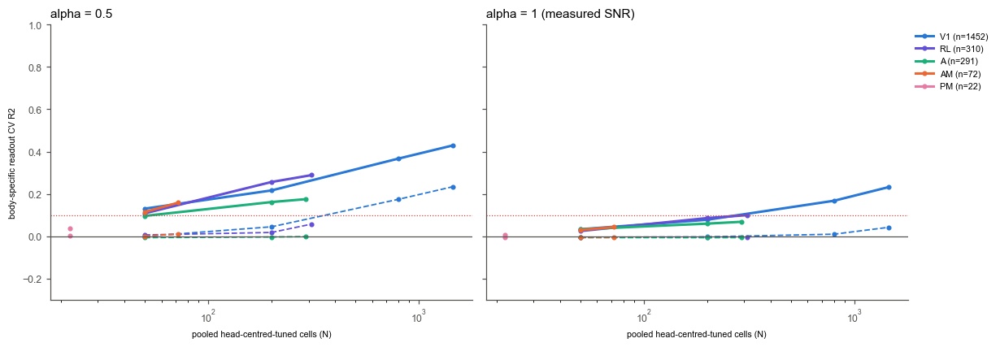

,tuned_cells,real_r2_all,null_r2_all,real_minus_null
V1,1452.0,0.232,0.042,0.190
RL,310.0,0.100,-0.003,0.103
A,291.0,0.069,-0.006,0.075
AM,72.0,0.043,-0.004,0.048
PM,22.0,0.005,-0.004,0.009


In [174]:
if BODY_POOL:
    rows = []
    for (host, a), r in BODY_POOL.items():
        for ki, kind in enumerate(('real', 'null')):
            for zi, N in enumerate(r['sizes']):
                for ai, al in enumerate(r['alphas']):
                    for si in range(r['r2'].shape[3]):
                        rows.append({'host': host, 'area': a, 'kind': kind, 'N': int(N), 'alpha': float(al),
                                     'r2': r['r2'][ki, zi, ai, si], 'n_all': int(r['sizes'][-1])})
    BPT = pd.DataFrame(rows)
    al_ = sorted(BPT['alpha'].unique())
    fig, axs = plt.subplots(1, len(al_), figsize=(5.6 * len(al_), 3.9), squeeze=False, sharey=True)
    for ax, al in zip(axs[0], al_):
        d = BPT[BPT['alpha'] == al]
        for a in AREAS:
            da = d[d['area'] == a]
            if not len(da):
                continue
            for kind, ls in (('real', '-'), ('null', '--')):
                med = da[da['kind'] == kind].groupby('N')['r2'].median()
                ax.plot(med.index, med.to_numpy(), ls=ls, color=acol(a), lw=2 if kind == 'real' else 1.2, marker='o', ms=3,
                        label='{} (n={})'.format(a, int(da['n_all'].iloc[0])) if kind == 'real' else None)
        ax.axhline(SNR_R2_THRESH, color='#d03b3b', lw=0.8, ls=':')
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_xscale('log')
        ax.set_ylim(-0.3, 1.0)
        ax.set_xlabel('pooled head-centred-tuned cells (N)')
        ax.set_title('alpha = {:g}{}'.format(al, ' (measured SNR)' if al == 1 else ''), loc='left', fontsize=10)
        style(ax)
    axs[0][0].set_ylabel('body-specific readout CV R2')
    axs[0][-1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'P2_body_readout')
    d = BPT[BPT['alpha'] == 1.0]
    tab = {}
    for a in AREAS:
        top = d[(d['area'] == a) & (d['N'] == d['n_all'])]
        if len(top):
            tab[a] = {'tuned_cells': int(top['n_all'].iloc[0]), 'real_r2_all': top.loc[top['kind'] == 'real', 'r2'].median(),
                      'null_r2_all': top.loc[top['kind'] == 'null', 'r2'].median()}
    tab = pd.DataFrame(tab).T
    tab['real_minus_null'] = tab['real_r2_all'] - tab['null_r2_all']
    display(tab.round(3))

In [175]:
Q_GRID = np.arange(-175.0, 180.0, 10.0)
Q_MIN_OCC_S = 2.0
Q_VIEW_MIN = 0.5
Q_BIN_DEG = 30.0
Q_SKIP_AREAS = ('PM',)
Q_MATCH_N = None
Q_SUBSETS = 20
Q3_SUBSETS = 10
Q3_ALPHAS = (0.5, 1.0)
Q_PERM = 100
Q_DIM_FRAC = 0.01
GAIN_P_FLOOR = 1.0 / (1 + GAIN_NULL_SHUFFLES)


def wrap180(a):
    return (np.asarray(a, float) + 180.0) % 360.0 - 180.0


def rho_bins(D):
    m = frame_mask(D)
    b = np.floor((wrap180(D['rho'][m]) + 180.0) / 10.0).astype(int) % len(Q_GRID)
    n = np.bincount(b, minlength=len(Q_GRID))
    v = np.bincount(b, D['X'][m, D['names'].index('in_view')], minlength=len(Q_GRID))
    return n * D['dt'], v, n


def field_and_gain(G):
    n, k = len(G['nuis_names']), na.N_VM
    b = G['coef'] / G['x_sd'][:, None]
    V = na._vm_basis(Q_GRID)
    return V @ b[n + 1:n + 1 + k], V @ b[-k:]


def basis_table(donors):
    path_of = SES.set_index('session')['path']
    rows, GP, SAMP = [], {'real': [], 'null': []}, []
    view_v, view_n = np.zeros(len(Q_GRID)), np.zeros(len(Q_GRID))
    for d in donors:
        occ_s, v, n = rho_bins(load_covariates(path_of[d['session']]))
        view_v += v
        view_n += n
        samp = occ_s >= Q_MIN_OCC_S
        for kind in ('real', 'null'):
            f, g = field_and_gain(d['gm_' + kind])
            sd = d['res_' + kind].std(0).astype(float)
            sd[~(sd > 0)] = np.nan
            GP[kind].append((g / sd).T)
            if kind == 'null':
                continue
            nc = f.shape[1]
            out = {'session': d['session'], 'cell': d['cells'], 'area': d['area'],
                   'gain_p': GN[d['session']]['p'][d['cells']]}
            if samp.sum() >= 3:
                F, Gs = f[samp], g[samp]
                dF = np.gradient(f, axis=0)[samp]
                c = lambda A: A - A.mean(0)
                Fc, Gc, dFc = c(F), c(Gs), c(dF)
                nrm = lambda A: np.sqrt(np.maximum((A ** 2).sum(0), 1e-24))
                out['pref_rho'] = Q_GRID[samp][np.argmax(F, 0)]
                out['depth'] = F.max(0) - F.min(0)
                out['k'] = (Fc * Gc).sum(0) / np.maximum((Fc ** 2).sum(0), 1e-12)
                out['mult_r'] = (Fc * Gc).sum(0) / (nrm(Fc) * nrm(Gc))
                out['shift_r'] = (dFc * Gc).sum(0) / (nrm(dFc) * nrm(Gc))
            rows.append(pd.DataFrame(out))
        SAMP.append(np.repeat(samp[None], len(d['cells']), 0))
    QC = pd.concat(rows, ignore_index=True)
    QC['gain_cell'] = QC['gain_p'] <= GAIN_P_FLOOR + 1e-9
    view = view_v / np.maximum(view_n, 1)
    QC['pref_visible'] = QC['pref_rho'].map(lambda r: view[int((r + 180.0) // 10) % len(Q_GRID)] >= Q_VIEW_MIN
                                            if np.isfinite(r) else False)
    return QC, {k: np.concatenate(v, 0) for k, v in GP.items()}, np.concatenate(SAMP, 0), view


def coverage(QC, area, view):
    from scipy.stats import binom
    d = QC[(QC['area'] == area) & QC['pref_rho'].notna()]
    edges = np.arange(-180.0, 180.0 + Q_BIN_DEG, Q_BIN_DEG)
    b = np.clip(np.digitize(d['pref_rho'], edges) - 1, 0, len(edges) - 2)
    q = GAIN_P_FLOOR / 2
    res = []
    for i in range(len(edges) - 1):
        db = d[b == i]
        n = len(db)
        pos, neg = int((db['gain_cell'] & (db['k'] > 0)).sum()), int((db['gain_cell'] & (db['k'] < 0)).sum())
        inb = (Q_GRID >= edges[i]) & (Q_GRID < edges[i + 1])
        res.append({'lo': edges[i], 'visible': bool(view[inb].mean() >= Q_VIEW_MIN), 'tuned': n, 'pos': pos,
                    'neg': neg, 'chance': n * q,
                    'pos_p': binom.sf(pos - 1, n, q) if n else np.nan, 'neg_p': binom.sf(neg - 1, n, q) if n else np.nan})
    return pd.DataFrame(res)


def signal_dims(GP, rows, cols, n_cells=None, n_subsets=1, n_perm=Q_PERM, seed=0):
    rng = np.random.default_rng(seed)
    U, s_, _ = np.linalg.svd(na._vm_basis(Q_GRID[cols]), full_matrices=False)
    U = U[:, s_ > 1e-3 * s_[0]]
    R, N = GP['real'][:, cols] @ U, GP['null'][:, cols] @ U
    idx = np.flatnonzero(rows & np.all(np.isfinite(R), 1) & np.all(np.isfinite(N), 1))
    n_cells = len(idx) if n_cells is None else n_cells
    if len(idx) < n_cells or n_cells < 5:
        return None
    eig = lambda A, B: np.sort(np.linalg.eigvalsh((A.T @ A - B.T @ B) / len(A)))[::-1]
    out = {'eig': [], 'eig_null95': [], 'dims': []}
    for _ in range(n_subsets):
        sel = rng.choice(idx, n_cells, replace=False) if n_cells < len(idx) else idx
        e = eig(R[sel], N[sel])
        perm = []
        for _ in range(n_perm):
            sw = rng.random(len(sel)) < 0.5
            perm.append(eig(np.where(sw[:, None], N[sel], R[sel]), np.where(sw[:, None], R[sel], N[sel])))
        p95 = np.percentile(perm, 95, axis=0)
        above = (e > p95) & (e >= Q_DIM_FRAC * e[e > 0].sum())
        out['eig'].append(e)
        out['eig_null95'].append(p95)
        out['dims'].append(int(np.argmin(above)) if not above.all() else len(above))
    return {k: np.array(v) for k, v in out.items()}


def dims_needed(cols):
    U, s_, _ = np.linalg.svd(na._vm_basis(Q_GRID[cols]), full_matrices=False)
    U = U[:, s_ > 1e-3 * s_[0]]
    x = Q_GRID[cols]
    P = U.T @ ((na._vm_basis(x + 1.0) - na._vm_basis(x - 1.0)) / 2.0)
    e = np.sort(np.linalg.eigvalsh(P @ P.T))[::-1]
    return int(np.sum(e >= Q_DIM_FRAC * e[e > 0].sum()))


def dims_possible(cols):
    s_ = np.linalg.svd(na._vm_basis(Q_GRID[cols]), compute_uv=False)
    return int(np.sum(s_ > 1e-3 * s_[0]))


def pooled_noise(RES, n_frames, rng):
    nz = []
    for r in RES:
        n = r.shape[0]
        sh = rng.integers(NULL_MIN_SHIFT, n - NULL_MIN_SHIFT, r.shape[1])
        nz.append(np.take_along_axis(r, (np.arange(n_frames)[:, None] + sh[None, :]) % n, 0))
    return np.concatenate(nz, 1)


def pool_columns(D, donors, area, nuisance, n_cells=None, n_subsets=1, alphas=(1.0,), seed=0):
    m = frame_mask(D)
    idx = np.flatnonzero(m)
    Dm, mm = {'t': D['t'][idx]}, np.ones(len(idx), bool)
    T = head_specific_target(D, m)[idx]
    parts = [(d, np.flatnonzero(d['area'] == area)) for d in donors]
    parts = [(d, c) for d, c in parts if len(c)]
    if not parts:
        return None
    G = {kind: np.concatenate([gain_field_pred(D, dict(d['gm_' + kind], coef=d['gm_' + kind]['coef'][:, c],
                                                       y_mean=d['gm_' + kind]['y_mean'][c]), m, nuisance)
                               for d, c in parts], 1) for kind in ('real', 'null')}
    src_ = [(pi, j) for pi, (d, c) in enumerate(parts) for j in range(len(c))]
    n_all = len(src_)
    n = n_all if n_cells is None else int(n_cells)
    if n > n_all:
        return None
    trm, tem, block = na._folds(Dm, mm)
    rng = np.random.default_rng(seed)
    r2 = np.full((2, len(alphas), n_subsets, na.N_VM), np.nan)
    for si in range(n_subsets):
        sel = rng.choice(n_all, n, replace=False) if n < n_all else np.arange(n_all)
        for ki, kind in enumerate(('real', 'null')):
            nz = np.empty((len(idx), n))
            for jj, j in enumerate(sel):
                pi, col = src_[j]
                r = parts[pi][0]['res_' + kind][:, parts[pi][1][col]]
                sh = int(rng.integers(NULL_MIN_SHIFT, len(r) - NULL_MIN_SHIFT))
                nz[:, jj] = r[(np.arange(len(idx)) + sh) % len(r)]
            for ai, al in enumerate(alphas):
                U = G[kind][:, sel] + al * nz
                r2[ki, ai, si] = np.maximum(cv_ridge(na._zbuilder(U), T, trm, tem, block)['r2'], -1.0)
    cen = np.arange(na.N_VM) * 360.0 / na.N_VM
    near = np.abs(wrap180(D['eta'][m][:, None] - cen[None, :])) < 180.0 / na.N_VM
    view = D['X'][m, D['names'].index('in_view')]
    return {'r2': r2, 'alphas': np.asarray(alphas, float), 'centers': wrap180(cen), 'occ': near.mean(0),
            'in_view': np.array([view[near[:, j]].mean() if near[:, j].any() else np.nan for j in range(na.N_VM)]),
            'n_cells': np.array(n), 'n_all': np.array(n_all)}

In [176]:
QC, Q_COLS = pd.DataFrame(), {}
if not (RUN_REFITS and GN):
    print('RUN_REFITS is off (or J has no sessions) -- section Q is skipped.')
elif not restore('Q'):
    t_all = time.time()
    if 'd' in pool_box and pool_box['d'] and 'cells' not in pool_box['d'][0]:
        pool_box.pop('d')
    QC, QGP, QSAMP, QVIEW = basis_table(donors_once())
    QVIS = QVIEW >= Q_VIEW_MIN
    Q_AREAS = [a for a in AREAS if a not in Q_SKIP_AREAS]
    Q_N = Q_MATCH_N or int(QC[QC['area'].isin(Q_AREAS)].groupby('area').size().min())
    print('Q areas: {}; matched comparisons at {} tuned cells.'.format(', '.join(Q_AREAS), Q_N))
    print('Visible retinal azimuth: {:.0f} to {:.0f} deg.  Gain directions a head-centred readout needs: {} visible, '
          '{} elsewhere.'.format(Q_GRID[QVIS].min() - 5, Q_GRID[QVIS].max() + 5, dims_needed(QVIS), dims_needed(~QVIS)))
    for _, h in HOSTS.iterrows():
        D_h = load_covariates(h['path'])
        for a in Q_AREAS:
            t0 = time.time()
            r = cached(h, 'poolcols_' + a, {'nuis': POOL_NUISANCE, 'donors': POOL_SIG, 'n': Q_N,
                                            'subsets': Q3_SUBSETS, 'alphas': list(Q3_ALPHAS), 'v': 2},
                       lambda: pool_columns(D_h, donors_once(), a, POOL_NUISANCE, Q_N, Q3_SUBSETS, Q3_ALPHAS))
            if r is not None:
                Q_COLS[(h['session'], a)] = r
            if time.time() - t0 > 5:
                print('  {} x {}: {:.0f} s'.format(h['session'], a, time.time() - t0))
    print('Q: {:.1f} min.'.format((time.time() - t_all) / 60))
    stash('Q', QC=QC, QGP=QGP, QSAMP=QSAMP, QVIEW=QVIEW, QVIS=QVIS, Q_AREAS=Q_AREAS, Q_N=Q_N, Q_COLS=Q_COLS)

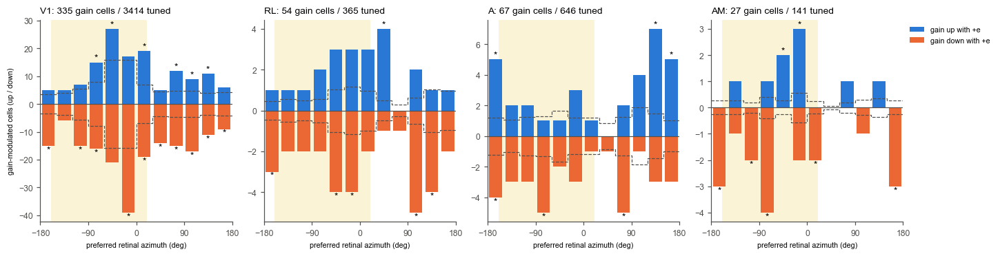

,tuned,tuned_pref_visible,gain_cells,gain_pref_visible,gain_frac_up,sign_balance_p,abs_mult_r,abs_shift_r,vis_bins,vis_bins_up,vis_bins_down,vis_bins_both,sign_by_position_p
V1,3414.0,0.512,335.0,0.415,0.412,0.001,0.788,0.453,4.0,2.0,3.0,1.0,0.036
RL,365.0,0.334,54.0,0.333,0.407,0.220,0.741,0.436,4.0,0.0,2.0,0.0,0.978
A,646.0,0.350,67.0,0.313,0.493,1.000,0.863,0.395,4.0,0.0,1.0,0.0,0.673
AM,141.0,0.426,27.0,0.481,0.333,0.122,0.770,0.340,4.0,2.0,2.0,0.0,0.120


In [177]:
if len(QC):
    from scipy.stats import binomtest, chi2_contingency
    fig, axs = plt.subplots(1, len(Q_AREAS), figsize=(3.3 * len(Q_AREAS), 3.4), sharey=False, squeeze=False)
    QT = {}
    for ax, a in zip(axs[0], Q_AREAS):
        cov = coverage(QC, a, QVIEW)
        x = cov['lo'] + Q_BIN_DEG / 2
        for _, r in cov[cov['visible']].iterrows():
            ax.axvspan(20, -160, color='#fbf3d5', lw=0)
        ax.bar(x, cov['pos'], width=Q_BIN_DEG * 0.8, color='#2a78d6', label='gain up with +e')
        ax.bar(x, -cov['neg'], width=Q_BIN_DEG * 0.8, color='#eb6834', label='gain down with +e')
        ax.step(np.r_[cov['lo'], 180.0], np.r_[cov['chance'], cov['chance'].iloc[-1]], where='post', color=INK2, lw=0.8, ls='--')
        ax.step(np.r_[cov['lo'], 180.0], -np.r_[cov['chance'], cov['chance'].iloc[-1]], where='post', color=INK2, lw=0.8, ls='--')
        for _, r in cov.iterrows():
            for v, p in ((r['pos'], r['pos_p']), (-r['neg'], r['neg_p'])):
                if p < 0.05:
                    ax.text(r['lo'] + Q_BIN_DEG / 2, v, '*', ha='center', va='bottom' if v > 0 else 'top', fontsize=9)
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_xlim(-180, 180)
        ax.set_xticks([-180, -90, 0, 90, 180])
        ax.set_xlabel('preferred retinal azimuth (deg)')
        d, gc = QC[QC['area'] == a], QC[(QC['area'] == a) & QC['gain_cell']]
        ax.set_title('{}: {} gain cells / {} tuned'.format(a, len(gc), len(d)), loc='left', fontsize=9)
        style(ax)
        cv = cov[cov['visible']]
        t = cv[['pos', 'neg']].to_numpy()
        t = t[t.sum(1) > 0]
        QT[a] = {'tuned': len(d), 'tuned_pref_visible': d['pref_visible'].mean(), 'gain_cells': len(gc),
                 'gain_pref_visible': gc['pref_visible'].mean(), 'gain_frac_up': (gc['k'] > 0).mean(),
                 'sign_balance_p': binomtest(int((gc['k'] > 0).sum()), len(gc)).pvalue if len(gc) else np.nan,
                 'abs_mult_r': gc['mult_r'].abs().median(), 'abs_shift_r': gc['shift_r'].abs().median(),
                 'vis_bins': len(cv), 'vis_bins_up': int((cv['pos_p'] < 0.05).sum()),
                 'vis_bins_down': int((cv['neg_p'] < 0.05).sum()),
                 'vis_bins_both': int(((cv['pos_p'] < 0.05) & (cv['neg_p'] < 0.05)).sum()),
                 'sign_by_position_p': chi2_contingency(t)[1] if len(t) >= 2 and (t.sum(0) > 0).all() else np.nan}
    axs[0][0].set_ylabel('gain-modulated cells (up / down)')
    axs[0][-1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'Q1_gain_coverage')
    QT = pd.DataFrame(QT).T
    display(QT.round(3))

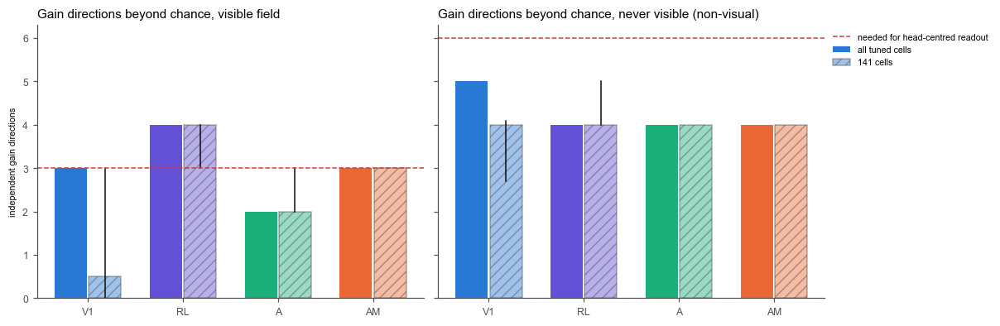

,dims_visible,dims_visible_141,needed_visible,dims_never,dims_never_141,needed_never
V1,3.0,0.5,3.0,5.0,4.0,6.0
RL,4.0,4.0,3.0,4.0,4.0,6.0
A,2.0,2.0,3.0,4.0,4.0,6.0
AM,3.0,3.0,3.0,4.0,4.0,6.0


In [178]:
if len(QC):
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    span_rows = {}
    for ax, (cols, lab) in zip(axs, ((QVIS, 'visible field'), (~QVIS, 'never visible (non-visual)'))):
        need = dims_needed(cols)
        for i, a in enumerate(Q_AREAS):
            rows_ = (QC['area'] == a).to_numpy()
            full = signal_dims(QGP, rows_, cols)
            matched = signal_dims(QGP, rows_, cols, Q_N, Q_SUBSETS)
            if full is not None:
                ax.bar(i - 0.18, full['dims'][0], width=0.34, color=acol(a), label='all tuned cells' if i == 0 else None)
            if matched is not None:
                md = np.median(matched['dims'])
                ax.bar(i + 0.18, md, width=0.34, color=acol(a), alpha=0.45, hatch='///', edgecolor=INK2,
                       label='{} cells'.format(Q_N) if i == 0 else None)
                ax.plot([i + 0.18] * 2, np.percentile(matched['dims'], [10, 90]), color=INK, lw=1)
            span_rows.setdefault(a, {})['dims_' + lab.split()[0]] = full['dims'][0] if full is not None else np.nan
            span_rows[a]['dims_{}_{}'.format(lab.split()[0], Q_N)] = np.median(matched['dims']) if matched is not None else np.nan
            span_rows[a]['needed_' + lab.split()[0]] = need
        ax.axhline(need, color='#d03b3b', lw=1, ls='--', label='needed for head-centred readout')
        ax.set_xticks(range(len(Q_AREAS)))
        ax.set_xticklabels(Q_AREAS)
        ax.set_title('Gain directions beyond chance, {}'.format(lab), loc='left', fontsize=10)
        style(ax)
    axs[0].set_ylabel('independent gain directions')
    axs[1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'Q2_gain_span')
    display(pd.DataFrame(span_rows).T)

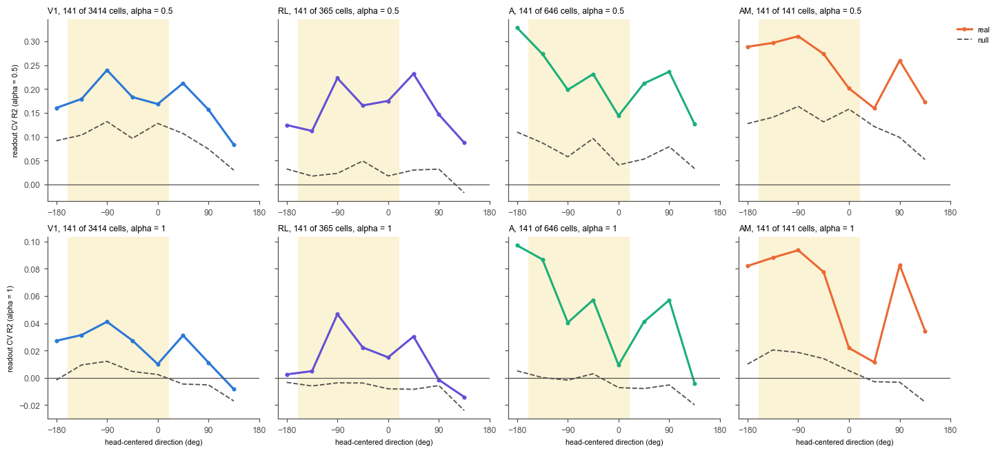

visible_real  visible_null  visible_real_minus_null  hidden_real  hidden_null  hidden_real_minus_null
area alpha                                                                                                       
V1   0.5           0.212         0.114                    0.097        0.160        0.089                   0.071
     1.0           0.034         0.008                    0.026        0.017       -0.003                   0.020
RL   0.5           0.194         0.036                    0.158        0.146        0.019                   0.128
     1.0           0.035        -0.004                    0.038        0.006       -0.009                   0.015
A    0.5           0.215         0.077                    0.138        0.220        0.067                   0.153
     1.0           0.049         0.001                    0.048        0.048       -0.006                   0.054
AM   0.5           0.292         0.148                    0.145        0.230        0.116                   0.113
     1.0           0.086         0.016                    0.069        0.053        0.002                   0.051

In [179]:
if Q_COLS:
    al_ = list(next(iter(Q_COLS.values()))['alphas'])
    fig, axs = plt.subplots(len(al_), len(Q_AREAS), figsize=(3.3 * len(Q_AREAS), 3.0 * len(al_)), sharey='row', squeeze=False)
    rows = []
    for col, a in enumerate(Q_AREAS):
        rs = [r for (h, aa), r in Q_COLS.items() if aa == a]
        if not rs:
            continue
        c = rs[0]['centers']
        o = np.argsort(c)
        view = np.nanmean([r['in_view'] for r in rs], 0)
        vis = view >= Q_VIEW_MIN
        for ai, al in enumerate(al_):
            ax = axs[ai][col]
            real = np.median(np.concatenate([r['r2'][0, ai] for r in rs], 0), 0)
            null = np.median(np.concatenate([r['r2'][1, ai] for r in rs], 0), 0)
            for j in np.flatnonzero(vis):
                ax.axvspan(20, -160, color='#fbf3d5', lw=0)
            ax.plot(c[o], real[o], color=acol(a), lw=2, marker='o', ms=3, label='real')
            ax.plot(c[o], null[o], color=INK2, lw=1.2, ls='--', label='null')
            ax.axhline(0, color=INK2, lw=0.8)
            ax.set_xticks([-180, -90, 0, 90, 180])
            ax.set_title('{}, {} of {} cells, alpha = {:g}'.format(a, int(rs[0]['n_cells']), int(rs[0]['n_all']), al),
                         loc='left', fontsize=8)
            style(ax)
            rows.append({'area': a, 'alpha': al, 'visible_real': real[vis].mean(), 'visible_null': null[vis].mean(),
                         'visible_real_minus_null': real[vis].mean() - null[vis].mean(),
                         'hidden_real': real[~vis].mean(), 'hidden_null': null[~vis].mean(),
                         'hidden_real_minus_null': real[~vis].mean() - null[~vis].mean()})
    for ai, al in enumerate(al_):
        axs[ai][0].set_ylabel('readout CV R2 (alpha = {:g})'.format(al))
    for ax in axs[-1]:
        ax.set_xlabel('head-centered direction (deg)')
    axs[0][-1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'Q3_readout_by_direction')
    display(pd.DataFrame(rows).set_index(['area', 'alpha']).round(3))

In [180]:
QK_KAPPAS = (1.0, 2.0, 4.0, 8.0)
QK_VIEW_MINS = (0.3, 0.5, 0.7)
QK_FRACS = (0.001, 0.01, 0.05)
QK_SPLITS = 20
QK_BOOT = 100


def expressible_basis(cols):
    U, s_, _ = np.linalg.svd(na._vm_basis(Q_GRID[cols]), full_matrices=False)
    return U[:, s_ > 1e-3 * s_[0]]


def needed_shapes(cols, kappa):
    x = Q_GRID[cols]
    S = (na._vm_basis(x + 1.0, kappa=kappa) - na._vm_basis(x - 1.0, kappa=kappa)) / 2.0
    P = expressible_basis(cols).T @ S
    mu = np.sort(np.linalg.eigvalsh(P @ P.T))[::-1]
    mu = mu / mu.sum()
    return P, {'ceiling': float((P ** 2).sum() / (S ** 2).sum()),
               'need_pr': float(1.0 / np.sum(mu ** 2)), 'one_shape': float(mu[0])}


def dims_needed_k(cols, kappa, frac):
    P, _ = needed_shapes(cols, kappa)
    e = np.sort(np.linalg.eigvalsh(P @ P.T))[::-1]
    return int(np.sum(e >= frac * e[e > 0].sum()))


def gain_signal_stats(R, N, P, rng, ids=None, n_split=QK_SPLITS):
    n = len(R)
    C = (R.T @ R - N.T @ N) / n
    need = float(np.trace(P.T @ C @ P) / np.trace(P.T @ P))
    trc = float(np.trace(C))
    ids = np.arange(n) if ids is None else np.asarray(ids)
    u = np.unique(ids)
    c2 = []
    for _ in range(n_split):
        inA = np.isin(ids, rng.permutation(u)[:len(u) // 2])
        a, b = np.flatnonzero(inA), np.flatnonzero(~inA)
        CA = (R[a].T @ R[a] - N[a].T @ N[a]) / len(a)
        CB = (R[b].T @ R[b] - N[b].T @ N[b]) / len(b)
        c2.append(np.trace(CA @ CB))
    c2 = float(np.mean(c2))
    ok = trc > 0 and c2 > 0
    return {'need': need, 'trace': trc,
            'coverage': need * trc / c2 if ok else np.nan,
            'eff_dims': trc ** 2 / c2 if ok else np.nan}


def coverage_test(GP, rows, cols, kappa=2.0, n_cells=None, n_boot=1, n_perm=Q_PERM, seed=0):
    rng = np.random.default_rng(seed)
    U = expressible_basis(cols)
    P, info = needed_shapes(cols, kappa)
    R, N = GP['real'][:, cols] @ U, GP['null'][:, cols] @ U
    idx = np.flatnonzero(rows & np.all(np.isfinite(R), 1) & np.all(np.isfinite(N), 1))
    if len(idx) < 10 or (n_cells is not None and len(idx) < n_cells):
        return None
    out = {'need': [], 'coverage': [], 'eff_dims': [], 'need_null95': []}
    for _ in range(n_boot if n_cells is not None else 1):
        sel = idx if n_cells is None else rng.choice(idx, n_cells, replace=True)
        st = gain_signal_stats(R[sel], N[sel], P, rng, ids=sel)
        for k in ('need', 'coverage', 'eff_dims'):
            out[k].append(st[k])
        perm = []
        for _ in range(n_perm):
            sw = rng.random(len(sel))[:, None] < 0.5
            Rs, Ns = np.where(sw, N[sel], R[sel]), np.where(sw, R[sel], N[sel])
            perm.append(np.trace(P.T @ ((Rs.T @ Rs - Ns.T @ Ns) / len(sel)) @ P) / np.trace(P.T @ P))
        out['need_null95'].append(np.percentile(perm, 95) if perm else np.nan)
    out = {k: np.array(v, float) for k, v in out.items()}
    out.update(info)
    out['n_cells'] = len(idx) if n_cells is None else n_cells
    return out

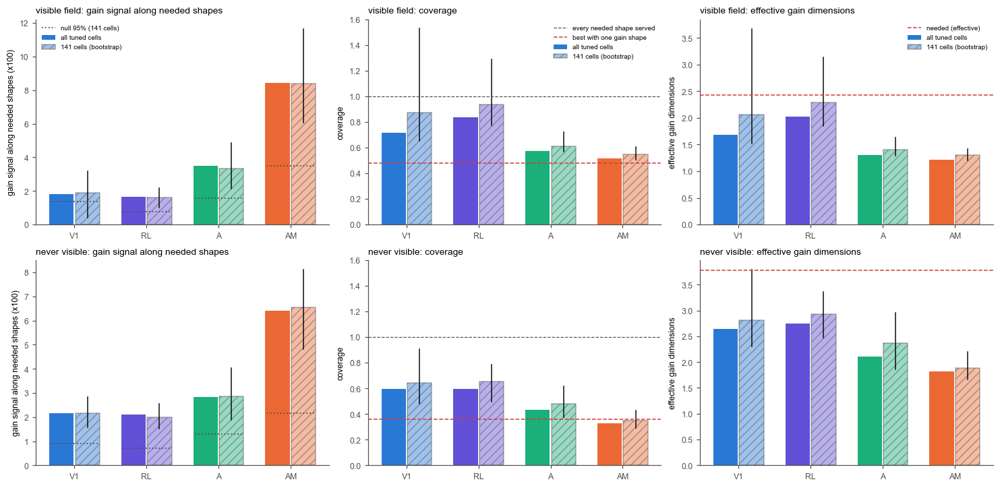

tuned  need_x100_all  need_x100_matched  need_null95_x100_matched  coverage_all  coverage_matched  coverage_matched_10  coverage_matched_90  eff_dims_all  eff_dims_matched  \
field         area                                                                                                                                                                                
visible field V1     3414          1.797              1.872                     1.369         0.715             0.872                0.653                1.530         1.687             2.061   
              RL      365          1.633              1.607                     0.768         0.838             0.937                0.771                1.286         2.027             2.294   
              A       646          3.485              3.324                     1.571         0.572             0.611                0.570                0.719         1.297             1.403   
              AM      141          8.429              8.372                     3.489         0.515             0.547                0.507                0.605         1.219             1.300   
never visible V1     3414          2.167              2.161                     0.894         0.598             0.642                0.480                0.908         2.642             2.816   
              RL      365          2.092              2.002                     0.713         0.596             0.651                0.496                0.785         2.741             2.925   
              A       646          2.823              2.869                     1.291         0.434             0.480                0.375                0.619         2.109             2.361   
              AM      141          6.405              6.557                     2.152         0.330             0.347                0.290                0.426         1.818             1.889   

                    eff_dims_needed  one_shape_coverage  
field         area                                       
visible field V1              2.428               0.478  
              RL              2.428               0.478  
              A               2.428               0.478  
              AM              2.428               0.478  
never visible V1              3.772               0.361  
              RL              3.772               0.361  
              A               3.772               0.361  
              AM              3.772               0.361

In [181]:
if len(QC):
    QK = {}
    rows = []
    fig, axs = plt.subplots(2, 3, figsize=(13.5, 6.6), squeeze=False)
    for ri, (cols, lab) in enumerate(((QVIS, 'visible field'), (~QVIS, 'never visible'))):
        for i, a in enumerate(Q_AREAS):
            rows_ = (QC['area'] == a).to_numpy()
            full = coverage_test(QGP, rows_, cols)
            boot = coverage_test(QGP, rows_, cols, n_cells=Q_N, n_boot=QK_BOOT)
            QK[(lab, a)] = {'full': full, 'boot': boot}
            if full is None or boot is None:
                continue
            for ci, (key, scale) in enumerate((('need', 100.0), ('coverage', 1.0), ('eff_dims', 1.0))):
                ax = axs[ri][ci]
                ax.bar(i - 0.18, full[key][0] * scale, width=0.34, color=acol(a),
                       label='all tuned cells' if i == 0 else None)
                ax.bar(i + 0.18, np.nanmedian(boot[key]) * scale, width=0.34, color=acol(a), alpha=0.45, hatch='///',
                       edgecolor=INK2, label='{} cells (bootstrap)'.format(Q_N) if i == 0 else None)
                ax.plot([i + 0.18] * 2, np.nanpercentile(boot[key], [10, 90]) * scale, color=INK, lw=1)
                if key == 'need':
                    ax.plot([i - 0.33, i + 0.35], [np.median(boot['need_null95']) * scale] * 2, color=INK2, lw=1.2,
                            ls=':', label='null 95% ({} cells)'.format(Q_N) if i == 0 else None)
            rows.append({'field': lab, 'area': a, 'tuned': full['n_cells'],
                         'need_x100_all': full['need'][0] * 100, 'need_x100_matched': np.median(boot['need']) * 100,
                         'need_null95_x100_matched': np.median(boot['need_null95']) * 100,
                         'coverage_all': full['coverage'][0], 'coverage_matched': np.nanmedian(boot['coverage']),
                         'coverage_matched_10': np.nanpercentile(boot['coverage'], 10),
                         'coverage_matched_90': np.nanpercentile(boot['coverage'], 90),
                         'eff_dims_all': full['eff_dims'][0], 'eff_dims_matched': np.nanmedian(boot['eff_dims']),
                         'eff_dims_needed': full['need_pr'], 'one_shape_coverage': full['one_shape']})
        info = needed_shapes(cols, 2.0)[1]
        axs[ri][1].axhline(1.0, color=INK2, lw=0.8, ls='--', label='every needed component served')
        axs[ri][1].axhline(info['one_shape'], color='#d03b3b', lw=1, ls='--', label='best with one gain component')
        axs[ri][2].axhline(info['need_pr'], color='#d03b3b', lw=1, ls='--', label='needed (effective)')
        for ci, yl in enumerate(('gain signal along needed components (x100)', 'coverage', 'effective gain dimensions')):
            ax = axs[ri][ci]
            ax.axhline(0, color=INK2, lw=0.6)
            ax.set_xticks(range(len(Q_AREAS)))
            ax.set_xticklabels(Q_AREAS)
            ax.set_ylabel(yl, fontsize=8)
            ax.set_title('{}: {}'.format(lab, yl.split(' (')[0]), loc='left', fontsize=9)
            style(ax)
        axs[ri][1].set_ylim(0, 1.6)
    for ci, loc in enumerate(('upper left', 'upper right', 'upper right')):
        axs[0][ci].legend(fontsize=6.5, frameon=False, loc=loc)
    show(fig, 'Q4_gain_coverage_score')
    QKT = pd.DataFrame(rows).set_index(['field', 'area'])
    display(QKT.round(3))

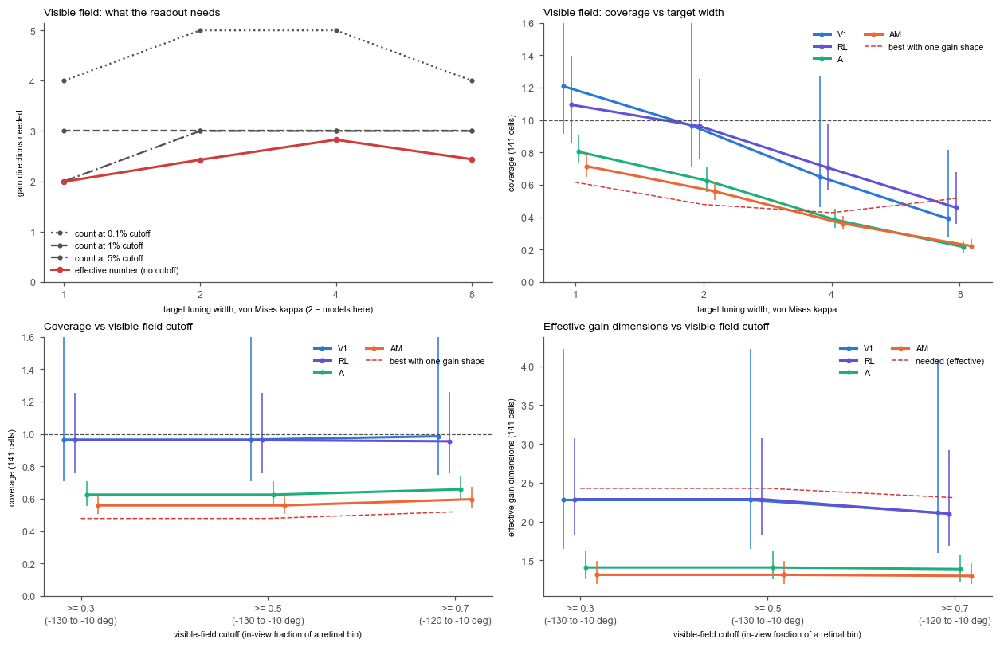

coverage  eff_dims  need_x100  one_shape  eff_dims_needed
sweep    value area                                                           
kappa    1.0   V1       1.208     2.278      2.467      0.616            1.993
         2.0   V1       0.965     2.278      1.934      0.478            2.428
         4.0   V1       0.649     2.278      1.290      0.427            2.827
         8.0   V1       0.390     2.278      0.743      0.518            2.439
         1.0   RL       1.094     2.288      1.843      0.616            1.993
         2.0   RL       0.962     2.288      1.572      0.478            2.428
         4.0   RL       0.706     2.288      1.205      0.427            2.827
         8.0   RL       0.459     2.288      0.799      0.518            2.439
         1.0   A        0.804     1.409      4.317      0.616            1.993
         2.0   A        0.625     1.409      3.340      0.478            2.428
         4.0   A        0.384     1.409      2.070      0.427            2.827
         8.0   A        0.215     1.409      1.139      0.518            2.439
         1.0   AM       0.715     1.315     10.549      0.616            1.993
         2.0   AM       0.559     1.315      8.221      0.478            2.428
         4.0   AM       0.360     1.315      5.362      0.427            2.827
         8.0   AM       0.221     1.315      3.331      0.518            2.439
view_min 0.3   V1       0.965     2.278      1.934      0.478            2.428
         0.5   V1       0.965     2.278      1.934      0.478            2.428
         0.7   V1       0.986     2.115      1.998      0.519            2.307
         0.3   RL       0.962     2.288      1.572      0.478            2.428
         0.5   RL       0.962     2.288      1.572      0.478            2.428
         0.7   RL       0.955     2.100      1.585      0.519            2.307
         0.3   A        0.625     1.409      3.340      0.478            2.428
         0.5   A        0.625     1.409      3.340      0.478            2.428
         0.7   A        0.658     1.388      3.277      0.519            2.307
         0.3   AM       0.559     1.315      8.221      0.478            2.428
         0.5   AM       0.559     1.315      8.221      0.478            2.428
         0.7   AM       0.597     1.300      7.464      0.519            2.307

In [182]:
if len(QC):
    rng_k = np.random.default_rng(1)
    fig, axs = plt.subplots(2, 2, figsize=(11.5, 7.4), squeeze=False)
    xk = np.arange(len(QK_KAPPAS))

    ax = axs[0][0]
    for frac, ls in zip(QK_FRACS, (':', '--', '-.')):
        ax.plot(xk, [dims_needed_k(QVIS, k, frac) for k in QK_KAPPAS], ls=ls, color=INK2, marker='o', ms=3,
                label='count at {:g}% cutoff'.format(100 * frac))
    ax.plot(xk, [needed_shapes(QVIS, k)[1]['need_pr'] for k in QK_KAPPAS], color='#d03b3b', lw=2, marker='o', ms=4,
            label='effective number (no cutoff)')
    ax.set_xticks(xk)
    ax.set_xticklabels(['{:g}'.format(k) for k in QK_KAPPAS])
    ax.set_xlabel('target tuning width, von Mises kappa (2 = models here)')
    ax.set_ylabel('gain directions needed')
    ax.set_ylim(0, None)
    ax.set_title('Visible field: what the readout needs', loc='left', fontsize=9)
    ax.legend(fontsize=7, frameon=False)
    style(ax)

    QK5 = []
    ax = axs[0][1]
    for i, a in enumerate(Q_AREAS):
        rows_ = (QC['area'] == a).to_numpy()
        med, lo, hi = [], [], []
        for k in QK_KAPPAS:
            b = coverage_test(QGP, rows_, QVIS, kappa=k, n_cells=Q_N, n_boot=QK_BOOT, n_perm=0, seed=i)
            med.append(np.nanmedian(b['coverage']))
            lo.append(np.nanpercentile(b['coverage'], 10))
            hi.append(np.nanpercentile(b['coverage'], 90))
            QK5.append({'sweep': 'kappa', 'value': k, 'area': a, 'coverage': med[-1], 'eff_dims': np.nanmedian(b['eff_dims']),
                        'need_x100': np.median(b['need']) * 100, 'one_shape': b['one_shape'], 'eff_dims_needed': b['need_pr']})
        off = (i - (len(Q_AREAS) - 1) / 2) * 0.06
        ax.plot(xk + off, med, color=acol(a), lw=2, marker='o', ms=3, label=a)
        ax.vlines(xk + off, lo, hi, color=acol(a), lw=1)
    ax.plot(xk, [needed_shapes(QVIS, k)[1]['one_shape'] for k in QK_KAPPAS], color='#d03b3b', lw=1, ls='--',
            label='best with one gain shape')
    ax.axhline(1.0, color=INK2, lw=0.8, ls='--')
    ax.set_xticks(xk)
    ax.set_xticklabels(['{:g}'.format(k) for k in QK_KAPPAS])
    ax.set_xlabel('target tuning width, von Mises kappa')
    ax.set_ylabel('coverage ({} cells)'.format(Q_N))
    ax.set_ylim(0, 1.6)
    ax.set_title('Visible field: coverage vs target width', loc='left', fontsize=9)
    ax.legend(fontsize=7, frameon=False, ncol=2)
    style(ax)

    xv = np.arange(len(QK_VIEW_MINS))
    vis_k = [QVIEW >= v for v in QK_VIEW_MINS]
    for ci, key in enumerate(('coverage', 'eff_dims')):
        ax = axs[1][ci]
        for i, a in enumerate(Q_AREAS):
            rows_ = (QC['area'] == a).to_numpy()
            med, lo, hi = [], [], []
            for v, cols in zip(QK_VIEW_MINS, vis_k):
                b = coverage_test(QGP, rows_, cols, n_cells=Q_N, n_boot=QK_BOOT, n_perm=0, seed=i)
                med.append(np.nanmedian(b[key]))
                lo.append(np.nanpercentile(b[key], 10))
                hi.append(np.nanpercentile(b[key], 90))
                if ci == 0:
                    QK5.append({'sweep': 'view_min', 'value': v, 'area': a, 'coverage': med[-1],
                                'eff_dims': np.nanmedian(b['eff_dims']), 'need_x100': np.median(b['need']) * 100,
                                'one_shape': b['one_shape'], 'eff_dims_needed': b['need_pr']})
            off = (i - (len(Q_AREAS) - 1) / 2) * 0.06
            ax.plot(xv + off, med, color=acol(a), lw=2, marker='o', ms=3, label=a)
            ax.vlines(xv + off, lo, hi, color=acol(a), lw=1)
        ref = [needed_shapes(c, 2.0)[1]['one_shape' if key == 'coverage' else 'need_pr'] for c in vis_k]
        ax.plot(xv, ref, color='#d03b3b', lw=1, ls='--',
                label='best with one gain shape' if key == 'coverage' else 'needed (effective)')
        if key == 'coverage':
            ax.axhline(1.0, color=INK2, lw=0.8, ls='--')
            ax.set_ylim(0, 1.6)
        ax.set_xticks(xv)
        ax.set_xticklabels(['>= {:g}\n({:.0f} to {:.0f} deg)'.format(v, Q_GRID[c].min() - 5, Q_GRID[c].max() + 5)
                            for v, c in zip(QK_VIEW_MINS, vis_k)], fontsize=7)
        ax.set_xlabel('visible-field cutoff (in-view fraction of a retinal bin)')
        ax.set_ylabel('{} ({} cells)'.format('coverage' if key == 'coverage' else 'effective gain dimensions', Q_N))
        ax.set_title('Coverage vs visible-field cutoff' if key == 'coverage' else
                     'Effective gain dimensions vs visible-field cutoff', loc='left', fontsize=9)
        ax.legend(fontsize=7, frameon=False, ncol=2)
        style(ax)
    show(fig, 'Q5_coverage_sensitivity')
    QK5 = pd.DataFrame(QK5).set_index(['sweep', 'value', 'area'])
    display(QK5.round(3))

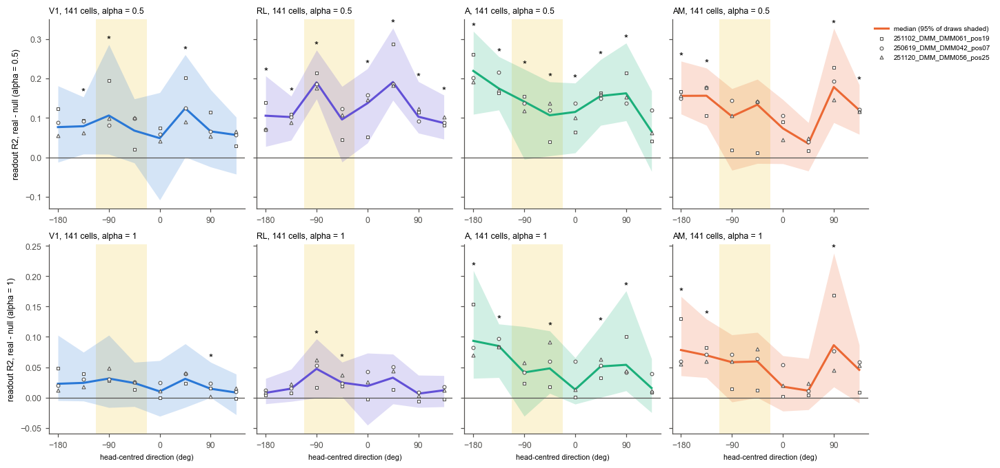

directions  consistent  median_real_minus_null  mean_real_minus_null  min_host_time_share
area alpha field                                                                                                   
V1   0.5   visible                 2           1                   0.090                 0.093                0.090
           never visible           6           2                   0.073                 0.076                0.075
     1.0   visible                 2           0                   0.028                 0.030                0.090
           never visible           6           1                   0.016                 0.021                0.075
RL   0.5   visible                 2           1                   0.159                 0.145                0.090
           never visible           6           6                   0.117                 0.125                0.075
     1.0   visible                 2           2                   0.029                 0.035                0.090
           never visible           6           0                   0.012                 0.015                0.075
A    0.5   visible                 2           2                   0.125                 0.118                0.090
           never visible           6           5                   0.153                 0.152                0.075
     1.0   visible                 2           1                   0.044                 0.046                0.090
           never visible           6           4                   0.056                 0.059                0.075
AM   0.5   visible                 2           0                   0.119                 0.098                0.090
           never visible           6           4                   0.121                 0.122                0.075
     1.0   visible                 2           0                   0.058                 0.051                0.090
           never visible           6           3                   0.053                 0.055                0.075

In [183]:
Q6_CONSISTENT = 0.95
if Q_COLS:
    al_ = list(next(iter(Q_COLS.values()))['alphas'])
    hosts_ = sorted({h for h, _ in Q_COLS})
    hmark = dict(zip(hosts_, ('o', 's', '^', 'D', 'v')))
    fig, axs = plt.subplots(len(al_), len(Q_AREAS), figsize=(3.3 * len(Q_AREAS), 3.1 * len(al_)), sharey='row',
                            squeeze=False)
    rows = []
    for col, a in enumerate(Q_AREAS):
        rs = {h: r for (h, aa), r in Q_COLS.items() if aa == a}
        if not rs:
            continue
        r0 = next(iter(rs.values()))
        c = r0['centers']
        o = np.argsort(c)
        view = np.nanmean([r['in_view'] for r in rs.values()], 0)
        occ = np.nanmean([r['occ'] for r in rs.values()], 0)
        vis = view >= Q_VIEW_MIN
        for ai, al in enumerate(al_):
            ax = axs[ai][col]
            dif = np.concatenate([r['r2'][0, ai] - r['r2'][1, ai] for r in rs.values()], 0)
            for j in np.flatnonzero(vis):
                ax.axvspan(c[j] - 22.5, c[j] + 22.5, color='#fbf3d5', lw=0)
            lo, med, hi = np.percentile(dif, [2.5, 50, 97.5], axis=0)
            ax.fill_between(c[o], lo[o], hi[o], color=acol(a), alpha=0.2, lw=0)
            ax.plot(c[o], med[o], color=acol(a), lw=2, label='median (95% of draws shaded)')
            for h, r in rs.items():
                ax.scatter(c, np.median(r['r2'][0, ai] - r['r2'][1, ai], 0), s=10, marker=hmark[h], facecolor='white',
                           edgecolor=INK2, lw=0.7, zorder=3, label=h if (col == len(Q_AREAS) - 1 and ai == 0) else None)
            frac_pos = np.mean(dif > 0, 0)
            for j in np.flatnonzero(frac_pos >= Q6_CONSISTENT):
                ax.text(c[j], hi[j], '*', ha='center', va='bottom', fontsize=10)
            ax.axhline(0, color=INK2, lw=0.8)
            ax.set_xticks([-180, -90, 0, 90])
            ax.set_title('{}, {} cells, alpha = {:g}'.format(a, int(r0['n_cells']), al), loc='left', fontsize=8)
            style(ax)
            for vlab, vm in (('visible', vis), ('never visible', ~vis)):
                rows.append({'area': a, 'alpha': al, 'field': vlab, 'directions': int(vm.sum()),
                             'consistent': int(np.sum(frac_pos[vm] >= Q6_CONSISTENT)),
                             'median_real_minus_null': float(np.median(dif[:, vm])),
                             'mean_real_minus_null': float(dif[:, vm].mean()),
                             'min_host_time_share': float(occ[vm].min()) if vm.any() else np.nan})
    for ai, al in enumerate(al_):
        axs[ai][0].set_ylabel('readout R2, real - null (alpha = {:g})'.format(al), fontsize=8)
    for ax in axs[-1]:
        ax.set_xlabel('head-centred direction (deg)')
    axs[0][-1].legend(fontsize=6.5, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'Q6_readout_by_direction_paired')
    display(pd.DataFrame(rows).set_index(['area', 'alpha', 'field']).round(3))

In [184]:
Q7_KAPPAS = (1.0, 2.0, 4.0, 8.0)


def head_specific_target_k(D, m, kappa):
    e = D['e']
    ez = (e - np.nanmean(e[m])) / np.nanstd(e[m])
    vr, H = na._vm_basis(D['rho'], kappa=kappa), na._vm_basis(D['eta'], kappa=kappa)
    A = np.c_[np.ones(len(e)), vr, ez]
    coef = np.linalg.lstsq(A[m], H[m], rcond=None)[0]
    return np.nan_to_num(H - A @ coef)


def pool_columns_k(D, donors, area, nuisance, kappas, n_cells, n_subsets, alphas, seed=0):
    m = frame_mask(D)
    idx = np.flatnonzero(m)
    Dm, mm = {'t': D['t'][idx]}, np.ones(len(idx), bool)
    T = {k: head_specific_target_k(D, m, k)[idx] for k in kappas}
    parts = [(d, np.flatnonzero(d['area'] == area)) for d in donors]
    parts = [(d, c) for d, c in parts if len(c)]
    if not parts:
        return None
    G = {kind: np.concatenate([gain_field_pred(D, dict(d['gm_' + kind], coef=d['gm_' + kind]['coef'][:, c],
                                                       y_mean=d['gm_' + kind]['y_mean'][c]), m, nuisance)
                               for d, c in parts], 1) for kind in ('real', 'null')}
    src_ = [(pi, j) for pi, (d, c) in enumerate(parts) for j in range(len(c))]
    n_all = len(src_)
    n = n_all if n_cells is None else int(n_cells)
    if n > n_all:
        return None
    trm, tem, block = na._folds(Dm, mm)
    rng = np.random.default_rng(seed)
    r2 = np.full((len(kappas), 2, len(alphas), n_subsets, na.N_VM), np.nan)
    for si in range(n_subsets):
        sel = rng.choice(n_all, n, replace=False) if n < n_all else np.arange(n_all)
        for ki, kind in enumerate(('real', 'null')):
            nz = np.empty((len(idx), n))
            for jj, j in enumerate(sel):
                pi, col = src_[j]
                r = parts[pi][0]['res_' + kind][:, parts[pi][1][col]]
                sh = int(rng.integers(NULL_MIN_SHIFT, len(r) - NULL_MIN_SHIFT))
                nz[:, jj] = r[(np.arange(len(idx)) + sh) % len(r)]
            for ai, al in enumerate(alphas):
                U = G[kind][:, sel] + al * nz
                for kk, k in enumerate(kappas):
                    r2[kk, ki, ai, si] = np.maximum(cv_ridge(na._zbuilder(U), T[k], trm, tem, block)['r2'], -1.0)
    return {'r2': r2, 'kappas': np.asarray(kappas, float), 'alphas': np.asarray(alphas, float)}

In [185]:
Q7_COLS = {}
if not (RUN_REFITS and GN and Q_COLS):
    print('RUN_REFITS is off (or Q has no readouts) -- Q7 is skipped.')
elif not restore('Q7'):
    t_all = time.time()
    for _, h in HOSTS.iterrows():
        D_h = load_covariates(h['path'])
        for a in Q_AREAS:
            t0 = time.time()
            r = cached(h, 'poolcolsk_' + a, {'nuis': POOL_NUISANCE, 'donors': POOL_SIG, 'n': Q_N,
                                             'subsets': Q3_SUBSETS, 'alphas': list(Q3_ALPHAS),
                                             'kappas': list(Q7_KAPPAS), 'v': 1},
                       lambda: pool_columns_k(D_h, donors_once(), a, POOL_NUISANCE, Q7_KAPPAS, Q_N, Q3_SUBSETS,
                                              Q3_ALPHAS))
            if r is not None:
                Q7_COLS[(h['session'], a)] = r
            if time.time() - t0 > 5:
                print('  {} x {}: {:.0f} s'.format(h['session'], a, time.time() - t0))
    print('Q7: {:.1f} min.'.format((time.time() - t_all) / 60))
    stash('Q7', Q7_COLS=Q7_COLS)

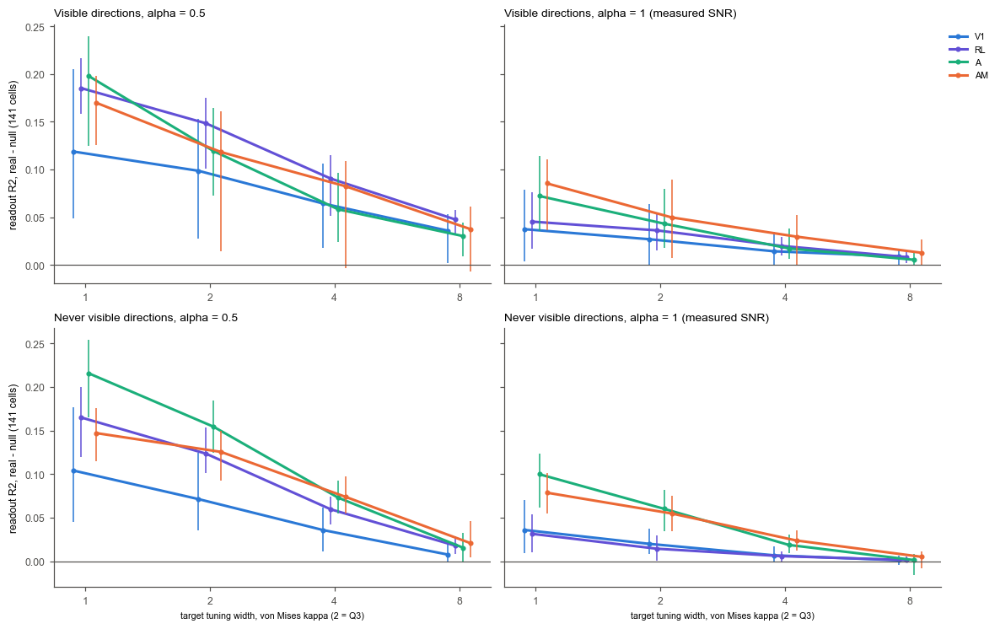

area                          V1     RL      A     AM
field         alpha kappa                            
never visible 0.5   1.0    0.104  0.165  0.216  0.147
                    2.0    0.071  0.123  0.154  0.126
                    4.0    0.036  0.060  0.073  0.074
                    8.0    0.008  0.018  0.016  0.021
              1.0   1.0    0.036  0.031  0.100  0.079
                    2.0    0.020  0.014  0.060  0.055
                    4.0    0.007  0.006  0.019  0.024
                    8.0    0.001  0.001  0.001  0.005
visible       0.5   1.0    0.119  0.185  0.198  0.170
                    2.0    0.099  0.148  0.119  0.118
                    4.0    0.064  0.090  0.058  0.082
                    8.0    0.036  0.048  0.030  0.037
              1.0   1.0    0.037  0.045  0.072  0.085
                    2.0    0.027  0.036  0.043  0.050
                    4.0    0.014  0.020  0.017  0.030
                    8.0    0.009  0.008  0.005  0.013

field          alpha  kappa
never visible  0.5    1.0      A > RL > AM > V1
                      2.0      A > AM > RL > V1
                      4.0      AM > A > RL > V1
                      8.0      AM > RL > A > V1
               1.0    1.0      A > AM > V1 > RL
                      2.0      A > AM > V1 > RL
                      4.0      AM > A > V1 > RL
                      8.0      AM > A > RL > V1
visible        0.5    1.0      A > RL > AM > V1
                      2.0      RL > A > AM > V1
                      4.0      RL > AM > V1 > A
                      8.0      RL > AM > V1 > A
               1.0    1.0      AM > A > RL > V1
                      2.0      AM > A > RL > V1
                      4.0      AM > RL > A > V1
                      8.0      AM > V1 > RL > A
Name: ranking, dtype: object

In [186]:
if Q7_COLS:
    r0 = next(iter(Q7_COLS.values()))
    ks, al_ = list(r0['kappas']), list(r0['alphas'])
    xk = np.arange(len(ks))
    fig, axs = plt.subplots(2, len(al_), figsize=(5.4 * len(al_), 6.8), sharey='row', squeeze=False)
    rows = []
    for col, a in enumerate(Q_AREAS):
        rs = [Q7_COLS[(h, aa)] for (h, aa) in Q7_COLS if aa == a]
        qs = [Q_COLS[(h, aa)] for (h, aa) in Q7_COLS if aa == a]
        if not rs:
            continue
        vis = np.nanmean([q['in_view'] for q in qs], 0) >= Q_VIEW_MIN
        for ri, (vlab, vm) in enumerate((('visible', vis), ('never visible', ~vis))):
            for ai, al in enumerate(al_):
                ax = axs[ri][ai]
                d = np.stack([np.concatenate([r['r2'][kk, 0, ai][:, vm] - r['r2'][kk, 1, ai][:, vm] for r in rs], 0).mean(1)
                              for kk in range(len(ks))], 1)
                lo, med, hi = np.percentile(d, [10, 50, 90], axis=0)
                off = (col - (len(Q_AREAS) - 1) / 2) * 0.06
                ax.plot(xk + off, med, color=acol(a), lw=2, marker='o', ms=3, label=a)
                ax.vlines(xk + off, lo, hi, color=acol(a), lw=1)
                for kk, k in enumerate(ks):
                    rows.append({'field': vlab, 'alpha': al, 'kappa': k, 'area': a, 'real_minus_null': med[kk],
                                 'p10': lo[kk], 'p90': hi[kk], 'frac_draws_positive': float(np.mean(d[:, kk] > 0))})
    for ri, vlab in enumerate(('visible', 'never visible')):
        for ai, al in enumerate(al_):
            ax = axs[ri][ai]
            ax.axhline(0, color=INK2, lw=0.8)
            ax.set_xticks(xk)
            ax.set_xticklabels(['{:g}'.format(k) for k in ks])
            ax.set_title('{} directions, alpha = {:g}{}'.format(vlab.capitalize(), al, ' (measured SNR)' if al == 1 else ''),
                         loc='left', fontsize=9)
            style(ax)
        axs[ri][0].set_ylabel('readout R2, real - null ({} cells)'.format(Q_N), fontsize=8)
    for ax in axs[-1]:
        ax.set_xlabel('target tuning width, von Mises kappa (2 = Q3)')
    axs[0][-1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'Q7_readout_vs_kappa')
    Q7T = pd.DataFrame(rows)
    display(Q7T.pivot_table(index=['field', 'alpha', 'kappa'], columns='area', values='real_minus_null')[Q_AREAS].round(3))
    rk = Q7T.groupby(['field', 'alpha', 'kappa']).apply(
        lambda d: ' > '.join(d.sort_values('real_minus_null', ascending=False)['area']))
    display(rk.rename('ranking'))

In [187]:
R_PARIETAL = ('RL', 'A', 'AM')
R_N_EACH = None
R_SUBSETS = 10
R_ALPHAS = (0.5, 1.0)


def r_populations(QC):
    n_each = R_N_EACH or Q_N // 3
    item2 = {'RL': [(('RL',), Q_N)], 'A': [(('A',), Q_N)], 'AM': [(('AM',), Q_N)],
             'equal mix': [((a,), n_each) for a in R_PARIETAL],
             'pooled mix': [(R_PARIETAL, Q_N)]}
    count = lambda areas: int(QC['area'].isin(areas).sum())
    n3 = min(count(R_PARIETAL), count(('A', 'AM')), count(('V1',)))
    item3 = {'RL+A+AM': [(R_PARIETAL, n3)], 'A+AM': [(('A', 'AM'), n3)], 'V1': [(('V1',), n3)]}
    item3_all = {'RL+A+AM': [(R_PARIETAL, count(R_PARIETAL))], 'A+AM': [(('A', 'AM'), count(('A', 'AM')))],
                 'V1': [(('V1',), count(('V1',)))]}
    return item2, item3, item3_all, n3


def coverage_strata(GP, area, strata, cols, kappa=2.0, n_boot=QK_BOOT, n_perm=Q_PERM, seed=0):
    rng = np.random.default_rng(seed)
    U = expressible_basis(cols)
    P, info = needed_shapes(cols, kappa)
    R, N = GP['real'][:, cols] @ U, GP['null'][:, cols] @ U
    ok = np.all(np.isfinite(R), 1) & np.all(np.isfinite(N), 1)
    pools = [(np.flatnonzero(ok & np.isin(area, areas)), n) for areas, n in strata]
    if any(len(ix) < 10 for ix, _ in pools):
        return None
    mu, V = np.linalg.eigh(P @ P.T)
    mu, V = mu[::-1], V[:, ::-1]
    V_main, V_rest = V[:, :2], V[:, 2:][:, mu[2:] > 1e-9 * mu.sum()]
    sub = lambda C, W: float(np.trace(W.T @ C @ W) / W.shape[1]) if W.shape[1] else np.nan
    out = {'need': [], 'coverage': [], 'eff_dims': [], 'need_null95': [], 'main': [], 'rest': [],
           'main_null95': [], 'rest_null95': []}
    for _ in range(n_boot):
        sel = np.concatenate([rng.choice(ix, n, replace=True) for ix, n in pools])
        st = gain_signal_stats(R[sel], N[sel], P, rng, ids=sel)
        for k in ('need', 'coverage', 'eff_dims'):
            out[k].append(st[k])
        C = (R[sel].T @ R[sel] - N[sel].T @ N[sel]) / len(sel)
        out['main'].append(sub(C, V_main))
        out['rest'].append(sub(C, V_rest))
        perm = []
        for _ in range(n_perm):
            sw = rng.random(len(sel))[:, None] < 0.5
            Rs, Ns = np.where(sw, N[sel], R[sel]), np.where(sw, R[sel], N[sel])
            Cs = (Rs.T @ Rs - Ns.T @ Ns) / len(sel)
            perm.append((np.trace(P.T @ Cs @ P) / np.trace(P.T @ P), sub(Cs, V_main), sub(Cs, V_rest)))
        perm = np.array(perm, float).reshape(-1, 3)
        for j, k in enumerate(('need_null95', 'main_null95', 'rest_null95')):
            out[k].append(np.nanpercentile(perm[:, j], 95) if len(perm) else np.nan)
    out = {k: np.array(v, float) for k, v in out.items()}
    out.update(info)
    out['main_share'] = float(mu[:2].sum() / mu.sum())
    out['n_cells'] = int(sum(n for _, n in strata))
    return out


def pool_columns_strata(D, donors, strata, nuisance, n_subsets, alphas, seed=0):
    m = frame_mask(D)
    idx = np.flatnonzero(m)
    Dm, mm = {'t': D['t'][idx]}, np.ones(len(idx), bool)
    T = head_specific_target(D, m)[idx]
    areas_all = sorted({a for areas, _ in strata for a in areas})
    parts = [(d, np.flatnonzero(np.isin(d['area'], areas_all))) for d in donors]
    parts = [(d, c) for d, c in parts if len(c)]
    G = {kind: np.concatenate([gain_field_pred(D, dict(d['gm_' + kind], coef=d['gm_' + kind]['coef'][:, c],
                                                       y_mean=d['gm_' + kind]['y_mean'][c]), m, nuisance)
                               for d, c in parts], 1) for kind in ('real', 'null')}
    src_ = [(pi, j) for pi, (d, c) in enumerate(parts) for j in range(len(c))]
    lab = np.concatenate([d['area'][c] for d, c in parts])
    pools = [(np.flatnonzero(np.isin(lab, areas)), n) for areas, n in strata]
    if any(len(ix) < n for ix, n in pools):
        return None
    trm, tem, block = na._folds(Dm, mm)
    rng = np.random.default_rng(seed)
    r2 = np.full((2, len(alphas), n_subsets, na.N_VM), np.nan)
    for si in range(n_subsets):
        sel = np.concatenate([rng.choice(ix, n, replace=False) if n < len(ix) else ix for ix, n in pools])
        for ki, kind in enumerate(('real', 'null')):
            nz = np.empty((len(idx), len(sel)))
            for jj, j in enumerate(sel):
                pi, col = src_[j]
                r = parts[pi][0]['res_' + kind][:, parts[pi][1][col]]
                sh = int(rng.integers(NULL_MIN_SHIFT, len(r) - NULL_MIN_SHIFT))
                nz[:, jj] = r[(np.arange(len(idx)) + sh) % len(r)]
            for ai, al in enumerate(alphas):
                U = G[kind][:, sel] + al * nz
                r2[ki, ai, si] = np.maximum(cv_ridge(na._zbuilder(U), T, trm, tem, block)['r2'], -1.0)
    cen = np.arange(na.N_VM) * 360.0 / na.N_VM
    near = np.abs(wrap180(D['eta'][m][:, None] - cen[None, :])) < 180.0 / na.N_VM
    view = D['X'][m, D['names'].index('in_view')]
    return {'r2': r2, 'alphas': np.asarray(alphas, float), 'centers': wrap180(cen), 'occ': near.mean(0),
            'in_view': np.array([view[near[:, j]].mean() if near[:, j].any() else np.nan for j in range(na.N_VM)]),
            'n_cells': np.array(int(sum(n for _, n in strata)))}

In [188]:
R_POP_COLORS = {'equal mix': '#3d3d3a', 'pooled mix': '#8a8986', 'RL+A+AM': '#1baf7a', 'A+AM': '#eb6834'}
rpcol = lambda p: R_POP_COLORS.get(p, acol(p))


def r_gain_figure(pops, title, name, pops_all=None):
    area_lab = QC['area'].to_numpy()
    res, rows = {}, []
    fig, axs = plt.subplots(2, 4, figsize=(18, 6.8), squeeze=False)
    names = list(pops)
    for ri, (cols, lab) in enumerate(((QVIS, 'visible field'), (~QVIS, 'never visible'))):
        info = needed_shapes(cols, 2.0)[1]
        for i, p in enumerate(names):
            b = coverage_strata(QGP, area_lab, pops[p], cols, seed=i)
            ball = coverage_strata(QGP, area_lab, pops_all[p], cols, seed=i) if pops_all else None
            res[(lab, p)] = b
            for ci, (key, scale) in enumerate((('need', 100.0), ('coverage', 1.0), ('eff_dims', 1.0))):
                ax = axs[ri][ci]
                x = i + (0.18 if ball is not None else 0.0)
                ax.bar(x, np.nanmedian(b[key]) * scale, width=0.34, color=rpcol(p), alpha=0.5, hatch='///',
                       edgecolor=INK2, label='{} cells'.format(b['n_cells']) if (i == 0 and ball is not None) else None)
                ax.plot([x] * 2, np.nanpercentile(b[key], [10, 90]) * scale, color=INK, lw=1)
                if ball is not None:
                    ax.bar(i - 0.18, np.nanmedian(ball[key]) * scale, width=0.34, color=rpcol(p),
                           label='all cells' if i == 0 else None)
                    ax.plot([i - 0.18] * 2, np.nanpercentile(ball[key], [10, 90]) * scale, color=INK, lw=1)
                if key == 'need':
                    ax.plot([i - 0.33, i + 0.35], [np.median(b['need_null95']) * scale] * 2, color=INK2, lw=1.2, ls=':',
                            label='null 95%' if i == 0 else None)
            bb = ball if ball is not None else b
            ax = axs[ri][3]
            for k2, (key, hatch) in enumerate((('main', None), ('rest', '///'))):
                x = i + (k2 - 0.5) * 0.36
                ax.bar(x, np.nanmedian(bb[key]) * 100, width=0.34, color=rpcol(p), hatch=hatch,
                       alpha=1.0 if hatch is None else 0.5, edgecolor=INK2 if hatch else 'white',
                       label=('main needed shapes ({:.0%} of need)'.format(bb['main_share']) if key == 'main'
                              else 'remaining needed shapes') if i == 0 else None)
                ax.plot([x] * 2, np.nanpercentile(bb[key], [10, 90]) * 100, color=INK, lw=1)
                ax.plot([x - 0.17, x + 0.17], [np.nanmedian(bb[key + '_null95']) * 100] * 2, color=INK2, lw=1.2,
                        ls=':', label='null 95%' if (i == 0 and k2 == 0) else None)
            rows.append({'field': lab, 'population': p, 'cells': b['n_cells'],
                         'main_x100': np.nanmedian(bb['main']) * 100, 'main_null95_x100': np.nanmedian(bb['main_null95']) * 100,
                         'rest_x100': np.nanmedian(bb['rest']) * 100, 'rest_null95_x100': np.nanmedian(bb['rest_null95']) * 100,
                         'need_x100': np.median(b['need']) * 100, 'need_null95_x100': np.median(b['need_null95']) * 100,
                         'coverage': np.nanmedian(b['coverage']), 'coverage_10': np.nanpercentile(b['coverage'], 10),
                         'coverage_90': np.nanpercentile(b['coverage'], 90),
                         'eff_dims': np.nanmedian(b['eff_dims']), 'eff_dims_10': np.nanpercentile(b['eff_dims'], 10),
                         'eff_dims_90': np.nanpercentile(b['eff_dims'], 90), 'eff_dims_needed': info['need_pr'],
                         'one_shape_coverage': info['one_shape']})
        axs[ri][1].axhline(1.0, color=INK2, lw=0.8, ls='--', label='every needed shape served')
        axs[ri][1].axhline(info['one_shape'], color='#d03b3b', lw=1, ls='--', label='best with one gain shape')
        axs[ri][2].axhline(info['need_pr'], color='#d03b3b', lw=1, ls='--', label='needed (effective)')
        for ci, yl in enumerate(('gain signal along needed shapes (x100)', 'coverage', 'effective gain dimensions',
                                 'signal per needed shape (x100{})'.format(', all cells' if pops_all else ''))):
            ax = axs[ri][ci]
            ax.axhline(0, color=INK2, lw=0.6)
            ax.set_xticks(range(len(names)))
            ax.set_xticklabels(names, fontsize=8)
            ax.set_ylabel(yl, fontsize=8)
            ax.set_title('{}: {}'.format(lab, yl.split(' (')[0]), loc='left', fontsize=9)
            style(ax)
        axs[ri][1].set_ylim(0, 1.6)
        axs[ri][2].set_ylim(0, max(axs[ri][2].get_ylim()[1], info['need_pr']) * 1.3)
    for ci, loc in enumerate(('upper left', 'upper right', 'upper left', 'upper left')):
        axs[0][ci].legend(fontsize=6.5, frameon=False, loc=loc)
    fig.suptitle(title, x=0.01, ha='left', fontsize=10)
    show(fig, name)
    return res, pd.DataFrame(rows).set_index(['field', 'population'])


def p_greater(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    return float(np.mean(a[:, None] > b[None, :])) if len(a) and len(b) else np.nan

In [189]:
R_COLS = {}
if not (RUN_REFITS and GN and Q_COLS):
    print('RUN_REFITS is off (or Q has no readouts) -- R is skipped.')
elif not restore('R'):
    t_all = time.time()
    item2, item3, _, R_N3 = r_populations(QC)
    pops = {**{('item2', k): v for k, v in item2.items()}, **{('item3', k): v for k, v in item3.items()}}
    for _, h in HOSTS.iterrows():
        D_h = load_covariates(h['path'])
        for (item, name), strata in pops.items():
            t0 = time.time()
            tag = 'poolstrata_' + re.sub(r'[^A-Za-z0-9]+', '-', '{}_{}'.format(item, name))
            r = cached(h, tag, {'strata': [[list(a), int(n)] for a, n in strata], 'nuis': POOL_NUISANCE,
                                'donors': POOL_SIG, 'subsets': R_SUBSETS, 'alphas': list(R_ALPHAS), 'v': 1},
                       lambda: pool_columns_strata(D_h, donors_once(), strata, POOL_NUISANCE, R_SUBSETS, R_ALPHAS))
            if r is not None:
                R_COLS[(h['session'], item, name)] = r
            if time.time() - t0 > 5:
                print('  {} x {}: {:.0f} s'.format(h['session'], name, time.time() - t0))
    print('R: {:.1f} min.'.format((time.time() - t_all) / 60))
    stash('R', R_COLS=R_COLS, R_N3=R_N3)

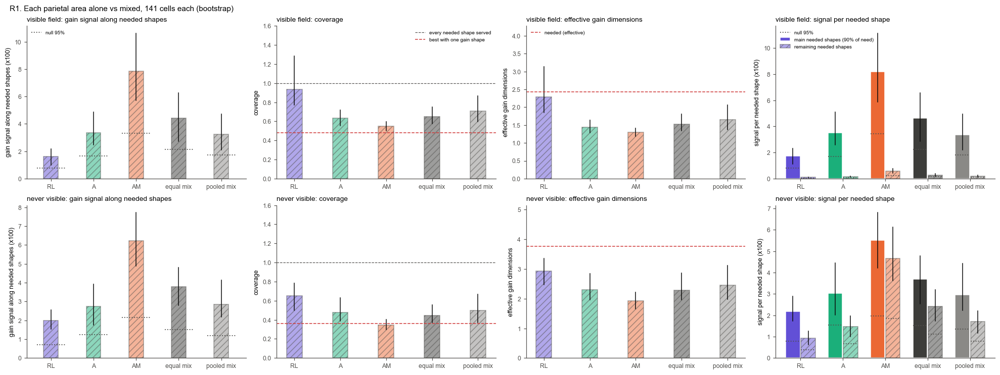

cells  main_x100  main_null95_x100  rest_x100  rest_null95_x100  need_x100  need_null95_x100  coverage  coverage_10  coverage_90  eff_dims  eff_dims_10  eff_dims_90  \
field         population                                                                                                                                                                         
visible field RL            141      1.720             0.799      0.104             0.043      1.607             0.768     0.937        0.771        1.286     2.294        1.850        3.136   
              A             141      3.502             1.712      0.147             0.071      3.350             1.644     0.633        0.556        0.716     1.446        1.281        1.637   
              AM            141      8.199             3.438      0.589             0.234      7.844             3.301     0.547        0.504        0.598     1.299        1.183        1.411   
              equal mix     141      4.622             2.220      0.276             0.147      4.438             2.134     0.651        0.574        0.748     1.524        1.339        1.813   
              pooled mix    141      3.372             1.804      0.181             0.094      3.227             1.734     0.706        0.595        0.866     1.648        1.375        2.060   
never visible RL            141      2.184             0.792      0.936             0.379      2.002             0.713     0.651        0.496        0.785     2.925        2.469        3.363   
              A             141      3.040             1.542      1.463             0.659      2.751             1.235     0.480        0.389        0.631     2.305        1.956        2.842   
              AM            141      5.522             1.974      4.654             1.838      6.214             2.145     0.346        0.298        0.404     1.920        1.661        2.209   
              equal mix     141      3.696             1.510      2.409             1.114      3.781             1.502     0.444        0.370        0.554     2.277        1.953        2.868   
              pooled mix    141      2.965             1.360      1.702             0.777      2.838             1.193     0.497        0.372        0.667     2.461        1.979        3.120   

                          eff_dims_needed  one_shape_coverage  
field         population                                       
visible field RL                    2.428               0.478  
              A                     2.428               0.478  
              AM                    2.428               0.478  
              equal mix             2.428               0.478  
              pooled mix            2.428               0.478  
never visible RL                    3.772               0.361  
              A                     3.772               0.361  
              AM                    3.772               0.361  
              equal mix             3.772               0.361  
              pooled mix            3.772               0.361

P(mix > RL)  P(mix > A)  P(mix > AM)
field         mix        measure                                       
visible field equal mix  need             0.98        0.74         0.08
                         coverage         0.03        0.59         0.92
                         eff_dims         0.03        0.66         0.89
              pooled mix need             0.94        0.47         0.02
                         coverage         0.10        0.74         0.95
                         eff_dims         0.09        0.77         0.93
never visible equal mix  need             0.97        0.78         0.03
                         coverage         0.08        0.39         0.88
                         eff_dims         0.13        0.49         0.87
              pooled mix need             0.88        0.55         0.01
                         coverage         0.18        0.52         0.91
                         eff_dims         0.22        0.58         0.87

In [190]:
if len(QC):
    R_ITEM2, R_ITEM3, R_ITEM3_ALL, R_N3 = r_populations(QC)
    R1RES, R1T = r_gain_figure(R_ITEM2, 'R1. Each parietal area alone vs mixed, {} cells each (bootstrap)'.format(Q_N),
                               'R1_parietal_mix_gain')
    rows = []
    for lab in ('visible field', 'never visible'):
        for mix in ('equal mix', 'pooled mix'):
            for key in ('need', 'coverage', 'eff_dims'):
                row = {'field': lab, 'mix': mix, 'measure': key}
                for a in R_PARIETAL:
                    row['P(mix > {})'.format(a)] = p_greater(R1RES[(lab, mix)][key], R1RES[(lab, a)][key])
                rows.append(row)
    display(R1T.round(3))
    display(pd.DataFrame(rows).set_index(['field', 'mix', 'measure']).round(2))

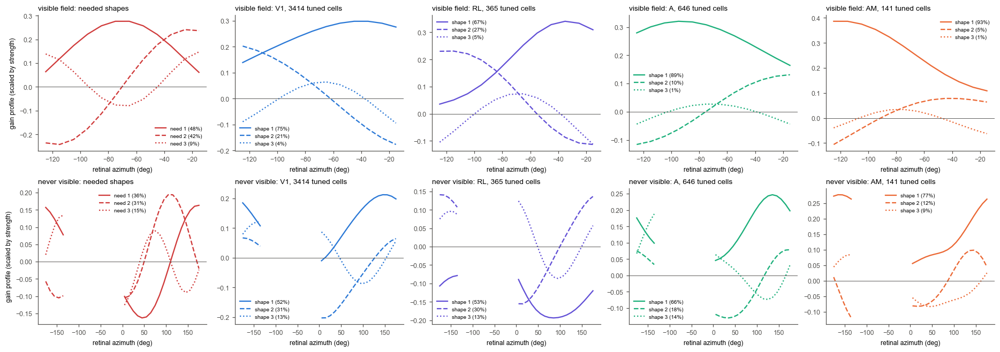

abs_cos_leading_shapes  boot_10  boot_90
field         pair                                                          
visible field V1 (self, stability)                    1.00     0.99     1.00
              V1-RL                                   0.95     0.85     1.00
              V1-A                                    0.94     0.90     0.97
              V1-AM                                   0.84     0.78     0.90
              RL (self, stability)                    1.00     0.95     1.00
              RL-A                                    0.80     0.64     0.91
              RL-AM                                   0.65     0.45     0.78
              A (self, stability)                     1.00     1.00     1.00
              A-AM                                    0.97     0.94     0.99
              AM (self, stability)                    1.00     0.99     1.00
never visible V1 (self, stability)                    1.00     0.99     1.00
              V1-RL                                   0.87     0.74     0.97
              V1-A                                    0.98     0.95     0.99
              V1-AM                                   0.93     0.88     0.95
              RL (self, stability)                    1.00     0.94     1.00
              RL-A                                    0.93     0.82     0.98
              RL-AM                                   0.79     0.65     0.90
              A (self, stability)                     1.00     0.99     1.00
              A-AM                                    0.90     0.83     0.94
              AM (self, stability)                    1.00     0.99     1.00

In [191]:
R2_AREAS = ('V1',) + tuple(R_PARIETAL)
R2_BOOT = 100
if len(QC):
    rng_r2 = np.random.default_rng(0)
    fig, axs = plt.subplots(2, len(R2_AREAS) + 1, figsize=(3.4 * (len(R2_AREAS) + 1), 6.0), squeeze=False)
    rows = []
    for ri, (cols, lab) in enumerate(((QVIS, 'visible field'), (~QVIS, 'never visible'))):
        U = expressible_basis(cols)
        x = Q_GRID[cols]
        o = np.argsort(x)
        gap = np.r_[False, np.diff(x[o]) > 15.0]
        brk = lambda y: np.where(gap, np.nan, 0.0) + y
        P, _ = needed_shapes(cols, 2.0)
        mu, V = np.linalg.eigh(P @ P.T)
        ax = axs[ri][0]
        for j, ls in zip((1, 2, 3), ('-', '--', ':')):
            ax.plot(x[o], brk((U @ V[:, -j])[o] * np.sqrt(mu[-j] / mu.sum())), color='#d03b3b', ls=ls, lw=1.5,
                    label='needed component {} ({:.0%})'.format(j, mu[-j] / mu.sum()))
        ax.set_title('{}: needed components'.format(lab), loc='left', fontsize=9)
        R_, N_ = QGP['real'][:, cols] @ U, QGP['null'][:, cols] @ U
        fin = np.all(np.isfinite(R_), 1) & np.all(np.isfinite(N_), 1)
        lead, boot = {}, {}
        for ci, a in enumerate(R2_AREAS):
            ax = axs[ri][ci + 1]
            ix = np.flatnonzero((QC['area'] == a).to_numpy() & fin)
            lead_of = lambda s: np.linalg.eigh((R_[s].T @ R_[s] - N_[s].T @ N_[s]) / len(s))[1][:, -1]
            C = (R_[ix].T @ R_[ix] - N_[ix].T @ N_[ix]) / len(ix)
            ev, EV = np.linalg.eigh(C)
            lead[a] = EV[:, -1]
            boot[a] = [lead_of(rng_r2.choice(ix, len(ix), replace=True)) for _ in range(R2_BOOT)]
            tot = ev[ev > 0].sum()
            for j, ls in zip((1, 2, 3), ('-', '--', ':')):
                v = EV[:, -j] * np.sign(EV[:, -j] @ V[:, -1] or 1.0)
                ax.plot(x[o], brk((U @ v)[o] * np.sqrt(max(ev[-j], 0) / tot)), color=acol(a), ls=ls, lw=1.5,
                        label='gain component {} ({:.0%})'.format(j, max(ev[-j], 0) / tot))
            ax.set_title('{}: {}, {} tuned cells'.format(lab, a, len(ix)), loc='left', fontsize=9)
        for i1 in range(len(R2_AREAS)):
            for i2 in range(i1, len(R2_AREAS)):
                a1, a2 = R2_AREAS[i1], R2_AREAS[i2]
                b = [abs(u @ w) for u, w in zip(boot[a1], boot[a2] if a1 != a2 else [lead[a1]] * R2_BOOT)]
                rows.append({'field': lab, 'pair': '{}-{}'.format(a1, a2) if a1 != a2 else '{} (self, stability)'.format(a1),
                             'abs_cos_leading_shapes': float(abs(lead[a1] @ lead[a2])),
                             'boot_10': float(np.percentile(b, 10)), 'boot_90': float(np.percentile(b, 90))})
        for ax in axs[ri]:
            ax.axhline(0, color=INK2, lw=0.6)
            ax.set_xlabel('retinal azimuth (deg)', fontsize=8)
            ax.legend(fontsize=6.5, frameon=False)
            style(ax)
    axs[0][0].set_ylabel('gain profile (scaled by strength)', fontsize=8)
    axs[1][0].set_ylabel('gain profile (scaled by strength)', fontsize=8)
    show(fig, 'R2_gain_shapes')
    display(pd.DataFrame(rows).set_index(['field', 'pair']).round(2))

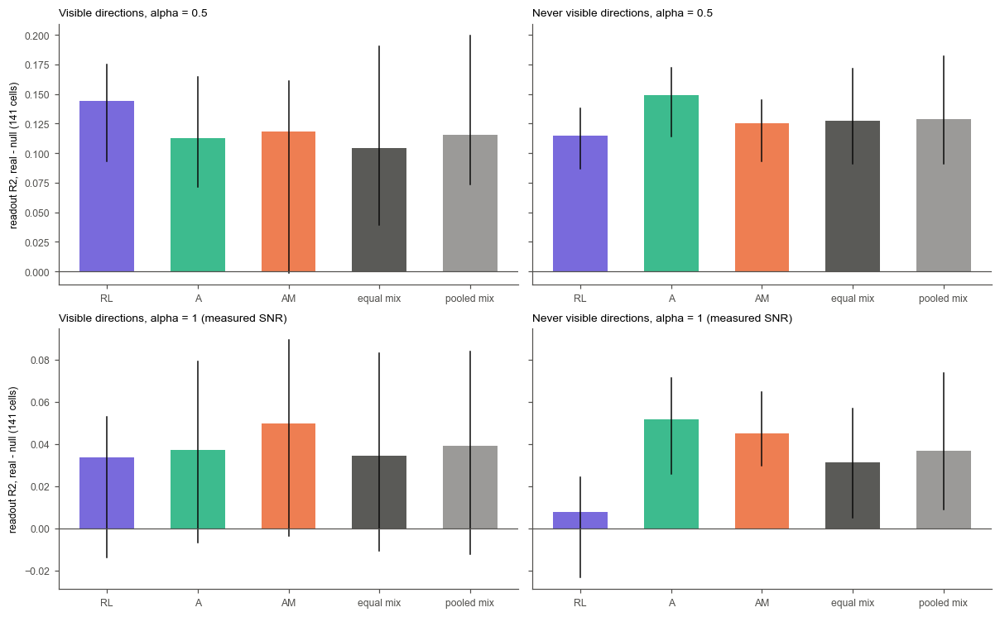

real_minus_null    p10    p90
alpha field         population                               
0.5   visible       RL                    0.144  0.093  0.175
                    A                     0.112  0.071  0.165
                    AM                    0.118 -0.001  0.161
                    equal mix             0.105  0.039  0.190
                    pooled mix            0.116  0.074  0.200
      never visible RL                    0.115  0.087  0.138
                    A                     0.149  0.114  0.172
                    AM                    0.126  0.093  0.145
                    equal mix             0.127  0.091  0.172
                    pooled mix            0.129  0.091  0.182
1.0   visible       RL                    0.034 -0.014  0.053
                    A                     0.037 -0.007  0.079
                    AM                    0.050 -0.004  0.089
                    equal mix             0.034 -0.011  0.083
                    pooled mix            0.039 -0.012  0.084
      never visible RL                    0.008 -0.023  0.024
                    A                     0.052  0.026  0.071
                    AM                    0.045  0.030  0.065
                    equal mix             0.031  0.005  0.057
                    pooled mix            0.037  0.009  0.074

P(mix > RL)  P(mix > A)  P(mix > AM)
alpha field         mix                                             
0.5   visible       equal mix          0.38        0.50         0.57
                    pooled mix         0.40        0.57         0.58
      never visible equal mix          0.63        0.28         0.57
                    pooled mix         0.68        0.42         0.63
1.0   visible       equal mix          0.59        0.50         0.42
                    pooled mix         0.60        0.48         0.41
      never visible equal mix          0.83        0.27         0.30
                    pooled mix         0.85        0.35         0.36

In [192]:
if R_COLS:
    pops = list(R_ITEM2)
    al_ = list(R_ALPHAS)
    fig, axs = plt.subplots(len(al_), 2, figsize=(11, 3.4 * len(al_)), sharey='row', squeeze=False)
    rows, draws = [], {}
    for ai, al in enumerate(al_):
        for ci, vlab in enumerate(('visible', 'never visible')):
            ax = axs[ai][ci]
            for i, p in enumerate(pops):
                rs = [(R_COLS[k], Q_COLS[(k[0], 'AM')]) for k in R_COLS if k[1] == 'item2' and k[2] == p]
                if not rs:
                    continue
                d = []
                for r, q in rs:
                    vis = q['in_view'] >= Q_VIEW_MIN
                    vm = vis if vlab == 'visible' else ~vis
                    d.append((r['r2'][0, ai][:, vm] - np.maximum(r['r2'][1, ai][:, vm], 0.0)).mean(1))
                d = np.concatenate(d)
                draws[(al, vlab, p)] = d
                ax.bar(i, np.median(d), width=0.6, color=rpcol(p), alpha=0.85)
                ax.plot([i, i], np.percentile(d, [10, 90]), color=INK, lw=1)
                rows.append({'alpha': al, 'field': vlab, 'population': p, 'real_minus_null': np.median(d),
                             'p10': np.percentile(d, 10), 'p90': np.percentile(d, 90)})
            ax.axhline(0, color=INK2, lw=0.8)
            ax.set_xticks(range(len(pops)))
            ax.set_xticklabels(pops, fontsize=8)
            ax.set_title('{} directions, alpha = {:g}{}'.format(vlab.capitalize(), al, ' (measured SNR)' if al == 1 else ''),
                         loc='left', fontsize=9)
            style(ax)
        axs[ai][0].set_ylabel('readout R2, real - null ({} cells)'.format(Q_N), fontsize=8)
    show(fig, 'R3_parietal_mix_readout')
    display(pd.DataFrame(rows).set_index(['alpha', 'field', 'population']).round(3))
    comp = []
    for (al, vlab, p), d in draws.items():
        if p.endswith('mix'):
            comp.append({'alpha': al, 'field': vlab, 'mix': p,
                         **{'P(mix > {})'.format(a): p_greater(d, draws.get((al, vlab, a), [])) for a in R_PARIETAL}})
    display(pd.DataFrame(comp).set_index(['alpha', 'field', 'mix']).round(2))

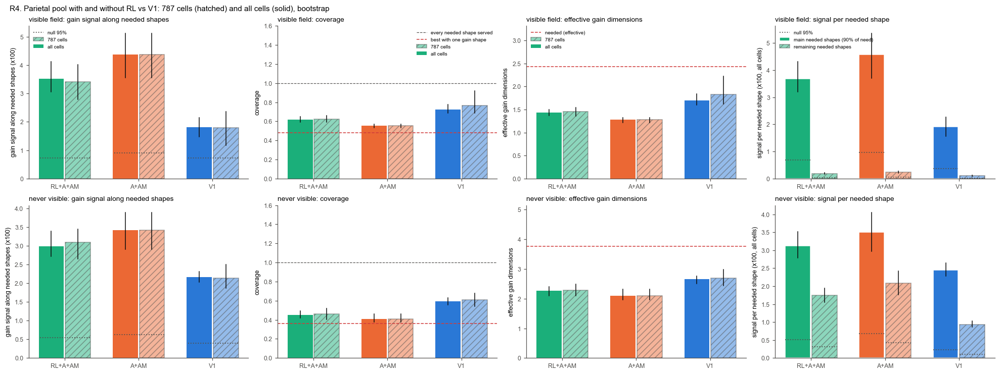

cells  main_x100  main_null95_x100  rest_x100  rest_null95_x100  need_x100  need_null95_x100  coverage  coverage_10  coverage_90  eff_dims  eff_dims_10  eff_dims_90  \
field         population                                                                                                                                                                         
visible field RL+A+AM       787      3.694             0.682      0.192             0.037      3.403             0.735     0.626        0.593        0.660     1.458        1.360        1.539   
              A+AM          787      4.570             0.960      0.238             0.055      4.366             0.908     0.553        0.533        0.572     1.276        1.219        1.326   
              V1            787      1.924             0.373      0.110             0.016      1.785             0.725     0.766        0.688        0.917     1.824        1.614        2.221   
never visible RL+A+AM       787      3.127             0.504      1.753             0.308      3.094             0.543     0.460        0.405        0.518     2.288        2.092        2.495   
              A+AM          787      3.499             0.674      2.082             0.420      3.424             0.619     0.411        0.377        0.463     2.103        1.953        2.312   
              V1            787      2.457             0.232      0.932             0.104      2.139             0.394     0.612        0.540        0.680     2.692        2.431        2.990   

                          eff_dims_needed  one_shape_coverage  
field         population                                       
visible field RL+A+AM               2.428               0.478  
              A+AM                  2.428               0.478  
              V1                    2.428               0.478  
never visible RL+A+AM               3.772               0.361  
              A+AM                  3.772               0.361  
              V1                    3.772               0.361

P(RL+A+AM > V1)  P(A+AM > V1)  P(RL+A+AM > A+AM)
field         measure                                                   
visible field need                 0.99          1.00               0.10
              coverage             0.02          0.00               0.98
              eff_dims             0.01          0.00               0.98
never visible need                 0.98          1.00               0.22
              coverage             0.02          0.00               0.79
              eff_dims             0.05          0.01               0.78

In [193]:
if len(QC):
    R4RES, R4T = r_gain_figure(R_ITEM3, 'R4. Parietal pool with and without RL vs V1: {} cells (hatched) and all cells '
                               '(solid), bootstrap'.format(R_N3), 'R4_parietal_pool_gain', pops_all=R_ITEM3_ALL)
    display(R4T.round(3))
    rows = []
    for lab in ('visible field', 'never visible'):
        for key in ('need', 'coverage', 'eff_dims'):
            rows.append({'field': lab, 'measure': key,
                         'P(RL+A+AM > V1)': p_greater(R4RES[(lab, 'RL+A+AM')][key], R4RES[(lab, 'V1')][key]),
                         'P(A+AM > V1)': p_greater(R4RES[(lab, 'A+AM')][key], R4RES[(lab, 'V1')][key]),
                         'P(RL+A+AM > A+AM)': p_greater(R4RES[(lab, 'RL+A+AM')][key], R4RES[(lab, 'A+AM')][key])})
    display(pd.DataFrame(rows).set_index(['field', 'measure']).round(2))

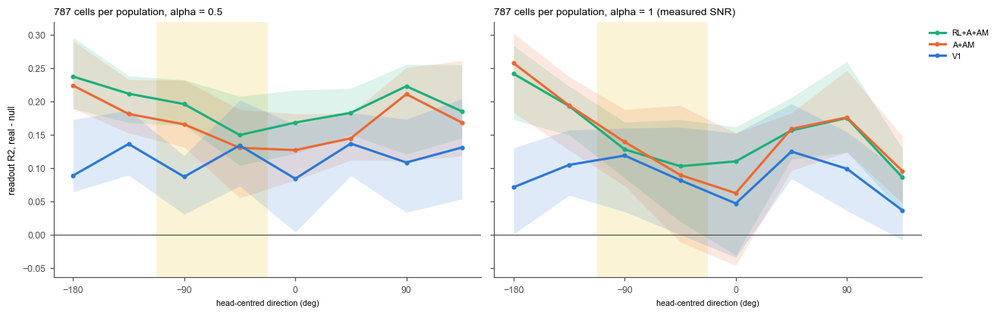

directions  consistent_directions  mean_real_minus_null    p10    p90
alpha field         population                                                                       
0.5   visible       RL+A+AM              2                      2                 0.177  0.147  0.197
      never visible RL+A+AM              6                      6                 0.202  0.174  0.221
      visible       A+AM                 2                      2                 0.147  0.105  0.201
      never visible A+AM                 6                      6                 0.179  0.137  0.204
      visible       V1                   2                      2                 0.116  0.078  0.151
      never visible V1                   6                      5                 0.110  0.085  0.147
1.0   visible       RL+A+AM              2                      2                 0.112  0.067  0.171
      never visible RL+A+AM              6                      5                 0.155  0.133  0.176
      visible       A+AM                 2                      1                 0.101  0.045  0.186
      never visible A+AM                 6                      5                 0.157  0.120  0.186
      visible       V1                   2                      1                 0.084  0.067  0.137
      never visible V1                   6                      3                 0.080  0.053  0.113

P(RL+A+AM > V1)  P(A+AM > V1)  P(RL+A+AM > A+AM)
alpha field                                                          
0.5   visible                   0.90          0.75               0.73
      never visible             0.93          0.88               0.76
1.0   visible                   0.60          0.56               0.51
      never visible             0.97          0.94               0.49

In [194]:
if R_COLS:
    pops = list(R_ITEM3)
    al_ = list(R_ALPHAS)
    fig, axs = plt.subplots(1, len(al_), figsize=(6.0 * len(al_), 3.8), sharey=True, squeeze=False)
    rows, draws = [], {}
    for ai, al in enumerate(al_):
        ax = axs[0][ai]
        for p in pops:
            ks = [k for k in R_COLS if k[1] == 'item3' and k[2] == p]
            if not ks:
                continue
            c = R_COLS[ks[0]]['centers']
            o = np.argsort(c)
            vis = np.nanmean([R_COLS[k]['in_view'] for k in ks], 0) >= Q_VIEW_MIN
            dif = np.concatenate([R_COLS[k]['r2'][0, ai] - np.maximum(R_COLS[k]['r2'][1, ai], 0.0) for k in ks], 0)
            lo, med, hi = np.percentile(dif, [10, 50, 90], axis=0)
            ax.fill_between(c[o], lo[o], hi[o], color=rpcol(p), alpha=0.15, lw=0)
            ax.plot(c[o], med[o], color=rpcol(p), lw=2, marker='o', ms=3, label=p)
            fp = np.mean(dif > 0, 0)
            for vlab, vm in (('visible', vis), ('never visible', ~vis)):
                d = dif[:, vm].mean(1)
                draws[(al, vlab, p)] = d
                rows.append({'alpha': al, 'field': vlab, 'population': p, 'directions': int(vm.sum()),
                             'consistent_directions': int(np.sum(fp[vm] >= Q6_CONSISTENT)),
                             'mean_real_minus_null': float(np.median(d)), 'p10': float(np.percentile(d, 10)),
                             'p90': float(np.percentile(d, 90))})
        for j in np.flatnonzero(vis):
            ax.axvspan(c[j] - 22.5, c[j] + 22.5, color='#fbf3d5', lw=0, zorder=0)
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_xticks([-180, -90, 0, 90])
        ax.set_xlabel('head-centred direction (deg)')
        ax.set_title('{} cells per population, alpha = {:g}{}'.format(R_N3, al, ' (measured SNR)' if al == 1 else ''),
                     loc='left', fontsize=9)
        style(ax)
    axs[0][0].set_ylabel('readout R2, real - null', fontsize=8)
    axs[0][-1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'R5_parietal_pool_readout')
    display(pd.DataFrame(rows).set_index(['alpha', 'field', 'population']).round(3))
    comp = []
    for al in al_:
        for vlab in ('visible', 'never visible'):
            g = lambda p: draws.get((al, vlab, p), [])
            comp.append({'alpha': al, 'field': vlab, 'P(RL+A+AM > V1)': p_greater(g('RL+A+AM'), g('V1')),
                         'P(A+AM > V1)': p_greater(g('A+AM'), g('V1')),
                         'P(RL+A+AM > A+AM)': p_greater(g('RL+A+AM'), g('A+AM'))})
    display(pd.DataFrame(comp).set_index(['alpha', 'field']).round(2))

In [195]:
FRAME_SIM_DRAWS = 10
FRAME_SIM_GENS = ('ADD', 'GAIN', 'HEAD')


def frame_calls(f):
    tuned = beats(f['RET'], f['NUIS']) | beats(f['HEAD'], f['NUIS'])
    return tuned, tuned & beats(f['HEAD'], f['ADD']), tuned & beats(f['ADD'], f['HEAD'])


def frame_sim(R, n_draws, gens=FRAME_SIM_GENS, seed=0):
    D = R['D']
    use, mz, base, gain = gain_designs(D, D['light'] & D['use'])
    idx = np.flatnonzero(use)
    if len(idx) < 3 * NULL_MIN_SHIFT:
        return None
    designs = dict(base, GAIN=gain(mz))
    folds = na._folds(D, use)
    fits = {k: na._cv(X, D['Y'], folds) for k, X in designs.items()}
    tuned, head, eye = frame_calls(fits)
    C = D['Y'].shape[1]
    out = {'tuned': tuned, 'head': head, 'eye': eye, 'd_real': fits['HEAD']['r2'] - fits['ADD']['r2'],
           'stored_tuned': R['stored']['tuned']}
    rng = np.random.default_rng(seed)
    for g in gens:
        X = designs[g]
        P = predict(full_fit(X, D['Y'], use, fits[g]['lam']), X[idx])
        res = D['Y'][idx] - P
        calls = {k: np.zeros((n_draws, C), bool) for k in ('tuned', 'head', 'eye')}
        d_sim = np.full((n_draws, C), np.nan)
        for k in range(n_draws):
            Ys = D['Y'].copy()
            Ys[idx] = P + np.roll(res, int(rng.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT)), axis=0)
            fs = {m: na._cv(base[m], Ys, folds) for m in ('NUIS', 'RET', 'ADD', 'HEAD')}
            calls['tuned'][k], calls['head'][k], calls['eye'][k] = frame_calls(fs)
            d_sim[k] = fs['HEAD']['r2'] - fs['ADD']['r2']
        out.update({'{}_{}'.format(g, k): v for k, v in calls.items()})
        out[g + '_d'] = d_sim
    return out


FS = {}
if not RUN_REFITS:
    print('RUN_REFITS is off -- section S is skipped.')
elif not restore('S'):
    t_all = time.time()
    for i, s in SES.iterrows():
        def run_frame_sim():
            R, why = rebuild_session(s)
            return None if R is None else frame_sim(R, FRAME_SIM_DRAWS)
        t0 = time.time()
        r = cached(s, 'framesim', {'draws': FRAME_SIM_DRAWS, 'gens': list(FRAME_SIM_GENS), 'v': 1}, run_frame_sim)
        if r is not None:
            FS[s['session']] = r
        if time.time() - t0 > 1:
            print('[{}/{}] {}: {:.0f} s'.format(i + 1, len(SES), s['session'], time.time() - t0))
    print('Frame simulations: {} sessions in {:.1f} min.'.format(len(FS), (time.time() - t_all) / 60))
    stash('S', FS=FS)

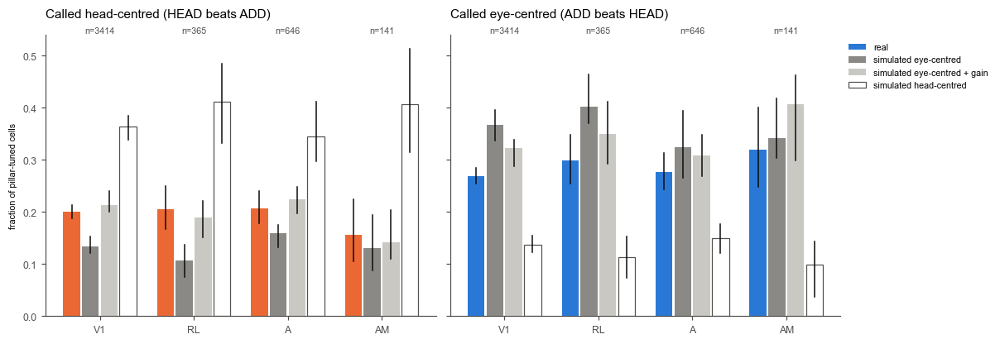

,tuned,real_head,null_head,gain_head,hit_head,p_head,real_eye,null_eye,gain_eye,hit_eye,p_eye,pi_head_from_head,pi_head_from_eye,p_head_vs_gain,pi_head_from_head_gain,pi_head_from_eye_gain,sim_tuned_frac
V1,3414.0,0.200,0.134,0.214,0.363,0.000,0.269,0.136,0.322,0.367,0.0,0.288,0.424,0.977,-0.092,0.284,0.658
RL,365.0,0.205,0.106,0.189,0.412,0.000,0.299,0.113,0.349,0.402,0.0,0.325,0.358,0.232,0.073,0.213,0.720
A,646.0,0.207,0.159,0.224,0.346,0.001,0.277,0.149,0.309,0.325,0.0,0.258,0.272,0.858,-0.138,0.199,0.568
AM,141.0,0.156,0.131,0.142,0.407,0.222,0.319,0.098,0.407,0.341,0.0,0.090,0.091,0.347,0.054,0.285,0.706


In [196]:
from scipy.stats import binomtest


def sim_rates(sel_area):
    out = {'n': 0, 'real': {'head': 0, 'eye': 0}, 'sim': {}}
    num = {(g, c): np.zeros(FRAME_SIM_DRAWS) for g in FRAME_SIM_GENS for c in ('head', 'eye')}
    den = {g: np.zeros(FRAME_SIM_DRAWS) for g in FRAME_SIM_GENS}
    for sess, r in FS.items():
        cs = CELLS[CELLS['session'] == sess]
        a = np.full(len(r['tuned']), '', dtype=object)
        a[cs['cell'].to_numpy(int)] = cs['area'].to_numpy()
        m = r['tuned'].astype(bool) & (a == sel_area)
        out['n'] += int(m.sum())
        for c in ('head', 'eye'):
            out['real'][c] += int((r[c].astype(bool) & m).sum())
        for g in FRAME_SIM_GENS:
            t = r[g + '_tuned'].astype(bool) & m[None]
            den[g] += t.sum(1)
            for c in ('head', 'eye'):
                num[(g, c)] += (r['{}_{}'.format(g, c)].astype(bool) & t).sum(1)
    out['sim'] = {k: v / np.maximum(den[k[0]], 1) for k, v in num.items()}
    out['den'] = den
    return out


S_RATES = {a: sim_rates(a) for a in AREAS if a != 'PM'} if FS else {}
if S_RATES:
    if not all(np.array_equal(r['tuned'], r['stored_tuned']) for r in FS.values()):
        print('Note: refit tuned calls differ from the stored C4 calls in some sessions.')
    areas = list(S_RATES)
    bars = [('real', None), ('simulated eye-centered', 'ADD'), ('simulated eye-centered + gain', 'GAIN'),
            ('simulated head-centered', 'HEAD')]
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    w = 0.2
    for ax, c, col, ttl in ((axs[0], 'head', '#eb6834', 'Called head-centered (HEAD beats ADD)'),
                            (axs[1], 'eye', '#2a78d6', 'Called eye-centered (ADD beats HEAD)')):
        for i, a in enumerate(areas):
            S = S_RATES[a]
            for j, (lab, g) in enumerate(bars):
                x = i + (j - 1.5) * w
                if g is None:
                    y = S['real'][c] / max(S['n'], 1)
                    lo, hi = frac_ci(S['real'][c], S['n'])
                    kw = dict(color=col)
                else:
                    v = S['sim'][(g, c)]
                    y, (lo, hi) = v.mean(), np.percentile(v, [2.5, 97.5])
                    kw = {'ADD': dict(color='#8a8986'), 'GAIN': dict(color='#c9c8c2'),
                          'HEAD': dict(color='white', edgecolor=INK2, lw=0.8)}[g]
                ax.bar(x, y, width=w * 0.9, label=lab if i == 0 else None, **kw)
                ax.plot([x, x], [lo, hi], color=INK, lw=1)
            ax.text(i, 1.0, 'n={}'.format(S['n']), transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                    fontsize=7, color=INK2)
        ax.set_xticks(range(len(areas)))
        ax.set_xticklabels(areas)
        ax.set_title(ttl, loc='left', fontsize=10, pad=14)
        style(ax)
    axs[0].set_ylabel('fraction of pillar-tuned cells')
    axs[1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'S1_frame_call_nulls')

    rows = {}
    for a in areas:
        S = S_RATES[a]
        n = S['n']
        rh, re_ = S['real']['head'] / n, S['real']['eye'] / n
        null_h, hit_h = S['sim'][('ADD', 'head')].mean(), S['sim'][('HEAD', 'head')].mean()
        null_e, hit_e = S['sim'][('HEAD', 'eye')].mean(), S['sim'][('ADD', 'eye')].mean()
        gain_h, gain_e = S['sim'][('GAIN', 'head')].mean(), S['sim'][('GAIN', 'eye')].mean()
        rows[a] = {'tuned': n,
                   'real_head': rh, 'null_head': null_h, 'gain_head': gain_h,
                   'hit_head': hit_h,
                   'p_head': binomtest(S['real']['head'], n, null_h, alternative='greater').pvalue,
                   'real_eye': re_, 'null_eye': null_e, 'gain_eye': gain_e, 'hit_eye': hit_e,
                   'p_eye': binomtest(S['real']['eye'], n, null_e, alternative='greater').pvalue,
                   'pi_head_from_head': (rh - null_h) / (hit_h - null_h) if hit_h != null_h else np.nan,
                   'pi_head_from_eye': (hit_e - re_) / (hit_e - null_e) if hit_e != null_e else np.nan,
                   'p_head_vs_gain': binomtest(S['real']['head'], n, gain_h, alternative='greater').pvalue,
                   'pi_head_from_head_gain': (rh - gain_h) / (hit_h - gain_h) if hit_h != gain_h else np.nan,
                   'pi_head_from_eye_gain': (gain_e - re_) / (gain_e - null_e) if gain_e != null_e else np.nan,
                   'sim_tuned_frac': np.mean([S['den'][g].mean() for g in FRAME_SIM_GENS]) / max(n, 1)}
    S1T = pd.DataFrame(rows).T
    display(S1T.astype(float).round(3))

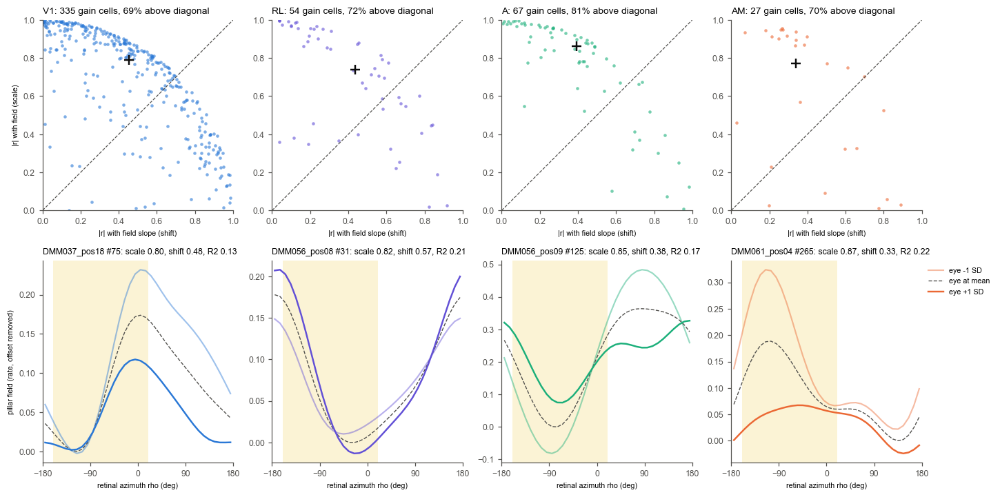

In [197]:
if len(QC):
    path_of = SES.set_index('session')['path']
    gm_store = {}

    def stored_gain_model(sess):
        if sess not in gm_store:
            with h5py.File(path_of[sess], 'r') as f:
                gm = {k: f['gain_model'][k][()] for k in f['gain_model'].keys()}
            gm['nuis_names'] = L_(gm['nuis_names'])
            gm_store[sess] = gm
        return gm_store[sess]

    def stored_gain_r2(sess):
        if ('r2', sess) not in gm_store:
            with h5py.File(path_of[sess], 'r') as f:
                gm_store[('r2', sess)] = f['refframe']['eye_models']['r2_GAIN'][()]
        return gm_store[('r2', sess)]

    fig, axs = plt.subplots(2, len(Q_AREAS), figsize=(3.3 * len(Q_AREAS), 6.6), squeeze=False)
    for j, a in enumerate(Q_AREAS):
        pos = np.flatnonzero(((QC['area'] == a) & QC['gain_cell'].astype(bool)
                              & QC['mult_r'].notna() & QC['shift_r'].notna()).to_numpy())
        xs = np.abs(QC['shift_r'].to_numpy(float)[pos])
        ys = np.abs(QC['mult_r'].to_numpy(float)[pos])
        ax = axs[0][j]
        ax.plot([0, 1], [0, 1], color=INK2, lw=0.8, ls='--')
        ax.scatter(xs, ys, s=9, color=acol(a), alpha=0.6, lw=0)
        if len(pos):
            ax.scatter([np.median(xs)], [np.median(ys)], s=80, marker='+', color=INK, lw=1.6, zorder=3)
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_xlabel('|r| with field slope (shift)')
        ax.set_title('{}: {} gain cells, {:.0%} above diagonal'.format(
            a, len(pos), np.mean(ys > xs) if len(pos) else np.nan), loc='left', fontsize=9)
        style(ax, grid_y=False)

        ax = axs[1][j]
        ax.axvspan(-160, 20, color='#fbf3d5', lw=0)
        ax.set_xlim(-180, 180)
        ax.set_xticks([-180, -90, 0, 90, 180])
        ax.set_xlabel('retinal azimuth rho (deg)')
        style(ax)
        if not len(pos):
            continue
        margin = ys - xs
        fit = np.array([stored_gain_r2(s_)[c_] for s_, c_ in
                        zip(QC['session'].to_numpy()[pos], QC['cell'].to_numpy(int)[pos])])
        good = np.flatnonzero(fit >= np.nanmedian(fit))
        k = good[np.argmin(np.abs(margin[good] - np.median(margin)))]
        i = pos[k]
        r = QC.iloc[i]
        f, g = field_and_gain(stored_gain_model(r['session']))
        samp = np.asarray(QSAMP[i], bool)
        f = np.where(samp, f[:, int(r['cell'])], np.nan)
        g = np.where(samp, g[:, int(r['cell'])], np.nan)
        f, g = f - np.nanmin(f), g
        ax.plot(Q_GRID, f - g, color=acol(a), lw=1.4, alpha=0.45, label='eye -1 SD')
        ax.plot(Q_GRID, f, color=INK2, lw=0.9, ls='--', label='eye at mean')
        ax.plot(Q_GRID, f + g, color=acol(a), lw=1.6, label='eye +1 SD')
        ax.set_title('{} #{}: scale {:.2f}, shift {:.2f}, R2 {:.2f}'.format(
            r['session'].split('_DMM_')[-1], int(r['cell']), abs(r['mult_r']), abs(r['shift_r']), fit[k]),
            loc='left', fontsize=8)
    axs[0][0].set_ylabel('|r| with field (scale)')
    axs[1][0].set_ylabel('pillar field (rate, offset removed)')
    axs[1][-1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'T1_scale_vs_shift')

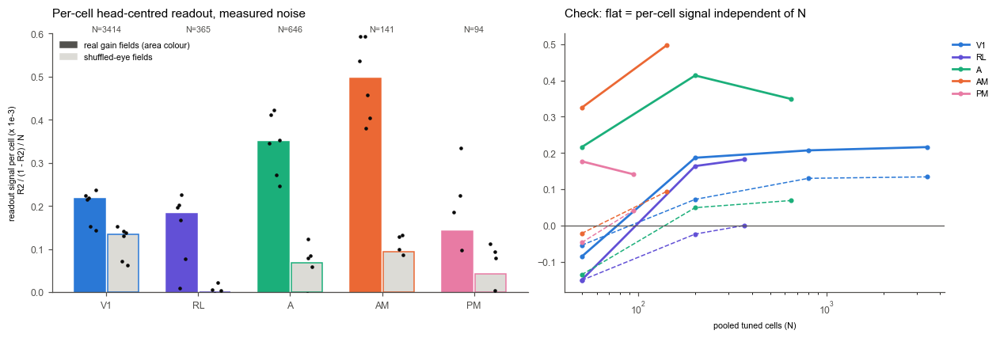

,N,real,null,real_minus_null,real_over_null
V1,3414.0,0.216,0.134,0.082,1.613
RL,365.0,0.182,0.000,0.182,NaN
A,646.0,0.349,0.069,0.280,5.077
AM,141.0,0.497,0.094,0.403,5.315
PM,94.0,0.141,0.042,0.100,3.402


In [198]:
if POOL:
    d = POOLT[POOLT['alpha'] == 1.0].copy()
    d['snr'] = d['r2'] / (1.0 - d['r2']) / d['N'] * 1e3
    areas_ = [a for a in AREAS if (d['area'] == a).any()]
    jit = np.random.default_rng(1)
    fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={'width_ratios': [1.25, 1]})
    ax = axs[0]
    tab = {}
    for i, a in enumerate(areas_):
        top = d[(d['area'] == a) & (d['N'] == d['n_all'])]
        for kind, x in (('real', i - 0.18), ('null', i + 0.18)):
            v = top.loc[top['kind'] == kind, 'snr'].to_numpy()
            ax.bar(x, np.median(v), width=0.34, color=acol(a) if kind == 'real' else '#dcdbd6',
                   edgecolor=acol(a), lw=1)
            ax.scatter(x + jit.uniform(-0.07, 0.07, len(v)), v, s=9, color=INK, zorder=3, lw=0)
            tab.setdefault(a, {'N': int(top['n_all'].iloc[0])})[kind] = np.median(v)
        ax.text(i, 1.0, 'N={}'.format(tab[a]['N']), transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                fontsize=7, color=INK2)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(len(areas_)))
    ax.set_xticklabels(areas_)
    ax.set_ylim([0,0.6])
    ax.set_ylabel('readout signal per cell (x 1e-3)\nR2 / (1 - R2) / N')
    ax.set_title('Per-cell head-centered readout, measured noise', loc='left', fontsize=10, pad=14)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=INK2), plt.Rectangle((0, 0), 1, 1, color='#dcdbd6')],
              labels=['real gain fields (area color)', 'shuffled-eye fields'], fontsize=7, frameon=False, loc='upper left')
    style(ax)
    ax = axs[1]
    for a in areas_:
        da = d[d['area'] == a]
        for kind, ls in (('real', '-'), ('null', '--')):
            med = da[da['kind'] == kind].groupby('N')['snr'].median()
            ax.plot(med.index, med.to_numpy(), ls=ls, color=acol(a), lw=1.8 if kind == 'real' else 1.0, marker='o', ms=3,
                    label=a if kind == 'real' else None)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xscale('log')
    ax.set_xlabel('pooled tuned cells (N)')
    ax.set_title('Check: flat = per-cell signal independent of N', loc='left', fontsize=10, pad=14)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax)
    show(fig, 'U1_readout_per_cell')
    tab = pd.DataFrame(tab).T
    tab['real_minus_null'] = tab['real'] - tab['null']
    tab['real_over_null'] = tab['real'] / tab['null'].where(tab['null'] > 0.02)
    display(tab.round(3))

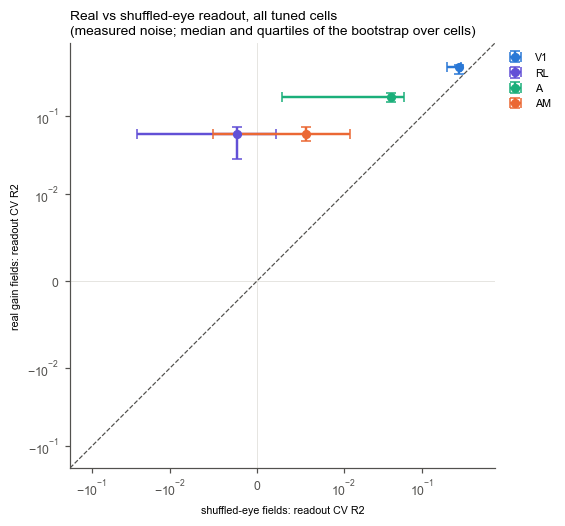

,draws,real_mean,real_lo,real_hi,null_mean,null_lo,null_hi,real_q1,real_q3,null_q1,null_q3,frac_real_wins
V1,57.0,0.401,0.317,0.473,0.267,0.164,0.335,0.339,0.450,0.207,0.316,1.0
RL,60.0,0.049,-0.020,0.089,-0.010,-0.038,0.009,0.028,0.072,-0.026,0.002,1.0
A,59.0,0.172,0.115,0.222,0.033,-0.024,0.078,0.151,0.198,0.003,0.059,1.0
AM,60.0,0.059,0.027,0.095,0.003,-0.018,0.021,0.048,0.072,-0.005,0.012,1.0


In [199]:
N1C_BOOT = 20
N1C_AREAS = [a for a in AREAS if a != 'PM']


def pool_boot(D, donors, area, n_boot, alpha, nuisance, seed=0):
    m = frame_mask(D)
    idx = np.flatnonzero(m)
    L = len(idx)
    Dm, mm = {'t': D['t'][idx]}, np.ones(L, bool)
    T = head_specific_target(D, m)[idx]
    parts = [(d, np.flatnonzero(d['area'] == area)) for d in donors]
    parts = [(d, c) for d, c in parts if len(c)]
    if not parts:
        return None
    G = {kind: np.concatenate([gain_field_pred(D, dict(d['gm_' + kind], coef=d['gm_' + kind]['coef'][:, c],
                                                       y_mean=d['gm_' + kind]['y_mean'][c]), m, nuisance)
                               for d, c in parts], 1).astype(np.float32) for kind in ('real', 'null')}
    RES = {kind: [d['res_' + kind][:, c] for d, c in parts] for kind in ('real', 'null')}
    owner = np.concatenate([np.full(len(c), p) for p, (_, c) in enumerate(parts)])
    local = np.concatenate([np.arange(len(c)) for _, c in parts])
    n_rows = np.array([d['res_real'].shape[0] for d, _ in parts])
    n_all = len(owner)
    rng = np.random.default_rng(seed)
    r2 = np.full((2, n_boot), np.nan)
    for b in range(n_boot):
        sel = rng.integers(0, n_all, n_all)
        sh = rng.integers(NULL_MIN_SHIFT, n_rows[owner[sel]] - NULL_MIN_SHIFT)
        for ki, kind in enumerate(('real', 'null')):
            nz = np.empty((L, n_all), np.float32)
            for p in range(len(parts)):
                js = np.flatnonzero(owner[sel] == p)
                if len(js):
                    rows = (np.arange(L)[:, None] + sh[js][None, :]) % n_rows[p]
                    nz[:, js] = RES[kind][p][rows, local[sel[js]][None, :]]
            r2[ki, b] = max(readout_r2(Dm, G[kind][:, sel] + alpha * nz, T, mm), -1.0)
    return {'r2': r2, 'n_cells': n_all}


BOOT = {}
if POOL and not restore('U2'):
    t_all = time.time()
    for _, h in HOSTS.iterrows():
        D_h = load_covariates(h['path'])
        for a in N1C_AREAS:
            t0 = time.time()
            r = cached(h, 'poolboot_' + a, {'boot': N1C_BOOT, 'alpha': 1.0, 'nuis': POOL_NUISANCE, 'donors': POOL_SIG,
                                            'v': 1},
                       lambda: pool_boot(D_h, donors_once(), a, N1C_BOOT, 1.0, POOL_NUISANCE))
            if r is not None:
                BOOT[(h['session'], a)] = r
            if time.time() - t0 > 5:
                print('  {} x {}: {:.0f} s'.format(h['session'], a, time.time() - t0))
    print('U2 bootstrap: {} host x area in {:.1f} min.'.format(len(BOOT), (time.time() - t_all) / 60))
    stash('U2', BOOT=BOOT)

if BOOT:
    rows = [{'area': a, 'host': host, 'real': r['r2'][0, b], 'null': r['r2'][1, b]}
            for (host, a), r in BOOT.items() for b in range(r['r2'].shape[1])]
    BT = pd.DataFrame(rows)
    bad = (BT[['real', 'null']] <= -0.99).any(axis=1)
    if bad.any():
        print('Dropped {} of {} draws clipped at R2 = -1.'.format(int(bad.sum()), len(BT)))
    BT = BT[~bad]
    fig, ax = plt.subplots(figsize=(5.6, 4.8))
    vals = BT[['real', 'null']].to_numpy(float)
    lo = min(-0.02, np.nanmin(vals) * 1.8)
    hi = max(0.05, np.nanmax(vals) * 1.8)
    xx = np.linspace(lo, hi, 2000)
    ax.plot(xx, xx, color=INK2, lw=0.8, ls='--')
    ax.axhline(0, color=GRID, lw=0.6, zorder=0)
    ax.axvline(0, color=GRID, lw=0.6, zorder=0)
    tab = {}
    for a in N1C_AREAS:
        da = BT[BT['area'] == a]
        if not len(da):
            continue
        r, n = da['real'].to_numpy(float), da['null'].to_numpy(float)
        (nq1, xm, nq3), (rq1, ym, rq3) = np.percentile(n, [25, 50, 75]), np.percentile(r, [25, 50, 75])
        ax.errorbar(xm, ym, xerr=[[xm - nq1], [nq3 - xm]], yerr=[[ym - rq1], [rq3 - ym]], fmt='o', ms=5, color=acol(a),
                    elinewidth=1.6, capsize=3, zorder=3, label=a)
        (nl, nh), (rl, rh) = np.percentile(n, [2.5, 97.5]), np.percentile(r, [2.5, 97.5])
        tab[a] = {'draws': len(da), 'real_mean': np.mean(r), 'real_lo': rl, 'real_hi': rh, 'null_mean': np.mean(n),
                  'null_lo': nl, 'null_hi': nh, 'real_q1': rq1, 'real_q3': rq3, 'null_q1': nq1, 'null_q3': nq3,
                  'frac_real_wins': np.mean(r > n)}
    ax.set_xscale('symlog', linthresh=0.01)
    ax.set_yscale('symlog', linthresh=0.01)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal')
    ax.set_xlabel('shuffled-eye fields: readout CV R2')
    ax.set_ylabel('real gain fields: readout CV R2')
    ax.set_title('Real vs shuffled-eye readout, all tuned cells\n(measured noise; median and quartiles of the bootstrap over cells)',
                 loc='left', fontsize=9)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax, grid_y=False)
    show(fig, 'U2_real_vs_null')
    display(pd.DataFrame(tab).T.round(3))

In [200]:
import contextlib
import io

from fm2p.utils import boundary_tuning as btmod

WALL_RAY_DEG = 6.0
WALL_DIST_CM = (3.0, 8.0, 16.0, 32.0)
WALL_DIST_W = 0.5
BND_SIM_DRAWS = 5
BND_GENS = ('WEYE', 'WGAIN', 'WHEAD')
EBC_SIM_GENS = ('WEYE', 'WHEAD')
EBC_SIM_DRAWS = 1
EBC_MIN_SPEED = 5.0


def head_position(D, path):
    with h5py.File(path, 'r') as f:
        npz = S_(f['meta']['npz_path'][()])
    with np.load(npz) as z:
        arena = np.asarray(z['arena_corners_mm'], float)
    ax = np.linspace(arena[:, 0].min(), arena[:, 0].max(), 7)[1:-1]
    ay = np.linspace(arena[:, 1].min(), arena[:, 1].max(), 7)[1:-1]
    w = 0.75 * (ax[1] - ax[0])
    C = np.array([(cx, cy) for cx in ax for cy in ay])
    F = D['X'][:, [D['names'].index('pos{}'.format(i)) for i in range(len(C))]]
    xy = np.full((len(F), 2), np.nan)
    for t in np.flatnonzero(np.all(np.isfinite(F), 1)):
        m = F[t] > 1e-6
        if m.sum() < 4:
            continue
        A = np.c_[-2 * C[m], np.ones(m.sum())]
        b = -2 * w * w * np.log(F[t, m]) - (C[m] ** 2).sum(1)
        xy[t] = np.linalg.lstsq(A, b, rcond=None)[0][:2]
    return xy, arena


def wall_distances(xy, ang_deg, arena):
    o = xy[:, None, :] / 10.0
    d = np.stack([np.cos(np.radians(ang_deg)), np.sin(np.radians(ang_deg))], -1)
    best = np.full(ang_deg.shape, np.inf)
    P = arena / 10.0
    for i in range(len(P)):
        a, b = P[i], P[(i + 1) % len(P)]
        v = b - a
        det = v[0] * d[..., 1] - v[1] * d[..., 0]
        with np.errstate(divide='ignore', invalid='ignore'):
            rel = o - a
            s = (rel[..., 0] * d[..., 1] - rel[..., 1] * d[..., 0]) / det
            r = (rel[..., 0] * v[1] - rel[..., 1] * v[0]) / det
        hit = (det != 0) & (s >= 0) & (s <= 1) & (r > 0)
        best = np.where(hit & (r < best), r, best)
    return np.where(np.isfinite(best), best, np.nan)


def wall_features(D, xy, arena, frame):
    rays = np.arange(0.0, 360.0, WALL_RAY_DEG)
    ref = D['heading'] + (D['e'] if frame == 'eye' else 0.0)
    dist = wall_distances(xy, ref[:, None] + rays[None, :], arena)
    ld = np.log(np.clip(dist, 0.5, None))
    G = np.exp(-0.5 * ((ld[..., None] - np.log(np.array(WALL_DIST_CM))[None, None]) / WALL_DIST_W) ** 2)
    V = na._vm_basis(rays)
    return np.einsum('kj,tkm->tjm', V, G).reshape(len(dist), -1) / len(rays)


def bnd_designs(D, xy, arena):
    use, mz, base, _ = gain_designs(D, D['light'] & D['use'])
    Fh, Fe = wall_features(D, xy, arena, 'head'), wall_features(D, xy, arena, 'eye')
    nuis = np.c_[base['ADD'], na._vm_basis(D['eta'])]
    use = use & np.all(np.isfinite(Fh), 1) & np.all(np.isfinite(Fe), 1)
    return use, {'NUIS': nuis, 'WHEAD': np.c_[nuis, Fh], 'WEYE': np.c_[nuis, Fe],
                 'WGAIN': np.c_[nuis, Fe, Fe * mz[:, None]]}


def bnd_calls(f):
    tuned = beats(f['WHEAD'], f['NUIS']) | beats(f['WEYE'], f['NUIS'])
    return tuned, tuned & beats(f['WHEAD'], f['WEYE']), tuned & beats(f['WEYE'], f['WHEAD'])


def ebc_criteria(Y, D, xy, arena, mask):
    corners = {k: {'x': arena[i, 0], 'y': arena[i, 1]} for i, k in enumerate(('arenaBL', 'arenaBR', 'arenaTR', 'arenaTL'))}
    data = {'norm_spikes': np.ascontiguousarray(Y.T), 'head_yaw_deg': D['heading'] % 360, 'pupil_from_head': D['e'],
            'head_x': xy[:, 0], 'head_y': xy[:, 1], 'pxls2cm': 10.0, 'speed': D['speed'], **corners}
    bt = btmod.BoundaryTuning(data)
    bt.useinds = mask
    bt.USE_RF_CORRELATION = True
    bt.USE_RF_SHUFFLE_CORRELATION = False
    out = {}
    with contextlib.redirect_stdout(io.StringIO()):
        bt.calc_allo_yaw()
        bt.calc_allo_pupil()
        for key, ang in (('ebc', 'head'), ('rbc', 'gaze')):
            out[key] = bt._run_angle_pipeline(ang, 20, 100)['is_bc'].astype(bool)
    return out


def bnd_sim(R, path, n_draws, gens=BND_GENS, ebc_gens=EBC_SIM_GENS, ebc_draws=EBC_SIM_DRAWS, seed=0):
    D = R['D']
    xy, arena = head_position(D, path)
    use, designs = bnd_designs(D, xy, arena)
    idx = np.flatnonzero(use)
    if len(idx) < 3 * NULL_MIN_SHIFT:
        return None
    folds = na._folds(D, use)
    fits = {k: na._cv(X, D['Y'], folds) for k, X in designs.items()}
    tuned, head, eye = bnd_calls(fits)
    C = D['Y'].shape[1]
    emask = use & (D['speed'] > EBC_MIN_SPEED)
    ebc = ebc_criteria(D['Y'], D, xy, arena, emask)
    out = {'tuned': tuned, 'head': head, 'eye': eye, 'ebc': ebc['ebc'], 'rbc': ebc['rbc'],
           'd_real': fits['WHEAD']['r2'] - fits['WEYE']['r2'], 'n_ebc_frames': np.array(int(emask.sum()))}
    rng = np.random.default_rng(seed)
    for g in gens:
        X = designs[g]
        P = predict(full_fit(X, D['Y'], use, fits[g]['lam']), X[idx])
        res = D['Y'][idx] - P
        calls = {k: np.zeros((n_draws, C), bool) for k in ('tuned', 'head', 'eye')}
        nb = ebc_draws if g in ebc_gens else 0
        ebcs = {k: np.zeros((nb, C), bool) for k in ('ebc', 'rbc')}
        for k in range(n_draws):
            Ys = D['Y'].copy()
            Ys[idx] = P + np.roll(res, int(rng.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT)), axis=0)
            fs = {m: na._cv(designs[m], Ys, folds) for m in ('NUIS', 'WHEAD', 'WEYE')}
            calls['tuned'][k], calls['head'][k], calls['eye'][k] = bnd_calls(fs)
            if k < nb:
                e_ = ebc_criteria(Ys, D, xy, arena, emask)
                ebcs['ebc'][k], ebcs['rbc'][k] = e_['ebc'], e_['rbc']
        out.update({'{}_{}'.format(g, k): v for k, v in {**calls, **ebcs}.items()})
    return out


BS = {}
if not RUN_REFITS:
    print('RUN_REFITS is off -- section V is skipped.')
elif not restore('V'):
    t_all = time.time()
    for i, s in SES.iterrows():
        def run_bnd_sim():
            R, why = rebuild_session(s)
            return None if R is None else bnd_sim(R, s['path'], BND_SIM_DRAWS)
        t0 = time.time()
        r = cached(s, 'bndsim', {'draws': BND_SIM_DRAWS, 'gens': list(BND_GENS), 'ebc_gens': list(EBC_SIM_GENS),
                                 'ebc_draws': EBC_SIM_DRAWS, 'rays': WALL_RAY_DEG, 'dist': list(WALL_DIST_CM),
                                 'w': WALL_DIST_W, 'v': 1}, run_bnd_sim)
        if r is not None:
            BS[s['session']] = r
        if time.time() - t0 > 1:
            print('[{}/{}] {}: {:.0f} s'.format(i + 1, len(SES), s['session'], time.time() - t0), flush=True)
    print('Wall simulations: {} sessions in {:.1f} min.'.format(len(BS), (time.time() - t_all) / 60))
    stash('V', BS=BS)

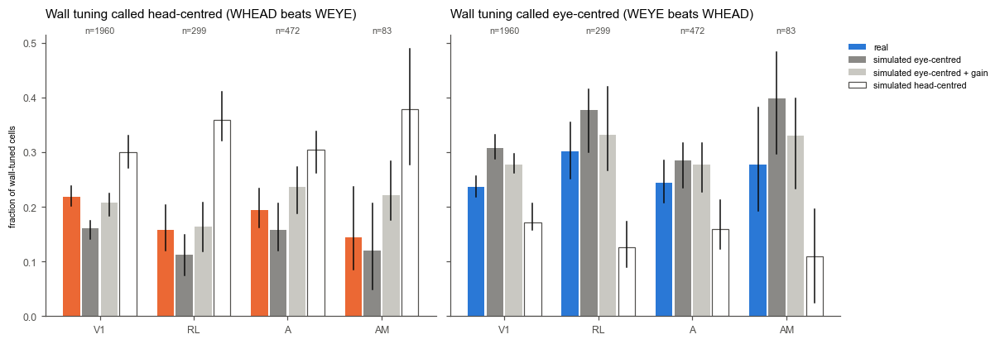

,wall_tuned,real_head,null_head,gain_head,hit_head,p_head_vs_gain,real_eye,null_eye,gain_eye,hit_eye,p_eye
V1,1960.0,0.219,0.161,0.208,0.300,0.133,0.237,0.172,0.277,0.308,0.0
RL,299.0,0.157,0.112,0.165,0.359,0.657,0.301,0.126,0.332,0.377,0.0
A,472.0,0.195,0.158,0.237,0.305,0.987,0.244,0.159,0.277,0.285,0.0
AM,83.0,0.145,0.120,0.222,0.379,0.972,0.277,0.109,0.330,0.399,0.0


In [201]:
from scipy.stats import binomtest


def cell_areas(sess, n):
    cs = CELLS[CELLS['session'] == sess]
    a = np.full(n, '', dtype=object)
    a[cs['cell'].to_numpy(int)] = cs['area'].to_numpy()
    return a


def bnd_rates(area):
    out = {'n': 0, 'real': {'head': 0, 'eye': 0}}
    nd = min(r[BND_GENS[0] + '_tuned'].shape[0] for r in BS.values())
    num = {(g, c): np.zeros(nd) for g in BND_GENS for c in ('head', 'eye')}
    den = {g: np.zeros(nd) for g in BND_GENS}
    for sess, r in BS.items():
        m = r['tuned'].astype(bool) & (cell_areas(sess, len(r['tuned'])) == area)
        out['n'] += int(m.sum())
        for c in ('head', 'eye'):
            out['real'][c] += int((r[c].astype(bool) & m).sum())
        for g in BND_GENS:
            t = r[g + '_tuned'][:nd].astype(bool) & m[None]
            den[g] += t.sum(1)
            for c in ('head', 'eye'):
                num[(g, c)] += (r['{}_{}'.format(g, c)][:nd].astype(bool) & t).sum(1)
    out['sim'] = {k: v / np.maximum(den[k[0]], 1) for k, v in num.items()}
    return out


V_AREAS = [a for a in AREAS if a != 'PM']
V_RATES = {a: bnd_rates(a) for a in V_AREAS} if BS else {}
if V_RATES:
    bars = [('real', None), ('simulated eye-centred', 'WEYE'), ('simulated eye-centred + gain', 'WGAIN'),
            ('simulated head-centred', 'WHEAD')]
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    w = 0.2
    for ax, c, col, ttl in ((axs[0], 'head', '#eb6834', 'Wall tuning called head-centred (WHEAD beats WEYE)'),
                            (axs[1], 'eye', '#2a78d6', 'Wall tuning called eye-centred (WEYE beats WHEAD)')):
        for i, a in enumerate(V_AREAS):
            S = V_RATES[a]
            for j, (lab, g) in enumerate(bars):
                x = i + (j - 1.5) * w
                if g is None:
                    y = S['real'][c] / max(S['n'], 1)
                    lo, hi = frac_ci(S['real'][c], S['n'])
                    kw = dict(color=col)
                else:
                    v = S['sim'][(g, c)]
                    y, (lo, hi) = v.mean(), np.percentile(v, [2.5, 97.5])
                    kw = {'WEYE': dict(color='#8a8986'), 'WGAIN': dict(color='#c9c8c2'),
                          'WHEAD': dict(color='white', edgecolor=INK2, lw=0.8)}[g]
                ax.bar(x, y, width=w * 0.9, label=lab if i == 0 else None, **kw)
                ax.plot([x, x], [lo, hi], color=INK, lw=1)
            ax.text(i, 1.0, 'n={}'.format(S['n']), transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                    fontsize=7, color=INK2)
        ax.set_xticks(range(len(V_AREAS)))
        ax.set_xticklabels(V_AREAS)
        ax.set_title(ttl, loc='left', fontsize=10, pad=14)
        style(ax)
    axs[0].set_ylabel('fraction of wall-tuned cells')
    axs[1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'V1_wall_frame_calls')

    rows = {}
    for a in V_AREAS:
        S = V_RATES[a]
        n = S['n']
        rh, re_ = S['real']['head'] / max(n, 1), S['real']['eye'] / max(n, 1)
        sm = {k: v.mean() for k, v in S['sim'].items()}
        rows[a] = {'wall_tuned': n, 'real_head': rh, 'null_head': sm[('WEYE', 'head')],
                   'gain_head': sm[('WGAIN', 'head')], 'hit_head': sm[('WHEAD', 'head')],
                   'p_head_vs_gain': binomtest(S['real']['head'], n, sm[('WGAIN', 'head')], alternative='greater').pvalue
                   if n else np.nan,
                   'real_eye': re_, 'null_eye': sm[('WHEAD', 'eye')], 'gain_eye': sm[('WGAIN', 'eye')],
                   'hit_eye': sm[('WEYE', 'eye')],
                   'p_eye': binomtest(S['real']['eye'], n, sm[('WHEAD', 'eye')], alternative='greater').pvalue
                   if n else np.nan}
    V1T = pd.DataFrame(rows).T
    print('Wall-tuned cells: {} of {} (all areas).'.format(sum(int(r['tuned'].sum()) for r in BS.values()),
                                                          sum(len(r['tuned']) for r in BS.values())))
    display(V1T.astype(float).round(3))

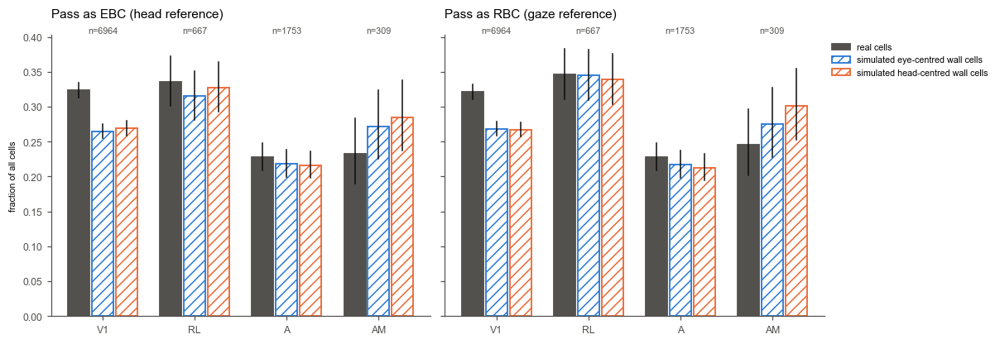

,cells,real_EBC,real_RBC,real_both,real_EBC_only,real_RBC_only,eye_EBC,eye_RBC,eye_both,eye_EBC_only,eye_RBC_only,head_EBC,head_RBC,head_both,head_EBC_only,head_RBC_only
V1,6964.0,0.323,0.321,0.304,0.020,0.017,0.265,0.269,0.251,0.014,0.018,0.269,0.267,0.251,0.018,0.017
RL,667.0,0.336,0.346,0.318,0.018,0.028,0.315,0.345,0.301,0.013,0.043,0.327,0.339,0.313,0.013,0.025
A,1753.0,0.228,0.228,0.214,0.013,0.013,0.218,0.217,0.205,0.013,0.013,0.216,0.213,0.201,0.015,0.011
AM,309.0,0.233,0.246,0.220,0.013,0.026,0.272,0.275,0.252,0.019,0.023,0.285,0.301,0.278,0.006,0.023


In [202]:
V2_SRCS = [('real', ''), ('eye-centred', 'WEYE_'), ('head-centred', 'WHEAD_')]
V2_KINDS = ('EBC', 'RBC', 'both', 'EBC only', 'RBC only')


def ebc_rates(area):
    n, acc = 0, {}
    for sess, r in BS.items():
        m = cell_areas(sess, len(r['tuned'])) == area
        n += int(m.sum())
        for src, pre in V2_SRCS:
            e_, b_ = r[pre + 'ebc'].astype(bool), r[pre + 'rbc'].astype(bool)
            if e_.ndim == 2:
                e_, b_ = e_[0], b_[0]
            for k, v in zip(V2_KINDS, (e_, b_, e_ & b_, e_ & ~b_, b_ & ~e_)):
                acc[(src, k)] = acc.get((src, k), 0) + int((v & m).sum())
    return n, acc


if BS and all('WEYE_ebc' in r for r in BS.values()):
    cols = {'real': '#52514e', 'eye-centred': '#2a78d6', 'head-centred': '#eb6834'}
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    w = 0.26
    rows = {}
    for ax, crit, ttl in ((axs[0], 'EBC', 'Pass as EBC (head reference)'),
                          (axs[1], 'RBC', 'Pass as RBC (gaze reference)')):
        for i, a in enumerate(V_AREAS):
            n, acc = ebc_rates(a)
            for j, (src, _) in enumerate(V2_SRCS):
                k = acc[(src, crit)]
                x = i + (j - 1) * w
                lo, hi = frac_ci(k, n)
                real = src == 'real'
                ax.bar(x, k / max(n, 1), width=w * 0.9, color=cols[src] if real else 'white', edgecolor=cols[src],
                       lw=1.2, hatch=None if real else '///',
                       label=('real cells' if real else 'simulated {} wall cells'.format(src)) if i == 0 else None)
                ax.plot([x, x], [lo, hi], color=INK, lw=1)
            ax.text(i, 1.0, 'n={}'.format(n), transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                    fontsize=7, color=INK2)
            rows[a] = {'cells': n, **{'{}_{}'.format(src.split('-')[0], kk.replace(' ', '_')): acc[(src, kk)] / max(n, 1)
                                       for src, _ in V2_SRCS for kk in V2_KINDS}}
        ax.set_xticks(range(len(V_AREAS)))
        ax.set_xticklabels(V_AREAS)
        ax.set_title(ttl, loc='left', fontsize=10, pad=14)
        style(ax)
    axs[0].set_ylabel('fraction of all cells')
    axs[1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'V2_ebc_criteria')
    V2T = pd.DataFrame(rows).T
    display(V2T.astype(float).round(3))

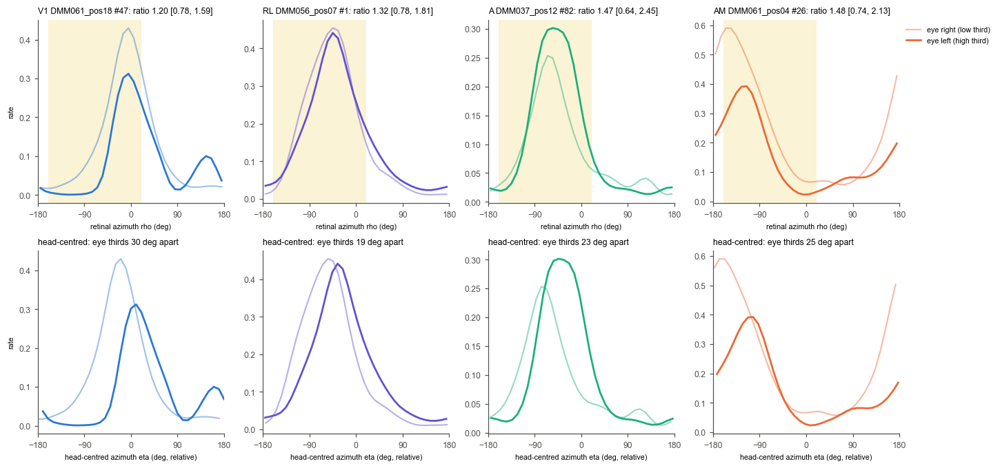

,session,cell,ratio,ci_lo,ci_hi,delta
V1,251016_DMM_DMM061_pos18,47,1.202115,0.7802,1.590345,29.686015
RL,251101_DMM_DMM056_pos07,1,1.322832,0.784778,1.807081,18.585494
A,250630_DMM_DMM037_pos12,82,1.468255,0.637103,2.449461,23.491495
AM,251021_DMM_DMM061_pos04,26,1.48194,0.735937,2.126535,24.89936


In [203]:
W1_AREAS = [a for a in AREAS if a != 'PM']
W1_MIN_DELTA = 12.0


def c1_curves(sess):
    path = SES.set_index('session').loc[sess, 'path']
    with h5py.File(path, 'r') as f:
        es = f['refframe']['eye_shift']
        return {k: es[k][()] for k in ('F_low', 'F_high', 'delta', 'split_r', 'depth')}


w1_delta = {s: float(c1_curves(s)['delta']) for s in CELLS['session'].unique()}
CELLS['eye_delta'] = CELLS['session'].map(w1_delta)
w1_pick = {}
for a in W1_AREAS:
    width = CELLS['eye_ci_hi'] - CELLS['eye_ci_lo']
    c = CELLS[(CELLS['area'] == a) & CELLS['eye_reliable'] & (CELLS['eye_ci_lo'] > 0.5) & (CELLS['eye_ci_lo'] <= 1)
              & (CELLS['eye_ci_hi'] >= 1) & (width > 0.05) & (CELLS['eye_delta'] >= W1_MIN_DELTA)]
    if len(c):
        w1_pick[a] = c.loc[(c['eye_ci_hi'] - c['eye_ci_lo']).idxmin()]

if w1_pick:
    grid = np.arange(-175.0, 180.0, 10.0)
    fig, axs = plt.subplots(2, len(W1_AREAS), figsize=(3.3 * len(W1_AREAS), 6.2), squeeze=False)
    for j, a in enumerate(W1_AREAS):
        for ax in axs[:, j]:
            style(ax)
            ax.set_xlim(-180, 180)
            ax.set_xticks([-180, -90, 0, 90, 180])
        if a not in w1_pick:
            continue
        r = w1_pick[a]
        cv = c1_curves(r['session'])
        k, dl = int(r['cell']), float(cv['delta'])
        lo, hi = cv['F_low'][:, k], cv['F_high'][:, k]
        ax = axs[0][j]
        ax.axvspan(-160, 20, color='#fbf3d5', lw=0)
        ax.plot(grid, lo, color=acol(a), lw=1.4, alpha=0.45, label='eye right (low third)')
        ax.plot(grid, hi, color=acol(a), lw=1.8, label='eye left (high third)')
        ax.set_title('{} {} #{}: ratio {:.2f} [{:.2f}, {:.2f}]'.format(
            a, r['session'].split('_DMM_')[-1], k, r['eye_ratio'], r['eye_ci_lo'], r['eye_ci_hi']), loc='left', fontsize=8)
        ax.set_xlabel('retinal azimuth rho (deg)')
        ax = axs[1][j]
        x_lo = (grid - dl / 2 + 180) % 360 - 180
        x_hi = (grid + dl / 2 + 180) % 360 - 180
        for x, y, al, lw in ((x_lo, lo, 0.45, 1.4), (x_hi, hi, 1.0, 1.8)):
            o = np.argsort(x)
            ax.plot(x[o], y[o], color=acol(a), lw=lw, alpha=al)
        ax.set_title('head-centered: eye thirds {:.0f} deg apart'.format(dl), loc='left', fontsize=8)
        ax.set_xlabel('head-centered azimuth eta (deg, relative)')
    axs[0][0].set_ylabel('rate')
    axs[1][0].set_ylabel('rate')
    axs[0][-1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'W1_example_fields_eye_vs_head')
    display(pd.DataFrame({a: {'session': r['session'], 'cell': int(r['cell']), 'ratio': r['eye_ratio'],
                              'ci_lo': r['eye_ci_lo'], 'ci_hi': r['eye_ci_hi'], 'delta': r['eye_delta']}
                          for a, r in w1_pick.items()}).T)

In [204]:
import hashlib

X_DRAWS = 200
X_TEST_DRAWS = 20
X_LOG_BF = np.log(10.0)
X_DPRIME = 2.0
X_P_NEITHER = 0.01
X_AREAS = ('V1', 'RL', 'A', 'AM')


def ridge_insample(X, use, lam):
    Xu = X[use]
    xm, xs = Xu.mean(0), Xu.std(0)
    xs[~(xs > 0)] = 1.0
    Z = (Xu - xm) / xs
    U, s_, Vt = _svd_prep(Z)
    lam = np.where(np.isfinite(lam), lam, 1e3)

    def pred(Yu):
        ym = Yu.mean(0)
        return Z @ _ridge_coefs(U, s_, Vt, Yu - ym, lam) + ym
    return pred


def r2_in(Yu, P):
    return 1.0 - ((Yu - P) ** 2).sum(0) / np.maximum(((Yu - Yu.mean(0)) ** 2).sum(0), 1e-12)


def anchor_test(D, use, XE, XH, XE0, XH0, cells, n_draws, n_test, rng):
    idx = np.flatnonzero(use)
    Y = D['Y'][:, cells]
    Yu = Y[idx]
    folds = na._folds(D, use)
    cv = {k: na._cv(X, Y, folds) for k, X in (('XE', XE), ('XH', XH), ('XE0', XE0), ('XH0', XH0))}
    pr = {k: ridge_insample(X, use, np.nanmedian(cv[k]['lam'], 0)) for k, X in (('XE', XE), ('XH', XH))}

    def score(Yu_):
        return r2_in(Yu_, pr['XH'](Yu_)) - r2_in(Yu_, pr['XE'](Yu_))

    sims = {}
    for g in ('XE', 'XH'):
        P = pr[g](Yu)
        res = Yu - P
        sims[g] = np.stack([score(P + np.roll(res, int(rng.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT)), 0))
                            for _ in range(n_draws + n_test)])
    return {'cells': np.asarray(cells, int), 'd_real': score(Yu), 'sim_eye': sims['XE'], 'sim_head': sims['XH'],
            'gain_eye': beats(cv['XE'], cv['XE0']), 'gain_head': beats(cv['XH'], cv['XH0'])}


def x_session(R, path, ebc, n_draws=X_DRAWS, n_test=X_TEST_DRAWS, seed=0):
    D = R['D']
    area = np.asarray(R['area'])
    rng = np.random.default_rng(seed)
    out = {}
    use, mz, base, gain = gain_designs(D, D['light'] & D['use'])
    if np.sum(use) < 3 * NULL_MIN_SHIFT:
        return None
    vr, vh = na._vm_basis(D['rho']), na._vm_basis(D['eta'])
    PE0, PH0 = base['ADD'], base['HEAD']
    cells = np.flatnonzero(R['stored']['tuned'] & np.isin(area, X_AREAS))
    if len(cells):
        r = anchor_test(D, use, np.c_[PE0, vr * mz[:, None]], np.c_[PH0, vh * mz[:, None]], PE0, PH0, cells,
                        n_draws, n_test, rng)
        out.update({'pillar_' + k: v for k, v in r.items()})
    if ebc is not None:
        cells = np.flatnonzero(np.asarray(ebc, bool) & np.isin(area, X_AREAS))
        if len(cells):
            xy, arena = head_position(D, path)
            wuse, des = bnd_designs(D, xy, arena)
            k0 = des['NUIS'].shape[1]
            Fh, Fe = des['WHEAD'][:, k0:], des['WEYE'][:, k0:]
            r = anchor_test(D, wuse, des['WGAIN'], np.c_[des['WHEAD'], Fh * mz[:, None]], des['WEYE'], des['WHEAD'],
                            cells, n_draws, n_test, rng)
            out.update({'wall_' + k: v for k, v in r.items()})
    return out or None


XS = {}
if not RUN_REFITS:
    print('RUN_REFITS is off -- section X is skipped.')
elif not restore('X'):
    t_all = time.time()
    for i, s in SES.iterrows():
        ebc = BS[s['session']]['ebc'] if s['session'] in BS else None
        ebc_key = hashlib.md5(np.asarray(ebc, bool).tobytes()).hexdigest() if ebc is not None else 'none'

        def run_x():
            R, why = rebuild_session(s)
            return None if R is None else x_session(R, s['path'], ebc)
        t0 = time.time()
        r = cached(s, 'xanchor', {'draws': X_DRAWS, 'test': X_TEST_DRAWS, 'areas': list(X_AREAS), 'ebc': ebc_key,
                                  'v': 1}, run_x)
        if r is not None:
            XS[s['session']] = r
        if time.time() - t0 > 1:
            print('[{}/{}] {}: {:.0f} s'.format(i + 1, len(SES), s['session'], time.time() - t0), flush=True)
    print('Per-cell anchoring: {} sessions in {:.1f} min.'.format(len(XS), (time.time() - t_all) / 60))
    stash('X', XS=XS)

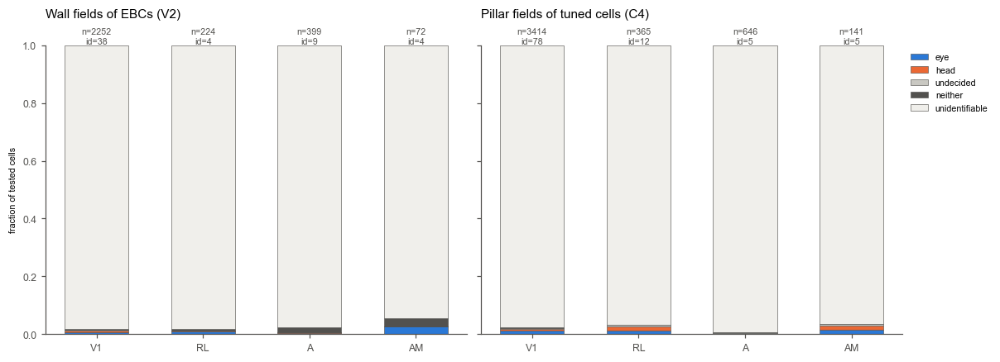

,cells,identifiable,dprime_median,dprime_p90,eye,head,undecided,neither,eye_with_gain,head_with_gain
area,,,,,,,,,,
V1,2252,38,0.256735,0.866640,12,17,3,6,2,3
RL,224,4,0.368053,0.962019,2,1,0,1,0,1
A,399,9,0.250480,0.941774,2,1,0,6,1,0
AM,72,4,0.501708,1.280394,2,0,0,2,0,0


,cells,identifiable,dprime_median,dprime_p90,eye,head,undecided,neither,eye_with_gain,head_with_gain
area,,,,,,,,,,
V1,3414,78,0.249114,1.106626,44,21,11,2,19,7
RL,365,12,0.344196,1.256726,4,6,2,0,2,0
A,646,5,0.190053,0.870318,2,1,1,1,2,0
AM,141,5,0.512530,1.597167,2,2,1,0,1,2


call,eye,head,undecided,neither
true,,,,
eye,0.677,0.017,0.305,0.001
head,0.012,0.688,0.296,0.004


call,eye,head,undecided,neither
true,,,,
eye,0.642,0.016,0.340,0.003
head,0.013,0.660,0.326,0.002


In [205]:
X_CALLS = ['eye', 'head', 'undecided', 'neither', 'unidentifiable']
X_COLORS = {'eye': '#2a78d6', 'head': '#eb6834', 'undecided': '#c9c8c2', 'neither': '#52514e',
            'unidentifiable': '#f0efeb'}
X_KINDS = [('wall', 'Wall fields of EBCs (V2)'), ('pillar', 'Pillar fields of tuned cells (C4)')]


def xcall(d, E, H):
    mE, sE, mH, sH = E.mean(0), E.std(0), H.mean(0), H.std(0)
    dprime = (mH - mE) / np.sqrt(np.maximum((sE ** 2 + sH ** 2) / 2, 1e-30))
    lp = lambda x, m, s: -0.5 * ((x - m) / s) ** 2 - np.log(s)
    log_bf = lp(d, mE, np.maximum(sE, 1e-12)) - lp(d, mH, np.maximum(sH, 1e-12))
    pct = lambda S: np.minimum((1 + 2 * np.minimum((S >= d).sum(0), (S <= d).sum(0))) / (1 + len(S)), 1.0)
    p_eye, p_head = pct(E), pct(H)
    call = np.full(len(d), 'undecided', dtype=object)
    call[log_bf > X_LOG_BF] = 'eye'
    call[log_bf < -X_LOG_BF] = 'head'
    call[(p_eye < X_P_NEITHER) & (p_head < X_P_NEITHER)] = 'neither'
    call[~(dprime >= X_DPRIME)] = 'unidentifiable'
    return {'dprime': dprime, 'log_bf': log_bf, 'p_eye': p_eye, 'p_head': p_head, 'call': call}


def x_cells(kind):
    rows, cal = [], []
    for sess, r in XS.items():
        if kind + '_cells' not in r:
            continue
        cells = np.asarray(r[kind + '_cells'], int)
        cs = CELLS[CELLS['session'] == sess]
        a = cell_areas(sess, max(int(cells.max()), int(cs['cell'].max()) if len(cs) else 0) + 1)[cells]
        E, H = r[kind + '_sim_eye'][:X_DRAWS], r[kind + '_sim_head'][:X_DRAWS]
        c = xcall(r[kind + '_d_real'], E, H)
        rows.append(pd.DataFrame({'session': sess, 'cell': cells, 'area': a, 'dprime': c['dprime'],
                                  'log_bf': c['log_bf'], 'call': c['call'],
                                  'gain_eye': r[kind + '_gain_eye'].astype(bool),
                                  'gain_head': r[kind + '_gain_head'].astype(bool)}))
        for true, S in (('eye', r[kind + '_sim_eye']), ('head', r[kind + '_sim_head'])):
            for k in range(X_DRAWS, len(S)):
                cal.append(pd.DataFrame({'area': a, 'true': true, 'call': xcall(S[k], E, H)['call'],
                                         'identifiable': c['dprime'] >= X_DPRIME}))
    return (pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(),
            pd.concat(cal, ignore_index=True) if cal else pd.DataFrame())


X_RES = {k: x_cells(k) for k, _ in X_KINDS} if XS else {}
if X_RES:
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.0), sharey=True)
    tabs = {}
    for ax, (kind, ttl) in zip(axs, X_KINDS):
        XC, _ = X_RES[kind]
        if not len(XC):
            ax.set_title(ttl + ': not run', loc='left', fontsize=10)
            continue
        for i, a in enumerate(X_AREAS):
            d = XC[XC['area'] == a]
            n = len(d)
            bottom = 0.0
            for cl in X_CALLS:
                f = (d['call'] == cl).mean() if n else 0.0
                ax.bar(i, f, bottom=bottom, width=0.6, color=X_COLORS[cl], edgecolor=INK2, lw=0.4,
                       label=cl if i == 0 else None)
                bottom += f
            ax.text(i, 1.0, 'n={}\nid={}'.format(n, int((d['dprime'] >= X_DPRIME).sum())),
                    transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=7, color=INK2)
        ax.set_xticks(range(len(X_AREAS)))
        ax.set_xticklabels(X_AREAS)
        ax.set_ylim(0, 1)
        ax.set_title(ttl, loc='left', fontsize=10, pad=22)
        style(ax)
        g = XC.groupby('area')
        tabs[kind] = pd.DataFrame({
            'cells': g.size(),
            'identifiable': g['dprime'].apply(lambda x: int((x >= X_DPRIME).sum())),
            'dprime_median': g['dprime'].median(),
            'dprime_p90': g['dprime'].quantile(0.9),
            **{cl: g['call'].apply(lambda x, cl=cl: int((x == cl).sum())) for cl in X_CALLS[:-1]},
            'eye_with_gain': g.apply(lambda x: int(((x['call'] == 'eye') & x['gain_eye']).sum())),
            'head_with_gain': g.apply(lambda x: int(((x['call'] == 'head') & x['gain_head']).sum())),
        }).reindex(list(X_AREAS))
    axs[0].set_ylabel('fraction of tested cells')
    axs[1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'X1_per_cell_anchoring')
    for kind, ttl in X_KINDS:
        if kind in tabs:
            print(ttl)
            display(tabs[kind])

    for kind, ttl in X_KINDS:
        XC, CAL = X_RES[kind]
        if not len(CAL):
            continue
        d = CAL[CAL['identifiable']]
        if not len(d):
            print('{}: no identifiable cells, so no calls to calibrate.'.format(ttl))
            continue
        cal = d.groupby('true')['call'].value_counts(normalize=True).unstack(fill_value=0).reindex(
            columns=X_CALLS[:-1], fill_value=0)
        print('{}: calls on held-out simulations of identifiable cells (rows = true anchoring)'.format(ttl))
        display(cal.round(3))

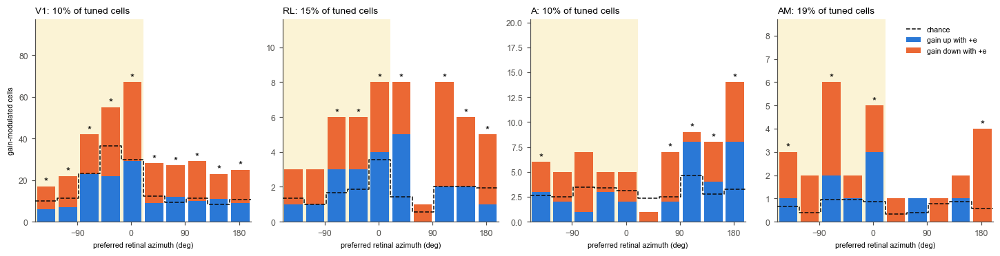

,tuned,gain_cells,bins_above_chance,visible_bins_above_chance
V1,3414,335,10,5
RL,365,54,7,3
A,646,67,5,1
AM,141,27,4,3


In [206]:
Z1_VIS = (-160.0, 20.0)
Z1_BIN_DEG = (Z1_VIS[1] - Z1_VIS[0]) / 5
if len(QC):
    from scipy.stats import binom
    edges = Z1_VIS[0] + Z1_BIN_DEG * np.arange(int(round(360 / Z1_BIN_DEG)) + 1)
    cen = edges[:-1] + Z1_BIN_DEG / 2
    nb = len(cen)
    fig, axs = plt.subplots(1, len(Q_AREAS), figsize=(3.3 * len(Q_AREAS), 3.4), squeeze=False)
    Z1T = {}
    for ax, a in zip(axs[0], Q_AREAS):
        d = QC[(QC['area'] == a) & QC['pref_rho'].notna()]
        x = d['pref_rho'].to_numpy(float)
        x = np.where(x < edges[0], x + 360.0, x)
        b = np.clip(np.digitize(x, edges) - 1, 0, nb - 1)
        g, k = d['gain_cell'].to_numpy(bool), d['k'].to_numpy(float)
        n = np.bincount(b, minlength=nb)
        up = np.bincount(b[g & (k > 0)], minlength=nb)
        dn = np.bincount(b[g & (k < 0)], minlength=nb)
        tot = up + dn
        p = np.where(n > 0, binom.sf(tot - 1, np.maximum(n, 1), GAIN_P_FLOOR), np.nan)
        ax.axvspan(*Z1_VIS, color='#fbf3d5', lw=0)
        ax.bar(cen, up, width=Z1_BIN_DEG * 0.85, color='#2a78d6', label='gain up with +e')
        ax.bar(cen, dn, bottom=up, width=Z1_BIN_DEG * 0.85, color='#eb6834', label='gain down with +e')
        ax.step(edges, np.r_[n * GAIN_P_FLOOR, n[-1] * GAIN_P_FLOOR], where='post', color=INK, lw=1.0, ls='--',
                label='chance', zorder=3)
        for j in np.flatnonzero(p < 0.05):
            ax.text(cen[j], tot[j], '*', ha='center', va='bottom', fontsize=10)
        ax.set_xlim(edges[0], edges[-1])
        ax.set_xticks([-90, 0, 90, 180])
        ax.set_ylim(0, max(tot.max(), 1) * 1.45)
        ax.set_xlabel('preferred retinal azimuth (deg)')
        ax.set_title('{}: {:.0%} of tuned cells'.format(a, g.mean()), loc='left', fontsize=9)
        style(ax)
        Z1T[a] = {'tuned': len(d), 'gain_cells': int(g.sum()), 'bins_above_chance': int(np.sum(p < 0.05)),
                  'visible_bins_above_chance': int(np.sum((p < 0.05) & (cen < Z1_VIS[1])))}
    axs[0][0].set_ylabel('gain-modulated cells')
    axs[0][-1].legend(fontsize=7, frameon=False, loc='upper right')
    show(fig, 'Z1_gain_coverage_stacked')
    display(pd.DataFrame(Z1T).T)

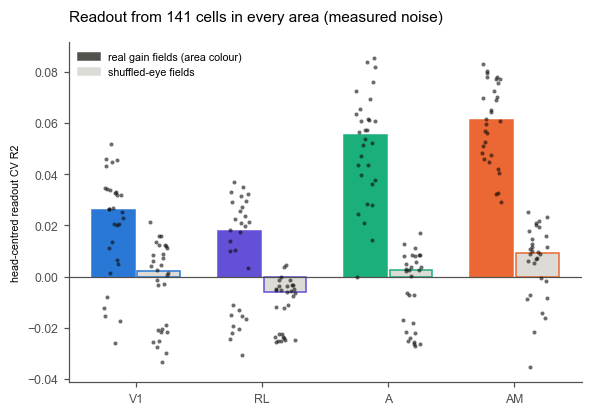

,draws,real,null,real_minus_null,frac_real_wins
V1,30.0,0.026,0.002,0.024,0.967
RL,30.0,0.018,-0.006,0.023,0.933
A,30.0,0.055,0.002,0.056,1.000
AM,30.0,0.061,0.009,0.054,1.000


In [207]:
if Q_COLS:
    ai = list(next(iter(Q_COLS.values()))['alphas']).index(1.0)
    jit = np.random.default_rng(2)
    fig, ax = plt.subplots(figsize=(5.4, 3.8))
    Z2T = {}
    for i, a in enumerate(Q_AREAS):
        rs = [r for (h, aa), r in Q_COLS.items() if aa == a]
        if not rs:
            continue
        v = {kind: np.concatenate([np.nanmean(r['r2'][ki, ai], 1) for r in rs]) for ki, kind in enumerate(('real', 'null'))}
        for kind, x in (('real', i - 0.18), ('null', i + 0.18)):
            ax.bar(x, np.median(v[kind]), width=0.34, color=acol(a) if kind == 'real' else '#dcdbd6',
                   edgecolor=acol(a), lw=1)
            ax.scatter(x + jit.uniform(-0.08, 0.08, len(v[kind])), v[kind], s=7, color=INK, lw=0, alpha=0.6, zorder=3)
        Z2T[a] = {'draws': len(v['real']), 'real': np.median(v['real']), 'null': np.median(v['null']),
                  'real_minus_null': np.median(v['real'] - v['null']), 'frac_real_wins': np.mean(v['real'] > v['null'])}
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(len(Q_AREAS)))
    ax.set_xticklabels(Q_AREAS)
    ax.set_ylabel('head-centered readout CV R2')
    ax.set_title('Readout from {} cells in every area (measured noise)'.format(Q_N), loc='left', fontsize=10, pad=14)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=INK2), plt.Rectangle((0, 0), 1, 1, color='#dcdbd6')],
              labels=['real gain fields (area color)', 'shuffled-eye fields'], fontsize=7, frameon=False, loc='upper left')
    style(ax)
    show(fig, 'Z2_readout_matched_n')
    display(pd.DataFrame(Z2T).T.round(3))

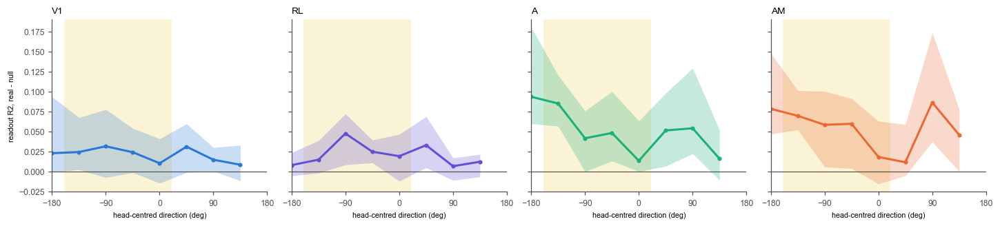

In [208]:
if Q_COLS:
    ai = list(next(iter(Q_COLS.values()))['alphas']).index(1.0)
    fig, axs = plt.subplots(1, len(Q_AREAS), figsize=(3.3 * len(Q_AREAS), 3.0), sharey=True, squeeze=False)
    for ax, a in zip(axs[0], Q_AREAS):
        rs = [r for (h, aa), r in Q_COLS.items() if aa == a]
        if not rs:
            continue
        c = rs[0]['centers']
        o = np.argsort(c)
        diff = np.concatenate([r['r2'][0, ai] - r['r2'][1, ai] for r in rs], 0)
        lo, med, hi = np.percentile(diff, [10, 50, 90], axis=0)
        ax.axvspan(-160, 20, color='#fbf3d5', lw=0)
        ax.fill_between(c[o], lo[o], hi[o], color=acol(a), alpha=0.25, lw=0)
        ax.plot(c[o], med[o], color=acol(a), lw=2, marker='o', ms=3)
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_xlim(-180, 180)
        ax.set_xticks([-180, -90, 0, 90, 180])
        ax.set_xlabel('head-centered direction (deg)')
        ax.set_title(a, loc='left', fontsize=9)
        style(ax)
    axs[0][0].set_ylabel('readout R2, real - null')
    show(fig, 'Z3_readout_by_direction_minus_null')

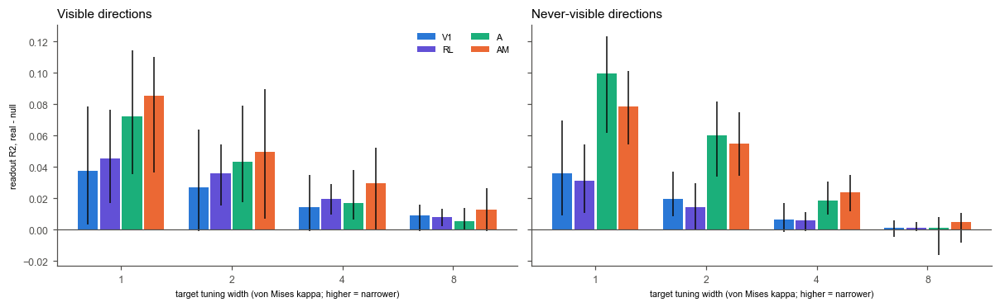

In [209]:
if Q7_COLS:
    r0 = next(iter(Q7_COLS.values()))
    ks = list(r0['kappas'])
    ai = list(r0['alphas']).index(1.0)
    w = 0.8 / len(Q_AREAS)
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
    for ax, (ttl, visible) in zip(axs, (('Visible directions', True), ('Never-visible directions', False))):
        for j, a in enumerate(Q_AREAS):
            keys = [k for k in Q7_COLS if k[1] == a]
            if not keys:
                continue
            vis = np.nanmean([Q_COLS[k]['in_view'] for k in keys], 0) >= Q_VIEW_MIN
            vm = vis if visible else ~vis
            d = np.stack([np.concatenate([Q7_COLS[k]['r2'][kk, 0, ai][:, vm] - Q7_COLS[k]['r2'][kk, 1, ai][:, vm]
                                          for k in keys], 0).mean(1) for kk in range(len(ks))], 1)
            lo, med, hi = np.percentile(d, [10, 50, 90], axis=0)
            x = np.arange(len(ks)) + (j - (len(Q_AREAS) - 1) / 2) * w
            ax.bar(x, med, width=w * 0.9, color=acol(a), label=a)
            ax.vlines(x, lo, hi, color=INK, lw=1)
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_xticks(range(len(ks)))
        ax.set_xticklabels(['{:g}'.format(k) for k in ks])
        ax.set_xlabel('target tuning width (von Mises kappa; higher = narrower)')
        ax.set_title(ttl, loc='left', fontsize=10)
        style(ax)
    axs[0].set_ylabel('readout R2, real - null')
    axs[0].legend(fontsize=7, frameon=False, loc='upper right', ncol=2)
    show(fig, 'Z4_readout_vs_width_bars')

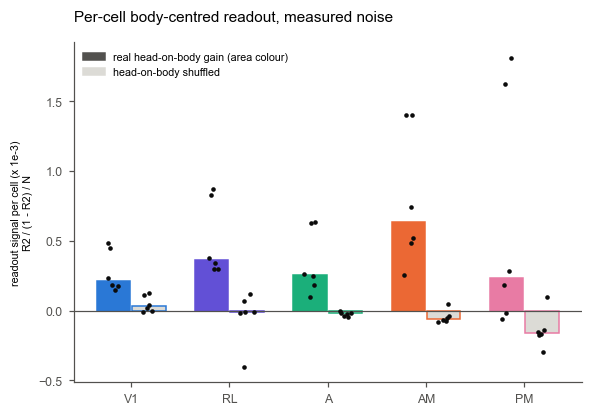

,N,real,null,real_minus_null
V1,1452.0,0.209,0.031,0.178
RL,310.0,0.359,-0.010,0.368
A,291.0,0.253,-0.021,0.274
AM,72.0,0.632,-0.061,0.693
PM,22.0,0.233,-0.162,0.395


In [210]:
if BODY_POOL:
    d = BPT[BPT['alpha'] == 1.0].copy()
    d['snr'] = d['r2'] / (1.0 - d['r2']) / d['N'] * 1e3
    areas_ = [a for a in AREAS if (d['area'] == a).any()]
    jit = np.random.default_rng(3)
    fig, ax = plt.subplots(figsize=(5.4, 3.8))
    Z5T = {}
    for i, a in enumerate(areas_):
        top = d[(d['area'] == a) & (d['N'] == d['n_all'])]
        for kind, x in (('real', i - 0.18), ('null', i + 0.18)):
            v = top.loc[top['kind'] == kind, 'snr'].to_numpy()
            ax.bar(x, np.median(v), width=0.34, color=acol(a) if kind == 'real' else '#dcdbd6', edgecolor=acol(a), lw=1)
            ax.scatter(x + jit.uniform(-0.07, 0.07, len(v)), v, s=9, color=INK, zorder=3, lw=0)
            Z5T.setdefault(a, {'N': int(top['n_all'].iloc[0])})[kind] = np.median(v)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(len(areas_)))
    ax.set_xticklabels(areas_)
    ax.set_ylabel('readout signal per cell (x 1e-3)\nR2 / (1 - R2) / N')
    ax.set_title('Per-cell body-centered readout, measured noise', loc='left', fontsize=10, pad=14)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=INK2), plt.Rectangle((0, 0), 1, 1, color='#dcdbd6')],
              labels=['real head-on-body gain (area color)', 'head-on-body shuffled'], fontsize=7, frameon=False,
              loc='upper left')
    style(ax)
    show(fig, 'Z5_body_readout_per_cell')
    Z5T = pd.DataFrame(Z5T).T
    Z5T['real_minus_null'] = Z5T['real'] - Z5T['null']
    display(Z5T.round(3))

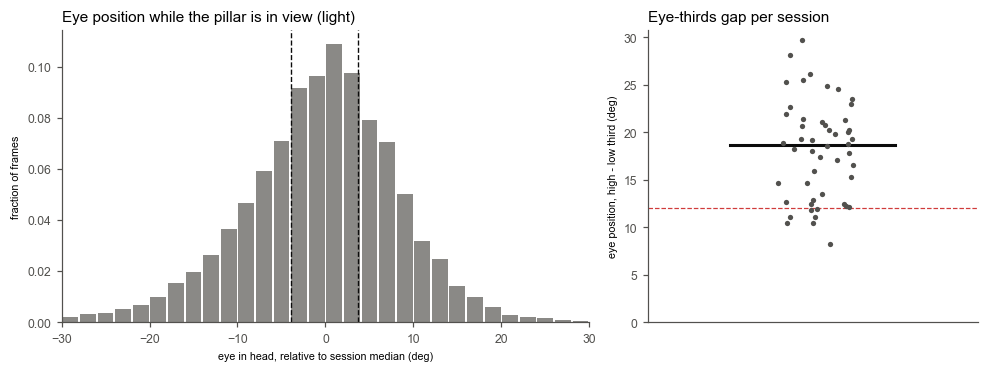

In [211]:
Z6_BINS = np.arange(-30.0, 30.0 + 1e-9, 2.0)
z6_hist, z6_cut, z6_delta = [], [], {}
for _, s in SES.iterrows():
    with h5py.File(s['path'], 'r') as f:
        cv = f['covariates']
        names = L_(cv['names'][()])
        m = cv['use'][()].astype(bool) & cv['light'][()].astype(bool) & (cv['X'][:, names.index('in_view')] > 0.5)
        e = cv['e'][()][m]
        z6_delta[s['session']] = float(f['refframe']['eye_shift']['delta'][()])
    e = e[np.isfinite(e)]
    if len(e) < 100:
        continue
    med = np.median(e)
    h, _ = np.histogram(e - med, Z6_BINS)
    z6_hist.append(h / len(e))
    z6_cut.append(np.percentile(e, [100 / 3, 200 / 3]) - med)
if z6_hist:
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={'width_ratios': [1.6, 1]})
    ax = axs[0]
    c = Z6_BINS[:-1] + np.diff(Z6_BINS) / 2
    ax.bar(c, np.mean(z6_hist, 0), width=np.diff(Z6_BINS) * 0.9, color='#8a8986')
    for v in np.mean(z6_cut, 0):
        ax.axvline(v, color=INK, lw=0.9, ls='--')
    ax.set_xlim(Z6_BINS[0], Z6_BINS[-1])
    ax.set_xlabel('eye in head, relative to session median (deg)')
    ax.set_ylabel('fraction of frames')
    ax.set_title('Eye position while the pillar is in view (light)', loc='left', fontsize=10)
    style(ax)
    ax = axs[1]
    dv = np.array([v for v in z6_delta.values() if np.isfinite(v)])
    ax.scatter(np.random.default_rng(4).uniform(-0.15, 0.15, len(dv)), dv, s=12, color=INK2, lw=0, zorder=3)
    ax.plot([-0.3, 0.3], [np.median(dv)] * 2, color=INK, lw=2)
    ax.axhline(W1_MIN_DELTA, color='#d03b3b', lw=0.8, ls='--')
    ax.set_xlim(-0.6, 0.6)
    ax.set_xticks([])
    ax.set_ylim(bottom=0)
    ax.set_ylabel('eye position, high - low third (deg)')
    ax.set_title('Eye-thirds gap per session', loc='left', fontsize=10)
    style(ax)
    show(fig, 'Z6_eye_position_spread')
    print('{} sessions; eye-thirds gap median {:.1f} deg (IQR {:.1f}-{:.1f}); {} sessions >= {:.0f} deg.'.format(
        len(dv), np.median(dv), *np.percentile(dv, [25, 75]), int(np.sum(dv >= W1_MIN_DELTA)), W1_MIN_DELTA))

In [241]:
import contextlib
import io
import re
import string
import textwrap
from matplotlib.text import Text
from matplotlib.transforms import IdentityTransform
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

Y_NOTEBOOK = os.path.abspath('cross_area_summary.ipynb')
Y_FONT_SIZE = 16
Y_LABEL_SIZE = 1.2 * Y_FONT_SIZE
Y_LETTER_SIZE = 1.5 * Y_FONT_SIZE
Y_BAR_ERR_LW = 2.5
Y_MAX_SIZE = None
Y_FIG_WIDTH = 15.0
Y_DPI = 300
Y_LAYOUT_SCALE = 0.8
Y_PAD = (0.08, 0.08)
Y_DECO = (0.0, 0.0)
Y_NO_TITLES = True
Y_AREA_COLORS = {'V1': '#1f77b4', 'RL': '#ff7f0e', 'A': '#2ca02c', 'AM': '#9467bd'}
Y_EYE, Y_HEAD = '#17becf', '#d62728'
Y_UP, Y_DOWN = '#e377c2', '#bcbd22'
Y_SHUF = '#b9b8b2'
Y_HATCH = '///'
Y_LS_LOW, Y_LS_HIGH = '--', ':'
Y_EXCLUDE_AREAS = ('PM',)
Y_MARGINS = {'left': 0.5, 'right': 0.3, 'top': 0.3, 'bottom': 0.3}
Y_FORMATS = ('png', 'pdf')
if not getattr(plt.subplots, '_y_router', False):
    Y_REAL_SUBPLOTS = plt.subplots


class FigProxy:

    def __init__(self, fig):
        self._fig = fig

    def tight_layout(self, *a, **k):
        pass

    def savefig(self, *a, **k):
        pass

    def suptitle(self, *a, **k):
        pass

    def set_size_inches(self, *a, **k):
        pass

    def subplots_adjust(self, *a, **k):
        pass

    def __getattr__(self, name):
        return getattr(self._fig, name)


def y_share(axes, how, which):
    if how in (False, 'False', 'none', None):
        return
    nr, nc = axes.shape
    for r in range(nr):
        for c in range(nc):
            if how == 'row' and c:
                ref = axes[r, 0]
            elif how == 'col' and r:
                ref = axes[0, c]
            elif how in (True, 'all') and (r or c):
                ref = axes[0, 0]
            else:
                continue
            getattr(axes[r, c], 'share' + which)(ref)


def y_region(fig, spec, wspace=0.45, hspace=0.75):

    def route(nrows, ncols, kw):
        gkw = dict(kw.get('gridspec_kw') or {})
        sub = GridSpecFromSubplotSpec(nrows, ncols, subplot_spec=spec, wspace=gkw.get('wspace', wspace),
                                      hspace=gkw.get('hspace', hspace), width_ratios=gkw.get('width_ratios'),
                                      height_ratios=gkw.get('height_ratios'))
        axes = np.empty((nrows, ncols), dtype=object)
        for r in range(nrows):
            for c in range(ncols):
                axes[r, c] = fig.add_subplot(sub[r, c], **(kw.get('subplot_kw') or {}))
        y_share(axes, kw.get('sharex', False), 'x')
        y_share(axes, kw.get('sharey', False), 'y')
        return axes
    return route


def y_axes_at(fig, specs):

    def route(nrows, ncols, kw):
        axes = np.empty((nrows, ncols), dtype=object)
        for r in range(nrows):
            for c in range(ncols):
                axes[r, c] = fig.add_subplot(specs[r][c]) if specs[r][c] is not None else Figure().add_subplot(111)
        if all(s is not None for row in specs for s in row):
            y_share(axes, kw.get('sharey', False), 'y')
        return axes
    return route


def y_legend_inside(ax, loc='upper left', ncol=1, ylim=None, labels=None, title=None):
    if ylim is not None:
        ax.set_ylim(*ylim)
    h, l = ax.get_legend_handles_labels()
    leg = ax.legend(h, labels if labels is not None else l, loc=loc, ncol=ncol, fontsize=7, frameon=False,
                    handlelength=1.5, columnspacing=1.2, title=title, title_fontsize=7)
    leg._legend_box.align = 'left'
    return leg


def y_retitle(axes, old, new):
    for ax in np.ravel(axes):
        for t in (ax._left_title, ax.title, ax._right_title):
            t.set_text(t.get_text().replace(old, new))


def y_redraw(cid, routes, fig, call=None, edits=()):

    made, got = [], {}

    def subplots(nrows=1, ncols=1, **kw):
        n = subplots.n
        subplots.n += 1
        if n not in routes:
            f, a = Y_REAL_SUBPLOTS(nrows, ncols, **kw)
            made.append(f)
            return f, a
        axes = routes[n](nrows, ncols, kw)
        got[n] = axes
        if kw.get('squeeze', True) in (True, 'True'):
            axes = axes.squeeze()
            if axes.ndim == 0:
                axes = axes.item()
        return FigProxy(fig), axes
    subplots.n = 0
    subplots._y_router = True
    g = globals()
    src = None
    if call is None:
        with open(Y_NOTEBOOK) as f:
            src = next(''.join(c['source']) for c in json.load(f)['cells'] if c.get('id') == cid)
        for old, new in edits:
            if src.count(old) != 1:
                raise ValueError('{}: edit text found {} times: {!r}'.format(cid, src.count(old), old[:80]))
            src = src.replace(old, new)
    keep = {k: g[k] for k in ('show', 'display', 'AREAS') if k in g}
    keep_colors = dict(AREA_COLORS)
    g['show'] = lambda f, name: None
    g['display'] = lambda *a, **k: None
    g['AREAS'] = [a for a in keep['AREAS'] if a not in Y_EXCLUDE_AREAS]
    AREA_COLORS.update(Y_AREA_COLORS)
    plt.subplots = subplots
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            if call is not None:
                call()
            else:
                exec('\n'.join(l for l in src.splitlines() if not l.lstrip().startswith(('%', '!'))), g)
    finally:
        plt.subplots = Y_REAL_SUBPLOTS
        AREA_COLORS.clear()
        AREA_COLORS.update(keep_colors)
        for k in ('show', 'display', 'AREAS'):
            if k in keep:
                g[k] = keep[k]
            else:
                g.pop(k, None)
        for f in made:
            plt.close(f)
    return got


def y_cell_titles(axes, areas, start):

    for ax, a in zip(axes, areas):
        t = ax._left_title
        if '#' not in t.get_text():
            continue
        rest = t.get_text().split(':', 1)[1] if ':' in t.get_text() else ''
        t.set_text('{}, cell {}:{}'.format(a, start, rest) if rest else '{}, cell {}'.format(a, start))
        start += 1
    return start


def y_words(s):
    s = re.sub(r'\b([Ff])raction\b', r'\1rac.', s)
    s = re.sub(r'\b([Ff])rac\b(?!\.)', r'\1rac.', s)
    return re.sub(r'\bR(?:2|\u00b2)(?![0-9])', 'R\u00b2', s)


def y_math(s):
    return s.replace('R\u00b2', r'$\mathregular{R^2}$')


def y_set_text(fig, size):

    for ax in fig.axes:
        if Y_NO_TITLES and not getattr(ax, '_y_keep_title', False):
            for t in (ax._left_title, ax.title, ax._right_title):
                t.set_text('')
        if getattr(ax, '_y_keep_title', False):
            for t in (ax._left_title, ax.title, ax._right_title):
                t._y_size = Y_LABEL_SIZE
        for t in list(ax.texts):
            if re.match(r'\s*[nN]\s*=\s*\d', t.get_text()) or re.fullmatch(r'\s*\d+\s*', t.get_text()):
                t.remove()
        leg = ax.get_legend()
        if leg is not None:
            for t in leg.get_texts():
                t.set_text(re.sub(r'\s*\([nN]\s*=\s*\d+\)', '', t.get_text()))
            y_legend_resize(ax, leg, size)
        for t in (ax._left_title, ax.title, ax._right_title):
            t.set_text(re.sub(r'\s*\(numbers = [^)]*\)', '', t.get_text()))
    fig.canvas.draw()
    labels = {id(ax.xaxis.label) for ax in fig.axes} | {id(ax.yaxis.label) for ax in fig.axes}
    for t in fig.findobj(Text):
        if t.get_text():
            new = y_words(t.get_text())
            if id(t) not in labels:
                new = y_math(new)
            if new != t.get_text():
                t.set_text(new)
            if hasattr(t, '_y_orig'):
                t._y_orig = y_words(t._y_orig)
            t.set_fontsize(getattr(t, '_y_size', size))
    W, H = fig.get_size_inches()
    fits = lambda inches: max(12, int(inches * 72 / (size * 0.55)))
    for ax in fig.axes:
        ax.tick_params(axis='both', which='both', labelsize=Y_LABEL_SIZE)
        ax.xaxis.label.set_fontsize(Y_LABEL_SIZE)
        ax.yaxis.label.set_fontsize(Y_LABEL_SIZE)
        pos = ax.get_position()
        for t in (ax._left_title, ax.title, ax._right_title):
            txt = t.get_text().replace('\n', ' ')
            if txt:
                t.set_text(textwrap.fill(txt, fits(pos.width * W)))
    y_wrap_labels(fig, Y_LABEL_SIZE)


def y_wrap_labels(fig, size):
    W, H = fig.get_size_inches()
    fits = lambda inches: max(10, int(inches * 72 / (size * 0.55)))
    for ax in fig.axes:
        pos = ax.get_position()
        for lab, inches in ((ax.xaxis.label, pos.width * W), (ax.yaxis.label, pos.height * H)):
            if getattr(lab, '_y_nowrap', False):
                lab.set_text(y_math(lab.get_text()))
                continue
            if not hasattr(lab, '_y_orig'):
                lab._y_orig = lab.get_text()
            lines = lab._y_orig.split('\n')
            lab.set_text(y_math('\n'.join(textwrap.fill(l, fits(inches), break_long_words=False, break_on_hyphens=False)
                                          if l else l for l in lines)))


def y_one_line(*labels):
    for lab in labels:
        lab._y_nowrap = True


def y_jitter_points(ax, half, seed=0):
    from matplotlib.collections import PathCollection
    rng_ = np.random.default_rng(seed)
    for coll in ax.collections:
        if isinstance(coll, PathCollection):
            off = np.array(coll.get_offsets(), float)
            if len(off):
                off[:, 0] += rng_.uniform(-half, half, len(off))
                coll.set_offsets(off)


def y_front_errorbars(ax, lw=2.0):
    for ln in ax.get_lines():
        x = np.asarray(ln.get_xdata(), float)
        if len(x) == 2 and x[0] == x[1]:
            ln.set_zorder(4)
            ln.set_linewidth(lw)


def y_legend_resize(ax, leg, size):
    title = leg.get_title().get_text()
    anchor = leg.get_bbox_to_anchor().transformed(ax.transAxes.inverted())
    new = ax.legend(leg.legend_handles, [t.get_text() for t in leg.get_texts()], loc=leg._loc,
                    bbox_to_anchor=anchor.bounds, bbox_transform=ax.transAxes,
                    ncols=leg._ncols, frameon=leg.get_frame_on(),
                    title=title or None, fontsize=size, title_fontsize=size, handlelength=1.6, columnspacing=1.0,
                    borderaxespad=0.3, labelspacing=0.3)
    new._legend_box.align = 'left'
    x0, y0, w, h = anchor.bounds
    inside = -0.01 <= x0 and x0 + w <= 1.01 and -0.01 <= y0 and y0 + h <= 1.01
    new.set_in_layout(not inside and not getattr(leg, '_y_above', False))
    new._y_above = getattr(leg, '_y_above', False)
    new._y_align = getattr(leg, '_y_align', 'left')
    new._y_raise = getattr(leg, '_y_raise', 0)
    new._y_compact = getattr(leg, '_y_compact', False)
    return new


def y_legend_above(ax, ncol, labels=None, handles=None, align='left', title=None, raise_pts=0, compact=False):
    from matplotlib.transforms import ScaledTranslation
    tr = ax.transAxes + ScaledTranslation(0, raise_pts / 72.0, ax.figure.dpi_scale_trans)
    h, l = ax.get_legend_handles_labels()
    if handles is not None:
        h, l = handles, labels
    if ax.get_legend() is not None and not h:
        h, l = ax.get_legend().legend_handles, [t.get_text() for t in ax.get_legend().get_texts()]
    old = ax.get_legend()
    if old is not None and getattr(old, '_y_hold', None) is not None:
        old._y_hold.remove()
    leg = ax.legend(h, labels if labels is not None else l, loc='lower ' + align, bbox_to_anchor=(0, 1.0, 1, 0),
                    bbox_transform=tr, ncol=ncol, frameon=False, handlelength=1.0 if compact else 1.6,
                    handletextpad=0.4 if compact else 0.8, columnspacing=0.6 if compact else 1.0, borderaxespad=0.2, title=title,
                    fontsize=Y_FONT_SIZE, title_fontsize=Y_FONT_SIZE)
    if title:
        leg._legend_box.align = 'left'
    leg._y_above = True
    leg._y_align = align
    leg._y_raise = raise_pts
    leg._y_compact = compact
    leg.set_in_layout(False)
    rows = -(-len(h) // ncol) + (1 if title else 0) + sum(t.count('\n') for t in (labels if labels is not None else l))
    leg._y_hold = ax.text(0, 1.0, '\n' * int(np.ceil(1.3 * rows)) + ' ', transform=tr, va='bottom',
                          ha='left', fontsize=Y_FONT_SIZE)
    return leg


def y_all_legends_above(fig):
    r = fig.canvas.get_renderer()
    for ax in fig.axes:
        leg = ax.get_legend()
        if leg is None or not ax.axison:
            continue
        h = list(leg.legend_handles)
        labels = [t.get_text().replace('\n', ' ') for t in leg.get_texts()]
        title = leg.get_title().get_text() or None
        align = 'right' if getattr(leg, '_y_align', 'left') == 'right' else 'left'
        rz, cp = getattr(leg, '_y_raise', 0), getattr(leg, '_y_compact', False)
        if getattr(leg, '_y_above', False):
            aw = fig.bbox.width if align == 'right' else fig.bbox.x1 - ax.get_window_extent(r).x0
        else:
            aw = ax.get_window_extent(r).width
        start = leg._ncols if getattr(leg, '_y_above', False) else len(h)
        for ncol in range(start, 0, -1):
            new = y_legend_above(ax, ncol, labels=labels, handles=h, title=title, align=align, raise_pts=rz, compact=cp)
            if new.get_window_extent(r).width <= aw:
                break
        chars = None
        for _ in range(8):
            lw = new.get_window_extent(r).width
            if lw <= aw:
                break
            longest = max(len(w) for l in labels for w in [l]) if labels else 0
            chars = max(8, int(longest * 0.95 * aw / lw)) if chars is None else max(8, chars - 3)
            wrapped = [textwrap.fill(l, chars, break_long_words=False, break_on_hyphens=False) for l in labels]
            new = y_legend_above(ax, 1, labels=wrapped, handles=h, title=title, align=align, raise_pts=rz, compact=cp)
        new._y_align = align


def y_bar_errorbars(fig, lw=None):
    from matplotlib.container import BarContainer, ErrorbarContainer
    lw = Y_BAR_ERR_LW if lw is None else lw
    for ax in fig.axes:
        if not any(isinstance(c, BarContainer) for c in ax.containers):
            continue
        for ln in ax.get_lines():
            x = np.asarray(ln.get_xdata(), float)
            if ln.get_transform() == ax.transData and len(x) == 2 and x[0] == x[1]:
                ln.set_linewidth(lw)
                ln.set_zorder(max(ln.get_zorder(), 4))
        for coll in ax.collections:
            if type(coll).__name__ == 'LineCollection' and coll.get_transform() == ax.transData:
                segs = coll.get_segments()
                if segs and all(len(sg) == 2 and sg[0][0] == sg[1][0] for sg in segs):
                    coll.set_linewidth(lw)
        for c in ax.containers:
            eb = c if isinstance(c, ErrorbarContainer) else getattr(c, 'errorbar', None)
            if eb is not None:
                for coll in eb.lines[2]:
                    coll.set_linewidth(lw)


def y_bar_ylim(fig):
    from matplotlib.container import BarContainer, ErrorbarContainer
    from matplotlib.collections import LineCollection
    groups = {}
    for ax in fig.axes:
        if not ax.axison or ax.get_yscale() != 'linear':
            continue
        bars = [c for c in ax.containers if isinstance(c, BarContainer)]
        if not bars:
            continue
        v = [0.0]
        for c in bars:
            for p in c.patches:
                v += [p.get_y(), p.get_y() + p.get_height()]
        for ln in ax.get_lines():
            if ln.get_transform() == ax.transData and ln.get_visible():
                y = np.asarray(ln.get_ydata(), float)
                v += list(y[np.isfinite(y)])
        for coll in ax.collections:
            if isinstance(coll, LineCollection):
                for seg in coll.get_segments():
                    v += list(np.asarray(seg)[:, 1])
        for t in ax.texts:
            if t.get_transform() == ax.transData and t.get_text().strip():
                v.append(t.get_position()[1])
        v = np.asarray(v, float)
        v = v[np.isfinite(v)]
        lo, hi = v.min(), v.max()
        pad = 0.05 * (hi - lo) if hi > lo else 1.0
        bottom = getattr(ax, '_y_bottom', None)
        ax.set_ylim(bottom if bottom is not None else (lo - pad if lo < 0 else lo),
                    hi + getattr(ax, '_y_top_pad', 0.05) * (hi - lo) if hi > lo else hi + pad)
        if getattr(ax, '_y_share_group', None) is not None:
            groups.setdefault(ax._y_share_group, []).append(ax)
    for axs in groups.values():
        lo, hi = min(a.get_ylim()[0] for a in axs), max(a.get_ylim()[1] for a in axs)
        for a in axs:
            a.set_ylim(lo, hi)


def y_fit_legends(fig):
    r = fig.canvas.get_renderer()
    for ax in fig.axes:
        leg = ax.get_legend()
        if leg is None or leg.get_in_layout() or getattr(leg, '_y_above', False):
            continue
        aw = ax.get_window_extent(r).width
        labels = [t.get_text() for t in leg.get_texts()]
        ncol, chars = leg._ncols, None
        for _ in range(12):
            lw = leg.get_window_extent(r).width
            if lw <= 0.98 * aw:
                break
            if ncol > 1:
                ncol -= 1
            else:
                longest = max(len(l) for l in ' '.join(labels).split('\n')) if labels else 0
                chars = max(6, int(longest * 0.95 * aw / lw)) if chars is None else max(6, chars - 2)
                labels = [textwrap.fill(l.replace('\n', ' '), chars, break_long_words=False, break_on_hyphens=False)
                          for l in labels]
            title = leg.get_title().get_text()
            anchor = leg.get_bbox_to_anchor().transformed(ax.transAxes.inverted())
            leg = ax.legend(leg.legend_handles, labels, loc=leg._loc, bbox_to_anchor=anchor.bounds,
                            bbox_transform=ax.transAxes, ncols=ncol, frameon=leg.get_frame_on(), title=title or None,
                            fontsize=Y_FONT_SIZE, title_fontsize=Y_FONT_SIZE, handlelength=1.6, columnspacing=1.0,
                            borderaxespad=0.3, labelspacing=0.3)
            leg._legend_box.align = 'left'
            leg.set_in_layout(False)
        if ax.axison and leg._loc in (1, 2, 9) and ax.get_yscale() == 'linear':
            lb, ab = leg.get_window_extent(r), ax.get_window_extent(r)
            need = (ab.y1 - lb.y0) / ab.height + 0.03
            lo, hi = ax.get_ylim()
            top = ax.dataLim.y1
            if np.isfinite(top) and hi > lo and need < 0.8 and (top - lo) / (hi - lo) > 1 - need:
                ax.set_ylim(lo, lo + (top - lo) / (1 - need))


Y_MIN_LW = 0.5


def y_scale_marks(fig, f):
    from matplotlib.lines import Line2D
    from matplotlib.collections import Collection
    from matplotlib.patches import Patch, FancyArrowPatch
    seen = set()
    for a in fig.findobj(lambda o: isinstance(o, (Line2D, Collection, Patch))):
        if id(a) in seen:
            continue
        seen.add(id(a))
        if isinstance(a, Line2D):
            if a.get_linewidth() > 0:
                a.set_linewidth(max(Y_MIN_LW, a.get_linewidth() * f))
            a.set_markersize(a.get_markersize() * f)
            a.set_markeredgewidth(a.get_markeredgewidth() * f)
        elif isinstance(a, Collection):
            s = a.get_sizes() if hasattr(a, 'get_sizes') else None
            if s is not None and len(s):
                a.set_sizes(np.asarray(s, float) * f * f)
            lw = np.atleast_1d(np.asarray(a.get_linewidths(), float))
            if lw.size:
                a.set_linewidths(np.where(lw > 0, np.maximum(Y_MIN_LW, lw * f), 0.0))
        elif isinstance(a, Patch):
            if a.get_linewidth() > 0:
                a.set_linewidth(max(Y_MIN_LW, a.get_linewidth() * f))
            if isinstance(a, FancyArrowPatch):
                a.set_mutation_scale(a.get_mutation_scale() * f)
    for ax in fig.axes:
        ax.tick_params(which='major', length=3, width=Y_MIN_LW + 0.1)
        ax.tick_params(which='minor', length=1.5, width=Y_MIN_LW)


def y_thin_ticks(fig):
    r = fig.canvas.get_renderer()
    for ax in fig.axes:
        if ax.name != 'rectilinear':
            continue
        for which in 'xy':
            get_labels, get_ticks, set_ticks = ((ax.get_xticklabels, ax.get_xticks, ax.set_xticks) if which == 'x'
                                                else (ax.get_yticklabels, ax.get_yticks, ax.set_yticks))
            lim = ax.get_xlim() if which == 'x' else ax.get_ylim()
            if (ax.get_xscale() if which == 'x' else ax.get_yscale()) != 'linear':
                continue
            try:
                [float(t.get_text().replace('−', '-')) for t in get_labels() if t.get_text()]
            except ValueError:
                continue
            for _ in range(3):
                labs = [t for t in get_labels() if t.get_text() and t.get_visible()]
                if which == 'x':
                    boxes = sorted(((b.x0, b.x1) for b in (t.get_window_extent(r) for t in labs)))
                else:
                    boxes = sorted(((b.y0, b.y1) for b in (t.get_window_extent(r) for t in labs)))
                if len(boxes) < 3 or all(b[1] + 2 < c[0] for b, c in zip(boxes, boxes[1:])):
                    break
                lo, hi = min(lim), max(lim)
                ticks = [x for x in get_ticks() if lo - 1e-9 <= x <= hi + 1e-9]
                start = ticks.index(0) % 2 if 0 in ticks else 0
                set_ticks(ticks[start::2])
                fig.canvas.draw()


def y_tighten_grids(fig, gap=0.03):
    seen = set()
    for ax in fig.axes:
        ss = ax.get_subplotspec()
        g = ss.get_gridspec() if ss is not None else None
        while g is not None and id(g) not in seen:
            seen.add(id(g))
            if hasattr(g, 'update'):
                g.update(wspace=gap, hspace=gap)
            else:
                g._wspace, g._hspace = gap, gap
            ss = getattr(g, '_subplot_spec', None)
            g = ss.get_gridspec() if ss is not None else None


def y_spec_contains(outer, inner):
    while inner is not None:
        if inner.get_gridspec() is outer.get_gridspec():
            return (outer.rowspan.start <= inner.rowspan.start and inner.rowspan.stop <= outer.rowspan.stop
                    and outer.colspan.start <= inner.colspan.start and inner.colspan.stop <= outer.colspan.stop)
        inner = getattr(inner.get_gridspec(), '_subplot_spec', None)
    return False


def y_match_widths(fig, gs, axes, n_iter=6):
    r = np.asarray(gs.get_width_ratios() or [1.0] * gs.ncols, float)
    idx = [i for i, a in enumerate(axes) if a is not None]
    W = fig.get_size_inches()[0]
    for _ in range(n_iter):
        fig.canvas.draw()
        w = np.array([axes[i].get_position().width * W for i in idx])
        c = gs._subplot_spec.get_position(fig).width * W / r.sum()
        r[idx] = np.maximum(r[idx] + (w.mean() - w) / c, 0.05)
        gs.set_width_ratios(list(r))
    fig.canvas.draw()


def y_headroom(axes, frac):
    for ax in np.ravel(axes):
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + frac * (hi - lo))


class Composite:

    def __init__(self, name, widths, heights, wspace=0.3, hspace=0.45):
        self.name = name
        m = Y_MARGINS
        n_c, n_r = len(widths), len(heights)
        widths = [w * Y_LAYOUT_SCALE + Y_DECO[0] for w in widths]
        heights = [h * Y_LAYOUT_SCALE + Y_DECO[1] for h in heights]
        W = sum(widths) * (1 + wspace * (n_c - 1) / n_c) + m['left'] + m['right']
        if Y_FIG_WIDTH is not None:
            k = (Y_FIG_WIDTH - m['left'] - m['right']) / (W - m['left'] - m['right'])
            widths, heights = [w * k for w in widths], [h * k for h in heights]
            W = Y_FIG_WIDTH
        H = sum(heights) * (1 + hspace * (n_r - 1) / n_r) + m['top'] + m['bottom']
        f = 1.0 if Y_MAX_SIZE is None else min(1.0, Y_MAX_SIZE[0] / W, Y_MAX_SIZE[1] / H)
        self.f = f
        self.fig = Figure(figsize=(W * f, H * f), layout='constrained')
        self.fig.get_layout_engine().set(w_pad=Y_PAD[0], h_pad=Y_PAD[1], wspace=0.0, hspace=0.0)
        FigureCanvasAgg(self.fig)
        self.gs = GridSpec(n_r, n_c, figure=self.fig, width_ratios=widths, height_ratios=heights,
                           wspace=wspace, hspace=hspace)
        self.letters = []
        self.width_groups = []

    def letter(self, letter, spec, dx=None, dy=None):
        self.letters.append((letter, spec))

    def place_letters(self):
        r = self.fig.canvas.get_renderer()
        px = 72.0 / self.fig.dpi
        for letter, spec in self.letters:
            axs = [ax for ax in self.fig.axes if ax.get_subplotspec() is not None
                   and y_spec_contains(spec, ax.get_subplotspec()) and ax.get_visible()]
            if not axs:
                continue
            boxes = [ax.get_tightbbox(r, for_layout_only=True) for ax in axs]
            x0 = min(b.x0 for b in boxes)
            y1 = max(b.y1 for b in boxes)
            top = max(ax.get_position().y1 for ax in axs)
            anchor = min((ax for ax in axs if ax.get_position().y1 >= top - 1e-6), key=lambda ax: ax.get_position().x0)
            a = anchor.get_window_extent(r)
            anchor.annotate(letter, xy=(0, 1), xycoords='axes fraction', xytext=((x0 - a.x0) * px - 6, (y1 - a.y1) * px),
                            textcoords='offset points', ha='right', va='top', fontsize=Y_LETTER_SIZE, fontweight='bold',
                            annotation_clip=False)

    def placeholder(self, spec, text):
        ax = self.fig.add_subplot(spec)
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_linestyle((0, (4, 3)))
            sp.set_color('#8a8986')
        ax.text(0.5, 0.5, text, ha='center', va='center', fontsize=10, color=INK2, transform=ax.transAxes)

    def finish(self):
        y_tighten_grids(self.fig)
        y_set_text(self.fig, Y_FONT_SIZE)
        y_bar_errorbars(self.fig)
        if self.f < 1.0:
            y_scale_marks(self.fig, self.f)
        with plt.rc_context({'hatch.linewidth': max(Y_MIN_LW, self.f)}):
            self.fig.canvas.draw()
            y_wrap_labels(self.fig, Y_LABEL_SIZE)
            y_bar_ylim(self.fig)
            self.fig.canvas.draw()
            y_all_legends_above(self.fig)
            self.fig.canvas.draw()
            y_thin_ticks(self.fig)
            self.place_letters()
            self.fig.canvas.draw()
            for gs_, axs_ in self.width_groups:
                y_match_widths(self.fig, gs_, axs_)
            if SAVE_DIR:
                out = os.path.join(SAVE_DIR, 'manuscript_figures')
                os.makedirs(out, exist_ok=True)
                for fmt in Y_FORMATS:
                    self.fig.savefig(os.path.join(out, '{}.{}'.format(self.name, fmt)),
                                     dpi=Y_DPI if fmt == 'png' else None)
        display(self.fig)


Y_L = string.ascii_uppercase

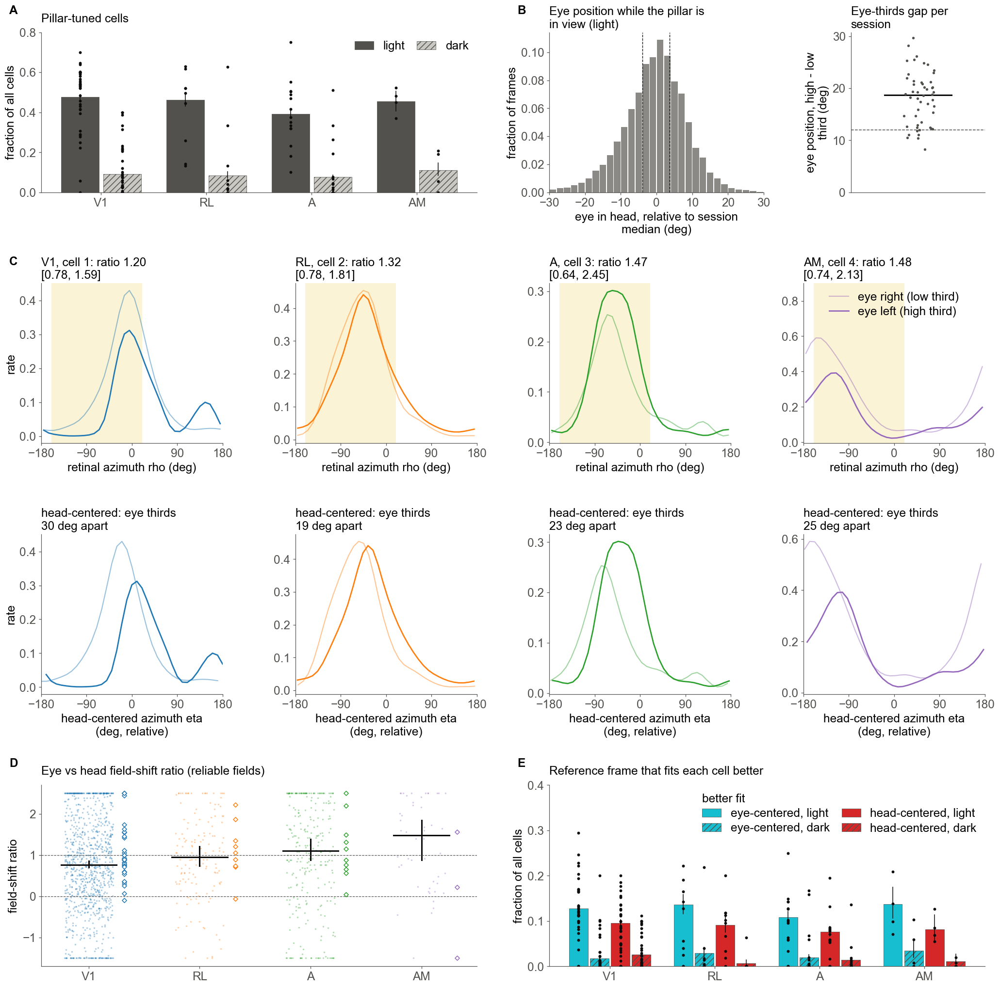

In [242]:
F2 = Composite('Figure2', widths=[3.4] * 4, heights=[3.0, 1.6, 1.6, 5.5], wspace=0.4, hspace=0.55)
f2_de = GridSpecFromSubplotSpec(1, 2, subplot_spec=F2.gs[3, :], width_ratios=[1, 1.8])
f2_bc = GridSpecFromSubplotSpec(1, 2, subplot_spec=F2.gs[0, 2:4], width_ratios=[2.8, 1], wspace=0.5)
f2 = [F2.gs[0, 0:2], f2_bc[0], f2_bc[1], F2.gs[1, :], F2.gs[2, :], f2_de[0], f2_de[1]]
AREAS_Y = [a for a in AREAS if a not in Y_EXCLUDE_AREAS]
for l, s in zip(Y_L, f2):
    F2.letter(l, s)
f2_a = y_redraw(None, {0: y_region(F2.fig, f2[0])}, F2.fig, call=lambda: frac_by_area(
    ['gm_tuned', 'gm_tuned_dark'], ['light', 'dark'], ['#52514e', '#c9c8c2'], hatch=[None, '///'],
    title='Pillar-tuned cells', name='F2A', ylabel='fraction of all cells'))[0]
y_legend_inside(f2_a[0, 0], loc='upper right', ncol=2, ylim=(0, 0.8))
for k, p in enumerate(f2_a[0, 0].patches):
    a, dark = AREAS_Y[k // 2], k % 2 == 1
    p.set_facecolor(Y_AREA_COLORS[a])
    p.set_edgecolor(INK2 if dark else Y_AREA_COLORS[a])
    p.set_hatch(Y_HATCH if dark else None)
f2_a[0, 0].set_ylabel('frac cells')
y_jitter_points(f2_a[0, 0], 0.09, seed=1)
y_front_errorbars(f2_a[0, 0])
f2_a[0, 0].set_xlabel('\u00a0')
y_one_line(f2_a[0, 0].xaxis.label)
f2_b = y_redraw('z0cd0006', {0: y_axes_at(F2.fig, [[f2[1], f2[2]]])}, F2.fig,
                edits=[("color='#d03b3b', lw=0.8, ls='--'", "color=INK2, lw=1.0, ls='--'"),
                       ("ax.axvline(v, color=INK, lw=0.9, ls='--')", "ax.axvline(v, color=INK, lw=2.4, ls='--')")])[0]
f2_b[0, 0].set_xlabel('eye in head (deg)')
f2_b[0, 1].set_ylabel('gap (deg)')
f2_c = y_redraw('w0cd0001', {0: y_axes_at(F2.fig, [[F2.gs[1, j] for j in range(4)],
                                                    [F2.gs[2, j] for j in range(4)]])}, F2.fig, edits=[
    ("lw=1.4, alpha=0.45, label='eye right (low third)'", "lw=2.8, ls=Y_LS_LOW, label='eye right (low third)'"),
    ("lw=1.8, label='eye left (high third)'", "lw=2.8, ls=Y_LS_HIGH, label='eye left (high third)'"),
    ("for x, y, al, lw in ((x_lo, lo, 0.45, 1.4), (x_hi, hi, 1.0, 1.8)):",
     "for x, y, al, lw, ls_ in ((x_lo, lo, 1.0, 2.8, Y_LS_LOW), (x_hi, hi, 1.0, 2.8, Y_LS_HIGH)):"),
    ("ax.plot(x[o], y[o], color=acol(a), lw=lw, alpha=al)", "ax.plot(x[o], y[o], color=acol(a), lw=lw, alpha=al, ls=ls_)")])[0]
y_next_cell = y_cell_titles(f2_c[0], W1_AREAS, 1)
from matplotlib.lines import Line2D
y_legend_above(f2_c[0, 0], ncol=2, labels=['eye right (low third)', 'eye left (high third)'],
               handles=[Line2D([], [], color=INK, lw=2.8, ls=Y_LS_LOW), Line2D([], [], color=INK, lw=2.8, ls=Y_LS_HIGH)])
f2_c[0, -1].get_legend().remove()
for ax in f2_c[0]:
    ax.set_xlabel('retinal azimuth (deg)')
    y_one_line(ax.xaxis.label)
for ax in f2_c[1]:
    ax.set_xlabel('head-centered azimuth (deg)')
from scipy import stats as f2_st
F2F_BOOT = 10000


def f2_holm(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    adj = np.maximum.accumulate(np.minimum(1.0, p[o] * (len(p) - np.arange(len(p)))))
    out = np.empty_like(adj)
    out[o] = adj
    return out


def f2_stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'n.s.'


def f2_ratio_stats():
    rng_ = np.random.default_rng(0)
    rows = {}
    for a in AREAS_Y:
        d = CELLS.loc[(CELLS['area'] == a) & CELLS['eye_reliable'].astype(bool), ['session', 'eye_ratio']].dropna()
        if not len(d):
            continue
        y = d['eye_ratio'].to_numpy(float)
        g = [v['eye_ratio'].to_numpy(float) for _, v in d.groupby('session')]
        meds = np.empty(F2F_BOOT)
        for b in range(F2F_BOOT):
            pick = rng_.integers(0, len(g), len(g))
            meds[b] = np.median(np.concatenate([g[s][rng_.integers(0, len(g[s]), len(g[s]))] for s in pick]))
        two = lambda v: min(1.0, 2 * min((meds <= v).mean(), (meds >= v).mean()))
        rows[a] = {'cells': len(y), 'sessions': len(g), 'median': np.median(y),
                   'median_lo': np.percentile(meds, 2.5), 'median_hi': np.percentile(meds, 97.5),
                   'p_vs0': two(0.0), 'p_vs1': two(1.0),
                   'p_vs0_wilcoxon_cells': f2_st.wilcoxon(y)[1], 'p_vs1_wilcoxon_cells': f2_st.wilcoxon(y - 1)[1]}
    T = pd.DataFrame(rows).T
    T['p_vs0_holm'], T['p_vs1_holm'] = f2_holm(T['p_vs0']), f2_holm(T['p_vs1'])
    kw = f2_st.kruskal(*[CELLS.loc[(CELLS['area'] == a) & CELLS['eye_reliable'].astype(bool), 'eye_ratio'].dropna()
                         for a in T.index])
    return T, kw


F2F_STATS, F2F_KW = f2_ratio_stats()


def f2_ratio_box():
    fig, ax = plt.subplots()
    for i, a in enumerate(AREAS):
        y = CELLS.loc[(CELLS['area'] == a) & CELLS['eye_reliable'].astype(bool), 'eye_ratio'].to_numpy(float)
        y = y[np.isfinite(y)]
        if len(y):
            ax.boxplot([y], positions=[i], widths=0.6, whis=(10, 90), showfliers=False, patch_artist=True,
                       medianprops=dict(color=INK, lw=2.8), boxprops=dict(facecolor=acol(a), edgecolor=INK, lw=1.4),
                       whiskerprops=dict(color=INK, lw=1.4), capprops=dict(color=INK, lw=1.4))
    for r in (0, 1):
        ax.axhline(r, color=INK2, lw=1.0, ls='--', zorder=0)
    tops = []
    for i, a in enumerate(AREAS):
        y = CELLS.loc[(CELLS['area'] == a) & CELLS['eye_reliable'].astype(bool), 'eye_ratio'].to_numpy(float)
        y = y[np.isfinite(y)]
        if a not in F2F_STATS.index or not len(y):
            continue
        top = np.percentile(y, 90)
        tops.append(top)
        s = f2_stars(F2F_STATS.loc[a, 'p_vs0_holm'])
        t = ax.text(i, top, s, ha='center', va='bottom', color=INK)
        t._y_size = 2 * Y_FONT_SIZE if s != 'n.s.' else Y_FONT_SIZE
    lo, hi = ax.get_ylim()
    ax.set_ylim(lo, max(hi, max(tops) + 0.18 * (max(tops) - lo)))
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_xlim(-0.6, len(AREAS) - 0.4)
    ax.set_ylabel('field-shift ratio')
    style(ax)


y_redraw(None, {0: y_region(F2.fig, f2[5])}, F2.fig, call=f2_ratio_box)
f2_f = y_redraw(None, {0: y_region(F2.fig, f2[6])}, F2.fig, call=lambda: frac_by_area(
    ['gm_eye_better', 'gm_eye_better_dark', 'gm_head_better', 'gm_head_better_dark'],
    ['eye-centered, light', 'eye-centered, dark', 'head-centered, light', 'head-centered, dark'],
    [Y_EYE, Y_EYE, Y_HEAD, Y_HEAD], hatch=[None, Y_HATCH, None, Y_HATCH],
    title='Reference frame that fits each cell better', name='F2E', ylabel='fraction of all cells'))[0]
y_legend_inside(f2_f[0, 0], loc='upper right', ncol=2, ylim=(0, 0.4),
                labels=['eye (light)', 'eye (dark)', 'head (light)', 'head (dark)'])
f2_f[0, 0].set_ylabel('frac cells')
y_jitter_points(f2_f[0, 0], 0.045, seed=2)
y_front_errorbars(f2_f[0, 0], lw=1.5)
F2.finish()
display(F2F_STATS.astype(float).round(4))
print('F, Kruskal-Wallis across areas: H = {:.2f}, p = {:.3g}'.format(F2F_KW.statistic, F2F_KW.pvalue))

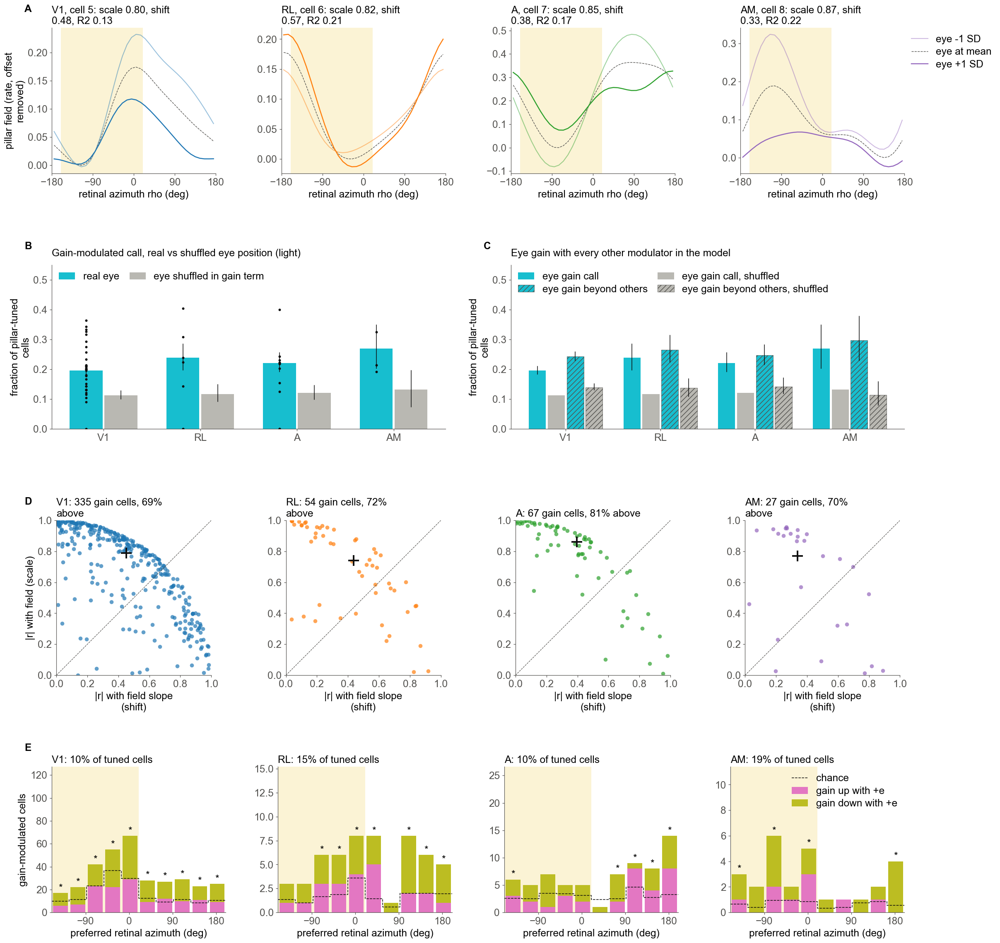

In [243]:
F3 = Composite('Figure3', widths=[3.6] * 4, heights=[2.6, 6.0, 5.6], wspace=0.4, hspace=0.6)
f3_cg = GridSpecFromSubplotSpec(2, 2, subplot_spec=F3.gs[1, 2:4])
f3 = [F3.gs[0, 0], F3.gs[1, 0:2], F3.gs[1, 2:4], F3.gs[2, :]]
for l, s in zip(Y_L, f3):
    F3.letter(l, s)
F3D_EDITS = [
    ("lw=1.4, alpha=0.45, label='eye -1 SD'", "lw=2.8, ls=Y_LS_LOW, label='eye -1 SD'"),
    ("lw=0.9, ls='--', label='eye at mean'", "lw=1.8, label='eye at mean'"),
    ("lw=1.6, label='eye +1 SD'", "lw=2.8, ls=Y_LS_HIGH, label='eye +1 SD'"),
    ("ax.scatter(xs, ys, s=9, color=acol(a), alpha=0.6, lw=0)", "ax.scatter(xs, ys, s=40, color=acol(a), alpha=0.7, lw=0)"),
             ("s=80, marker='+', color=INK, lw=1.6", "s=300, marker='+', color=INK, lw=2.5")]
f3_t1 = y_redraw('q1b0cd01', {0: y_axes_at(F3.fig, [[f3_cg[j // 2, j % 2] for j in range(4)],
                                                     [F3.gs[0, j] for j in range(4)]])}, F3.fig, edits=F3D_EDITS)[0]
y_cell_titles(f3_t1[1], Q_AREAS, 1 + len(w1_pick))
y_retitle(f3_t1[0], ' above diagonal', ' above')
y_legend_above(f3_t1[1, 0], ncol=3, labels=['eye -1 SD', 'eye at mean', 'eye +1 SD'])
f3_t1[1, -1].get_legend().remove()
for ax in f3_t1[1]:
    ax.set_xlabel('retinal azimuth (deg)')
    y_one_line(ax.xaxis.label)
f3_t1[1, 0].set_ylabel('pillar field')
for j, ax in enumerate(f3_t1[0]):
    ax.set_xlabel('|r| shift' if j >= 2 else '')
    ax.set_ylabel('|r| scale' if j % 2 == 0 else '')
Y2_LEG = [plt.Rectangle((0, 0), 1, 1, color=INK2), plt.Rectangle((0, 0), 1, 1, color=Y_SHUF)]
F3C_BARS = """        # Composite: only the eye gain beyond every other modulator, real (area colour) vs its shuffle.
        k, n = int(np.nansum(d['beyond_all'])), int(d['beyond_all'].notna().sum())
        lo, hi = frac_ci(k, n)
        ax.bar(i - 0.18, k / n if n else np.nan, width=0.34, color=acol(a))
        ax.plot([i - 0.18] * 2, [lo, hi], color=INK, lw=1)
        nf = m_null(d)
        ax.bar(i + 0.18, np.nanmean(nf), width=0.34, color=Y_SHUF)
        ax.plot([i + 0.18] * 2, np.nanpercentile(nf, [2.5, 97.5]), color=INK, lw=1)
"""
F3C_OLD = """        for j, (c, col, lab) in enumerate((('j_call', '#1baf7a', 'C4 gain call'), ('beyond_all', '#2a78d6', 'beyond all'))):
            k, n = int(np.nansum(d[c])), int(d[c].notna().sum())
            lo, hi = frac_ci(k, n)
            x = i + (j - 1.5) * 0.2
            ax.bar(x, k / n if n else np.nan, width=0.18, color=col, label=lab if i == 0 else None)
            ax.plot([x, x], [lo, hi], color=INK, lw=1)
        nf = m_null(d)
        x = i + 0.5 * 0.2
        ax.bar(x, np.nanmean(nf), width=0.18, color='#b9b8b2', label='beyond all, eye shuffled' if i == 0 else None)
        ax.plot([x, x], np.nanpercentile(nf, [2.5, 97.5]), color=INK, lw=1)
        x = i + 1.5 * 0.2
        ax.bar(x, JT.loc[a, 'null_mean'], width=0.18, color='#dcdbd6', label='C4 call, eye shuffled (J)' if i == 0 else None)
"""
f3_c = y_redraw('23c228aa', {0: y_axes_at(F3.fig, [[f3[1], None]])}, F3.fig, edits=[(F3C_OLD, F3C_BARS)])[0]
f3_c[0, 0].legend(Y2_LEG, ['real, beyond other modulators', 'eye shuffled in gain term'])
f3_c[0, 0].set_ylim(0, 0.4)
f3_c[0, 0].set_ylabel('frac tuned cells')
f3_e = y_redraw('z0cd0001', {0: y_region(F3.fig, f3[3], wspace=0.3)}, F3.fig, edits=[
    ("color='#2a78d6', label='gain up with +e'", "color=Y_UP, label='gain up with +e'"),
    ("color='#eb6834', label='gain down with +e'", "color=Y_DOWN, label='gain down with +e'"),
    ("ax.bar(cen, up, width", "ax.bar(cen, up / max(tot.sum(), 1), width"),
    ("ax.bar(cen, dn, bottom=up,", "ax.bar(cen, dn / max(tot.sum(), 1), bottom=up / max(tot.sum(), 1),"),
    ("ax.step(edges, np.r_[n * GAIN_P_FLOOR, n[-1] * GAIN_P_FLOOR],",
     "ax.step(edges, np.r_[n * GAIN_P_FLOOR, n[-1] * GAIN_P_FLOOR] / max(tot.sum(), 1),"),
    ("ax.text(cen[j], tot[j], '*'", "ax.text(cen[j], tot[j] / max(tot.sum(), 1), '*'"),
    ("ax.set_ylim(0, max(tot.max(), 1) * 1.45)", "ax.set_ylim(0, max(tot.max(), 1) / max(tot.sum(), 1) * 1.9)")])[0]
f3_e[0, 0].set_ylabel('frac. gain cells')
for ax in f3_e[0]:
    ax.set_xlabel('pref. azimuth (deg)')
    ax.set_box_aspect(1)
f3_e[0, -1].get_legend().remove()
y_legend_above(f3_e[0, 0], ncol=3, labels=None)
for t in f3_e[0, 0].get_legend().get_texts():
    t.set_text(t.get_text().replace(' with +e', ' with leftward eye'))
for j, ax in enumerate(f3_e[0]):
    ax._y_share_group = 'f3d'
    ax._y_top_pad = 0.12
    ax.tick_params(labelleft=(j == 0))
    for t in ax.texts:
        if t.get_text().strip().startswith('*'):
            t._y_size = 2 * Y_FONT_SIZE
F3.finish()

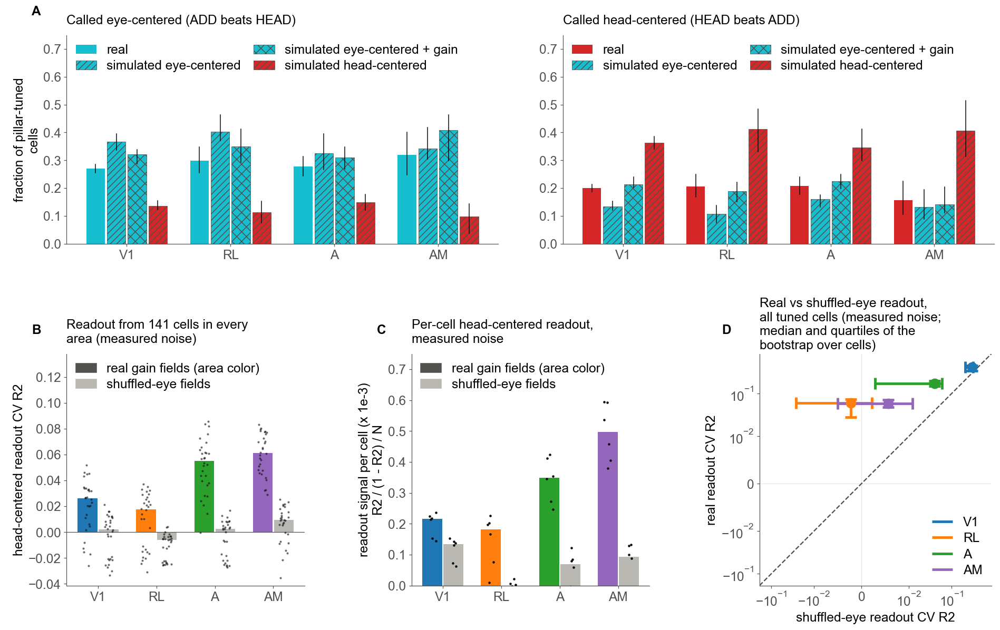

In [244]:
F4 = Composite('Figure4', widths=[16.0], heights=[4.8, 4.0], hspace=0.5)
f4_ab = GridSpecFromSubplotSpec(1, 2, subplot_spec=F4.gs[0, 0], wspace=0.15)
f4_cde = GridSpecFromSubplotSpec(1, 3, subplot_spec=F4.gs[1, 0], wspace=0.1)
f4 = [f4_ab[0], f4_ab[1], f4_cde[0], f4_cde[1], f4_cde[2]]
for l, s in zip(Y_L, f4):
    F4.letter(l, s)
F4A_EDITS = [
    ("""for ax, c, col, ttl in ((axs[0], 'head', '#eb6834', 'Called head-centered (HEAD beats ADD)'),
                            (axs[1], 'eye', '#2a78d6', 'Called eye-centered (ADD beats HEAD)')):""",
     """for ax, c, col, ttl in ((axs[0], 'eye', Y_EYE, 'Called eye-centered (ADD beats HEAD)'),
                            (axs[1], 'head', Y_HEAD, 'Called head-centered (HEAD beats ADD)')):"""),
    ("""kw = {'ADD': dict(color='#8a8986'), 'GAIN': dict(color='#c9c8c2'),
                          'HEAD': dict(color='white', edgecolor=INK2, lw=0.8)}[g]""",
     """kw = {'ADD': dict(color=Y_EYE, hatch=Y_HATCH, edgecolor=INK2, lw=0.5),
                          'GAIN': dict(color=Y_EYE, hatch='xx', edgecolor=INK2, lw=0.5),
                          'HEAD': dict(color=Y_HEAD, hatch=Y_HATCH, edgecolor=INK2, lw=0.5)}[g]""")]
f4_a = y_redraw('s0cd0002', {0: y_axes_at(F4.fig, [[f4[0], f4[1]]])}, F4.fig, edits=F4A_EDITS)[0]
for ax in f4_a[0]:
    y_legend_inside(ax, loc='upper left', ncol=2, ylim=(0, 0.75))
f4_a[0, 0].set_ylabel('frac tuned cells')
Y_SHUF_EDITS = [("else '#dcdbd6'", "else Y_SHUF"), ("edgecolor=acol(a), lw=1)", "edgecolor='none', lw=0)"),
                ("plt.Rectangle((0, 0), 1, 1, color='#dcdbd6')", "plt.Rectangle((0, 0), 1, 1, color=Y_SHUF)")]
f4_b = y_redraw('z0cd0002', {0: y_region(F4.fig, f4[2])}, F4.fig, edits=Y_SHUF_EDITS + [
    ("ax.scatter(x + jit.uniform(-0.08, 0.08, len(v[kind])), v[kind], s=7, color=INK, lw=0, alpha=0.6, zorder=3)",
     "ax.plot([x, x], np.percentile(v[kind], [10, 90]), color=INK, lw=1)")])[0]
f4_c = y_redraw('n1b0cd01', {0: y_axes_at(F4.fig, [[f4[3], None]])}, F4.fig, edits=Y_SHUF_EDITS + [
    ("ax.scatter(x + jit.uniform(-0.07, 0.07, len(v)), v, s=9, color=INK, zorder=3, lw=0)",
     "ax.plot([x, x], np.percentile(v, [10, 90]), color=INK, lw=1)")])[0]
for ax in (f4_b[0, 0], f4_c[0, 0]):
    for t, new in zip(ax.get_legend().get_texts(), ('real', 'shuffled eye')):
        t.set_text(new)
f4_b[0, 0].set_ylabel('readout R\u00b2')
f4_b[0, 0]._y_bottom = 0
f4_c[0, 0].set_ylabel('per-cell signal')
f4_c[0, 0]._y_bottom = 0
f4_c[0, 0].text(0, 1.02, '1e\u22123', transform=f4_c[0, 0].transAxes, ha='left', va='bottom')
for ax in (f4_b[0, 0], f4_c[0, 0]):
    y_legend_above(ax, ncol=2, raise_pts=22)
F4.width_groups.append((f4_cde, [f4_b[0, 0], f4_c[0, 0], None]))
f4_d = y_redraw('n1c0cd01', {0: y_region(F4.fig, f4[4])}, F4.fig, edits=[
    ("fmt='o', ms=5, color=acol(a)", "fmt='o', ms=7, color=acol(a)"),
    ("elinewidth=1.6, capsize=3", "elinewidth=3.2, capsize=0"),
    ("ax.plot(xx, xx, color=INK2, lw=0.8, ls='--')", "ax.plot(xx, xx, color=INK2, lw=1.5, ls='--')")])[0]
f4_d[0, 0].set_xlabel('shuffled-eye R\u00b2')
f4_d[0, 0].set_ylabel('real R\u00b2')
f4_d[0, 0].set_aspect('auto')
for set_t, set_l in ((f4_d[0, 0].set_xticks, f4_d[0, 0].set_xticklabels), (f4_d[0, 0].set_yticks, f4_d[0, 0].set_yticklabels)):
    set_t([-0.1, 0, 0.4])
    set_l(['-0.1', '0', '0.4'])
f4_d[0, 0].minorticks_off()
y_legend_inside(f4_d[0, 0], loc='lower right')
y_legend_above(f4_d[0, 0], ncol=2)
F4.finish()

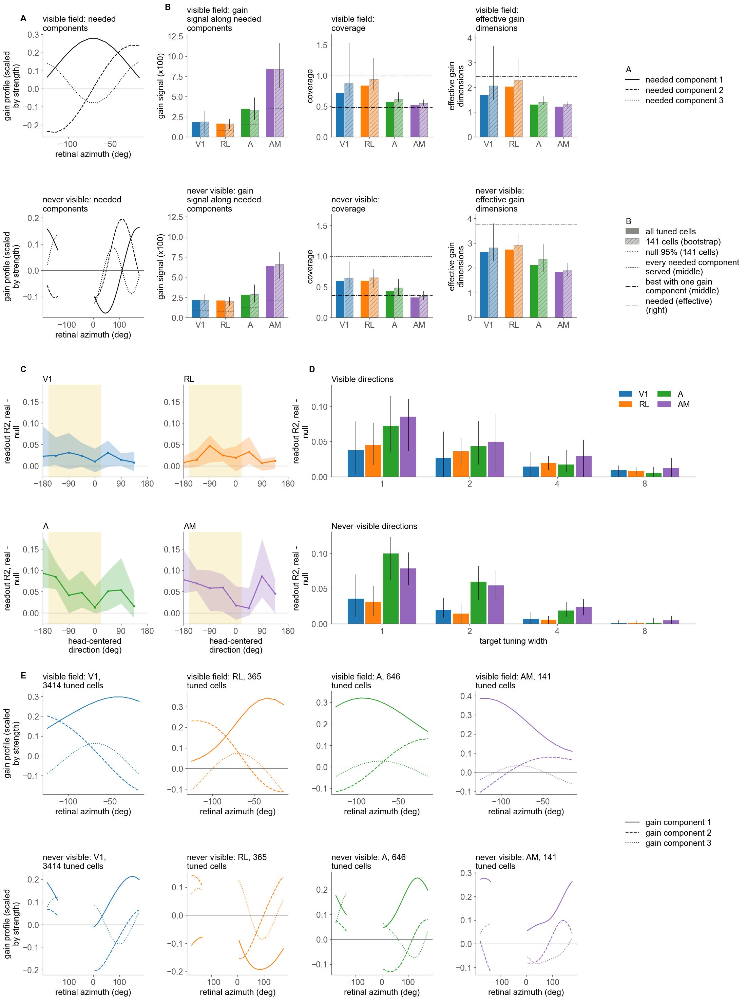

In [259]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

F5_COLS = [1, 1, 1, 1, 0.02]
F5 = Composite('Figure5', widths=[17.5], heights=[8.6, 6.4, 7.4], hspace=0.25)
f5_g1 = GridSpecFromSubplotSpec(2, 5, subplot_spec=F5.gs[0, 0], wspace=0.45, hspace=0.75, width_ratios=F5_COLS)
f5_mid = GridSpecFromSubplotSpec(1, 5, subplot_spec=F5.gs[1, 0], wspace=0.45, width_ratios=F5_COLS)
f5_c = GridSpecFromSubplotSpec(2, 2, subplot_spec=f5_mid[0, 0:2], wspace=0.35, hspace=0.6)
f5_d = GridSpecFromSubplotSpec(2, 1, subplot_spec=f5_mid[0, 2:5], hspace=0.6)
f5 = [f5_g1[:, 0], f5_g1[:, 1], f5_g1[:, 2], f5_g1[:, 3], f5_mid[0, 0:2], f5_mid[0, 2:5], F5.gs[2, 0]]
for l, s_ in zip(Y_L, f5):
    F5.letter(l, s_)


def f5_r2_route(nrows, ncols, kw):
    global f5_e
    f5_e = GridSpecFromSubplotSpec(nrows, ncols, subplot_spec=f5[6], wspace=0.45, hspace=0.75,
                                   width_ratios=[1] * (ncols - 1) + [F5_COLS[-1]])
    return y_axes_at(F5.fig, [[f5_g1[r, 0]] + [f5_e[r, c] for c in range(ncols - 1)] for r in range(nrows)])(nrows, ncols, kw)


Y5_BOOT = 200
F5B_OLD = """                ax.bar(i - 0.18, full[key][0] * scale, width=0.34, color=acol(a),
                       label='all tuned cells' if i == 0 else None)
                ax.bar(i + 0.18, np.nanmedian(boot[key]) * scale, width=0.34, color=acol(a), alpha=0.45, hatch='///',
                       edgecolor=INK2, label='{} cells (bootstrap)'.format(Q_N) if i == 0 else None)
                ax.plot([i + 0.18] * 2, np.nanpercentile(boot[key], [10, 90]) * scale, color=INK, lw=1)
                if key == 'need':
                    ax.plot([i - 0.33, i + 0.35], [np.median(boot['need_null95']) * scale] * 2, color=INK2, lw=1.2,
                            ls=':', label='null 95% ({} cells)'.format(Q_N) if i == 0 else None)
"""
F5B_NEW = """                ax.bar(i, full[key][0] * scale, width=0.6, color=acol(a), label='all tuned cells' if i == 0 else None)
                ax.plot([i] * 2, np.nanpercentile(fullb[key], [2.5, 97.5]) * scale, color=INK, lw=1)
"""
f5_b = y_redraw('aeaf1384', {0: y_axes_at(F5.fig, [[f5_g1[r, 1 + c] for c in range(3)] for r in range(2)])}, F5.fig, edits=[
    (F5B_OLD, F5B_NEW),
    ("            boot = coverage_test(QGP, rows_, cols, n_cells=Q_N, n_boot=QK_BOOT)\n",
     "            boot = coverage_test(QGP, rows_, cols, n_cells=Q_N, n_boot=QK_BOOT)\n"
     "            fullb = None if full is None else coverage_test(QGP, rows_, cols, n_cells=full['n_cells'], n_boot=Y5_BOOT, n_perm=0)\n"),
    ("        axs[ri][1].axhline(1.0, color=INK2, lw=0.8, ls='--', label='every needed component served')\n", ""),
    ("        axs[ri][1].axhline(info['one_shape'], color='#d03b3b', lw=1, ls='--', label='best with one gain component')\n", ""),
    ("        axs[ri][2].axhline(info['need_pr'], color='#d03b3b', lw=1, ls='--', label='needed (effective)')\n", "")])[0]
f5_cax = y_redraw('z0cd0003', {0: y_axes_at(F5.fig, [[f5_c[0, 0], f5_c[0, 1], f5_c[1, 0], f5_c[1, 1]]])}, F5.fig)[0]
for ax in f5_cax[0, :2]:
    ax.set_xlabel('')
f5_cax[0, 2].set_ylabel(f5_cax[0, 0].get_ylabel())
f5_dax = y_redraw('z0cd0004', {0: y_axes_at(F5.fig, [[f5_d[0, 0], f5_d[1, 0]]])}, F5.fig, edits=[
    ("axs[0].set_ylabel('readout R2, real - null')",
     "axs[0].set_ylabel('readout R2, real - null')\n    for ax in axs:\n        ax.set_ylim(bottom=0)"),
    ("ax.set_xlabel('target tuning width (von Mises kappa; higher = narrower)')",
     "ax.set_xlabel('target tuning width')")])[0]
f5_dax[0, 0].set_xlabel('')
for ax in f5_dax[0]:
    ax._y_bottom = 0
f5_dax[0, 1].set_ylabel(f5_dax[0, 0].get_ylabel())
f5_r2 = y_redraw('8b8cfb92', {0: f5_r2_route}, F5.fig, edits=[
    ("color='#d03b3b', ls=ls, lw=1.5", "color=INK, ls=ls, lw=3.5"),
    ("color=acol(a), ls=ls, lw=1.5", "color=acol(a), ls=ls, lw=3.5")])[0]
for ax in f5_r2[:, 1]:
    ax.set_ylabel(f5_r2[0, 0].get_ylabel())
def f5_top(ax):
    v = [p.get_y() + p.get_height() for p in ax.patches]
    v += [np.nanmax(np.asarray(l.get_ydata(), float)) for l in ax.get_lines() if len(l.get_ydata())]
    v = np.asarray(v, float)
    return np.nanmax(v[np.isfinite(v)]) if np.isfinite(v).any() else 1.0


for ax in f5_b.ravel():
    if ax.get_legend() is not None:
        ax.get_legend().remove()
for ax in f5_b[:, 0]:
    ax.set_ylabel('gain signal (x100)')
for ci in range(f5_b.shape[1]):
    top = 1.1 * max(f5_top(ax) for ax in f5_b[:, ci])
    for ax in f5_b[:, ci]:
        ax.set_ylim(0, top)
for ax in f5_r2.ravel():
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    ys = np.concatenate([np.asarray(l.get_ydata(), float) for l in ax.get_lines()
                         if l.get_label().startswith(('gain component', 'needed component'))])
    ys = ys[np.isfinite(ys)]
    if len(ys):
        ax.set_ylim(min(0.0, 1.1 * ys.min()), 1.1 * ys.max())
F5_COMP_LEG = dict(ncol=3, labels=['1', '2', '3'], title='gain component', compact=True)
y_legend_above(f5_r2[0, 0], handles=[Line2D([], [], color=INK, ls=ls, lw=3.5) for ls in ('-', '--', ':')], **F5_COMP_LEG)
for r, where in enumerate(('visible', 'never visible')):
    for c in range(f5_r2.shape[1]):
        f5_r2[r, c].set_ylabel('{}:\ngain profile'.format(where) if c < 2 else '')
    f5_b[r, 0].set_ylabel('{}: gain signal (x100)'.format(where))
    f5_dax[0, r].set_ylabel('{}: real - null R2'.format(where))
for ax in f5_cax[0]:
    if ax.get_ylabel():
        ax.set_ylabel('real - null R2')
for ax in f5_b.ravel():
    ax.tick_params(axis='x', labelrotation=90)
y_legend_above(f5_r2[0, 1], handles=[Line2D([], [], color=INK, ls=ls, lw=3.5) for ls in ('-', '--', ':')], **F5_COMP_LEG)
for ax in f5_r2.ravel():
    ax.set_box_aspect(0.8)


def f5_gap_span(ax):
    lines = [l for l in ax.get_lines() if l.get_label().startswith(('gain component', 'needed component'))]
    if not lines:
        return
    x = np.asarray(lines[0].get_xdata(), float)
    ok = np.any([np.isfinite(np.asarray(l.get_ydata(), float)) for l in lines], 0)
    o = np.argsort(x)
    x, fin = x[o], np.flatnonzero(ok[o])
    for a, b in zip(fin[:-1], fin[1:]):
        if b > a + 1:
            ax.axvspan(x[a], x[b], color='#fbf3d5', lw=0, zorder=0)


for ax in f5_r2[1]:
    f5_gap_span(ax)
F5.finish()

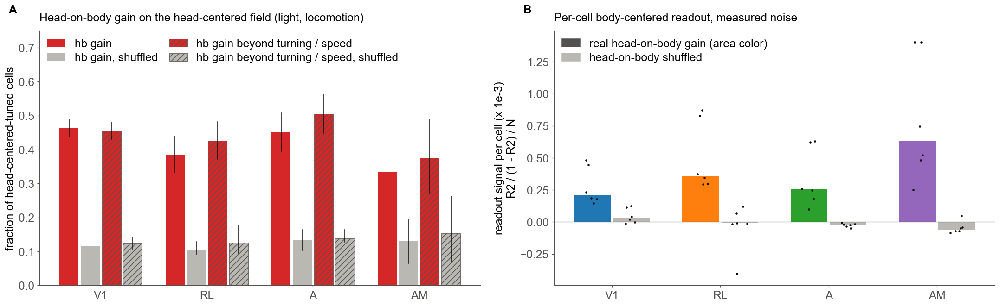

In [ ]:
F6 = Composite('Figure6', widths=[3.6 * 4 / 7] * 7, heights=[5.25], wspace=0.4)
f6 = [F6.gs[0, 0:4], F6.gs[0, 4:7]]
for l, s in zip(Y_L, f6):
    F6.letter(l, s)
F6A_EDITS = [
    ("('call', 'null_call', '#1baf7a', 'hb gain')", "('call', 'null_call', Y_HEAD, 'hb gain')"),
    ("('beyond_turn', 'null_beyond_turn', '#2a78d6', 'hb gain beyond turning / speed')",
     "('beyond_turn', 'null_beyond_turn', Y_HEAD, 'hb gain beyond turning / speed')"),
    ("ax.bar(x, d[col].mean(), width=0.18, color=c_, label=lab if i == 0 else None)",
     "ax.bar(x, d[col].mean(), width=0.18, color=c_, label=lab if i == 0 else None, **(dict(hatch=Y_HATCH, edgecolor=INK2, lw=0.5) if j else {}))"),
    ("color='#b9b8b2', label='hb shuffled' if i == 0 and j == 0 else None)",
     "color=Y_SHUF, label=('hb gain, shuffled', 'hb gain beyond turning / speed, shuffled')[j] if i == 0 else None, **(dict(hatch=Y_HATCH, edgecolor=INK2, lw=0.5) if j else {}))")]
f6_a = y_redraw('79f8fab1', {0: y_axes_at(F6.fig, [[f6[0], None]])}, F6.fig, edits=F6A_EDITS)[0]
y_legend_inside(f6_a[0, 0], loc='upper left', ncol=2, ylim=(0, 0.75))
f6_b = y_redraw('z0cd0005', {0: y_region(F6.fig, f6[1])}, F6.fig, edits=Y_SHUF_EDITS + [
    ("ax.scatter(x + jit.uniform(-0.07, 0.07, len(v)), v, s=9, color=INK, zorder=3, lw=0)",
     "ax.scatter(x + jit.uniform(-0.07, 0.07, len(v)), v, s=9, color=INK, zorder=3, lw=0)\n"
     "            ax.plot([x, x], np.percentile(v, [10, 90]), color=INK, lw=1.5, zorder=4)")])[0]
for t, new in zip(f6_b[0, 0].get_legend().get_texts(), ('real', 'head-on-body shuffled')):
    t.set_text(new)
f6_b[0, 0].set_ylabel('per-cell signal')
f6_b[0, 0].text(0, 1.02, '1e\u22123', transform=f6_b[0, 0].transAxes, ha='left', va='bottom')
y_legend_above(f6_b[0, 0], ncol=2, raise_pts=22)
f6_b[0, 0]._y_bottom = 0
F6.finish()

In [247]:
import importlib
import contextlib
import io
import scipy.sparse as sps
from scipy.ndimage import gaussian_filter

from fm2p.utils import boundary_tuning as btmod
importlib.reload(btmod)

AA_EYE_K = 1.4
AA_MIN_SPEED = 2.0
AA_DRAWS = 100
AA_TEST_DRAWS = 20
AA_RAY_DEG, AA_DIST_STEP, AA_DIST_MAX, AA_MIN_OCC = 3.0, 2.5, 28.0, 1
AA_SMOOTH = 'a2020'
AA_MAX_SHIFT = 90


def aa_scale_eye(D, k):
    D = dict(D)
    D['e'] = na._wrap(k * D['e'])
    D['rho'] = na._wrap(D['eta'] - D['e'])
    return D


def aa_bt_calls(Y, D, xy, arena, mask):
    corners = {k: {'x': arena[i, 0], 'y': arena[i, 1]} for i, k in enumerate(('arenaBL', 'arenaBR', 'arenaTR', 'arenaTL'))}
    data = {'norm_spikes': np.ascontiguousarray(Y.T), 'head_yaw_deg': D['heading'] % 360, 'pupil_from_head': D['e'],
            'head_x': xy[:, 0], 'head_y': xy[:, 1], 'pxls2cm': 10.0, 'speed': D['speed'], **corners}
    bt = btmod.BoundaryTuning(data)
    bt.useinds = mask
    bt.USE_RF_CORRELATION = False
    bt.USE_RF_SHUFFLE_CORRELATION = False
    out = {}
    with contextlib.redirect_stdout(io.StringIO()):
        bt.calc_allo_yaw()
        bt.calc_allo_pupil()
        for key, ang in (('ebc', 'head'), ('rbc', 'gaze')):
            r = bt._run_angle_pipeline(ang, 20, 100)
            cr = [r['criteria'].get('cell_{:03d}'.format(c), {}) for c in range(Y.shape[1])]
            out[key] = r['is_bc'].astype(bool)
            for f, name in (('mean_resultant_length', 'mrl'), ('mrl_99_pctl', 'thr'), ('rf_corr', 'rfc')):
                out['{}_{}'.format(key, name)] = np.array([c.get(f, np.nan) for c in cr], float)
    return out


class AAMaps:

    def __init__(self, D, xy, arena, mask):
        idx = np.flatnonzero(mask)
        self.idx = idx
        e = D['e'][idx]
        rays = np.arange(0.0, 360.0, AA_RAY_DEG)
        self.na_, edges = len(rays), np.arange(0.0, AA_DIST_MAX + AA_DIST_STEP / 2, AA_DIST_STEP)
        self.nd = len(edges) - 1
        dist = wall_distances(xy[idx], (D['heading'][idx] + e)[:, None] + rays[None, :], arena)
        b = np.digitize(dist, edges) - 1
        ok = np.isfinite(dist) & (b >= 0) & (b < self.nd)
        t, a = np.nonzero(ok)
        A = sps.csr_matrix((np.ones(len(t)), (t, a * self.nd + b[t, a])), shape=(len(idx), self.na_ * self.nd))
        q = np.percentile(e, [100 / 3, 200 / 3])
        grp = np.full(len(idx), -1)
        grp[e <= q[0]] = 0
        grp[e >= q[1]] = 1
        yv = D['X'][idx, D['names'].index('yaw_vel')]
        hd = (np.floor((np.nan_to_num(D['heading'][idx]) % 360) / 45)).astype(int) % 8
        strata = hd * 3 + np.digitize(np.nan_to_num(yv), np.nanpercentile(yv, [100 / 3, 200 / 3]))
        w = na._match_weights(grp, strata)
        self.delta = float(np.average(e[grp == 1], weights=np.maximum(w[grp == 1], 1e-9))
                           - np.average(e[grp == 0], weights=np.maximum(w[grp == 0], 1e-9)))
        self.G = []
        for g in (0, 1):
            m = (grp == g).astype(float)
            Aw = sps.diags(w * m) @ A
            occ = np.asarray(Aw.sum(0)).ravel()
            cnt = np.asarray((sps.diags(m) @ A).sum(0)).ravel()
            self.G.append((Aw.T.tocsr(), occ, cnt >= AA_MIN_OCC))
        x = np.arange(360.0) / AA_RAY_DEG
        lo = np.floor(x).astype(int) % self.na_
        f = x - np.floor(x)
        self.U = np.zeros((360, self.na_))
        self.U[np.arange(360), lo] += 1 - f
        self.U[np.arange(360), (lo + 1) % self.na_] += f
        self.n_frames = len(idx)

    def maps(self, Yu):
        out = []
        for At, occ, okb in self.G:
            cnt = np.asarray(At @ Yu).reshape(self.na_, self.nd, -1)
            out.append(np.moveaxis(btmod.smooth_map(cnt, occ.reshape(self.na_, self.nd)), 2, 0))
        return np.stack(out)

    def ratio(self, Yu):
        Ms = self.maps(Yu)
        up = np.einsum('ka,gcad->gckd', self.U, Ms)
        up = up - np.nanmean(up, axis=(2, 3), keepdims=True)
        bad = ~np.isfinite(up)
        up[bad] = 0.0
        lo, hi = up
        xc = np.fft.irfft(np.conj(np.fft.rfft(lo, axis=1)) * np.fft.rfft(hi, axis=1), n=360, axis=1).sum(2)
        lags = np.r_[np.arange(0, AA_MAX_SHIFT + 1), np.arange(360 - AA_MAX_SHIFT, 360)]
        k = np.argmax(xc[:, lags], 1)
        s = np.where(lags[k] > 180, lags[k] - 360, lags[k]).astype(float)
        nrm = np.sqrt((lo ** 2).sum((1, 2)) * (hi ** 2).sum((1, 2)))
        r = xc[np.arange(len(k)), lags[k]] / np.where(nrm > 0, nrm, np.nan)
        flat = ~(nrm > 0)
        s[flat] = np.nan
        return 1.0 + s / self.delta, r


def aa_session(R, path, n_draws=AA_DRAWS, n_test=AA_TEST_DRAWS, seed=0):
    D = aa_scale_eye(R['D'], AA_EYE_K)
    xy, arena = head_position(D, path)
    use, designs = bnd_designs(D, xy, arena)
    mask = use & (D['speed'] > AA_MIN_SPEED)
    if mask.sum() < 3 * NULL_MIN_SHIFT // 2:
        return None
    rng = np.random.default_rng(seed)
    idx = np.flatnonzero(use)
    folds = na._folds(D, use)
    real = aa_bt_calls(D['Y'], D, xy, arena, mask)
    out = {'n_frames': np.array(int(mask.sum())), **real}
    gen = {}
    for g in ('WEYE', 'WHEAD'):
        fit = na._cv(designs[g], D['Y'], folds)
        P = predict(full_fit(designs[g], D['Y'], use, fit['lam']), designs[g][idx])
        gen[g] = (P, D['Y'][idx] - P)
        out[g + '_r2'] = fit['r2']
        Ys = D['Y'].copy()
        Ys[idx] = P + np.roll(gen[g][1], int(rng.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT)), axis=0)
        sc = aa_bt_calls(Ys, D, xy, arena, mask)
        out.update({'{}_{}'.format(g, k): sc[k] for k in ('ebc', 'rbc', 'ebc_mrl', 'ebc_thr', 'rbc_mrl', 'rbc_thr')})
    cells = np.flatnonzero(real['ebc'] | real['rbc'])
    out['cells'] = cells
    if len(cells):
        Mp = AAMaps(D, xy, arena, mask)
        out['delta'] = np.array(Mp.delta)
        pos = np.searchsorted(idx, Mp.idx)
        out['ratio'], out['ratio_r'] = Mp.ratio(D['Y'][Mp.idx][:, cells])
        for g in ('WEYE', 'WHEAD'):
            P, res = gen[g][0][:, cells], gen[g][1][:, cells]
            S = np.zeros((n_draws + n_test, len(cells)))
            for k in range(n_draws + n_test):
                Ys = P + np.roll(res, int(rng.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT)), axis=0)
                S[k] = Mp.ratio(Ys[pos])[0]
            out[g + '_ratio'] = S
    return out


AA = {}
if not RUN_REFITS:
    print('RUN_REFITS is off -- section AA is skipped.')
elif not restore('AA_' + AA_SMOOTH):
    t_all = time.time()
    for i, s in SES.iterrows():
        def run_aa():
            R, why = rebuild_session(s)
            return None if R is None else aa_session(R, s['path'])
        t0 = time.time()
        r = cached(s, 'aaframe', {'k': AA_EYE_K, 'speed': AA_MIN_SPEED, 'draws': AA_DRAWS, 'test': AA_TEST_DRAWS,
                                  'v': 1, 'smooth': AA_SMOOTH}, run_aa)
        if r is not None:
            AA[s['session']] = r
        if time.time() - t0 > 1:
            print('[{}/{}] {}: {:.0f} s'.format(i + 1, len(SES), s['session'], time.time() - t0), flush=True)
    print('EBC frame test: {} sessions in {:.1f} min.'.format(len(AA), (time.time() - t_all) / 60))
    stash('AA_' + AA_SMOOTH, AA=AA)

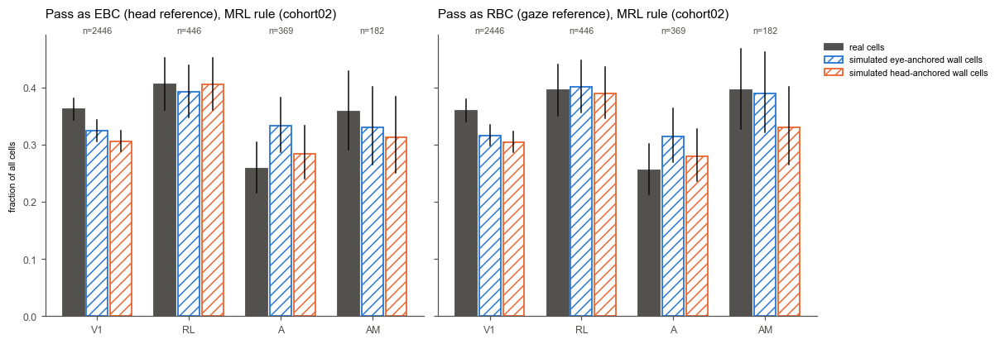

,cells,ebc_real,ebc_eye,ebc_head,rbc_real,rbc_eye,rbc_head
V1,2446.0,0.362,0.325,0.306,0.360,0.316,0.305
RL,446.0,0.406,0.392,0.406,0.395,0.401,0.390
A,369.0,0.257,0.333,0.285,0.255,0.314,0.279
AM,182.0,0.357,0.330,0.313,0.396,0.390,0.330


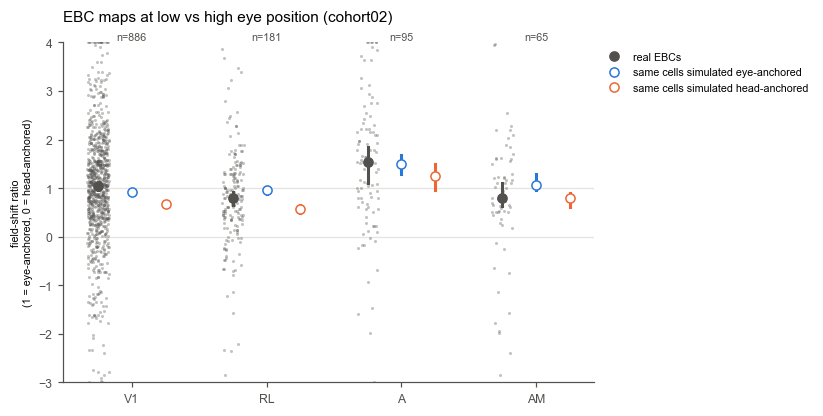

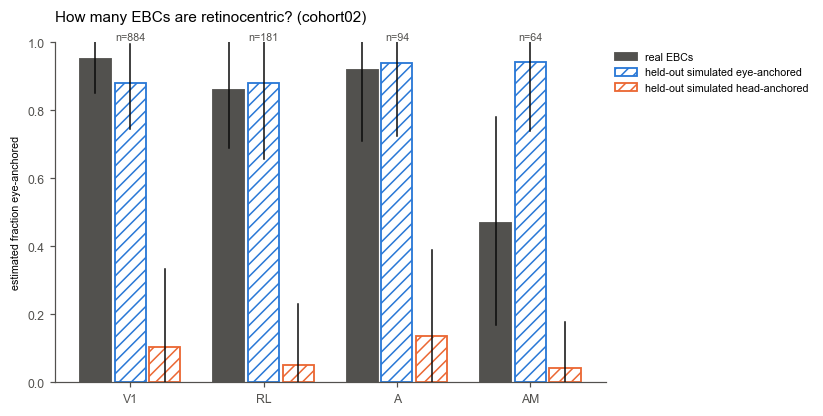

,ebc_tested,delta_e_median,ratio_real,ratio_sim_eye,ratio_sim_head,frac_eye,frac_eye_lo,frac_eye_hi,cal_eye,cal_head,dprime_median,identifiable,eye_call_10to1,head_call_10to1
V1,884.0,25.538,1.040,0.930,0.666,0.95,0.85,1.00,0.881,0.105,0.280,5.0,10.0,1.0
RL,181.0,23.421,0.805,0.957,0.573,0.86,0.69,1.00,0.882,0.052,0.463,0.0,3.0,1.0
A,94.0,15.476,1.540,1.506,1.276,0.92,0.71,1.00,0.938,0.137,0.495,0.0,0.0,1.0
AM,64.0,30.248,0.802,1.071,0.793,0.47,0.17,0.78,0.943,0.041,0.364,4.0,3.0,4.0


ebc_tested  frac_eye    lo    hi  ratio_real
V1 cohort01      1883.0      0.14  0.05  0.23       0.354
   cohort02       884.0      0.95  0.85  1.00       1.040
RL cohort01       101.0      0.40  0.04  0.75       0.348
   cohort02       181.0      0.86  0.69  1.00       0.805
A  cohort01       394.0      0.43  0.23  0.63       0.612
   cohort02        94.0      0.92  0.71  1.00       1.540
AM cohort01        31.0      0.57  0.00  1.00       2.400
   cohort02        64.0      0.47  0.17  0.78       0.802

In [248]:
AA_AREAS = ['V1', 'RL', 'A', 'AM']
AA_SRCS = [('real', ''), ('eye-anchored', 'WEYE_'), ('head-anchored', 'WHEAD_')]
AA_COL = {'real': '#52514e', 'eye-anchored': '#2a78d6', 'head-anchored': '#eb6834'}
AA_PI = np.linspace(0, 1, 101)
AA_COHORT = 'cohort02'


def aa_density(x, S):
    S = np.where(np.isfinite(S), S, np.nan)
    n = np.sum(np.isfinite(S), 0)
    sd = np.nanstd(S, 0)
    iqr = np.subtract(*np.nanpercentile(S, [75, 25], 0))
    h = np.maximum(0.9 * np.minimum(sd, iqr / 1.34) * np.maximum(n, 1) ** -0.2, 0.05)
    z = (x[None] - S) / h[None]
    p = np.nansum(np.exp(-0.5 * z ** 2), 0) / (np.maximum(n, 1) * h * np.sqrt(2 * np.pi))
    return 0.99 * p + 0.01 / 10.0


def aa_cells(AAd):
    rows, E, H = [], [], []
    for sess, r in AAd.items():
        if 'ratio' not in r or not len(r['cells']):
            continue
        c = np.asarray(r['cells'], int)
        rows.append(pd.DataFrame({'session': sess, 'cell': c, 'area': cell_areas(sess, len(r['ebc']))[c],
                                  'ebc': r['ebc'][c].astype(bool), 'rbc': r['rbc'][c].astype(bool),
                                  'ratio': r['ratio'], 'delta': float(r['delta'])}))
        E.append(r['WEYE_ratio'])
        H.append(r['WHEAD_ratio'])
    T = pd.concat(rows, ignore_index=True)
    E, H = np.concatenate(E, 1), np.concatenate(H, 1)
    Er, Hr = E[:AA_DRAWS], H[:AA_DRAWS]
    T['med_eye'], T['med_head'] = np.nanmedian(Er, 0), np.nanmedian(Hr, 0)
    sp = lambda S: np.subtract(*np.nanpercentile(S, [75, 25], 0)) / 1.349
    T['dprime'] = (T['med_eye'] - T['med_head']) / np.sqrt((sp(Er) ** 2 + sp(Hr) ** 2) / 2)
    x = T['ratio'].to_numpy()
    ok = np.isfinite(x)
    T['p_eye'] = np.where(ok, aa_density(np.nan_to_num(x), Er), np.nan)
    T['p_head'] = np.where(ok, aa_density(np.nan_to_num(x), Hr), np.nan)
    T['log_bf'] = np.log(T['p_eye']) - np.log(T['p_head'])
    test = {g: np.stack([aa_density(np.nan_to_num(S[k]), Er) for k in range(AA_DRAWS, len(S))]) for g, S in
            (('eye', E), ('head', H))}
    test_h = {g: np.stack([aa_density(np.nan_to_num(S[k]), Hr) for k in range(AA_DRAWS, len(S))]) for g, S in
              (('eye', E), ('head', H))}
    return T, test, test_h


def aa_pi(pe, ph, n_boot=0, seed=0):
    L = np.log(AA_PI[None] * pe[:, None] + (1 - AA_PI[None]) * ph[:, None])
    est = AA_PI[np.argmax(L.sum(0))]
    if not n_boot:
        return est
    rng_ = np.random.default_rng(seed)
    cnt = rng_.multinomial(len(pe), np.full(len(pe), 1 / len(pe)), size=n_boot)
    return est, np.percentile(AA_PI[np.argmax(cnt @ L, 1)], [2.5, 97.5])


AA_CO = dict(zip(SES['session'], SES['cohort']))
AAF = {s: r for s, r in AA.items() if AA_COHORT is None or str(AA_CO.get(s, '')).startswith(AA_COHORT)}
AA_TAG = '' if AA_COHORT is None else ' ({})'.format(AA_COHORT)
if AAF:
    print('AA1-AA3: {} of {} sessions{}.'.format(len(AAF), len(AA), AA_TAG))
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
    w = 0.26
    rows = {}
    for ax, crit, ttl in ((axs[0], 'ebc', 'Pass as EBC (head reference), MRL rule'),
                          (axs[1], 'rbc', 'Pass as RBC (gaze reference), MRL rule')):
        for i, a in enumerate(AA_AREAS):
            n, k = 0, {s: 0 for s, _ in AA_SRCS}
            for sess, r in AAF.items():
                m = cell_areas(sess, len(r['ebc'])) == a
                n += int(m.sum())
                for src, pre in AA_SRCS:
                    k[src] += int((r[pre + crit].astype(bool) & m).sum())
            for j, (src, _) in enumerate(AA_SRCS):
                x = i + (j - 1) * w
                lo, hi = frac_ci(k[src], n)
                real = src == 'real'
                ax.bar(x, k[src] / max(n, 1), width=w * 0.9, color=AA_COL[src] if real else 'white',
                       edgecolor=AA_COL[src], lw=1.2, hatch=None if real else '///',
                       label=('real cells' if real else 'simulated {} wall cells'.format(src)) if i == 0 else None)
                ax.plot([x, x], [lo, hi], color=INK, lw=1)
                rows.setdefault(a, {'cells': n})['{}_{}'.format(crit, src.split('-')[0])] = k[src] / max(n, 1)
            ax.text(i, 1.0, 'n={}'.format(n), transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                    fontsize=7, color=INK2)
        ax.set_xticks(range(len(AA_AREAS)))
        ax.set_xticklabels(AA_AREAS)
        ax.set_title(ttl + AA_TAG, loc='left', fontsize=10, pad=14)
        style(ax)
    axs[0].set_ylabel('fraction of all cells')
    axs[1].legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    show(fig, 'AA1_ebc_mrl_rule')
    AA1T = pd.DataFrame(rows).T
    display(AA1T.astype(float).round(3))

    AAT, AA_TEST, AA_TEST_H = aa_cells(AAF)
    is_ebc = AAT['ebc'].to_numpy()

    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    for i, a in enumerate(AA_AREAS):
        m = is_ebc & (AAT['area'] == a).to_numpy()
        y = AAT.loc[m, 'ratio'].to_numpy()
        y = y[np.isfinite(y)]
        ax.scatter(i - 0.25 + rng.uniform(-0.08, 0.08, len(y)), np.clip(y, -3, 4), s=4, color=AA_COL['real'],
                   alpha=0.35, lw=0)
        for j, (src, col) in enumerate((('real', 'ratio'), ('eye-anchored', 'med_eye'), ('head-anchored', 'med_head'))):
            v = AAT.loc[m, col].to_numpy(float)
            v = v[np.isfinite(v)]
            if not len(v):
                continue
            lo, hi = boot_ci(v)
            x = i + (j - 1) * 0.25
            ax.plot([x, x], [lo, hi], color=AA_COL[src], lw=2)
            ax.plot(x, np.median(v), 'o', color=AA_COL[src] if src == 'real' else 'white', mec=AA_COL[src], ms=6,
                    label=('real EBCs' if src == 'real' else 'same cells simulated {}'.format(src)) if i == 0 else None)
        ax.text(i, 1.0, 'n={}'.format(int(m.sum())), transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                fontsize=7, color=INK2)
    for yv in (0, 1):
        ax.axhline(yv, color=GRID if GRID else INK2, lw=0.8, zorder=0)
    ax.set_xticks(range(len(AA_AREAS)))
    ax.set_xticklabels(AA_AREAS)
    ax.set_ylim(-3, 4)
    ax.set_ylabel('field-shift ratio\n(1 = eye-anchored, 0 = head-anchored)')
    ax.set_title('EBC maps at low vs high eye position' + AA_TAG, loc='left', fontsize=10, pad=14)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax)
    show(fig, 'AA2_ebc_field_shift')

    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    rows = {}
    w = 0.26
    for i, a in enumerate(AA_AREAS):
        m = is_ebc & (AAT['area'] == a).to_numpy() & np.isfinite(AAT['ratio'].to_numpy())
        if m.sum() < 5:
            continue
        est, (lo, hi) = aa_pi(AAT.loc[m, 'p_eye'].to_numpy(), AAT.loc[m, 'p_head'].to_numpy(), n_boot=1000)
        cal = {g: np.array([aa_pi(AA_TEST[g][k][m], AA_TEST_H[g][k][m]) for k in range(len(AA_TEST[g]))])
               for g in ('eye', 'head')}
        for j, (lab, y, ci, src) in enumerate((
                ('real EBCs', est, (lo, hi), 'real'),
                ('held-out simulated eye-anchored', cal['eye'].mean(), np.percentile(cal['eye'], [2.5, 97.5]),
                 'eye-anchored'),
                ('held-out simulated head-anchored', cal['head'].mean(), np.percentile(cal['head'], [2.5, 97.5]),
                 'head-anchored'))):
            x = i + (j - 1) * w
            real = src == 'real'
            ax.bar(x, y, width=w * 0.9, color=AA_COL[src] if real else 'white', edgecolor=AA_COL[src], lw=1.2,
                   hatch=None if real else '///', label=lab if i == 0 else None)
            ax.plot([x, x], ci, color=INK, lw=1)
        ax.text(i, 1.0, 'n={}'.format(int(m.sum())), transform=ax.get_xaxis_transform(), ha='center', va='bottom',
                fontsize=7, color=INK2)
        d = AAT[m]
        rows[a] = {'ebc_tested': int(m.sum()), 'delta_e_median': d['delta'].median(),
                   'ratio_real': d['ratio'].median(), 'ratio_sim_eye': d['med_eye'].median(),
                   'ratio_sim_head': d['med_head'].median(), 'frac_eye': est, 'frac_eye_lo': lo, 'frac_eye_hi': hi,
                   'cal_eye': cal['eye'].mean(), 'cal_head': cal['head'].mean(),
                   'dprime_median': d['dprime'].median(), 'identifiable': int((d['dprime'] >= 2).sum()),
                   'eye_call_10to1': int((d['log_bf'] > np.log(10)).sum()),
                   'head_call_10to1': int((d['log_bf'] < -np.log(10)).sum())}
    ax.set_xticks(range(len(AA_AREAS)))
    ax.set_xticklabels(AA_AREAS)
    ax.set_ylim(0, 1)
    ax.set_ylabel('estimated fraction eye-anchored')
    ax.set_title('How many EBCs are retinocentric?' + AA_TAG, loc='left', fontsize=10, pad=14)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
    style(ax)
    show(fig, 'AA3_ebc_frac_eye')
    AA3T = pd.DataFrame(rows).T
    display(AA3T.astype(float).round(3))

    AATA, _, _ = aa_cells(AA)
    is_ebc_all = AATA['ebc'].to_numpy()
    AATA['cohort'] = AATA['session'].map(AA_CO)
    rows = {}
    for a in AA_AREAS:
        for co in sorted(AATA['cohort'].dropna().unique()):
            m = is_ebc_all & (AATA['area'] == a).to_numpy() & (AATA['cohort'] == co).to_numpy() & \
                np.isfinite(AATA['ratio'].to_numpy())
            if m.sum() < 20:
                continue
            est, (lo, hi) = aa_pi(AATA.loc[m, 'p_eye'].to_numpy(), AATA.loc[m, 'p_head'].to_numpy(), n_boot=1000)
            rows[(a, co.split('_')[0])] = {'ebc_tested': int(m.sum()), 'frac_eye': est, 'lo': lo, 'hi': hi,
                                           'ratio_real': AATA.loc[m, 'ratio'].median()}
    print('Fraction of EBCs eye-anchored, per cohort (areas x cohorts with >= 20 EBCs):')
    display(pd.DataFrame(rows).T.astype(float).round(3))

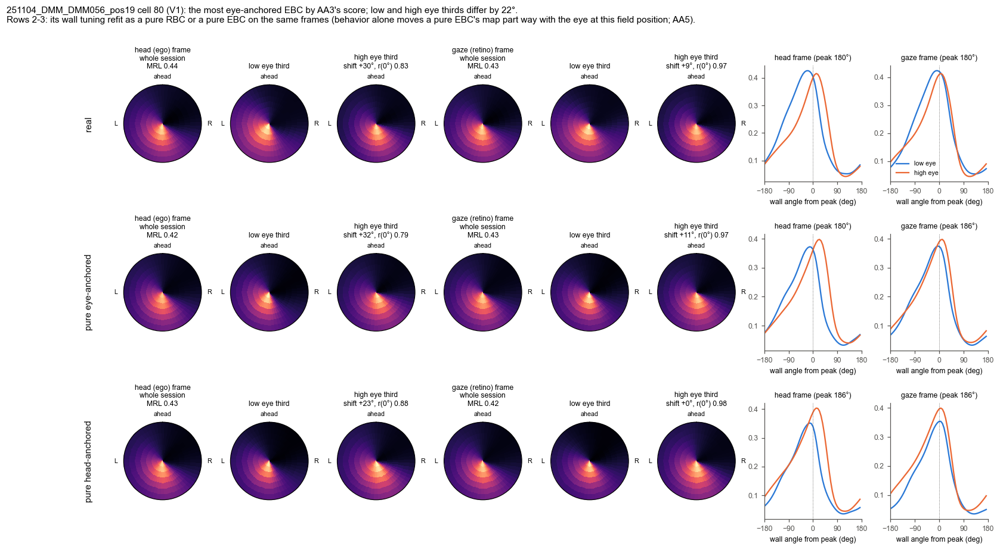

mrl  shift  r_noshift
real               head  0.436   30.0      0.826
                   gaze  0.434    9.0      0.965
pure eye-anchored  head  0.424   32.0      0.792
                   gaze  0.426   11.0      0.967
pure head-anchored head  0.428   23.0      0.883
                   gaze  0.420    0.0      0.983

In [ ]:
AA4_N = 1


class AAMapsF(AAMaps):

    def __init__(self, D, xy, arena, mask, frame):
        super().__init__(D, xy, arena, mask)
        idx = self.idx
        rays = np.arange(0.0, 360.0, AA_RAY_DEG)
        edges = np.arange(0.0, AA_DIST_MAX + AA_DIST_STEP / 2, AA_DIST_STEP)
        ref = D['heading'][idx] + (D['e'][idx] if frame == 'gaze' else 0.0)
        dist = wall_distances(xy[idx], ref[:, None] + rays[None, :], arena)
        b = np.digitize(dist, edges) - 1
        ok = np.isfinite(dist) & (b >= 0) & (b < self.nd)
        t, a = np.nonzero(ok)
        A = sps.csr_matrix((np.ones(len(t)), (t, a * self.nd + b[t, a])), shape=(len(idx), self.na_ * self.nd))
        e = D['e'][idx]
        q = np.percentile(e, [100 / 3, 200 / 3])
        grp = np.full(len(idx), -1)
        grp[e <= q[0]] = 0
        grp[e >= q[1]] = 1
        yv = D['X'][idx, D['names'].index('yaw_vel')]
        hd = (np.floor((np.nan_to_num(D['heading'][idx]) % 360) / 45)).astype(int) % 8
        strata = hd * 3 + np.digitize(np.nan_to_num(yv), np.nanpercentile(yv, [100 / 3, 200 / 3]))
        w = na._match_weights(grp, strata)
        self.G = []
        for wm, m in ((np.ones(len(idx)), np.ones(len(idx))),
                      (w * (grp == 0), (grp == 0).astype(float)), (w * (grp == 1), (grp == 1).astype(float))):
            Aw = sps.diags(wm) @ A
            cnt = np.asarray((sps.diags(m) @ A).sum(0)).ravel()
            self.G.append((Aw.T.tocsr(), np.asarray(Aw.sum(0)).ravel(), cnt >= AA_MIN_OCC))


def aa_shift(lo, hi, U):
    up = [np.einsum('ka,ad->kd', U, M) for M in (lo, hi)]
    up = [u - np.nanmean(u) for u in up]
    ok = np.isfinite(up[0]) & np.isfinite(up[1])
    u0, u1 = [np.where(ok, u, 0.0) for u in up]
    xc = np.fft.irfft(np.conj(np.fft.rfft(u0, axis=0)) * np.fft.rfft(u1, axis=0), n=360, axis=0).sum(1)
    lags = np.r_[np.arange(0, AA_MAX_SHIFT + 1), np.arange(360 - AA_MAX_SHIFT, 360)]
    s = lags[np.argmax(xc[lags])]
    return (s - 360 if s > 180 else s), np.corrcoef(u0[ok], u1[ok])[0, 1]


def aa_mrl(M):
    th = np.radians(np.arange(0.0, 360.0, AA_RAY_DEG))[:, None]
    r = np.where(np.isfinite(M), M, 0.0)
    return np.abs((r * np.exp(1j * th)).sum()) / max(r.sum(), 1e-12)


if AAF:
    AA4C = AAT[AAT['ebc'] & np.isfinite(AAT['ratio'])].sort_values('log_bf', ascending=False)
    _m = (AAT['ebc'] & np.isfinite(AAT['ratio'])).to_numpy()
    AA4_NULLMAX = (np.log(AA_TEST['head']) - np.log(AA_TEST_H['head']))[:, _m].max(1)
    print('Top log LR (eye vs head) among {} EBCs: {:.1f}; best cell when all are simulated head-anchored: {:.1f} '
          '(max over {} simulations {:.1f}).'.format(int(_m.sum()), AA4C['log_bf'].iloc[0], np.median(AA4_NULLMAX),
                                                      len(AA4_NULLMAX), AA4_NULLMAX.max()))

    AA4 = {}
    for _, row in AA4C.head(AA4_N).iterrows():
        s = SES[SES['session'] == row['session']].iloc[0]
        R, why = rebuild_session(s)
        D = aa_scale_eye(R['D'], AA_EYE_K)
        xy, arena = head_position(D, s['path'])
        use, designs = bnd_designs(D, xy, arena)
        mask = use & (D['speed'] > AA_MIN_SPEED)
        c = int(row['cell'])
        idx = np.flatnonzero(use)
        folds = na._folds(D, use)
        acts = {'real': D['Y'][:, [c]]}
        out = {'row': row, 'delta': None, 'maps': {}}
        for fr, lab in (('eye', 'pure eye-anchored'), ('head', 'pure head-anchored')):
            X = wall_features(D, xy, arena, fr)
            fit = na._cv(X, D['Y'][:, [c]], folds)
            P = np.zeros((len(D['Y']), 1))
            P[idx] = predict(full_fit(X, D['Y'][:, [c]], use, fit['lam']), X[idx])
            acts[lab] = P
            out.setdefault('wall_r2', {})[lab] = float(np.ravel(fit['r2'])[0])
        for frame in ('head', 'gaze'):
            Mp = AAMapsF(D, xy, arena, mask, frame)
            out['U'] = Mp.U
            out['delta'] = Mp.delta
            for lab, Yc in acts.items():
                out['maps'][(lab, frame)] = Mp.maps(Yc[Mp.idx])[:, 0]
        AA4[(row['session'], c)] = out

    for (sess, c), out in AA4.items():
        row, dlt = out['row'], out['delta']
        labs = ['real', 'pure eye-anchored', 'pure head-anchored']
        fig = plt.figure(figsize=(17, 9))
        gs = fig.add_gridspec(3, 8, width_ratios=[1, 1, 1, 1, 1, 1, 1.25, 1.25], wspace=0.35, hspace=0.45)
        th = np.radians(np.r_[np.arange(0.0, 360.0, AA_RAY_DEG), 360.0] - AA_RAY_DEG / 2)
        rr = np.arange(0.0, AA_DIST_MAX + AA_DIST_STEP / 2, AA_DIST_STEP)
        stats = {}
        for i, lab in enumerate(labs):
            vmax = np.nanmax([np.nanmax(out['maps'][(lab, f)]) for f in ('head', 'gaze')])
            vmin = np.nanmin([np.nanmin(out['maps'][(lab, f)]) for f in ('head', 'gaze')])
            for j, f in enumerate(('head', 'gaze')):
                W, L, H = out['maps'][(lab, f)]
                sh, r0 = aa_shift(L, H, out['U'])
                stats[(lab, f)] = {'mrl': aa_mrl(W), 'shift': sh, 'r_noshift': r0}
                for k, (M, ttl) in enumerate(((W, 'whole session'), (L, 'low eye third'), (H, 'high eye third'))):
                    ax = fig.add_subplot(gs[i, 3 * j + k], projection='polar')
                    ax.pcolormesh(th, rr, M.T, cmap='magma', vmin=vmin, vmax=vmax,
                                  shading='flat')
                    ax.set_theta_zero_location('N')
                    ax.set_xticks(np.radians([0, 90, 270]))
                    ax.set_xticklabels(['ahead', 'L', 'R'], fontsize=7)
                    ax.tick_params(pad=-2)
                    ax.set_yticks([])
                    ax.grid(False)
                    if j == 0 and k == 0:
                        ax.text(-0.45, 0.5, lab, transform=ax.transAxes, rotation=90, ha='center', va='center',
                                fontsize=10, color=INK)
                    if k == 0:
                        ttl = '{} frame\n{}\nMRL {:.2f}'.format('head (ego)' if f == 'head' else 'gaze (retino)', ttl,
                                                                stats[(lab, f)]['mrl'])
                    elif k == 2:
                        ttl = '{}\nshift {:+d}°, r(0°) {:.2f}'.format(ttl, int(sh), r0)
                    ax.set_title(ttl, fontsize=8, pad=6)
                ax = fig.add_subplot(gs[i, 6 + j])
                ang = np.arange(0.0, 360.0, AA_RAY_DEG)
                pk = ang[np.nanargmax(np.nanmean(W, 1))]
                rel = (ang - pk + 180) % 360 - 180
                o = np.argsort(rel)
                for M, col, nm in ((L, AA_COL['eye-anchored'], 'low eye'), (H, AA_COL['head-anchored'], 'high eye')):
                    ax.plot(rel[o], np.nanmean(M, 1)[o], color=col, lw=1.5, label=nm)
                ax.axvline(0, color=INK2, lw=0.6, ls=':')
                ax.set_xlim(-180, 180)
                ax.set_xticks([-180, -90, 0, 90, 180])
                ax.set_xlabel('wall angle from peak (deg)', fontsize=8)
                ax.set_title('{} frame (peak {:.0f}°)'.format(f, pk), fontsize=8)
                if i == 0 and j == 1:
                    ax.legend(fontsize=7, frameon=False)
                style(ax)
        fig.suptitle('{} cell {} ({}): the most eye-anchored EBC by AA3\'s score; low and high eye thirds differ by '
                     '{:.0f}°.\nRows 2-3: its wall tuning refit as a pure RBC or a pure EBC on the same frames (behavior '
                     'alone moves a pure EBC\'s map part way with the eye at this field position; AA5).'.format(
                         sess, c, row['area'], dlt), fontsize=10, x=0.02, ha='left')
        show(fig, 'AA4_example_{}_{}'.format(sess, c))
        out['stats'] = stats
        print('{} cell {}: field-shift ratio {:.2f} (its eye-anchored simulations: median {:.2f}; head-anchored {:.2f}); '
              'log LR {:.1f}, d\' {:.1f}.'.format(sess, c, row['ratio'], row['med_eye'], row['med_head'], row['log_bf'],
                                                 row['dprime']))
        print('Wall-only model, cross-validated R2: gaze frame {:.3f}, head frame {:.3f}.'.format(
            out['wall_r2']['pure eye-anchored'], out['wall_r2']['pure head-anchored']))
        display(pd.DataFrame(stats).T.round(3))

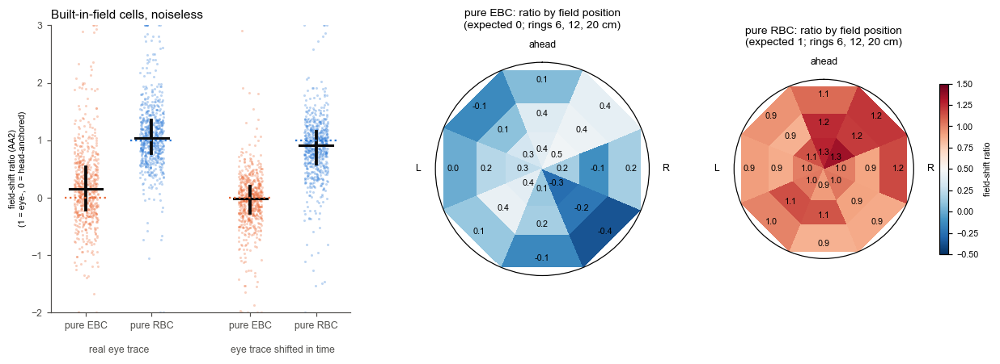

count   25%   50%   75%
cond        kind                         
eye_shifted ebc   624.0 -0.27 -0.02  0.20
            rbc   624.0  0.59  0.91  1.15
real        ebc   624.0 -0.21  0.16  0.53
            rbc   624.0  0.77  1.04  1.34

In [250]:
AA5_THETA = np.arange(0.0, 360.0, 45.0)
AA5_DIST = (6.0, 12.0, 20.0)
AA5_KAPPA, AA5_DSD = 10.0, 3.0


def aa5_fields(D, xy, arena, idx, frame):
    rays = np.arange(0.0, 360.0, 3.0)
    ref = D['heading'][idx] + (D['e'][idx] if frame == 'gaze' else 0.0)
    dist = wall_distances(xy[idx], ref[:, None] + rays[None, :], arena)
    g = np.where(np.isfinite(dist), 1.0, 0.0)
    dist = np.nan_to_num(dist, nan=1e3)
    out = []
    for d0 in AA5_DIST:
        G = g * np.exp(-0.5 * ((dist - d0) / AA5_DSD) ** 2)
        for t0 in AA5_THETA:
            out.append(G @ np.exp(AA5_KAPPA * (np.cos(np.radians(rays - t0)) - 1)))
    return np.stack(out, 1)


def aa5_session(R, path):
    D0 = aa_scale_eye(R['D'], AA_EYE_K)
    xy, arena = head_position(D0, path)
    use, _ = bnd_designs(D0, xy, arena)
    mask = use & (D0['speed'] > AA_MIN_SPEED)
    if mask.sum() < 3 * NULL_MIN_SHIFT // 2:
        return None
    out = {}
    for cond in ('real', 'eye_shifted'):
        D = dict(D0)
        if cond == 'eye_shifted':
            iu = np.flatnonzero(use)
            e = D['e'].copy()
            e[iu] = np.roll(e[iu], len(iu) // 2)
            D['e'] = e
        Mh, Mg = AAMapsF(D, xy, arena, mask, 'head'), AAMapsF(D, xy, arena, mask, 'gaze')
        out[cond + '_delta'] = np.array(Mh.delta)
        for kind, frame in (('ebc', 'head'), ('rbc', 'gaze')):
            F = aa5_fields(D, xy, arena, Mh.idx, frame)
            Wh, Wg = Mh.maps(F), Mg.maps(F)
            sh = np.array([[aa_shift(W[1, i], W[2, i], Mh.U)[0] for i in range(F.shape[1])] for W in (Wh, Wg)])
            out['{}_{}_head_shift'.format(cond, kind)] = sh[0]
            out['{}_{}_gaze_shift'.format(cond, kind)] = sh[1]
    return out


AA5 = {}
for i, s in SES.iterrows():
    if s['session'] not in AAF:
        continue
    def run_aa5():
        R, why = rebuild_session(s)
        return None if R is None else aa5_session(R, s['path'])
    r = cached(s, 'aaverify', {'k': AA_EYE_K, 'speed': AA_MIN_SPEED, 'v': 1, 'smooth': AA_SMOOTH}, run_aa5)
    if r is not None:
        AA5[s['session']] = r
print('AA5: {} sessions.'.format(len(AA5)))

if AA5:
    rows = []
    for sess, r in AA5.items():
        for cond in ('real', 'eye_shifted'):
            d = float(r[cond + '_delta'])
            for kind in ('ebc', 'rbc'):
                for f, rat in enumerate(1 + r['{}_{}_gaze_shift'.format(cond, kind)] / d):
                    rows.append({'session': sess, 'cond': cond, 'kind': kind, 'field': f, 'delta': d,
                                 'theta': AA5_THETA[f % len(AA5_THETA)], 'dist': AA5_DIST[f // len(AA5_THETA)],
                                 'ratio': rat,
                                 'head_shift': r['{}_{}_head_shift'.format(cond, kind)][f] / d})
    AA5T = pd.DataFrame(rows)

    fig = plt.figure(figsize=(13, 4.2))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.4, 1, 1], wspace=0.35)
    ax = fig.add_subplot(gs[0])
    pos = {('real', 'ebc'): 0, ('real', 'rbc'): 1, ('eye_shifted', 'ebc'): 2.5, ('eye_shifted', 'rbc'): 3.5}
    for (cond, kind), x in pos.items():
        v = AA5T.loc[(AA5T.cond == cond) & (AA5T.kind == kind), 'ratio'].to_numpy()
        src = 'head-anchored' if kind == 'ebc' else 'eye-anchored'
        ax.scatter(x + rng.uniform(-0.18, 0.18, len(v)), np.clip(v, -2, 3), s=4, color=AA_COL[src], alpha=0.3,
                   lw=0)
        q = np.percentile(v, [25, 50, 75])
        ax.plot([x, x], q[[0, 2]], color=INK, lw=2.5)
        ax.plot([x - 0.25, x + 0.25], [q[1]] * 2, color=INK, lw=2)
        ax.plot([x - 0.32, x + 0.32], [0 if kind == 'ebc' else 1] * 2, ls=':', color=AA_COL[src], lw=1.5)
    ax.set_xticks(list(pos.values()))
    ax.set_xticklabels(['pure EBC', 'pure RBC'] * 2)
    for x, t in ((0.5, 'real eye trace'), (3.0, 'eye trace shifted in time')):
        ax.text(x, -0.14, t, transform=ax.get_xaxis_transform(), ha='center', fontsize=8, color=INK2)
    ax.set_ylim(-2, 3)
    ax.set_ylabel('field-shift ratio (AA2)\n(1 = eye-, 0 = head-anchored)')
    ax.set_title('Built-in-field cells, noiseless', loc='left', fontsize=10)
    style(ax)
    th = np.radians(np.r_[AA5_THETA, 360.0] - 22.5)
    rr = np.array([0.0, 9.0, 16.0, 24.0])
    for k, kind in enumerate(('ebc', 'rbc')):
        ax = fig.add_subplot(gs[1 + k], projection='polar')
        M = AA5T[(AA5T.cond == 'real') & (AA5T.kind == kind)].groupby(['dist', 'theta'])['ratio'].median()
        M = M.unstack().loc[list(AA5_DIST), list(AA5_THETA)].to_numpy()
        pc = ax.pcolormesh(th, rr, M, cmap='RdBu_r', vmin=-0.5, vmax=1.5, shading='flat')
        for di, d0 in enumerate(AA5_DIST):
            for ti, t0 in enumerate(AA5_THETA):
                ax.text(np.radians(t0), (rr[di] + rr[di + 1]) / 2, '{:.1f}'.format(M[di, ti]), ha='center',
                        va='center', fontsize=7)
        ax.set_theta_zero_location('N')
        ax.set_xticks(np.radians([0, 90, 270]))
        ax.set_xticklabels(['ahead', 'L', 'R'], fontsize=8)
        ax.set_yticks([])
        ax.grid(False)
        ax.set_title('pure {}: ratio by field position\n(expected {}; rings 6, 12, 20 cm)'.format(
            kind.upper(), 0 if kind == 'ebc' else 1), fontsize=9, pad=10)
    fig.colorbar(pc, ax=fig.axes[-1], fraction=0.04, pad=0.12, label='field-shift ratio')
    show(fig, 'AA5_pure_cells')
    AA5S = AA5T.groupby(['cond', 'kind'])['ratio'].describe(percentiles=[0.25, 0.5, 0.75])
    display(AA5S[['count', '25%', '50%', '75%']].round(2))

In [ ]:
from scipy.stats import wilcoxon

if AA5:
    P5 = AA5T.pivot_table(index=['session', 'kind', 'field', 'theta', 'dist'], columns='cond',
                          values='ratio').reset_index()
    P5['diff'] = P5['real'] - P5['eye_shifted']
    fig, ax = plt.subplots(figsize=(6.0, 3.8))
    rows = {}
    for x, (kind, lab, src) in enumerate((('ebc', 'pure EBC', 'head-anchored'), ('rbc', 'pure RBC', 'eye-anchored'))):
        d = P5[(P5['kind'] == kind) & np.isfinite(P5['diff'])]
        v = d['diff'].to_numpy()
        ax.scatter(x - 0.12 + rng.uniform(-0.12, 0.12, len(v)), np.clip(v, -2, 2), s=4, color=AA_COL[src], alpha=0.3,
                   lw=0)
        q = np.percentile(v, [25, 50, 75])
        ax.plot([x - 0.12] * 2, q[[0, 2]], color=INK, lw=2.5)
        ax.plot([x - 0.24, x], [q[1]] * 2, color=INK, lw=2)
        sm = d.groupby('session')['diff'].mean()
        ax.scatter(x + 0.22 + rng.uniform(-0.05, 0.05, len(sm)), sm, marker='D', s=22, color='white',
                   edgecolor=AA_COL[src], lw=1.2, zorder=3, label='session mean' if x == 0 else None)
        rows[lab] = {'cells': len(v), 'median': q[1], 'q25': q[0], 'q75': q[2], 'frac_above_0': (v > 0).mean(),
                     'sessions': len(sm), 'session_mean': sm.mean(), 'sessions_above_0': int((sm > 0).sum()),
                     'p_sessions': wilcoxon(sm).pvalue}
    ax.axhline(0, color=INK2, lw=0.8, ls=':')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['pure EBC', 'pure RBC'])
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(-2, 2)
    ax.set_ylabel('ratio difference\n(real - shifted eye)')
    ax.legend(fontsize=7, frameon=False, loc='upper right')
    ax.set_title('Bias from behavior (built-in-field cells, paired)', loc='left', fontsize=10)
    style(ax)
    show(fig, 'AA5b_paired_difference')
    AA5BT = pd.DataFrame(rows).T
    display(AA5BT.astype(float).round(3))
    display(P5.groupby(['kind', 'dist', 'theta'])['diff'].median().unstack('theta').round(2))

In [251]:
def aa6_session(R, path, cells, n_draws=AA_DRAWS, n_test=AA_TEST_DRAWS, seed=0):
    D = aa_scale_eye(R['D'], AA_EYE_K)
    xy, arena = head_position(D, path)
    use, _ = bnd_designs(D, xy, arena)
    mask = use & (D['speed'] > AA_MIN_SPEED)
    idx = np.flatnonzero(use)
    folds = na._folds(D, use)
    rng_ = np.random.default_rng(seed)
    Mp = AAMaps(D, xy, arena, mask)
    pos = np.searchsorted(idx, Mp.idx)
    Yc = D['Y'][:, cells]
    out = {'cells': np.asarray(cells), 'delta': np.array(Mp.delta)}
    out['ratio'] = Mp.ratio(Yc[Mp.idx])[0]
    for g, fr in (('WEYE', 'eye'), ('WHEAD', 'head')):
        X = wall_features(D, xy, arena, fr)
        fit = na._cv(X, Yc, folds)
        P = predict(full_fit(X, Yc, use, fit['lam']), X[idx])
        res = Yc[idx] - P
        out[g + '_r2'] = np.ravel(fit['r2'])
        out[g + '_ref'] = Mp.ratio(P[pos])[0]
        S = np.zeros((n_draws + n_test, len(cells)))
        for k in range(n_draws + n_test):
            S[k] = Mp.ratio((P + np.roll(res, int(rng_.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT)),
                                         axis=0))[pos])[0]
        out[g + '_ratio'] = S
    return out


AA6 = {}
for i, s in SES.iterrows():
    r0 = AAF.get(s['session'])
    if r0 is None or 'ratio' not in r0 or not len(r0['cells']):
        continue
    def run_aa6():
        R, why = rebuild_session(s)
        return None if R is None else aa6_session(R, s['path'], np.asarray(r0['cells'], int))
    t0 = time.time()
    r = cached(s, 'aawall', {'k': AA_EYE_K, 'speed': AA_MIN_SPEED, 'draws': AA_DRAWS, 'test': AA_TEST_DRAWS,
                             'v': 1, 'smooth': AA_SMOOTH}, run_aa6)
    if r is not None:
        r = dict(r)
        r['ebc'], r['rbc'] = r0['ebc'], r0['rbc']
        AA6[s['session']] = r
    if time.time() - t0 > 1:
        print('{}: {:.0f} s'.format(s['session'], time.time() - t0), flush=True)
print('AA6: {} sessions.'.format(len(AA6)))

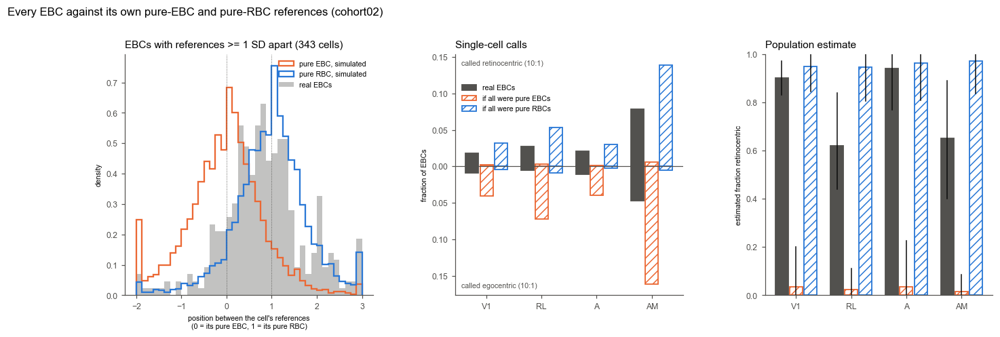

,ebc_tested,n_called_rbc,n_called_ebc,expected_rbc_calls_if_all_ebc,expected_ebc_calls_if_all_rbc,expected_rbc_calls_if_all_rbc,dprime_median,frac_rbc,frac_rbc_lo,frac_rbc_hi,cal_all_ebc,cal_all_rbc
V1,884.0,16.0,8.0,2.35,3.45,28.35,0.496,0.90,0.83,0.97,0.036,0.950
RL,181.0,5.0,1.0,0.65,1.60,9.75,0.770,0.62,0.44,0.84,0.024,0.946
A,94.0,2.0,1.0,0.15,0.25,2.85,0.417,0.94,0.77,1.00,0.036,0.962
AM,64.0,5.0,3.0,0.40,0.35,8.90,1.017,0.65,0.40,0.89,0.016,0.972


In [252]:
AA6_LR = np.log(10)
AA6_MIN_D = 1.0

if AA6:
    T6, TE6, TH6 = aa_cells(AA6)
    T6['ref_eye'] = np.concatenate([AA6[s]['WEYE_ref'] for s in AA6 if len(AA6[s]['cells'])])
    T6['ref_head'] = np.concatenate([AA6[s]['WHEAD_ref'] for s in AA6 if len(AA6[s]['cells'])])
    E6 = np.concatenate([AA6[s]['WEYE_ratio'] for s in AA6 if len(AA6[s]['cells'])], 1)
    H6 = np.concatenate([AA6[s]['WHEAD_ratio'] for s in AA6 if len(AA6[s]['cells'])], 1)
    ok6 = (T6['ebc'] & np.isfinite(T6['ratio'])).to_numpy()
    LRE = np.log(TE6['eye']) - np.log(TH6['eye'])
    LRH = np.log(TE6['head']) - np.log(TH6['head'])

    fig = plt.figure(figsize=(15, 4.2))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1.1, 1.1], wspace=0.35)

    ax = fig.add_subplot(gs[0])
    m = ok6 & (T6['dprime'].abs() >= AA6_MIN_D).to_numpy()
    sep = (T6['med_eye'] - T6['med_head']).to_numpy()
    z = lambda x: (x - T6['med_head'].to_numpy()[m]) / sep[m]
    bins = np.linspace(-2, 3, 41)
    for lab, v, col, real in (('pure EBC, simulated', z(H6[AA_DRAWS:, m]).ravel(), AA_COL['head-anchored'], False),
                              ('pure RBC, simulated', z(E6[AA_DRAWS:, m]).ravel(), AA_COL['eye-anchored'], False),
                              ('real EBCs', z(T6['ratio'].to_numpy()[m]), AA_COL['real'], True)):
        v = np.clip(v[np.isfinite(v)], bins[0], bins[-1])
        ax.hist(v, bins, density=True, histtype='stepfilled' if real else 'step', color=col, alpha=0.35 if real else 1,
                lw=1.5, label=lab)
    for x0 in (0, 1):
        ax.axvline(x0, color=INK2, lw=0.6, ls=':')
    ax.set_xlabel('position between the cell\'s references\n(0 = its pure EBC, 1 = its pure RBC)')
    ax.set_ylabel('density')
    ax.set_title('EBCs with references >= {:g} SD apart ({} cells)'.format(AA6_MIN_D, int(m.sum())), loc='left',
                 fontsize=10)
    ax.legend(fontsize=7, frameon=False, loc='upper right')
    style(ax)

    ax = fig.add_subplot(gs[1])
    w = 0.26
    rows = {}
    for i, a in enumerate(AA_AREAS):
        ma = ok6 & (T6['area'] == a).to_numpy()
        if ma.sum() < 5:
            continue
        lr = T6.loc[ma, 'log_bf'].to_numpy()
        vals = {'real': ((lr > AA6_LR).mean(), (lr < -AA6_LR).mean()),
                'head-anchored': ((LRH[:, ma] > AA6_LR).mean(), (LRH[:, ma] < -AA6_LR).mean()),
                'eye-anchored': ((LRE[:, ma] > AA6_LR).mean(), (LRE[:, ma] < -AA6_LR).mean())}
        for j, src in enumerate(('real', 'head-anchored', 'eye-anchored')):
            x = i + (j - 1) * w
            up, dn = vals[src]
            real = src == 'real'
            kw = dict(width=w * 0.9, color=AA_COL[src] if real else 'white', edgecolor=AA_COL[src], lw=1.2,
                      hatch=None if real else '///')
            ax.bar(x, up, label=({'real': 'real EBCs', 'head-anchored': 'if all were pure EBCs',
                                  'eye-anchored': 'if all were pure RBCs'}[src]) if i == 0 else None, **kw)
            ax.bar(x, -dn, **kw)
        rows[a] = {'ebc_tested': int(ma.sum()), 'n_called_rbc': int((lr > AA6_LR).sum()),
                   'n_called_ebc': int((lr < -AA6_LR).sum()),
                   'expected_rbc_calls_if_all_ebc': (LRH[:, ma] > AA6_LR).sum(1).mean(),
                   'expected_ebc_calls_if_all_rbc': (LRE[:, ma] < -AA6_LR).sum(1).mean(),
                   'expected_rbc_calls_if_all_rbc': (LRE[:, ma] > AA6_LR).sum(1).mean(),
                   'dprime_median': np.nanmedian(np.abs(T6.loc[ma, 'dprime']))}
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(len(AA_AREAS)))
    ax.set_xticklabels(AA_AREAS)
    yl = ax.get_ylim()
    ax.text(-0.45, yl[1] * 0.95, 'called retinocentric (10:1)', fontsize=7, color=INK2, va='top')
    ax.text(-0.45, yl[0] * 0.95, 'called egocentric (10:1)', fontsize=7, color=INK2, va='bottom')
    ticks = ax.get_yticks()
    ax.set_yticks(ticks)
    ax.set_yticklabels(['{:.2f}'.format(abs(t)) for t in ticks])
    ax.set_ylim(yl)
    ax.set_ylabel('fraction of EBCs')
    ax.set_title('Single-cell calls', loc='left', fontsize=10)
    ax.legend(fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(0.0, 0.9))
    style(ax)

    ax = fig.add_subplot(gs[2])
    for i, a in enumerate(AA_AREAS):
        ma = ok6 & (T6['area'] == a).to_numpy()
        if ma.sum() < 5:
            continue
        est, (lo, hi) = aa_pi(T6.loc[ma, 'p_eye'].to_numpy(), T6.loc[ma, 'p_head'].to_numpy(), n_boot=1000)
        cal = {g: np.array([aa_pi(TE6[g][k][ma], TH6[g][k][ma]) for k in range(len(TE6[g]))]) for g in ('eye', 'head')}
        for j, (y, ci, src) in enumerate(((est, (lo, hi), 'real'),
                                          (cal['head'].mean(), np.percentile(cal['head'], [2.5, 97.5]), 'head-anchored'),
                                          (cal['eye'].mean(), np.percentile(cal['eye'], [2.5, 97.5]), 'eye-anchored'))):
            x = i + (j - 1) * w
            real = src == 'real'
            ax.bar(x, y, width=w * 0.9, color=AA_COL[src] if real else 'white', edgecolor=AA_COL[src], lw=1.2,
                   hatch=None if real else '///')
            ax.plot([x, x], ci, color=INK, lw=1)
        rows[a].update({'frac_rbc': est, 'frac_rbc_lo': lo, 'frac_rbc_hi': hi, 'cal_all_ebc': cal['head'].mean(),
                        'cal_all_rbc': cal['eye'].mean()})
    ax.set_xticks(range(len(AA_AREAS)))
    ax.set_xticklabels(AA_AREAS)
    ax.set_ylim(0, 1)
    ax.set_ylabel('estimated fraction retinocentric')
    ax.set_title('Population estimate', loc='left', fontsize=10)
    style(ax)
    fig.suptitle('Every EBC against its own pure-EBC and pure-RBC references{}'.format(AA_TAG), x=0.02, ha='left',
                 fontsize=11, y=1.03)
    show(fig, 'AA6_per_cell')
    AA6T = pd.DataFrame(rows).T
    display(AA6T.astype(float).round(3))

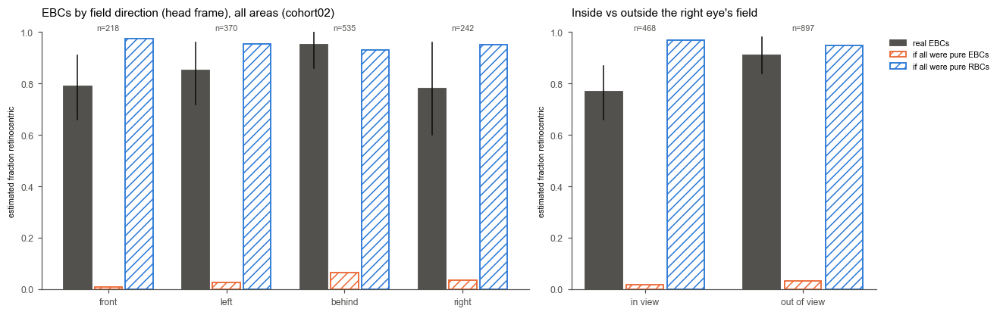

n  frac_rbc    lo    hi  cal_all_ebc  cal_all_rbc  n_called_rbc  n_called_ebc
all areas front        218.0      0.79  0.66  0.91        0.008        0.974           7.0           6.0
          left         370.0      0.85  0.72  0.96        0.026        0.956          12.0           3.0
          behind       535.0      0.95  0.86  1.00        0.065        0.930           7.0           2.0
          right        242.0      0.78  0.60  0.96        0.034        0.951           7.0           2.0
          in view      468.0      0.77  0.66  0.87        0.017        0.970          13.0           8.0
          out of view  897.0      0.91  0.84  0.98        0.034        0.950          20.0           5.0
V1        in view      241.0      0.83  0.67  0.97        0.017        0.960           3.0           4.0
          out of view  643.0      0.93  0.85  1.00        0.046        0.944          13.0           4.0
RL        in view       95.0      0.59  0.30  0.86        0.022        0.935           2.0           0.0
          out of view   86.0      0.66  0.35  0.97        0.039        0.938           3.0           1.0
A         in view       52.0      0.88  0.60  1.00        0.066        0.965           1.0           1.0
          out of view   42.0      1.00  0.85  1.00        0.035        0.902           1.0           0.0
AM        in view       24.0      0.54  0.21  0.85        0.020        0.983           5.0           3.0
          out of view   40.0      0.86  0.44  1.00        0.102        0.880           0.0           0.0

In [253]:
AA7_SECTORS = (('front', -45.0, 45.0), ('left', 45.0, 135.0), ('behind', 135.0, 225.0), ('right', -135.0, -45.0))
AA7_VIEW = (-160.0, 20.0)


def aa_mean_dir(W):
    th = np.radians(np.arange(0.0, 360.0, AA_RAY_DEG))[:, None]
    r = np.nan_to_num(W)
    z = (r * np.exp(1j * th)).sum()
    return float(np.degrees(np.angle(z))), float(np.abs(z) / max(r.sum(), 1e-12))


def aa7_session(R, path, cells):
    D = aa_scale_eye(R['D'], AA_EYE_K)
    xy, arena = head_position(D, path)
    use, _ = bnd_designs(D, xy, arena)
    Mh = AAMapsF(D, xy, arena, use & (D['speed'] > AA_MIN_SPEED), 'head')
    W = Mh.maps(D['Y'][Mh.idx][:, cells])[0]
    d = np.array([aa_mean_dir(w) for w in W]).reshape(-1, 2)
    return {'cells': np.asarray(cells), 'dir': d[:, 0], 'mrl': d[:, 1]}


def aa7_sector(deg):
    deg = (np.asarray(deg) + 180.0) % 360.0 - 180.0
    out = np.full(deg.shape, '', dtype=object)
    for name, lo, hi in AA7_SECTORS:
        x = deg if hi <= 180 else np.where(deg < 0, deg + 360.0, deg)
        out[(x >= lo) & (x < hi)] = name
    return out


def aa_pi_group(T, TE, TH, m, n_boot=1000):
    est, (lo, hi) = aa_pi(T.loc[m, 'p_eye'].to_numpy(), T.loc[m, 'p_head'].to_numpy(), n_boot=n_boot)
    cal = {g: np.array([aa_pi(TE[g][k][m], TH[g][k][m]) for k in range(len(TE[g]))]) for g in ('eye', 'head')}
    return {'n': int(m.sum()), 'frac_rbc': est, 'lo': lo, 'hi': hi, 'cal_all_ebc': cal['head'].mean(),
            'cal_all_rbc': cal['eye'].mean(), 'n_called_rbc': int((T.loc[m, 'log_bf'] > AA6_LR).sum()),
            'n_called_ebc': int((T.loc[m, 'log_bf'] < -AA6_LR).sum())}


def aa_group_bars(ax, groups, ttl):
    w = 0.26
    for i, (lab, r) in enumerate(groups):
        for j, (y, ci, src) in enumerate(((r['frac_rbc'], (r['lo'], r['hi']), 'real'),
                                          (r['cal_all_ebc'], None, 'head-anchored'),
                                          (r['cal_all_rbc'], None, 'eye-anchored'))):
            x = i + (j - 1) * w
            real = src == 'real'
            ax.bar(x, y, width=w * 0.9, color=AA_COL[src] if real else 'white', edgecolor=AA_COL[src], lw=1.2,
                   hatch=None if real else '///', label=({'real': 'real EBCs', 'head-anchored': 'if all were pure EBCs',
                                                          'eye-anchored': 'if all were pure RBCs'}[src]) if i == 0 else None)
            if ci is not None:
                ax.plot([x, x], ci, color=INK, lw=1)
        ax.text(i, 1.0, 'n={}'.format(r['n']), transform=ax.get_xaxis_transform(), ha='center', va='bottom', fontsize=7,
                color=INK2)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([g for g, _ in groups])
    ax.set_ylim(0, 1)
    ax.set_ylabel('estimated fraction retinocentric')
    ax.set_title(ttl, loc='left', fontsize=10, pad=14)
    style(ax)


AA7 = {}
if AA6:
    for i, s in SES.iterrows():
        r6 = AA6.get(s['session'])
        if r6 is None or not len(r6['cells']):
            continue
        def run_aa7():
            R, why = rebuild_session(s)
            return None if R is None else aa7_session(R, s['path'], np.asarray(r6['cells'], int))
        r = cached(s, 'aadir', {'k': AA_EYE_K, 'speed': AA_MIN_SPEED, 'v': 1, 'smooth': AA_SMOOTH}, run_aa7)
        if r is not None:
            AA7[s['session']] = r
    dirs = pd.DataFrame([{'session': sess, 'cell': int(c), 'dir': d, 'map_mrl': m} for sess, r in AA7.items()
                         for c, d, m in zip(r['cells'], r['dir'], r['mrl'])])
    T7 = T6.merge(dirs, on=['session', 'cell'], how='left')
    T7['sector'] = aa7_sector(T7['dir'].to_numpy())
    T7['in_view'] = (T7['dir'] >= AA7_VIEW[0]) & (T7['dir'] <= AA7_VIEW[1])
    ok7 = (T7['ebc'] & np.isfinite(T7['ratio']) & np.isfinite(T7['dir'])).to_numpy()
    print('AA7: {} EBCs with a field direction ({} sessions).'.format(int(ok7.sum()), len(AA7)))

    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1.6, 1]})
    rows = {}
    sec = [(nm, aa_pi_group(T7, TE6, TH6, ok7 & (T7['sector'] == nm).to_numpy())) for nm, _, _ in AA7_SECTORS]
    aa_group_bars(axs[0], sec, 'EBCs by field direction (head frame), all areas' + AA_TAG)
    vis = [(lab, aa_pi_group(T7, TE6, TH6, ok7 & (T7['in_view'] == v).to_numpy()))
           for lab, v in (('in view', True), ('out of view', False))]
    aa_group_bars(axs[1], vis, 'Inside vs outside the right eye\'s field')
    axs[-1].legend(*axs[0].get_legend_handles_labels(), fontsize=7, frameon=False, loc='upper left', bbox_to_anchor=(1.02, 1))
    for ax in axs:
        ax.set_title('', loc='left')
        ax.set_ylabel('estimated fraction\nretinocentric')
    axs[-1].get_legend().remove()
    axs[0].legend(*axs[0].get_legend_handles_labels(), fontsize=7, frameon=False, ncol=3, loc='lower left',
                  bbox_to_anchor=(0, 1.08))
    fig.canvas.draw()
    for ax in axs:
        for t in ax.get_xticklabels() + ax.get_yticklabels() + [ax.xaxis.label, ax.yaxis.label]:
            t.set_fontsize(1.2 * t.get_fontsize())
    fig.tight_layout()
    if SAVE_DIR:
        fig.savefig(os.path.join(SAVE_DIR, 'AA7_by_field_direction.png'), dpi=300, bbox_inches='tight')
    plt.show()
    rows = {('all areas', k): v for k, v in sec + vis}
    for a in AA_AREAS:
        for lab, v in (('in view', True), ('out of view', False)):
            m = ok7 & (T7['area'] == a).to_numpy() & (T7['in_view'] == v).to_numpy()
            if m.sum() >= 15:
                rows[(a, lab)] = aa_pi_group(T7, TE6, TH6, m)
    AA7T = pd.DataFrame(rows).T
    display(AA7T.astype(float).round(3))

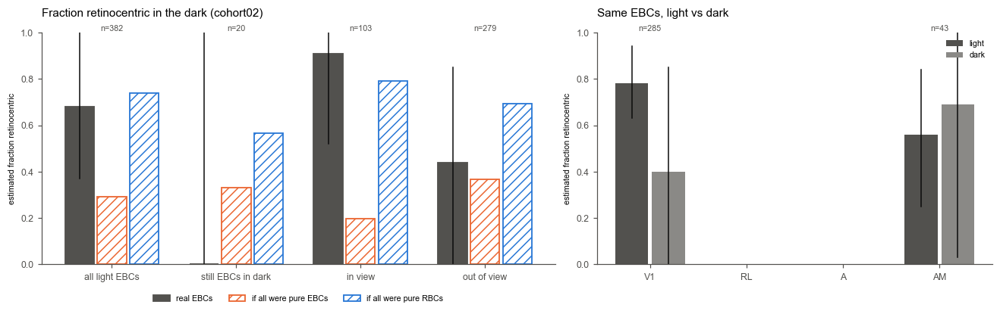

,n,frac_rbc,lo,hi,cal_all_ebc,cal_all_rbc,n_called_rbc,n_called_ebc,median_dprime
all light EBCs,382.0,0.68,0.37,1.00,0.294,0.740,2.0,1.0,0.126
still EBCs in dark,20.0,0.00,0.00,1.00,0.332,0.564,0.0,1.0,0.175
in view,103.0,0.91,0.52,1.00,0.196,0.792,1.0,1.0,0.112
out of view,279.0,0.44,0.00,0.85,0.366,0.693,1.0,0.0,0.131
V1,285.0,0.40,0.00,0.85,0.465,0.672,1.0,0.0,0.123
AM,44.0,0.69,0.00,1.00,0.092,0.845,1.0,1.0,0.136


In [254]:
def aa8_session(R, path, cells, n_draws=AA_DRAWS, n_test=AA_TEST_DRAWS, seed=0):
    D = aa_scale_eye(R['D'], AA_EYE_K)
    xy, arena = head_position(D, path)
    use, _, _, _ = gain_designs(D, (~D['light']) & D['use'])
    Fh, Fe = wall_features(D, xy, arena, 'head'), wall_features(D, xy, arena, 'eye')
    use = use & np.all(np.isfinite(Fh), 1) & np.all(np.isfinite(Fe), 1)
    mask = use & (D['speed'] > AA_MIN_SPEED)
    idx = np.flatnonzero(use)
    if mask.sum() < 3 * NULL_MIN_SHIFT // 2 or len(idx) < 2 * NULL_MIN_SHIFT + 2:
        return None
    folds = na._folds(D, use)
    rng_ = np.random.default_rng(seed)
    Yc = D['Y'][:, cells]
    bt = aa_bt_calls(D['Y'], D, xy, arena, mask)
    Mp = AAMaps(D, xy, arena, mask)
    pos = np.searchsorted(idx, Mp.idx)
    out = {'cells': np.asarray(cells), 'delta': np.array(Mp.delta), 'n_frames': np.array(int(mask.sum())),
           'ratio': Mp.ratio(Yc[Mp.idx])[0], 'mean_rate': np.nanmean(Yc[mask], 0),
           **{'dark_' + k: np.asarray(v)[cells] for k, v in bt.items()},
           'dark_ebc_all': np.asarray(bt['ebc']), 'dark_rbc_all': np.asarray(bt['rbc'])}
    for g, X in (('WEYE', Fe), ('WHEAD', Fh)):
        fit = na._cv(X, Yc, folds)
        P = predict(full_fit(X, Yc, use, fit['lam']), X[idx])
        res = Yc[idx] - P
        out[g + '_r2'] = np.ravel(fit['r2'])
        out[g + '_ref'] = Mp.ratio(P[pos])[0]
        S = np.zeros((n_draws + n_test, len(cells)))
        for k in range(n_draws + n_test):
            S[k] = Mp.ratio((P + np.roll(res, int(rng_.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT)),
                                         axis=0))[pos])[0]
        out[g + '_ratio'] = S
    return out


AA8 = {}
t_all = time.time()
for i, s in SES.iterrows():
    r6 = AA6.get(s['session'])
    if r6 is None or not len(r6['cells']):
        continue
    def run_aa8():
        R, why = rebuild_session(s)
        return None if R is None else aa8_session(R, s['path'], np.asarray(r6['cells'], int))
    t0 = time.time()
    r = cached(s, 'aadark', {'k': AA_EYE_K, 'speed': AA_MIN_SPEED, 'draws': AA_DRAWS, 'test': AA_TEST_DRAWS,
                             'v': 2, 'smooth': AA_SMOOTH}, run_aa8)
    if r is not None:
        r = dict(r)
        r['ebc'], r['rbc'] = r6['ebc'], r6['rbc']
        AA8[s['session']] = r
    if time.time() - t0 > 1:
        print('{}: {:.0f} s'.format(s['session'], time.time() - t0), flush=True)
print('AA8: {} sessions with enough dark frames ({:.1f} min).'.format(len(AA8), (time.time() - t_all) / 60))

if AA8:
    T8, TE8, TH8 = aa_cells(AA8)
    T8['dark_ebc'] = np.concatenate([AA8[s]['dark_ebc'] for s in AA8 if len(AA8[s]['cells'])]).astype(bool)
    T8['dark_mrl'] = np.concatenate([AA8[s]['dark_ebc_mrl'] for s in AA8 if len(AA8[s]['cells'])])
    T8['wall_r2_dark'] = np.concatenate([np.maximum(AA8[s]['WEYE_r2'], AA8[s]['WHEAD_r2']) for s in AA8
                                         if len(AA8[s]['cells'])])
    T8 = T8.merge(T7[['session', 'cell', 'dir', 'in_view', 'sector']], on=['session', 'cell'], how='left')
    T8 = T8.merge(T6[['session', 'cell', 'p_eye', 'p_head', 'log_bf']].rename(
        columns={'p_eye': 'p_eye_light', 'p_head': 'p_head_light', 'log_bf': 'log_bf_light'}), on=['session', 'cell'],
        how='left')
    ok8 = (T8['ebc'] & np.isfinite(T8['ratio'])).to_numpy()
    still = T8.loc[ok8, 'dark_ebc'].mean()
    nb_, kb_ = 0, 0
    for sess, r in AA8.items():
        lt = AAF[sess]
        m = ~(lt['ebc'].astype(bool) | lt['rbc'].astype(bool))
        nb_ += int(m.sum())
        kb_ += int((r['dark_ebc_all'].astype(bool) & m).sum())
    print('Light EBCs passing as EBCs in the dark: {:.2f} ({} of {}); cells not wall-tuned in light: {:.2f} ({} of {}). '
          'Dark eye-third gap median {:.1f} deg; dark frames per session median {:.0f}.'.format(
              still, int(T8.loc[ok8, 'dark_ebc'].sum()), int(ok8.sum()), kb_ / max(nb_, 1), kb_, nb_,
              np.median([float(AA8[s]['delta']) for s in AA8]), np.median([int(AA8[s]['n_frames']) for s in AA8])))

    groups = [('all light EBCs', ok8), ('still EBCs in dark', ok8 & T8['dark_ebc'].to_numpy())]
    groups += [(lab, ok8 & (T8['in_view'] == v).to_numpy()) for lab, v in (('in view', True), ('out of view', False))]
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1.3, 1]})
    res8 = [(lab, aa_pi_group(T8, TE8, TH8, m)) for lab, m in groups if m.sum() >= 10]
    aa_group_bars(axs[0], res8, 'Fraction retinocentric in the dark' + AA_TAG)
    axs[0].legend(fontsize=7, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=3)
    w = 0.38
    both8 = ok8 & np.isfinite(T8['p_eye_light']).to_numpy() & np.isfinite(T8['p_head_light']).to_numpy()
    for i, a in enumerate(AA_AREAS):
        m = both8 & (T8['area'] == a).to_numpy()
        if m.sum() < 10:
            continue
        L = aa_pi(T8.loc[m, 'p_eye_light'].to_numpy(), T8.loc[m, 'p_head_light'].to_numpy(), n_boot=1000)
        Dk = aa_pi(T8.loc[m, 'p_eye'].to_numpy(), T8.loc[m, 'p_head'].to_numpy(), n_boot=1000)
        for j, (lab, (est, ci), col) in enumerate((('light', L, AA_COL['real']), ('dark', Dk, '#8a8986'))):
            x = i + (j - 0.5) * w
            axs[1].bar(x, est, width=w * 0.9, color=col, label=lab if i == 0 else None)
            axs[1].plot([x, x], ci, color=INK, lw=1)
        axs[1].text(i, 1.0, 'n={}'.format(int(m.sum())), transform=axs[1].get_xaxis_transform(), ha='center',
                    va='bottom', fontsize=7, color=INK2)
    axs[1].set_xticks(range(len(AA_AREAS)))
    axs[1].set_xticklabels(AA_AREAS)
    axs[1].set_ylim(0, 1)
    axs[1].set_ylabel('estimated fraction retinocentric')
    axs[1].set_title('Same EBCs, light vs dark', loc='left', fontsize=10, pad=14)
    axs[1].legend(fontsize=7, frameon=False, loc='upper right')
    style(axs[1])
    show(fig, 'AA8_dark')
    rows = {lab: r for lab, r in res8}
    for a in AA_AREAS:
        m = ok8 & (T8['area'] == a).to_numpy()
        if m.sum() >= 10:
            rows[a] = aa_pi_group(T8, TE8, TH8, m)
    AA8T = pd.DataFrame(rows).T
    AA8T['median_dprime'] = [np.nanmedian(np.abs(T8.loc[m, 'dprime'])) for m in
                             [m for lab, m in groups if m.sum() >= 10] +
                             [ok8 & (T8['area'] == a).to_numpy() for a in AA_AREAS
                              if (ok8 & (T8['area'] == a).to_numpy()).sum() >= 10]]
    display(AA8T.astype(float).round(3))

In [ ]:
from scipy.stats import fisher_exact, wilcoxon, mannwhitneyu

SN_ROOT = '/home/dylan/Storage/freely_moving_data/V1PPC'
AB_DRAWS = 5


def sn_labels(sess):
    hits = glob.glob(os.path.join(SN_ROOT, '*', sess, 'sn1', 'sparse_noise_labels_gaussfit.npz'))
    if not hits:
        return None
    return np.load(hits[0])['labels'].astype(int)


def ab_conc(M, occ, ok):
    r = np.clip(np.nan_to_num(M.reshape(len(M), -1)), 0, None)
    p = np.where(ok, occ, 0.0)
    p = p / p.sum()
    lam = (r * p).sum(1, keepdims=True)
    q = r / np.maximum(lam, 1e-12)
    with np.errstate(divide='ignore', invalid='ignore'):
        si = np.nansum(p * q * np.log2(np.where(q > 0, q, 1.0)), 1)
    th = np.radians(np.arange(0.0, 360.0, AA_RAY_DEG))[None, :, None]
    R = np.clip(np.nan_to_num(M), 0, None)
    mrl = np.abs((R * np.exp(1j * th)).sum((1, 2))) / np.maximum(R.sum((1, 2)), 1e-12)
    return si, mrl


def ab_session(R, path, cells, n_draws=AB_DRAWS, seed=0):
    D = aa_scale_eye(R['D'], AA_EYE_K)
    xy, arena = head_position(D, path)
    use, _ = bnd_designs(D, xy, arena)
    mask = use & (D['speed'] > AA_MIN_SPEED)
    idx = np.flatnonzero(use)
    folds = na._folds(D, use)
    rng_ = np.random.default_rng(seed)
    Yc = D['Y'][:, cells]
    Mf = {fr: AAMapsF(D, xy, arena, mask, fr) for fr in ('head', 'gaze')}
    Mr = AAMaps(D, xy, arena, mask)
    pos = np.searchsorted(idx, Mf['head'].idx)

    def conc(Yu):
        out = {}
        for fr, M in Mf.items():
            W = M.maps(Yu)[0]
            _, occ, ok = M.G[0]
            out[fr] = ab_conc(W, occ, ok)
        return out

    out = {'cells': np.asarray(cells)}
    c = conc(Yc[Mf['head'].idx])
    for fr in ('head', 'gaze'):
        out['real_si_' + fr], out['real_mrl_' + fr] = c[fr]
    for g, fr in (('WEYE', 'eye'), ('WHEAD', 'head')):
        X = wall_features(D, xy, arena, fr)
        fit = na._cv(X, Yc, folds)
        P = predict(full_fit(X, Yc, use, fit['lam']), X[idx])
        res = Yc[idx] - P
        c = conc(P[pos])
        for f2 in ('head', 'gaze'):
            out['{}_ref_si_{}'.format(g, f2)], out['{}_ref_mrl_{}'.format(g, f2)] = c[f2]
        keys = ['si_head', 'si_gaze', 'mrl_head', 'mrl_gaze', 'ratio']
        S = {k: np.zeros((n_draws, len(cells))) for k in keys}
        for k in range(n_draws):
            Ys = P + np.roll(res, int(rng_.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT)), axis=0)
            c = conc(Ys[pos])
            S['si_head'][k], S['mrl_head'][k] = c['head']
            S['si_gaze'][k], S['mrl_gaze'][k] = c['gaze']
            S['ratio'][k] = Mr.ratio(Ys[np.searchsorted(idx, Mr.idx)])[0]
        for k in keys:
            out['{}_{}'.format(g, k)] = S[k]
    return out


AB = {}
for i, s in SES.iterrows():
    r6 = AA6.get(s['session'])
    if r6 is None or not len(r6['cells']):
        continue

    def run_ab():
        R, why = rebuild_session(s)
        return None if R is None else ab_session(R, s['path'], np.asarray(r6['cells'], int))
    t0 = time.time()
    r = cached(s, 'abconc', {'k': AA_EYE_K, 'speed': AA_MIN_SPEED, 'draws': AB_DRAWS, 'v': 1, 'smooth': AA_SMOOTH}, run_ab)
    if r is not None:
        AB[s['session']] = r
    if time.time() - t0 > 1:
        print('{}: {:.0f} s'.format(s['session'], time.time() - t0), flush=True)
print('AB: {} sessions.'.format(len(AB)))

ABT = T6[['session', 'cell', 'area', 'ebc', 'ratio', 'log_bf', 'dprime']].copy()
for k in ('real_si_head', 'real_si_gaze', 'real_mrl_head', 'real_mrl_gaze'):
    ABT[k] = np.concatenate([AB[s][k] for s in AA6 if len(AA6[s]['cells'])])
ABS = {}
for g in ('WEYE', 'WHEAD'):
    S = {k: np.concatenate([AB[s]['{}_{}'.format(g, k)] for s in AA6 if len(AA6[s]['cells'])], 1)
         for k in ('si_head', 'si_gaze', 'mrl_head', 'mrl_gaze', 'ratio')}
    S['log_bf'] = np.stack([np.log(aa_density(np.nan_to_num(S['ratio'][k]), E6[:AA_DRAWS]))
                            - np.log(aa_density(np.nan_to_num(S['ratio'][k]), H6[:AA_DRAWS]))
                            for k in range(AB_DRAWS)])
    ABS[g] = S


def ab_gain(si_head, si_gaze, log_bf):
    corr = np.where(log_bf > 0, si_gaze, si_head)
    inc = np.where(log_bf > 0, si_head, si_gaze)
    return 100 * (corr - inc) / ((corr + inc) / 2)


m_ab = (ABT['ebc'] & np.isfinite(ABT['ratio'])).to_numpy()
ABT['gain_si'] = ab_gain(ABT['real_si_head'], ABT['real_si_gaze'], ABT['log_bf'])
ABT['gain_mrl'] = ab_gain(ABT['real_mrl_head'], ABT['real_mrl_gaze'], ABT['log_bf'])
ABT['gaze_minus_head_si'] = 100 * (ABT['real_si_gaze'] - ABT['real_si_head']) / ((ABT['real_si_gaze'] + ABT['real_si_head']) / 2)
rows = {}
for a in AA_AREAS + ['all']:
    ma = m_ab & ((ABT['area'] == a).to_numpy() if a != 'all' else True)
    row = {'ebcs': int(ma.sum())}
    for met in ('si', 'mrl'):
        g = ABT.loc[ma, 'gain_' + met].to_numpy()
        row['real_gain_{}_median'.format(met)] = np.median(g)
        row['real_gain_{}_p'.format(met)] = wilcoxon(g)[1] if len(g) > 5 else np.nan
        for gen, lab in (('WEYE', 'pure_rbc'), ('WHEAD', 'pure_ebc')):
            S = ABS[gen]
            gs = ab_gain(S[met + '_head'][:, ma], S[met + '_gaze'][:, ma], S['log_bf'][:, ma])
            row['{}_gain_{}_median'.format(lab, met)] = np.median(gs)
            true = 100 * ((S[met + '_gaze'] - S[met + '_head']) if gen == 'WEYE' else (S[met + '_head'] - S[met + '_gaze']))[:, ma] \
                / ((S[met + '_gaze'][:, ma] + S[met + '_head'][:, ma]) / 2)
            row['{}_truegain_{}_median'.format(lab, met)] = np.median(true)
    rows[a] = row
ABG = pd.DataFrame(rows).T
display(ABG.astype(float).round(4))

lab_rows = []
for s in AA6:
    L = sn_labels(s)
    if L is None or not len(AA6[s]['cells']):
        continue
    if len(L) != len(AA[s]['ebc']):
        print('{}: {} labels vs {} cells, skipped'.format(s, len(L), len(AA[s]['ebc'])))
        continue
    lab_rows.append(pd.DataFrame({'session': s, 'cell': np.arange(len(L)), 'rf': L, 'area': cell_areas(s, len(L)),
                                  'ebc_any': AA[s]['ebc'].astype(bool)}))
SNL = pd.concat(lab_rows, ignore_index=True)
SNL = SNL[SNL['rf'] >= 0]
ABR = ABT[m_ab].merge(SNL[['session', 'cell', 'rf']], on=['session', 'cell'], how='inner')
ABR['call'] = np.where(ABR['log_bf'] > AA6_LR, 'retinocentric', np.where(ABR['log_bf'] < -AA6_LR, 'egocentric', 'uncalled'))
ABR['lean'] = np.where(ABR['log_bf'] > 0, 'gaze', 'head')
print('Sessions with sparse-noise labels: {} of {} ({} labelled EBCs).'.format(SNL['session'].nunique(), len(AA6), len(ABR)))
rf_rows = {}
for name, sel in (('all labelled cells', SNL), ('non-EBC cells', SNL[~SNL['ebc_any']])):
    rf_rows[name] = {'n': len(sel), 'rf_frac': sel['rf'].mean()}
for col in ('call', 'lean'):
    for v, d in ABR.groupby(col):
        rf_rows['EBC {} = {}'.format(col, v)] = {'n': len(d), 'rf_frac': d['rf'].mean()}
ABRF = pd.DataFrame(rf_rows).T
display(ABRF.round(3))
t = pd.crosstab(ABR['lean'], ABR['rf'])
print('lean gaze vs head, RF yes/no: Fisher p = {:.3g}, odds ratio {:.2f}'.format(fisher_exact(t.to_numpy())[1], fisher_exact(t.to_numpy())[0]))
cc = ABR[ABR['call'] != 'uncalled']
if cc['call'].nunique() == 2:
    t2 = pd.crosstab(cc['call'], cc['rf'])
    print('10:1 calls, RF yes/no:\n{}\nFisher p = {:.3g}'.format(t2, fisher_exact(t2.to_numpy())[1]))
print('log LR, cells with vs without an RF: Mann-Whitney p = {:.3g} (medians {:.2f} vs {:.2f})'.format(
    mannwhitneyu(ABR.loc[ABR['rf'] == 1, 'log_bf'], ABR.loc[ABR['rf'] == 0, 'log_bf'])[1],
    ABR.loc[ABR['rf'] == 1, 'log_bf'].median(), ABR.loc[ABR['rf'] == 0, 'log_bf'].median()))

rel = lambda g, h: 100 * (g - h) / ((g + h) / 2)
rows = {}
rng_ab = np.random.default_rng(0)
for a in AA_AREAS + ['all']:
    ma = m_ab & ((ABT['area'] == a).to_numpy() if a != 'all' else np.isin(ABT['area'], AA_AREAS))
    row = {'ebcs': int(ma.sum())}
    for met in ('si', 'mrl'):
        r = rel(ABT['real_%s_gaze' % met].to_numpy()[ma], ABT['real_%s_head' % met].to_numpy()[ma])
        row['real_%s' % met] = np.median(r)
        b = [np.median(r[rng_ab.integers(0, len(r), len(r))]) for _ in range(2000)]
        row['real_%s_lo' % met], row['real_%s_hi' % met] = np.percentile(b, [2.5, 97.5])
        row['real_%s_p' % met] = wilcoxon(r)[1]
        for gen, lab in (('WEYE', 'pure_rbc'), ('WHEAD', 'pure_ebc')):
            Sg = ABS[gen]
            d = rel(Sg[met + '_gaze'][:, ma], Sg[met + '_head'][:, ma])
            meds = np.median(d, 1)
            row['%s_%s' % (lab, met)] = meds.mean()
            row['%s_%s_lo' % (lab, met)], row['%s_%s_hi' % (lab, met)] = meds.min(), meds.max()
        row['pos_%s' % met] = (row['real_%s' % met] - row['pure_ebc_%s' % met]) / (row['pure_rbc_%s' % met] - row['pure_ebc_%s' % met])
    rows[a] = row
ABD = pd.DataFrame(rows).T
rc = ABR['call'] == 'retinocentric'
t3 = [[int((rc & (ABR['rf'] == 1)).sum()), int((rc & (ABR['rf'] == 0)).sum())],
      [int((~rc & (ABR['rf'] == 1)).sum()), int((~rc & (ABR['rf'] == 0)).sum())]]
eg = ABR['call'] == 'egocentric'
t4 = [[int((rc & (ABR['rf'] == 1)).sum()), int((rc & (ABR['rf'] == 0)).sum())],
      [int((eg & (ABR['rf'] == 1)).sum()), int((eg & (ABR['rf'] == 0)).sum())]]
display(ABD.astype(float).round(3))
print('Retinocentric (10:1) EBCs with a sparse-noise RF: {} of {}; all other labelled EBCs: {} of {} (Fisher p = {:.3g}).'.format(
    t3[0][0], sum(t3[0]), t3[1][0], sum(t3[1]), fisher_exact(t3)[1]))

In [ ]:
from scipy.stats import fisher_exact, mannwhitneyu


def ac_session(R, path, cells):
    D = aa_scale_eye(R['D'], AA_EYE_K)
    xy, arena = head_position(D, path)
    use_l, _ = bnd_designs(D, xy, arena)
    mask_l = use_l & (D['speed'] > AA_MIN_SPEED)
    use_d, _, _, _ = gain_designs(D, (~D['light']) & D['use'])
    Fh, Fe = wall_features(D, xy, arena, 'head'), wall_features(D, xy, arena, 'eye')
    use_d = use_d & np.all(np.isfinite(Fh), 1) & np.all(np.isfinite(Fe), 1)
    mask_d = use_d & (D['speed'] > AA_MIN_SPEED)
    out = {'cells': np.asarray(cells), 'rate_light': np.nanmean(D['Y'][mask_l], 0),
           'rate_dark': np.nanmean(D['Y'][mask_d], 0), 'n_light': np.array(int(mask_l.sum())),
           'n_dark': np.array(int(mask_d.sum()))}
    for fr in ('head', 'gaze'):
        Ml, Md = AAMapsF(D, xy, arena, mask_l, fr), AAMapsF(D, xy, arena, mask_d, fr)
        Wl = Ml.maps(D['Y'][Ml.idx])[0]
        Wd = Md.maps(D['Y'][Md.idx])[0]
        r = np.full(Wl.shape[0], np.nan)
        for c in range(Wl.shape[0]):
            a, b = Wl[c].ravel(), Wd[c].ravel()
            ok = np.isfinite(a) & np.isfinite(b)
            if ok.sum() > 10 and np.std(a[ok]) > 0 and np.std(b[ok]) > 0:
                r[c] = np.corrcoef(a[ok], b[ok])[0, 1]
        out['map_r_' + fr] = r
    return out


AC = {}
for i, s in SES.iterrows():
    if s['session'] not in AA8:
        continue

    def run_ac():
        R, why = rebuild_session(s)
        return None if R is None else ac_session(R, s['path'], np.asarray(AA8[s['session']]['cells'], int))
    t0 = time.time()
    r = cached(s, 'acdark', {'k': AA_EYE_K, 'speed': AA_MIN_SPEED, 'v': 1, 'smooth': AA_SMOOTH}, run_ac)
    if r is not None:
        AC[s['session']] = r
    if time.time() - t0 > 1:
        print('{}: {:.0f} s'.format(s['session'], time.time() - t0), flush=True)
print('AC: {} sessions.'.format(len(AC)))

rows = []
for sess, r in AC.items():
    n = len(r['rate_light'])
    lt = AAF[sess]
    t6 = T6[T6['session'] == sess].set_index('cell')
    lbf = np.full(n, np.nan)
    tested = np.zeros(n, bool)
    lbf[t6.index.to_numpy()] = t6['log_bf'].to_numpy()
    is_ebc = np.zeros(n, bool)
    is_ebc[t6.index.to_numpy()] = (t6['ebc'] & np.isfinite(t6['ratio'])).to_numpy()
    L = sn_labels(sess)
    rows.append(pd.DataFrame({
        'session': sess, 'cell': np.arange(n), 'area': cell_areas(sess, n),
        'wall_tuned_light': lt['ebc'].astype(bool) | lt['rbc'].astype(bool), 'ebc': is_ebc, 'log_bf': lbf,
        'rate_light': r['rate_light'], 'rate_dark': r['rate_dark'], 'map_r_head': r['map_r_head'],
        'map_r_gaze': r['map_r_gaze'], 'dark_ebc': AA8[sess]['dark_ebc_all'].astype(bool),
        'rf': L if L is not None and len(L) == n else np.full(n, -1)}))
ACT = pd.concat(rows, ignore_index=True)
ACT['dark_light'] = ACT['rate_dark'] / ACT['rate_light']
ACT['group'] = np.where(~ACT['wall_tuned_light'], 'not wall-tuned',
                        np.where(ACT['ebc'] & (ACT['log_bf'] > 0), 'EBC, gaze-leaning',
                                 np.where(ACT['ebc'] & (ACT['log_bf'] <= 0), 'EBC, head-leaning', 'other')))
ACT['call'] = np.where(ACT['ebc'] & (ACT['log_bf'] > AA6_LR), 'retinocentric',
                       np.where(ACT['ebc'] & (ACT['log_bf'] < -AA6_LR), 'egocentric', ''))
AC_GROUPS = ['not wall-tuned', 'EBC, head-leaning', 'EBC, gaze-leaning']
rng_ac = np.random.default_rng(0)


def ac_boot(v, stat=np.median, n=2000):
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    b = [stat(v[rng_ac.integers(0, len(v), len(v))]) for _ in range(n)]
    return np.r_[stat(v), np.percentile(b, [2.5, 97.5])]


ACS = {}
for gname in AC_GROUPS + ['retinocentric', 'egocentric']:
    d = ACT[ACT['group'] == gname] if gname in AC_GROUPS else ACT[ACT['call'] == gname]
    k = int(d['dark_ebc'].sum())
    lo, hi = frac_ci(k, len(d))
    ACS[gname] = {'n': len(d), 'still_ebc': np.array([k / max(len(d), 1), lo, hi]),
                  'dark_light': ac_boot(d['dark_light']), 'map_r_head': ac_boot(d['map_r_head']),
                  'map_r_gaze': ac_boot(d['map_r_gaze'])}
ACST = pd.DataFrame({g: {'n': v['n'], 'still_ebc': v['still_ebc'][0], 'still_lo': v['still_ebc'][1],
                         'still_hi': v['still_ebc'][2], 'dark_light': v['dark_light'][0],
                         'map_r_head': v['map_r_head'][0], 'map_r_gaze': v['map_r_gaze'][0]}
                     for g, v in ACS.items()}).T
display(ACST.astype(float).round(3))
eb = ACT[ACT['group'].isin(AC_GROUPS[1:])]
t = pd.crosstab(eb['group'], eb['dark_ebc'])
print('Still EBC in the dark, gaze- vs head-leaning: Fisher p = {:.3g}'.format(fisher_exact(t.to_numpy())[1]))
for col in ('dark_light', 'map_r_head', 'map_r_gaze'):
    a_ = eb.loc[eb['group'] == 'EBC, gaze-leaning', col].dropna()
    b_ = eb.loc[eb['group'] == 'EBC, head-leaning', col].dropna()
    print('{}: gaze-leaning median {:.3f} vs head-leaning {:.3f}, Mann-Whitney p = {:.3g}'.format(
        col, a_.median(), b_.median(), mannwhitneyu(a_, b_)[1]))
eb = eb.assign(r_diff=eb['map_r_gaze'] - eb['map_r_head'])
for g_, d in eb.groupby('group'):
    print('{}: dark-light map r, gaze minus head frame: median {:.3f}'.format(g_, d['r_diff'].median()))

RFS = {}
for name, d in (('non-EBC cells', SNL[~SNL['ebc_any']]), ('EBC, head-leaning', ABR[ABR['lean'] == 'head']),
                ('EBC, gaze-leaning', ABR[ABR['lean'] == 'gaze']), ('egocentric', ABR[ABR['call'] == 'egocentric']),
                ('retinocentric', ABR[ABR['call'] == 'retinocentric'])):
    k = int((d['rf'] == 1).sum())
    lo, hi = frac_ci(k, len(d))
    RFS[name] = {'n': len(d), 'k': k, 'rf': np.array([k / max(len(d), 1), lo, hi])}
display(pd.DataFrame({g: {'n': v['n'], 'with RF': v['k'], 'frac': v['rf'][0]} for g, v in RFS.items()}).T)

from scipy.stats import fisher_exact, mannwhitneyu
AC_PAIRS = [(0, 1), (0, 2), (1, 2)]


def holm(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    adj = np.maximum.accumulate(np.minimum(1.0, p[o] * (len(p) - np.arange(len(p)))))
    out = np.empty_like(adj)
    out[o] = adj
    return out


rf_sets = [SNL[~SNL['ebc_any']]['rf'].to_numpy(), ABR.loc[ABR['lean'] == 'head', 'rf'].to_numpy(),
           ABR.loc[ABR['lean'] == 'gaze', 'rf'].to_numpy()]
g3 = [ACT[ACT['group'] == g] for g in AC_GROUPS]
AC_P = {}
cnt = lambda v: [int((v == 1).sum()), int((v == 0).sum())]
AC_P['A'] = holm([fisher_exact([cnt(rf_sets[i]), cnt(rf_sets[j])])[1] for i, j in AC_PAIRS])
AC_P['B'] = holm([fisher_exact([[int(g3[i]['dark_ebc'].sum()), int((~g3[i]['dark_ebc']).sum())],
                                [int(g3[j]['dark_ebc'].sum()), int((~g3[j]['dark_ebc']).sum())]])[1] for i, j in AC_PAIRS])
for panel, col in (('C', 'dark_light'), ('D', 'map_r_head')):
    AC_P[panel] = holm([mannwhitneyu(g3[i][col].replace([np.inf, -np.inf], np.nan).dropna(),
                                     g3[j][col].replace([np.inf, -np.inf], np.nan).dropna())[1] for i, j in AC_PAIRS])
print('Pairwise p (Holm), pairs (0,1), (0,2), (1,2) of', AC_GROUPS, ':', {k: np.round(v, 4) for k, v in AC_P.items()})

In [ ]:
AD_BOOT = 2000


def ad_scale(real, lo_ref, hi_ref):
    return (real - lo_ref) / (hi_ref - lo_ref)


def ad_calls(lr_real, lr_head, lr_eye):
    net = lambda L: np.mean(L > AA6_LR, -1) - np.mean(L < -AA6_LR, -1)
    return ad_scale(net(lr_real), net(lr_head).mean(), net(lr_eye).mean())


def ad_conc(d_real, d_head, d_eye):
    return ad_scale(np.median(d_real), np.median(d_head, 1).mean(), np.median(d_eye, 1).mean())


rel_ad = lambda g, h: 100 * (g - h) / ((g + h) / 2)
CONC_REAL = rel_ad(ABT['real_si_gaze'].to_numpy(), ABT['real_si_head'].to_numpy())
CONC_EYE = rel_ad(ABS['WEYE']['si_gaze'], ABS['WEYE']['si_head'])
CONC_HEAD = rel_ad(ABS['WHEAD']['si_gaze'], ABS['WHEAD']['si_head'])
LR_REAL = T6['log_bf'].to_numpy()
rng_ad = np.random.default_rng(0)
ADS = {}
for a in AA_AREAS + ['all']:
    m = ok6 & ((T6['area'] == a).to_numpy() if a != 'all' else np.isin(T6['area'], AA_AREAS))
    ix = np.flatnonzero(m)
    est = {'calls': ad_calls(LR_REAL[ix], LRH[:, ix], LRE[:, ix]),
           'conc': ad_conc(CONC_REAL[ix], CONC_HEAD[:, ix], CONC_EYE[:, ix])}
    boot = {k: np.empty(AD_BOOT) for k in est}
    for b in range(AD_BOOT):
        r = ix[rng_ad.integers(0, len(ix), len(ix))]
        boot['calls'][b] = ad_calls(LR_REAL[r], LRH[:, r], LRE[:, r])
        boot['conc'][b] = ad_conc(CONC_REAL[r], CONC_HEAD[:, r], CONC_EYE[:, r])
    ADS[a] = {k: np.r_[est[k], np.nanpercentile(boot[k], [2.5, 97.5])] for k in est}
    ADS[a]['n'] = len(ix)
ADT = pd.DataFrame({a: {'n': v['n'], **{'{}_{}'.format(k, s): v[k][i] for k in ('calls', 'conc')
                                        for i, s in enumerate(('est', 'lo', 'hi'))}} for a, v in ADS.items()}).T
display(ADT.astype(float).round(3))

In [ ]:
# AE  Eye-in-head vs gaze-in-world gain. Head-fixed, eye-in-head (e) and gaze-in-world (heading + e) are the same
# variable up to a constant; freely moving, heading spans 360 deg against e's ~9 deg SD, so they come apart.
# Both hypotheses get the same heading gain on the retinal field, so a heading-only modulation cannot decide:
#   eye-in-head   = base + vm(rho) x [cos h, sin h] + vm(rho) x z(e)      (one eye gain at every heading)
#   gaze-in-world = base + vm(rho) x [cos g, sin g],  g = h + e           (eye slope = heading slope, sign flips
#                                                                           between opposite headings)
# base = ADD + 5 drift cosines + additive [cos g, sin g]. Calls on J's tuned cells: eye_better / gw_better
# (head-to-head), eye_beyond_gw (e still adds after the gaze-in-world gain; e-shuffle null), eye_varies (an
# e x heading gain adds beyond the eye-in-head model). opp_cos: the eye gain profile fit separately in 4 heading
# quadrants, uncentred cosine between opposite quadrants (+1 eye-in-head, negative for gaze-in-world).
# Calibration: every cell simulated from its own eye-in-head and gaze-in-world fits plus its own shifted residual.
AE_NULL_SHUFFLES = 10
AE_SIM_DRAWS = 2
AE_QUADRANTS = 4
AE_GRID = np.arange(-160.0, 20.0 + 1e-9, 10.0)   # right eye's visible field, where the gain profiles are compared
AE_GAZE_EYE_SCALE = 1.0   # gaze = heading + scale x e; 1.4 = the eye-scale correction Figure 6 uses (robustness run)


def _cs(deg):
    a = np.radians(deg)
    return np.c_[np.cos(a), np.sin(a)]


def ae_designs(D):
    """ Base and gain columns for the eye-in-head vs gaze-in-world test (light frames). """
    use, mz, base, _ = gain_designs(D, D['light'] & D['use'])
    gw = D['heading'] + AE_GAZE_EYE_SCALE * D['e']   # gaze-in-world direction: allo pillar dir = heading + eta = gaze + rho
    use = use & np.isfinite(gw)
    nm = D['names']
    vr = na._vm_basis(D['rho'])
    prod = lambda M: np.concatenate([vr * M[:, [j]] for j in range(M.shape[1])], 1)
    # Heading bumps are already in NUIS; the additive gaze-in-world direction goes in too, so a gain term
    # can only win by changing the pillar field's height.
    B = np.c_[base['ADD'], D['X'][:, [nm.index('drift{}'.format(k)) for k in range(1, 6)]], np.nan_to_num(_cs(gw))]
    q = (np.floor(((np.nan_to_num(D['heading']) + 180.0) % 360.0) / (360.0 / AE_QUADRANTS))).astype(int) % AE_QUADRANTS
    Q = np.stack([q == k for k in range(AE_QUADRANTS)], 1).astype(float)
    return {'use': use, 'mz': mz, 'gw': gw, 'hd': D['heading'], 'vr': vr, 'prod': prod, 'B': B, 'Q': Q}


def ae_quadrant_profiles(X, Y, use, lam, n_base, vr_grid):
    """ Per cell and heading quadrant, the eye gain profile d(response)/d z(e) over the retinal grid. """
    f = full_fit(X, Y, use, lam)
    k = vr_grid.shape[1]
    out = []
    for qi in range(AE_QUADRANTS):
        sl = slice(n_base + qi * k, n_base + (qi + 1) * k)
        out.append(vr_grid @ (f['coef'][sl] / f['x_sd'][sl, None]))
    return np.stack(out)                      # (quadrants, grid, cells)


def ae_opposite_cos(P):
    """ Uncentred cosine between opposite heading quadrants' gain profiles, mean of the two pairs, per cell.
    Eye-in-head gain: same profile at every heading (+1). Gaze-in-world gain: the e-slope of g(heading + e)
    flips sign between opposite headings (-1 for its first harmonic). """
    h = AE_QUADRANTS // 2
    c = []
    for qi in range(h):
        a, b = P[qi], P[qi + h]
        c.append(np.sum(a * b, 0) / np.maximum(np.sqrt(np.sum(a * a, 0) * np.sum(b * b, 0)), 1e-12))
    return np.mean(c, 0)


def ae_session(R, tuned, n_shuf=AE_NULL_SHUFFLES, n_sim=AE_SIM_DRAWS, seed=0):
    D = R['D']
    A = ae_designs(D)
    use, mz, prod, B = A['use'], A['mz'], A['prod'], A['B']
    idx = np.flatnonzero(use)
    cells = np.flatnonzero(tuned)
    if len(idx) < 3 * NULL_MIN_SHIFT or len(cells) == 0:
        return None
    Y = D['Y'][:, cells]
    folds = na._folds(D, use)
    rng = np.random.default_rng(seed)
    shift = lambda: int(rng.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT))

    def rolled(v):
        v = v.copy()
        v[idx] = np.roll(v[idx], shift())
        return v

    EYE = lambda m: prod(m[:, None])
    GW = lambda g: prod(np.nan_to_num(_cs(g)))
    H = GW(A['hd'])                                  # heading gain, shared by both hypotheses
    split_cols = lambda m: np.c_[m[:, None] * A['Q'], prod(m[:, None] * A['Q'])]
    vr_grid = na._vm_basis(AE_GRID)
    n_split_base = B.shape[1] + H.shape[1] + AE_QUADRANTS

    def calls(Yc, out, tag):
        f_b = na._cv(B, Yc, folds)
        X_e, X_h, X_g = np.c_[B, EYE(mz)], np.c_[B, H], np.c_[B, GW(A['gw'])]
        X_he, X_ge = np.c_[X_h, EYE(mz)], np.c_[X_g, EYE(mz)]
        X_full = np.c_[X_he, prod(mz[:, None] * np.nan_to_num(_cs(A['hd'])))]
        f_e, f_h, f_g, f_he, f_ge, f_full = (na._cv(X, Yc, folds) for X in (X_e, X_h, X_g, X_he, X_ge, X_full))
        out[tag + 'own_eye'], out[tag + 'own_hd'], out[tag + 'own_gw'] = beats(f_e, f_b), beats(f_h, f_b), beats(f_g, f_b)
        # Eye-in-head (heading gain + one eye gain at every heading) against gaze-in-world (gain over heading + e).
        out[tag + 'eye_better'], out[tag + 'gw_better'] = beats(f_he, f_g), beats(f_g, f_he)
        out[tag + 'eye_beyond_gw'], out[tag + 'gw_beyond_eye'] = beats(f_ge, f_g), beats(f_ge, f_e)
        out[tag + 'eye_beyond_hd'] = beats(f_he, f_h)
        out[tag + 'eye_varies'] = beats(f_full, f_he)    # eye gain changes with heading (gaze-in-world signature)
        out[tag + 'd_eye_gw'] = f_he['r2'] - f_g['r2']
        Xs = np.c_[B, H, split_cols(mz)]
        fs = na._cv(Xs, Yc, folds)
        out[tag + 'opp_cos'] = ae_opposite_cos(ae_quadrant_profiles(Xs, Yc, use, fs['lam'], n_split_base, vr_grid))
        return {'X_he': X_he, 'X_g': X_g, 'f_he': f_he, 'f_g': f_g, 'Xs': Xs, 'lam_s': fs['lam']}

    out = {'cells': cells}
    F = calls(Y, out, '')
    # Shuffle nulls: the modulator is circularly shifted inside its own product only.
    ne, ng = np.zeros((n_shuf, len(cells)), bool), np.zeros((n_shuf, len(cells)), bool)
    for j in range(n_shuf):
        ne[j] = beats(na._cv(np.c_[F['X_g'], EYE(rolled(mz))], Y, folds), F['f_g'])
        ng[j] = beats(na._cv(np.c_[B, H, EYE(rolled(mz))], Y, folds), F['f_g'])
    # ne: eye gain beyond gaze-in-world with e shuffled; ng: 'eye better' with e shuffled in the eye-in-head model.
    out['null_eye_beyond_gw'], out['null_eye_better'] = ne, ng
    # Quadrant-profile null: eye position shifted inside the split gain term (same penalty, no CV).
    Xn = lambda: np.c_[B, H, split_cols(rolled(mz))]
    out['null_opp_cos'] = np.stack([ae_opposite_cos(ae_quadrant_profiles(Xn(), Y, use, F['lam_s'], n_split_base, vr_grid))
                                    for _ in range(n_shuf)])
    # Simulated cells of known frame: each cell's own eye-in-head fit (heading gain + eye gain) or gaze-in-world fit,
    # plus its own residual circularly shifted per cell; then refit and called exactly like the real cells.
    for kind, X, f in (('sim_eye_', F['X_he'], F['f_he']), ('sim_gw_', F['X_g'], F['f_g'])):
        fit = full_fit(X, Y, use, f['lam'])
        G = np.where(use[:, None], predict(fit, X), 0.0)
        res = np.where(use[:, None], Y - G, 0.0)
        for dk in range(n_sim):
            Ys = G.copy()
            sh = rng.integers(NULL_MIN_SHIFT, len(idx) - NULL_MIN_SHIFT, len(cells))
            Ys[idx] += np.stack([np.roll(res[idx, j], sh[j]) for j in range(len(cells))], 1)
            o = {}
            calls(Ys, o, '')
            for k, v in o.items():
                out.setdefault(kind + k, []).append(v)
    for k in [k for k in out if k.startswith('sim_')]:
        out[k] = np.stack(out[k])
    # How far the two candidate gain variables are apart in this session.
    m = use
    out['corr_e_cosh'] = np.corrcoef(D['e'][m], np.cos(np.radians(A['hd'][m])))[0, 1]
    out['corr_e_sinh'] = np.corrcoef(D['e'][m], np.sin(np.radians(A['hd'][m])))[0, 1]
    out['heading_R'] = np.abs(np.mean(np.exp(1j * np.radians(A['hd'][m]))))
    out['sd_e'] = np.nanstd(D['e'][m])
    out['quadrant_frac'] = A['Q'][m].mean(0)
    return out


AE = {}
if not (RUN_REFITS):
    print('RUN_REFITS is off -- section AE is skipped.')
elif not restore('AE'):
    t_all = time.time()
    for i, s in SES.iterrows():
        if s['session'] not in GN:
            continue

        def run_ae():
            try:
                R, why = rebuild_session(s)
            except (OSError, KeyError):
                R = None
            return None if R is None else ae_session(R, GN[s['session']]['tuned'].astype(bool))

        t0 = time.time()
        r = cached(s, 'eyegaze' if AE_GAZE_EYE_SCALE == 1.0 else 'eyegaze{:g}'.format(AE_GAZE_EYE_SCALE), dict({'n': AE_NULL_SHUFFLES, 'sims': AE_SIM_DRAWS, 'q': AE_QUADRANTS, 'v': 1},
                   **({'gs': AE_GAZE_EYE_SCALE} if AE_GAZE_EYE_SCALE != 1.0 else {})), run_ae)
        if r is not None:
            AE[s['session']] = r
        if time.time() - t0 > 1:
            print('[{}/{}] {}: {:.0f} s'.format(i + 1, len(SES), s['session'], time.time() - t0), flush=True)
    print('AE refits: {} sessions in {:.1f} min.'.format(len(AE), (time.time() - t_all) / 60))

AE_KEYS = ('own_eye', 'own_hd', 'own_gw', 'eye_better', 'gw_better', 'eye_beyond_gw', 'gw_beyond_eye',
           'eye_beyond_hd', 'eye_varies', 'opp_cos')
AEC = pd.DataFrame()
if AE:
    tabs = []
    for sess, r in AE.items():
        c = np.asarray(r['cells'], int)
        d = {'session': sess, 'cell': c, 'j_call': GN[sess]['call'].astype(bool)[c]}
        for k in AE_KEYS:
            d[k] = np.asarray(r[k], float)
            for src in ('sim_eye_', 'sim_gw_'):
                for j in range(AE_SIM_DRAWS):
                    d['{}{}_{}'.format(src, k, j)] = np.asarray(r[src + k][j], float)
        for j in range(AE_NULL_SHUFFLES):
            d['null_eye_beyond_gw_{}'.format(j)] = r['null_eye_beyond_gw'][j].astype(float)
            d['null_eye_better_{}'.format(j)] = r['null_eye_better'][j].astype(float)
            d['null_opp_cos_{}'.format(j)] = r['null_opp_cos'][j]
        tabs.append(pd.DataFrame(d))
    AEC = pd.concat(tabs, ignore_index=True).merge(CELLS[['session', 'cell', 'area', 'animal', 'cohort', 'no_imu']],
                                                   on=['session', 'cell'])
    AEC = AEC[AEC['area'].isin(AREAS)].reset_index(drop=True)
    if 'AE' not in SAVED:
        stash('AE', AE=AE, AEC=AEC)

In [ ]:
# AE summary. Population: every J-tuned cell. Real and simulated cells are compared without selecting on eye gain:
# selecting on the real cell's gain (J call) inflates the real cell's eye calls but not its simulations'. AET_SEL
# instead applies the same rule (eye gain beats base, own_eye) to the real data and to every simulated draw; it is
# kept as a table only, because after that selection the two simulations are called alike (little power).
from scipy.stats import fisher_exact

AE_EYE, AE_GW = '#17becf', '#8c564b'
AE_BOOT = 1000
AE_SRCS = (('real', 'real'), ('sim_eye', 'simulated eye-in-head'), ('sim_gw', 'simulated gaze-in-world'))


def ae_vals(d, k, src, sel=None):
    """ Mean of call k over cells (simulations: mean over draws), optionally among cells passing sel in that dataset. """
    if src == 'real':
        v = d[k].to_numpy(float)
        return np.nanmean(v[d[sel].to_numpy(bool)] if sel else v)
    n = AE_SIM_DRAWS if src.startswith('sim') else AE_NULL_SHUFFLES
    out = []
    for j in range(n):
        v = d['{}_{}_{}'.format(src, k, j)].to_numpy(float)
        out.append(np.nanmean(v[d['{}_{}_{}'.format(src, sel, j)].to_numpy(bool)] if sel else v))
    return np.nanmean(out)


def ae_pi(d, sel=None):
    """ Fraction of cells behaving as gaze-in-world: the mix of the two simulations whose call score
    (eye_better - gw_better) matches the real cells'. 0 = all eye-in-head, 1 = all gaze-in-world. """
    S = {s: ae_vals(d, 'eye_better', s, sel) - ae_vals(d, 'gw_better', s, sel) for s, _ in AE_SRCS}
    return (S['sim_eye'] - S['real']) / (S['sim_eye'] - S['sim_gw'])


def ae_pi_ci(d, rng, sel=None):
    n = len(d)
    b = [ae_pi(d.iloc[rng.integers(0, n, n)], sel) for _ in range(AE_BOOT)]
    return ae_pi(d, sel), np.nanpercentile(b, 2.5), np.nanpercentile(b, 97.5)


def ae_table(sel=None):
    rng_ = np.random.default_rng(0)
    rows = {}
    for a in AREAS + ['all']:
        d = AEC if a == 'all' else AEC[AEC['area'] == a]
        r = {'n': len(d)}
        for k in ('eye_better', 'gw_better', 'eye_beyond_gw', 'eye_varies', 'own_eye', 'own_hd'):
            for src, _ in AE_SRCS:
                r['{}_{}'.format(k, src)] = ae_vals(d, k, src, sel)
        if sel is None:
            nul = np.array([d['null_eye_beyond_gw_{}'.format(j)].mean() for j in range(AE_NULL_SHUFFLES)])
            r['eye_beyond_gw_null'] = nul.mean()
            r['eye_beyond_gw_p'] = (1 + np.sum(nul >= r['eye_beyond_gw_real'])) / (1 + len(nul))
            for k in ('eye_better', 'gw_better', 'eye_varies'):
                kr = int(d[k].sum())
                for src in ('sim_eye', 'sim_gw'):
                    v = np.concatenate([d['{}_{}_{}'.format(src, k, j)].to_numpy(float) for j in range(AE_SIM_DRAWS)])
                    r['{}_p_vs_{}'.format(k, src)] = fisher_exact([[kr, len(d) - kr], [int(v.sum()), len(v) - int(v.sum())]])[1]
            r['opp_cos_real'] = d['opp_cos'].median()
            for src in ('sim_eye', 'sim_gw', 'null'):
                n = AE_SIM_DRAWS if src != 'null' else AE_NULL_SHUFFLES
                r['opp_cos_' + src] = np.median(np.concatenate([d['{}_opp_cos_{}'.format(src, j)] for j in range(n)]))
        r['pi_gw'], r['pi_lo'], r['pi_hi'] = ae_pi_ci(d, rng_, sel)
        rows[a] = r
    return pd.DataFrame(rows).T


if len(AEC):
    AET, AET_SEL = ae_table(), ae_table('own_eye')
    SES_AE = pd.DataFrame({k: {q: np.asarray(r[q]).item() for q in ('corr_e_cosh', 'corr_e_sinh', 'heading_R', 'sd_e')}
                           for k, r in AE.items()}).T
    print('Per session: |corr(e, cos h)| median {:.2f} (max {:.2f}); |corr(e, sin h)| median {:.2f}; heading '
          'concentration R median {:.2f}; e SD median {:.1f} deg.'.format(
              SES_AE['corr_e_cosh'].abs().median(), SES_AE['corr_e_cosh'].abs().max(),
              SES_AE['corr_e_sinh'].abs().median(), SES_AE['heading_R'].median(), SES_AE['sd_e'].median()))
    fig, axs = plt.subplots(1, 4, figsize=(18, 4.2), gridspec_kw={'width_ratios': [1.4, 1, 1, 1]})
    colors = {'real': INK2, 'sim_eye': AE_EYE, 'sim_gw': AE_GW}
    ax = axs[0]
    for i, a in enumerate(AREAS):
        for j, (src, lab) in enumerate(AE_SRCS):
            x, h = i + (j - 1) * 0.26, None if src == 'real' else '///'
            ax.bar(x, AET.loc[a, 'eye_better_' + src], width=0.24, color=colors[src], hatch=h, edgecolor='white',
                   label=lab if i == 0 else None)
            ax.bar(x, -AET.loc[a, 'gw_better_' + src], width=0.24, color=colors[src], hatch=h, edgecolor='white')
    ax.axhline(0, color=INK2, lw=0.6)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(['{}\n{}'.format(a, int(AET.loc[a, 'n'])) for a in AREAS])
    ax.set_ylabel('frac. tuned cells\n(up: eye-in-head better, down: gaze-in-world)')
    ax.set_title('Head-to-head call', loc='left', fontsize=10)
    ax.legend(fontsize=7, frameon=False, loc='lower left')
    style(ax)
    ax = axs[1]
    for i, a in enumerate(AREAS):
        for j, (src, lab) in enumerate(AE_SRCS):
            x = i + (j - 1) * 0.26
            ax.bar(x, AET.loc[a, 'eye_varies_' + src], width=0.24, color=AREA_COLORS[a] if src == 'real' else colors[src],
                   hatch=None if src == 'real' else '///', edgecolor='white')
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel('frac. tuned cells')
    ax.set_title('Eye gain changes with heading', loc='left', fontsize=10)
    style(ax)
    ax = axs[2]
    for i, a in enumerate(AREAS + ['all']):
        c = AREA_COLORS.get(a, INK)
        ax.plot([i] * 2, [AET.loc[a, 'pi_lo'], AET.loc[a, 'pi_hi']], color=c, lw=1.5)
        ax.plot(i, AET.loc[a, 'pi_gw'], 'o', color=c)
    ax.axhline(0, color=AE_EYE, lw=0.8, ls='--')
    ax.axhline(1, color=AE_GW, lw=0.8, ls='--')
    ax.set_xticks(range(len(AREAS) + 1))
    ax.set_xticklabels(AREAS + ['all'])
    ax.set_ylim(-0.5, 1.5)
    ax.set_ylabel('est. frac. gaze-in-world\n(0 = eye-in-head)')
    ax.set_title('Mix of the two simulations matching the calls', loc='left', fontsize=10)
    style(ax)
    ax = axs[3]
    for i, a in enumerate(AREAS):
        for j, src in enumerate(('real', 'sim_eye', 'sim_gw', 'null')):
            x = i + (j - 1.5) * 0.2
            ax.bar(x, AET.loc[a, 'opp_cos_' + src], width=0.18,
                   color=AREA_COLORS[a] if src == 'real' else colors.get(src, '#b9b8b2'),
                   hatch='///' if src.startswith('sim') else None, edgecolor='white')
    ax.axhline(0, color=INK2, lw=0.6)
    ax.set_xticks(range(len(AREAS)))
    ax.set_xticklabels(AREAS)
    ax.set_ylabel('median cosine, opposite headings')
    ax.set_title('Eye gain profile, opposite heading quadrants\n(real, sim eye, sim gaze, e shuffled)', loc='left', fontsize=10)
    style(ax)
    show(fig, 'AE1_eye_vs_gaze_world')
    display(AET.astype(float).round(3).T)
    print('Same rule (own eye gain beats base) applied to real and simulated cells:')
    display(AET_SEL.astype(float).round(3).T)
    display(pd.DataFrame({coh: {a: ae_pi(AEC[(AEC['cohort'] == coh) & ((AEC['area'] == a) | (a == 'all'))])
                                for a in AREAS + ['all']} for coh in sorted(AEC['cohort'].unique())}).round(3))

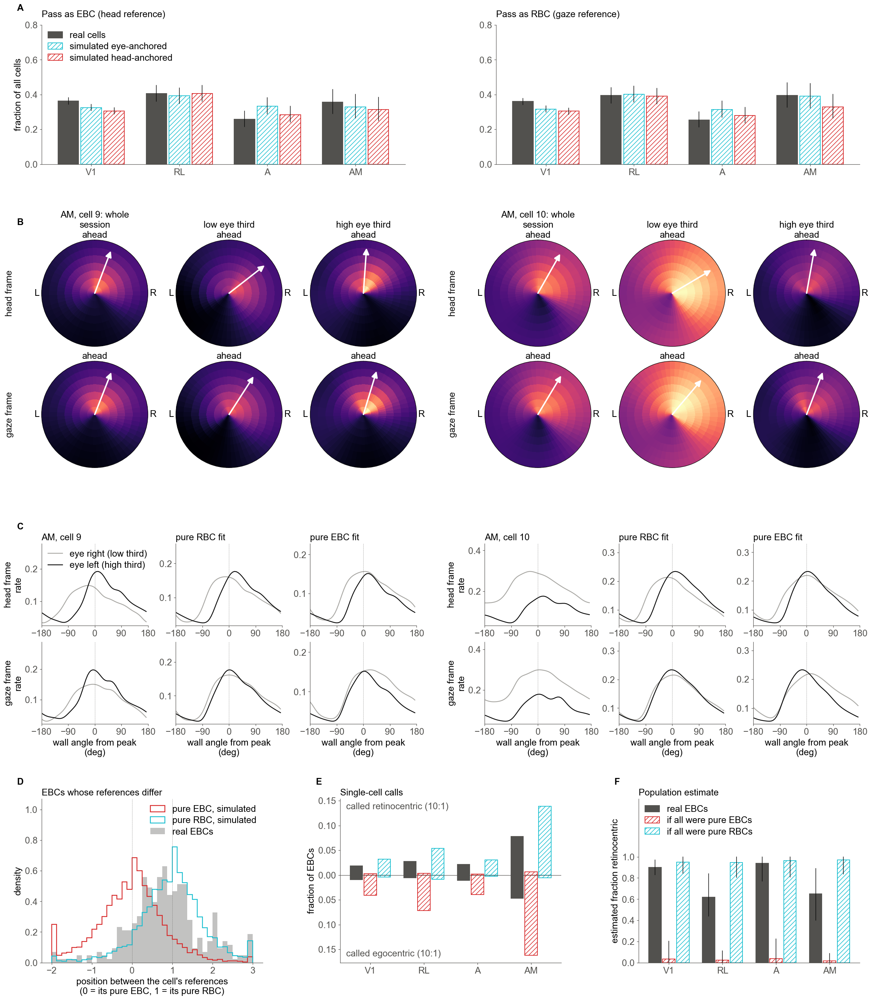

In [261]:
class Y7Fig(FigProxy):

    def __init__(self, fig):
        super().__init__(fig)
        self.placed = {}

    def add_subplot(self, spec, **kw):
        if spec is None:
            return Figure().add_subplot(111, **kw)
        ax = self._fig.add_subplot(spec, **kw)
        self.placed[id(spec)] = ax
        return ax


class Y7Grid:

    def __init__(self, specs):
        self.specs = specs

    def __getitem__(self, key):
        return self.specs.get(key)


def y7_redraw(cid, specs, edits):
    global Y7_FIG, Y7_GS
    Y7_FIG, Y7_GS = Y7Fig(F7.fig), Y7Grid(specs)
    y_redraw(cid, {}, F7.fig, edits=edits)
    return {k: Y7_FIG.placed[id(s)] for k, s in specs.items() if id(s) in Y7_FIG.placed}


y7_nums = [int(m) for F in (globals().get('F2'), globals().get('F3')) if F is not None for ax in F.fig.axes
           for m in re.findall(r'cell (\d+)', ax.get_title(loc='left'))]
y7_cell = max(y7_nums) + 1 if y7_nums else 9
y7_keep_col = dict(AA_COL)

Y7_C9 = ('251021_DMM_DMM061_pos04', 166)
Y7_C10 = ('251021_DMM_DMM061_pos04', 251)
Y7_C10_MIN_LR = 3
Y7_C10_FRONT = 45


def y7_pick_cell10(exclude):
    a3 = AAT[AAT['ebc'] & np.isfinite(AAT['ratio'])].set_index(['session', 'cell'])[['log_bf']]
    a6 = T6[T6['ebc'] & np.isfinite(T6['ratio'])].set_index(['session', 'cell'])[['log_bf']]
    j = a3.join(a6, rsuffix='_6', how='inner')
    j = j[(j['log_bf'] > np.log(Y7_C10_MIN_LR)) & (j['log_bf_6'] > np.log(Y7_C10_MIN_LR))]
    maps = {}
    for sess, c in j.sort_values('log_bf_6', ascending=False).index:
        if (sess, c) == exclude:
            continue
        if sess not in maps:
            s = SES[SES['session'] == sess].iloc[0]
            R, why = rebuild_session(s)
            D = aa_scale_eye(R['D'], AA_EYE_K)
            xy, arena = head_position(D, s['path'])
            use, _ = bnd_designs(D, xy, arena)
            maps[sess] = (D, AAMapsF(D, xy, arena, use & (D['speed'] > AA_MIN_SPEED), 'head'))
        D, Mh = maps[sess]
        p = np.nanmean(Mh.maps(D['Y'][Mh.idx][:, [c]])[0, 0], 1)
        if abs((np.nanargmax(p) * AA_RAY_DEG + 180) % 360 - 180) <= Y7_C10_FRONT:
            return sess, int(c)
    return None


def y7_mean_deg(M):
    th = np.radians(np.arange(0.0, 360.0, AA_RAY_DEG))[:, None]
    return np.degrees(np.angle((np.nan_to_num(M) * np.exp(1j * th)).sum()))


Y7_W = [2.1, 2.1, 2.1, 0.25, 2.1, 2.1, 2.1]
F7 = Composite('Figure7', widths=Y7_W, heights=[3.5, 4.5, 4.2, 4.4, 4.4], wspace=0.3, hspace=0.42)
y7_gde = GridSpecFromSubplotSpec(1, 2, subplot_spec=F7.gs[3, :], wspace=0.35)
y7_gf = GridSpecFromSubplotSpec(1, 2, subplot_spec=F7.gs[4, :], wspace=0.35)
f7 = [F7.gs[0, :], F7.gs[1, :], F7.gs[2, :], y7_gde[0, 0], y7_gde[0, 1], y7_gf[0, 0]]
for l, s in zip(Y_L, f7):
    F7.letter(l, s)
y7_gb = GridSpecFromSubplotSpec(2, 7, subplot_spec=F7.gs[1, :], width_ratios=Y7_W, wspace=0.3, hspace=0.12)
y7_gc = GridSpecFromSubplotSpec(2, 7, subplot_spec=F7.gs[2, :], width_ratios=Y7_W, wspace=0.3, hspace=0.2)

f7_a = y_redraw('aa1cd', {0: y_region(F7.fig, f7[0], wspace=0.25)}, F7.fig, edits=[
    ("AA_COL = {'real': '#52514e', 'eye-anchored': '#2a78d6', 'head-anchored': '#eb6834'}",
     "AA_COL = {'real': '#52514e', 'eye-anchored': Y_EYE, 'head-anchored': Y_HEAD}"),
    ("ax.bar(x, k[src] / max(n, 1), width=w * 0.9, color=AA_COL[src] if real else 'white',\n                       edgecolor=AA_COL[src], lw=1.2,",
     "ax.bar(x, k[src] / max(n, 1), width=w * 0.9, color=AA_COL[src],\n                       edgecolor=AA_COL[src] if real else INK2, lw=1.2 if real else 0.5,")])[0]
y_retitle(f7_a, AA_TAG, '')
y_retitle(f7_a, ', MRL rule', '')
f7_a[0, 1].get_legend().remove()
for ax, ttl in zip(f7_a[0], ('pass as EBC', 'pass as RBC')):
    ax._y_keep_title = True
    ax.set_title('', loc='left')
    ax.set_title(ttl, pad=40)
y_legend_above(f7_a[0, 0], ncol=3, labels=['real cells', 'simulated eye-anchored', 'simulated head-anchored'])

y7_keep_aa4 = (AA4C, AA4)
AA4_EDITS = [
    ("fig = plt.figure(figsize=(17, 9))", "fig = Y7_FIG"),
    ("gs = fig.add_gridspec(3, 8, width_ratios=[1, 1, 1, 1, 1, 1, 1.25, 1.25], wspace=0.35, hspace=0.45)",
     "gs = Y7_GS"),
    ("for M, col, nm in ((L, AA_COL['eye-anchored'], 'low eye'), (H, AA_COL['head-anchored'], 'high eye')):",
     "for M, col, nm in ((L, INK, 'eye right (low third)'), (H, INK, 'eye left (high third)')):"),
    ("ax.plot(rel[o], np.nanmean(M, 1)[o], color=col, lw=1.5, label=nm)",
     "ax.plot(rel[o], np.nanmean(M, 1)[o], color=col, lw=2.8, ls=Y_LS_LOW if nm.startswith('eye right') else Y_LS_HIGH, label=nm)")]
y7_cells = []
for h in range(2):
    specs = {(0, 3 * j + k): y7_gb[j, 4 * h + k] for j in range(2) for k in range(3)}
    specs.update({(i, 6 + j): y7_gc[j, 4 * h + i] for i in range(3) for j in range(2)})
    edits = list(AA4_EDITS)
    pick = Y7_C9 if h == 0 else (Y7_C10 or y7_pick_cell10(y7_cells[0]))
    if pick is not None:
        edits.append(("    AA4C = AAT[AAT['ebc'] & np.isfinite(AAT['ratio'])].sort_values('log_bf', ascending=False)",
                      "    AA4C = AAT[(AAT['session'] == {!r}) & (AAT['cell'] == {})]".format(*pick)))
    axs = y7_redraw('aa4cd', specs, edits=edits)
    key = (AA4C.iloc[0]['session'], int(AA4C.iloc[0]['cell']))
    y7_cells.append(key)
    maps = AA4[key]['maps']
    label = '{}, cell {}'.format(AA4C.iloc[0]['area'], y7_cell + h)
    for j, fr in enumerate(('head', 'gaze')):
        for k, ttl in enumerate(('whole session', 'low eye third', 'high eye third')):
            ax = axs[(0, 3 * j + k)]
            for t in list(ax.texts):
                t.remove()
            ax.set_title((label + ': ' + ttl if k == 0 else ttl) if j == 0 else '', fontsize=8, pad=6)
            if k == 0:
                ax.text(-0.3, 0.5, '{} frame'.format(fr), transform=ax.transAxes, rotation=90, ha='center',
                        va='center', fontsize=10, color=INK)
            th0 = np.radians(y7_mean_deg(maps[('real', fr)][k]))
            ax.annotate('', xy=(th0, 0.85 * AA_DIST_MAX), xytext=(th0, 0.0), xycoords='data',
                        arrowprops=dict(arrowstyle='-|>', color='white', lw=2.5, mutation_scale=22, shrinkA=0,
                                        shrinkB=0))
            ax.set_ylim(0, AA_DIST_MAX)
        for i, who in enumerate((label, 'pure RBC fit', 'pure EBC fit')):
            ax = axs[(i, 6 + j)]
            ax.set_title(who if j == 0 else '', loc='left')
            ax.set_title('')
            ax.set_ylabel('{}: rate'.format(fr) if i == 0 else '')
            ax.set_xlabel('wall angle (deg)' if j == 1 else '')
            if ax.get_legend() is not None:
                ax.get_legend().remove()
        row = [axs[(i, 6 + j)] for i in range(3)]
        hi = max(a.get_ylim()[1] for a in row)
        for i, a in enumerate(row):
            a.set_ylim(0, hi)
            a.tick_params(labelleft=(i == 0))
    if h == 0:
        y_legend_above(axs[(0, 6)], ncol=2, labels=['eye right', 'eye left'])
AA4C, AA4 = y7_keep_aa4
from matplotlib.ticker import MaxNLocator
for h_ax in F7.fig.axes:
    if h_ax.name == 'rectilinear' and h_ax.get_xlabel().startswith('wall angle') or h_ax.get_ylabel().endswith('rate'):
        h_ax.yaxis.set_major_locator(MaxNLocator(2))

f7_eg = y7_redraw('aa6fig', {0: f7[3], 1: f7[4], 2: f7[5]}, edits=[
    ("fig = plt.figure(figsize=(15, 4.2))", "fig = Y7_FIG"),
    ("lw=1.5, label=lab)", "lw=3.0, label=lab)"),
    ("kw = dict(width=w * 0.9, color=AA_COL[src] if real else 'white', edgecolor=AA_COL[src], lw=1.2,",
     "kw = dict(width=w * 0.9, color=AA_COL[src], edgecolor=AA_COL[src] if real else INK2, lw=1.2 if real else 0.5,"),
    ("ax.bar(x, y, width=w * 0.9, color=AA_COL[src] if real else 'white', edgecolor=AA_COL[src], lw=1.2,",
     "ax.bar(x, y, width=w * 0.9, color=AA_COL[src], edgecolor=AA_COL[src] if real else INK2, lw=1.2 if real else 0.5,"),
    ("gs = fig.add_gridspec(1, 3, width_ratios=[1.2, 1.1, 1.1], wspace=0.35)", "gs = Y7_GS"),
    ("'called retinocentric (10:1)'", "'retinocentric'"), ("'called egocentric (10:1)'", "'egocentric'")])
f7_eg[0].get_legend().remove()
for t in f7_eg[1].texts:
    if t.get_text() in ('retinocentric', 'egocentric'):
        t._y_size = Y_LABEL_SIZE
y_legend_above(f7_eg[0], ncol=2, labels=['pure EBC, simulated', 'pure RBC, simulated', 'real EBCs'])
f7_eg[0].set_xlabel('position between references (0 = EBC, 1 = RBC)')
y_one_line(f7_eg[0].xaxis.label)
y7_h, _ = f7_eg[1].get_legend_handles_labels()
f7_eg[1].get_legend().remove()
y_legend_above(f7_eg[1], ncol=3, handles=y7_h, labels=['real EBCs', 'if all pure EBCs', 'if all pure RBCs'])
f7_eg[2].set_ylim(0, 1)
f7_eg[2].set_yticks([0, 0.5, 1])
f7_eg[2].set_ylabel('estimated fraction\nretinocentric')
y_legend_above(f7_eg[2], ncol=3, handles=y7_h, labels=['real EBCs', 'if all pure EBCs', 'if all pure RBCs'])

AA_COL = y7_keep_col
F7.finish()

In [ ]:
from fm2p.utils.files import write_h5
from scipy.stats import binom

FD_AREAS = ['V1', 'RL', 'A', 'AM']
FD_PATH = os.path.join(SAVE_DIR or '.', 'manuscript_figures', 'figure_data.h5')


def fd_frac(k, n):
    lo, hi = frac_ci(k, n)
    return {'frac': k / n if n else np.nan, 'lo': lo, 'hi': hi}


def fd_by_area(cols, df=None):
    df = CELLS if df is None else df
    out = {}
    for a in FD_AREAS:
        base = df['area'] == a
        n = int(base.sum())
        out[a] = {}
        for col in cols:
            d = fd_frac(int((base & df[col].astype(bool)).sum()), n)
            d['sessions'] = df[base].groupby('session')[col].mean().to_numpy(float)
            out[a][col] = d
    return out


def fd_spread(v):
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    return {'median': np.median(v), 'p10': np.percentile(v, 10), 'p90': np.percentile(v, 90), 'values': v}


FD = {}

f1 = {}
f1['A'] = fd_by_area(['gm_tuned', 'gm_tuned_dark'])
f1['B'] = {'bin_edges': Z6_BINS, 'frac_frames': np.mean(z6_hist, 0), 'third_cuts': np.mean(z6_cut, 0)}
f1['C'] = {'gap_deg': np.array([v for v in z6_delta.values() if np.isfinite(v)]), 'min_gap': W1_MIN_DELTA}
f1['DE'] = {}
for a in FD_AREAS:
    r = w1_pick[a]
    cv = c1_curves(r['session'])
    k = int(r['cell'])
    f1['DE'][a] = {'grid': np.arange(-175.0, 180.0, 10.0), 'low': cv['F_low'][:, k], 'high': cv['F_high'][:, k],
                   'delta': float(cv['delta']), 'session': r['session'], 'cell': k}
f1['F'] = {a: {'ratio': CELLS.loc[(CELLS['area'] == a) & CELLS['eye_reliable'].astype(bool), 'eye_ratio']
               .to_numpy(float)} for a in FD_AREAS}
for a in FD_AREAS:
    f1['F'][a]['ratio'] = f1['F'][a]['ratio'][np.isfinite(f1['F'][a]['ratio'])]
    f1['F'][a].update({k: float(v) for k, v in F2F_STATS.loc[a].items()})
f1['F']['kruskal_H'], f1['F']['kruskal_p'] = float(F2F_KW.statistic), float(F2F_KW.pvalue)
f1['G'] = fd_by_area(['gm_eye_better', 'gm_eye_better_dark', 'gm_head_better', 'gm_head_better_dark'])
FD['fig1'] = f1

f2 = {'A': {}, 'B': {}, 'C': {}, 'D': {}}
for a in FD_AREAS:
    pos = np.flatnonzero(((QC['area'] == a) & QC['gain_cell'].astype(bool)
                          & QC['mult_r'].notna() & QC['shift_r'].notna()).to_numpy())
    xs = np.abs(QC['shift_r'].to_numpy(float)[pos])
    ys = np.abs(QC['mult_r'].to_numpy(float)[pos])
    f2['C'][a] = {'shift_r': xs, 'scale_r': ys}
    margin = ys - xs
    fit = np.array([stored_gain_r2(s_)[c_] for s_, c_ in zip(QC['session'].to_numpy()[pos], QC['cell'].to_numpy(int)[pos])])
    good = np.flatnonzero(fit >= np.nanmedian(fit))
    i = pos[good[np.argmin(np.abs(margin[good] - np.median(margin)))]]
    r = QC.iloc[i]
    f, g = field_and_gain(stored_gain_model(r['session']))
    samp = np.asarray(QSAMP[i], bool)
    f = np.where(samp, f[:, int(r['cell'])], np.nan)
    g = np.where(samp, g[:, int(r['cell'])], np.nan)
    f = f - np.nanmin(f)
    f2['A'][a] = {'azimuth': Q_GRID, 'eye_low': f - g, 'eye_mean': f, 'eye_high': f + g,
                  'session': r['session'], 'cell': int(r['cell'])}
    d = GCC[GCC['area'] == a]
    k, n = int(np.nansum(d['beyond_all'])), int(d['beyond_all'].notna().sum())
    nf = m_null(d)
    f2['B'][a] = {'real': fd_frac(k, n), 'shuffled': {'frac': np.nanmean(nf), 'lo': np.nanpercentile(nf, 2.5),
                                                      'hi': np.nanpercentile(nf, 97.5)}}
    edges = Z1_VIS[0] + Z1_BIN_DEG * np.arange(int(round(360 / Z1_BIN_DEG)) + 1)
    cen = edges[:-1] + Z1_BIN_DEG / 2
    dd = QC[(QC['area'] == a) & QC['pref_rho'].notna()]
    x = dd['pref_rho'].to_numpy(float)
    x = np.where(x < edges[0], x + 360.0, x)
    b = np.clip(np.digitize(x, edges) - 1, 0, len(cen) - 1)
    gc, kk = dd['gain_cell'].to_numpy(bool), dd['k'].to_numpy(float)
    nn = np.bincount(b, minlength=len(cen))
    up = np.bincount(b[gc & (kk > 0)], minlength=len(cen))
    dn = np.bincount(b[gc & (kk < 0)], minlength=len(cen))
    p = np.where(nn > 0, binom.sf(up + dn - 1, np.maximum(nn, 1), GAIN_P_FLOOR), np.nan)
    f2['D'][a] = {'bin_edges': edges, 'gain_up': up, 'gain_down': dn, 'chance': nn * GAIN_P_FLOOR, 'p': p}
f2['visible_range'] = np.array([-160.0, 20.0])
FD['fig2'] = f2

f3 = {'A': {}, 'B': {}, 'C': {}, 'D': {}, 'E': {}}
for a in FD_AREAS:
    S = S_RATES[a]
    for panel, c in (('A', 'eye'), ('B', 'head')):
        f3[panel][a] = {'real': fd_frac(S['real'][c], S['n'])}
        for g, name in (('ADD', 'sim_eye'), ('GAIN', 'sim_eye_gain'), ('HEAD', 'sim_head')):
            v = S['sim'][(g, c)]
            f3[panel][a][name] = {'frac': v.mean(), 'lo': np.percentile(v, 2.5), 'hi': np.percentile(v, 97.5)}
    ai = list(next(iter(Q_COLS.values()))['alphas']).index(1.0)
    rs = [r for (h, aa), r in Q_COLS.items() if aa == a]
    f3['C'][a] = {kind: fd_spread(np.concatenate([np.nanmean(r['r2'][ki, ai], 1) for r in rs]))
                  for ki, kind in enumerate(('real', 'null'))}
    d = POOLT[POOLT['alpha'] == 1.0].copy()
    d['snr'] = d['r2'] / (1.0 - d['r2']) / d['N'] * 1e3
    top = d[(d['area'] == a) & (d['N'] == d['n_all'])]
    f3['D'][a] = {kind: fd_spread(top.loc[top['kind'] == kind, 'snr']) for kind in ('real', 'null')}
    da = BT[BT['area'] == a]
    f3['E'][a] = {'real': np.percentile(da['real'], [25, 50, 75]), 'null': np.percentile(da['null'], [25, 50, 75])}
vals = BT[['real', 'null']].to_numpy(float)
f3['E']['lims'] = np.array([min(-0.02, np.nanmin(vals) * 1.8), max(0.05, np.nanmax(vals) * 1.8)])
FD['fig3'] = f3

f4 = {'AG': {}, 'BCD': {}, 'E': {}, 'F': {}}
for row, (cols, lab) in (('visible', (QVIS, 'visible field')), ('never_visible', (~QVIS, 'never visible'))):
    U = expressible_basis(cols)
    x = Q_GRID[cols]
    o = np.argsort(x)
    gap = np.r_[False, np.diff(x[o]) > 15.0]
    brk = lambda y: np.where(gap, np.nan, 0.0) + y
    P, _ = needed_shapes(cols, 2.0)
    mu, V = np.linalg.eigh(P @ P.T)
    ag = {'azimuth': x[o], 'needed': np.stack([brk((U @ V[:, -j])[o] * np.sqrt(mu[-j] / mu.sum())) for j in (1, 2, 3)])}
    R_, N_ = QGP['real'][:, cols] @ U, QGP['null'][:, cols] @ U
    fin = np.all(np.isfinite(R_), 1) & np.all(np.isfinite(N_), 1)
    for a in FD_AREAS:
        ix = np.flatnonzero((QC['area'] == a).to_numpy() & fin)
        ev, EV = np.linalg.eigh((R_[ix].T @ R_[ix] - N_[ix].T @ N_[ix]) / len(ix))
        tot = ev[ev > 0].sum()
        ag[a] = np.stack([brk((U @ (EV[:, -j] * np.sign(EV[:, -j] @ V[:, -1] or 1.0)))[o] * np.sqrt(max(ev[-j], 0) / tot))
                          for j in (1, 2, 3)])
    f4['AG'][row] = ag
    f4['BCD'][row] = {}
    for a in FD_AREAS:
        rows_ = (QC['area'] == a).to_numpy()
        full = coverage_test(QGP, rows_, cols)
        fb = coverage_test(QGP, rows_, cols, n_cells=full['n_cells'], n_boot=Y5_BOOT, n_perm=0)
        f4['BCD'][row][a] = {key: {'value': full[key][0] * sc, 'lo': np.nanpercentile(fb[key], 2.5) * sc,
                                   'hi': np.nanpercentile(fb[key], 97.5) * sc}
                             for key, sc in (('need', 100.0), ('coverage', 1.0), ('eff_dims', 1.0))}
for a in FD_AREAS:
    rs = [r for (h, aa), r in Q_COLS.items() if aa == a]
    c = rs[0]['centers']
    o = np.argsort(c)
    diff = np.concatenate([r['r2'][0, ai] - r['r2'][1, ai] for r in rs], 0)
    lo, med, hi = np.percentile(diff, [10, 50, 90], axis=0)
    f4['E'][a] = {'direction': c[o], 'p10': lo[o], 'median': med[o], 'p90': hi[o]}
r0 = next(iter(Q7_COLS.values()))
f4['F']['kappas'] = np.asarray(r0['kappas'], float)
for row, visible in (('visible', True), ('never_visible', False)):
    f4['F'][row] = {}
    for a in FD_AREAS:
        keys = [k for k in Q7_COLS if k[1] == a]
        vis = np.nanmean([Q_COLS[k]['in_view'] for k in keys], 0) >= Q_VIEW_MIN
        vm = vis if visible else ~vis
        d = np.stack([np.concatenate([Q7_COLS[k]['r2'][kk, 0, ai][:, vm] - Q7_COLS[k]['r2'][kk, 1, ai][:, vm]
                                      for k in keys], 0).mean(1) for kk in range(len(r0['kappas']))], 1)
        lo, med, hi = np.percentile(d, [10, 50, 90], axis=0)
        f4['F'][row][a] = {'p10': lo, 'median': med, 'p90': hi}
FD['fig4'] = f4

f5 = {'A': {}, 'B': {}}
d5 = BPT[BPT['alpha'] == 1.0].copy()
d5['snr'] = d5['r2'] / (1.0 - d5['r2']) / d5['N'] * 1e3
for a in FD_AREAS:
    d = BC[BC['area'] == a]
    f5['A'][a] = {}
    for col, key in (('call', 'null_call'), ('beyond_turn', 'null_beyond_turn')):
        nf = body_null(d, key)
        f5['A'][a][col] = fd_frac(int(d[col].sum()), len(d))
        f5['A'][a][col + '_shuffled'] = {'frac': np.nanmean(nf), 'lo': np.nanpercentile(nf, 2.5),
                                         'hi': np.nanpercentile(nf, 97.5)}
    top = d5[(d5['area'] == a) & (d5['N'] == d5['n_all'])]
    f5['B'][a] = {kind: fd_spread(top.loc[top['kind'] == kind, 'snr']) for kind in ('real', 'null')}
FD['fig5'] = f5

f6 = {'A': {}, 'BC': {}, 'D': {}, 'E': {}, 'F': {}}
for crit in ('ebc', 'rbc'):
    f6['A'][crit] = {}
    for a in FD_AREAS:
        n, k = 0, {s: 0 for s, _ in AA_SRCS}
        for sess, r in AAF.items():
            m = cell_areas(sess, len(r['ebc'])) == a
            n += int(m.sum())
            for src, pre in AA_SRCS:
                k[src] += int((r[pre + crit].astype(bool) & m).sum())
        f6['A'][crit][a] = {src.replace('-', '_'): fd_frac(k[src], n) for src, _ in AA_SRCS}


def fd_aa4_maps(sess, c):
    s = SES[SES['session'] == sess].iloc[0]
    R, why = rebuild_session(s)
    D = aa_scale_eye(R['D'], AA_EYE_K)
    xy, arena = head_position(D, s['path'])
    use, designs = bnd_designs(D, xy, arena)
    mask = use & (D['speed'] > AA_MIN_SPEED)
    idx = np.flatnonzero(use)
    folds = na._folds(D, use)
    acts = {'real': D['Y'][:, [c]]}
    for fr, lab in (('eye', 'pure_rbc'), ('head', 'pure_ebc')):
        X = wall_features(D, xy, arena, fr)
        fit = na._cv(X, D['Y'][:, [c]], folds)
        P = np.zeros((len(D['Y']), 1))
        P[idx] = predict(full_fit(X, D['Y'][:, [c]], use, fit['lam']), X[idx])
        acts[lab] = P
    out = {}
    for frame in ('head', 'gaze'):
        Mp = AAMapsF(D, xy, arena, mask, frame)
        for lab, Yc in acts.items():
            out.setdefault(lab, {})[frame] = Mp.maps(Yc[Mp.idx])[:, 0]
    return out


for num, (sess, c) in zip((9, 10), (Y7_C9, Y7_C10)):
    f6['BC']['cell{}'.format(num)] = {'maps': fd_aa4_maps(sess, c), 'session': sess, 'cell': int(c),
                                      'area': str(AAT.loc[(AAT['session'] == sess) & (AAT['cell'] == c), 'area'].iloc[0])}
f6['map_bins'] = {'angle_step_deg': AA_RAY_DEG, 'dist_step_cm': AA_DIST_STEP, 'dist_max_cm': AA_DIST_MAX}
m = ok6 & (T6['dprime'].abs() >= AA6_MIN_D).to_numpy()
sep = (T6['med_eye'] - T6['med_head']).to_numpy()
z = lambda x: (x - T6['med_head'].to_numpy()[m]) / sep[m]
f6['D'] = {'pure_ebc_sim': z(H6[AA_DRAWS:, m]).ravel(), 'pure_rbc_sim': z(E6[AA_DRAWS:, m]).ravel(),
           'real': z(T6['ratio'].to_numpy()[m])}
for k in list(f6['D']):
    f6['D'][k] = f6['D'][k][np.isfinite(f6['D'][k])]
for a in FD_AREAS:
    ma = ok6 & (T6['area'] == a).to_numpy()
    lr = T6.loc[ma, 'log_bf'].to_numpy()
    f6['E'][a] = {'real': np.array([(lr > AA6_LR).mean(), (lr < -AA6_LR).mean()]),
                  'all_pure_ebc': np.array([(LRH[:, ma] > AA6_LR).mean(), (LRH[:, ma] < -AA6_LR).mean()]),
                  'all_pure_rbc': np.array([(LRE[:, ma] > AA6_LR).mean(), (LRE[:, ma] < -AA6_LR).mean()])}
    est, (lo, hi) = aa_pi(T6.loc[ma, 'p_eye'].to_numpy(), T6.loc[ma, 'p_head'].to_numpy(), n_boot=1000)
    cal = {g: np.array([aa_pi(TE6[g][k][ma], TH6[g][k][ma]) for k in range(len(TE6[g]))]) for g in ('eye', 'head')}
    f6['F'][a] = {'real': np.array([est, lo, hi]),
                  'all_pure_ebc': np.r_[cal['head'].mean(), np.percentile(cal['head'], [2.5, 97.5])],
                  'all_pure_rbc': np.r_[cal['eye'].mean(), np.percentile(cal['eye'], [2.5, 97.5])]}
FD['fig6'] = f6
if 'ABD' in globals():
    r = ABT[(ABT['session'] == Y7_C9[0]) & (ABT['cell'] == Y7_C9[1])].iloc[0]
    f6['F'] = {k: float(r['real_' + k]) for k in ('si_head', 'si_gaze', 'mrl_head', 'mrl_gaze')}
    f6['G'] = {a: {k: np.array([ABD.loc[a, k], ABD.loc[a, k + '_lo'], ABD.loc[a, k + '_hi']], float)
                   for k in ('real_si', 'pure_rbc_si', 'pure_ebc_si')} for a in FD_AREAS}

if 'ACS' in globals():
    FD['fig7'] = {'A': {k: v['rf'] for k, v in RFS.items()},
                  'BCD': {k: {m: v[m] for m in ('still_ebc', 'dark_light', 'map_r_head', 'map_r_gaze')}
                          for k, v in ACS.items()},
                  'n': {k: np.array([v['n'] for v in (RFS.get(k, {'n': 0}), ACS.get(k, {'n': 0}))]) for k in
                        set(RFS) | set(ACS)},
                  'p': {k: np.asarray(v, float) for k, v in AC_P.items()}}
    FD['fig7']['C'] = {}
    for key, v in (('in_view', True), ('out_of_view', False)):
        m = ok7 & (T7['in_view'] == v).to_numpy()
        est, (lo, hi) = aa_pi(T7.loc[m, 'p_eye'].to_numpy(), T7.loc[m, 'p_head'].to_numpy(), n_boot=1000)
        cal = {g: np.array([aa_pi(TE6[g][k][m], TH6[g][k][m]) for k in range(len(TE6[g]))]) for g in ('eye', 'head')}
        FD['fig7']['C'][key] = {'real': np.array([est, lo, hi]),
                                'all_pure_ebc': np.r_[cal['head'].mean(), np.percentile(cal['head'], [2.5, 97.5])],
                                'all_pure_rbc': np.r_[cal['eye'].mean(), np.percentile(cal['eye'], [2.5, 97.5])],
                                'n': np.array(int(m.sum()))}

if 'ADS' in globals():
    FD['fig6']['scaled'] = {a: {k: np.asarray(v[k], float) for k in ('calls', 'conc')} for a, v in ADS.items()}

os.makedirs(os.path.dirname(FD_PATH), exist_ok=True)
write_h5(FD_PATH, FD)
print('Figure data written to', FD_PATH)